**Cell 1 — Load dataset**

**STAGE 1 — DATASET LOADING AND VERIFICATION**

In [1]:

# =====================================================================
# IDP FINAL PIPELINE
# STAGE 1 — DATASET LOADING AND VERIFICATION
#
# Loads existing extracted images directly.
# No ZIP extraction.
# No image preprocessing.
# No automatic quarantine.
# No duplicate deletion.
# No modification of original images.
# =====================================================================

from pathlib import Path
from datetime import datetime
from PIL import Image, UnidentifiedImageError
import pandas as pd
import json

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

SOURCE_DIR = Path(
    idp_path(r"C:\Users\ashis\OneDrive\Desktop\idp project\archive (2)\test")
)

OUTPUT_DIR = Path(
    idp_path(r"D:\fullstackfixed\IDP_Final_Output")
)

SUPPORTED_EXTENSIONS = {
    ".tif",
    ".tiff",
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".webp"
}

CLASS_LABELS = {
    "resume": 0,
    "invoice": 1,
    "form": 2
}

EXPECTED_COUNTS = {
    "form": 2506,
    "invoice": 2477,
    "resume": 2536
}

# =====================================================================
# 2. VALIDATE SOURCE DIRECTORY
# =====================================================================

print("=" * 72)
print("IDP — STAGE 1: DATASET LOADING")
print("=" * 72)

if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset directory not found:\n{SOURCE_DIR}"
    )

print("\nDataset source verified:")
print(SOURCE_DIR)

# =====================================================================
# 3. DISCOVER THREE DOCUMENT CLASSES
# =====================================================================

records = []

for class_name, label in CLASS_LABELS.items():

    class_dir = SOURCE_DIR / class_name

    if not class_dir.is_dir():
        raise FileNotFoundError(
            f"Missing class directory: {class_dir}"
        )

    image_files = sorted(
        [
            path
            for path in class_dir.rglob("*")
            if path.is_file()
            and path.suffix.lower() in SUPPORTED_EXTENSIONS
        ],
        key=lambda path: str(path).lower()
    )

    print(
        f"\n{class_name.upper():10} | "
        f"Images discovered: {len(image_files)}"
    )

    if len(image_files) != EXPECTED_COUNTS[class_name]:

        print(
            f"WARNING: Expected {EXPECTED_COUNTS[class_name]}, "
            f"found {len(image_files)}"
        )

    for image_path in image_files:

        records.append({

            "file_name": image_path.name,

            "file_path": str(image_path),

            "relative_path": image_path.relative_to(
                SOURCE_DIR
            ).as_posix(),

            "class_name": class_name,

            "label": label,

            "extension": image_path.suffix.lower(),

            "file_size_bytes": image_path.stat().st_size,

        })


# =====================================================================
# 4. CREATE DATASET INVENTORY
# =====================================================================

manifest = pd.DataFrame(records)

if manifest.empty:
    raise ValueError("No images were discovered.")

manifest.insert(
    0,
    "image_id",
    range(1, len(manifest) + 1)
)

print("\n" + "=" * 72)
print("DATASET INVENTORY")
print("=" * 72)

print("Total images discovered:", len(manifest))

print("\nClass distribution:")

print(
    manifest["class_name"]
    .value_counts()
    .reindex(CLASS_LABELS.keys(), fill_value=0)
    .to_string()
)


# =====================================================================
# 5. VERIFY IMAGE READABILITY
# =====================================================================

print("\n[IMAGE VALIDATION]")

validation_results = []

for index, row in manifest.iterrows():

    image_path = Path(row["file_path"])

    result = {

        "readable": False,

        "width": None,

        "height": None,

        "image_format": None,

        "image_mode": None,

        "frame_count": None,

        "error": None,

    }

    try:

        # Verify image structure.
        with Image.open(image_path) as image:

            image.verify()

        # Reopen and fully decode the image.
        with Image.open(image_path) as image:

            image.load()

            result["width"] = image.width

            result["height"] = image.height

            result["image_format"] = image.format

            result["image_mode"] = image.mode

            result["frame_count"] = getattr(
                image,
                "n_frames",
                1
            )

            result["readable"] = True

    except Exception as exc:

        result["error"] = str(exc)

    validation_results.append(result)

    completed = index + 1

    if completed % 500 == 0:

        print(
            f"Validated {completed}/{len(manifest)} images"
        )


validation_df = pd.DataFrame(validation_results)

manifest = pd.concat(
    [
        manifest.reset_index(drop=True),
        validation_df.reset_index(drop=True)
    ],
    axis=1
)

# =====================================================================
# 6. FINAL VALIDATION SUMMARY
# =====================================================================

readable_count = int(
    manifest["readable"].sum()
)

unreadable_count = int(
    (~manifest["readable"]).sum()
)

class_distribution = (
    manifest["class_name"]
    .value_counts()
    .reindex(CLASS_LABELS.keys(), fill_value=0)
    .to_dict()
)

class_counts_match = all(
    class_distribution[name] == EXPECTED_COUNTS[name]
    for name in EXPECTED_COUNTS
)

print("\n" + "=" * 72)
print("STAGE 1 VALIDATION RESULTS")
print("=" * 72)

print("Total records:", len(manifest))

print("Readable images:", readable_count)

print("Unreadable images:", unreadable_count)

print("\nClass distribution:")

for name, count in class_distribution.items():

    print(f"{name:10}: {count}")


# =====================================================================
# 7. SAVE NEW DATASET MANIFEST
# =====================================================================

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MANIFEST_PATH = (
    OUTPUT_DIR / "dataset_manifest.csv"
)

SUMMARY_PATH = (
    OUTPUT_DIR / "dataset_loading_summary.json"
)

ERROR_PATH = (
    OUTPUT_DIR / "dataset_loading_errors.csv"
)

# Prevent accidental overwriting of an earlier run.
if MANIFEST_PATH.exists():

    raise FileExistsError(
        f"Manifest already exists:\n{MANIFEST_PATH}\n"
        "Choose a new output folder before rerunning."
    )

manifest.to_csv(
    MANIFEST_PATH,
    index=False,
    encoding="utf-8-sig"
)

errors = manifest.loc[
    ~manifest["readable"]
].copy()

errors.to_csv(
    ERROR_PATH,
    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 8. SAVE SUMMARY
# =====================================================================

summary = {

    "stage": 1,

    "stage_name": "Dataset Loading and Verification",

    "generated_at": datetime.now().isoformat(
        timespec="seconds"
    ),

    "source_directory": str(SOURCE_DIR),

    "total_records": len(manifest),

    "readable_images": readable_count,

    "unreadable_images": unreadable_count,

    "class_distribution": class_distribution,

    "class_counts_match_expected": class_counts_match,

    "class_mapping": CLASS_LABELS,

    "original_images_modified": False,

    "duplicate_records_removed": 0,

    "automatic_quarantine": False,

    "zip_extraction_performed": False,

    "manifest_path": str(MANIFEST_PATH),

    "errors_path": str(ERROR_PATH),

    "next_stage": "Stage 2 — Data Quality and Duplicate Analysis"

}

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )


# =====================================================================
# 9. FINAL REPORT
# =====================================================================

print("\n" + "=" * 72)
print("STAGE 1 — DATASET LOADING COMPLETED")
print("=" * 72)

print("Total images:", len(manifest))

print("Readable:", readable_count)

print("Unreadable:", unreadable_count)

print(
    "Expected class counts:",
    "MATCH" if class_counts_match else "REQUIRES REVIEW"
)

print("\nOUTPUT FILES:")

print(MANIFEST_PATH)

print(ERROR_PATH)

print(SUMMARY_PATH)

print("\nOriginal images modified: NO")

print("Images deleted: NO")

print("Images quarantined: NO")

print("Preprocessing performed: NO")

print("=" * 72)


IDP — STAGE 1: DATASET LOADING

Dataset source verified:
C:\Users\ashis\OneDrive\Desktop\idp project\archive (2)\test

RESUME     | Images discovered: 2536

INVOICE    | Images discovered: 2477

FORM       | Images discovered: 2506

DATASET INVENTORY
Total images discovered: 7519

Class distribution:
class_name
resume     2536
invoice    2477
form       2506

[IMAGE VALIDATION]
Validated 500/7519 images
Validated 1000/7519 images
Validated 1500/7519 images
Validated 2000/7519 images
Validated 2500/7519 images
Validated 3000/7519 images
Validated 3500/7519 images
Validated 4000/7519 images
Validated 4500/7519 images
Validated 5000/7519 images
Validated 5500/7519 images
Validated 6000/7519 images
Validated 6500/7519 images
Validated 7000/7519 images
Validated 7500/7519 images

STAGE 1 VALIDATION RESULTS
Total records: 7519
Readable images: 7519
Unreadable images: 0

Class distribution:
resume    : 2536
invoice   : 2477
form      : 2506

STAGE 1 — DATASET LOADING COMPLETED
Total images: 7

**Stage 2 — Data quality and duplicate detection**

In [2]:

# =====================================================================
# IDP FINAL PIPELINE
# STAGE 2 — DATA QUALITY AND DUPLICATE DETECTION
# Read-only inspection. No image deletion or modification.
# =====================================================================

from pathlib import Path
from collections import defaultdict
import pandas as pd
import hashlib
import json
import numpy as np
from datetime import datetime

ROOT = Path(idp_path(r"D:\fullstackfixed\IDP_Final_Output"))

INPUT = ROOT / "dataset_manifest.csv"

OUTPUT = ROOT / "stage2"

OUTPUT.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("IDP — STAGE 2: DATA QUALITY ANALYSIS")
print("=" * 70)

if not INPUT.is_file():
    raise FileNotFoundError(INPUT)

df = pd.read_csv(INPUT)

if len(df) != 7519:
    raise ValueError(
        f"Expected 7519 records, found {len(df)}"
    )

# ---------------------------------------------------------------
# 1. SHA-256 FILE HASHING
# ---------------------------------------------------------------

def calculate_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


print("\n[1] CALCULATING SHA-256 HASHES")

hashes = []

for index, path_value in enumerate(df["file_path"]):

    path = Path(path_value)

    if not path.is_file():
        raise FileNotFoundError(path)

    hashes.append(calculate_sha256(path))

    if (index + 1) % 500 == 0:
        print(f"Processed {index + 1}/{len(df)} files")

df["sha256"] = hashes

# ---------------------------------------------------------------
# 2. FILE SIZE AND IMAGE DIMENSION CHECKS
# ---------------------------------------------------------------

print("\n[2] CHECKING IMAGE PROPERTIES")

df["file_size_mb"] = (
    pd.to_numeric(df["file_size_bytes"], errors="coerce")
    / (1024 * 1024)
)

df["aspect_ratio"] = (
    pd.to_numeric(df["width"], errors="coerce")
    / pd.to_numeric(df["height"], errors="coerce")
)

df["pixel_count"] = (
    pd.to_numeric(df["width"], errors="coerce")
    * pd.to_numeric(df["height"], errors="coerce")
)

df["zero_or_negative_dimensions"] = (
    df["width"].isna()
    | df["height"].isna()
    | (df["width"] <= 0)
    | (df["height"] <= 0)
)

df["zero_byte_file"] = (
    pd.to_numeric(df["file_size_bytes"], errors="coerce") <= 0
)

# ---------------------------------------------------------------
# 3. EXACT DUPLICATE DETECTION
# ---------------------------------------------------------------

print("\n[3] DETECTING EXACT DUPLICATES")

hash_groups = defaultdict(list)

for index, digest in enumerate(df["sha256"]):

    hash_groups[digest].append(index)

duplicate_rows = []

for digest, indices in hash_groups.items():

    if len(indices) <= 1:
        continue

    group = df.iloc[indices]

    duplicate_group_id = f"DUP_{len(duplicate_rows) + 1:04d}"

    for _, row in group.iterrows():

        duplicate_rows.append({

            "duplicate_group_id": duplicate_group_id,

            "sha256": digest,

            "file_name": row["file_name"],

            "file_path": row["file_path"],

            "class_name": row["class_name"],

            "file_size_bytes": row["file_size_bytes"],

        })

duplicates = pd.DataFrame(duplicate_rows)

duplicate_record_count = len(duplicates)

duplicate_group_count = (
    duplicates["duplicate_group_id"].nunique()
    if not duplicates.empty
    else 0
)

# ---------------------------------------------------------------
# 4. CLASS DISTRIBUTION
# ---------------------------------------------------------------

print("\n[4] CLASS DISTRIBUTION")

class_distribution = (
    df["class_name"]
    .value_counts()
    .to_dict()
)

print(pd.Series(class_distribution).to_string())

# ---------------------------------------------------------------
# 5. DUPLICATE CLASS ANALYSIS
# ---------------------------------------------------------------

if not duplicates.empty:

    print("\n[5] DUPLICATE CLASS ANALYSIS")

    print(
        pd.crosstab(
            duplicates["duplicate_group_id"],
            duplicates["class_name"]
        ).to_string()
    )

    print("\nDuplicate records:")

    print(
        duplicates[
            [
                "file_name",
                "class_name",
                "duplicate_group_id"
            ]
        ].to_string(index=False)
    )

else:

    print("\nNo exact duplicate files detected.")

# ---------------------------------------------------------------
# 6. SAVE REPORTS
# ---------------------------------------------------------------

print("\n[6] SAVING STAGE 2 OUTPUTS")

MANIFEST_OUTPUT = OUTPUT / "stage2_quality_manifest.csv"

DUPLICATE_OUTPUT = OUTPUT / "exact_duplicate_groups.csv"

QUALITY_OUTPUT = OUTPUT / "stage2_quality_summary.json"

ERROR_OUTPUT = OUTPUT / "stage2_quality_issues.csv"

df["exact_duplicate"] = df["sha256"].duplicated(
    keep=False
)

df.to_csv(
    MANIFEST_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

duplicates.to_csv(
    DUPLICATE_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

issues = df[
    df["zero_or_negative_dimensions"]
    | df["zero_byte_file"]
].copy()

issues.to_csv(
    ERROR_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

summary = {

    "stage": 2,

    "stage_name": "Data Quality and Duplicate Detection",

    "generated_at": datetime.now().isoformat(),

    "total_records": len(df),

    "class_distribution": class_distribution,

    "unique_sha256_hashes": int(df["sha256"].nunique()),

    "duplicate_groups": int(duplicate_group_count),

    "duplicate_records": int(duplicate_record_count),

    "records_with_valid_dimensions": int(
        (~df["zero_or_negative_dimensions"]).sum()
    ),

    "zero_byte_files": int(df["zero_byte_file"].sum()),

    "invalid_dimension_records": int(
        df["zero_or_negative_dimensions"].sum()
    ),

    "images_deleted": 0,

    "images_modified": 0,

    "automatic_quarantine": False,

    "next_stage": "Stage 3 — Dataset Splitting"

}

with open(
    QUALITY_OUTPUT,
    "w",
    encoding="utf-8"
) as file:

    json.dump(summary, file, indent=4)

# ---------------------------------------------------------------
# 7. FINAL REPORT
# ---------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 2 — QUALITY REPORT")
print("=" * 70)

print("Total images:", len(df))

print("Unique SHA-256 hashes:", df["sha256"].nunique())

print("Duplicate groups:", duplicate_group_count)

print("Duplicate records:", duplicate_record_count)

print("Invalid dimensions:", int(
    df["zero_or_negative_dimensions"].sum()
))

print("Zero-byte files:", int(df["zero_byte_file"].sum()))

print("\nOUTPUT DIRECTORY:")
print(OUTPUT)

print("\nImages deleted: NO")
print("Images quarantined: NO")
print("Original images modified: NO")

print("=" * 70)


IDP — STAGE 2: DATA QUALITY ANALYSIS

[1] CALCULATING SHA-256 HASHES
Processed 500/7519 files
Processed 1000/7519 files
Processed 1500/7519 files
Processed 2000/7519 files
Processed 2500/7519 files
Processed 3000/7519 files
Processed 3500/7519 files
Processed 4000/7519 files
Processed 4500/7519 files
Processed 5000/7519 files
Processed 5500/7519 files
Processed 6000/7519 files
Processed 6500/7519 files
Processed 7000/7519 files
Processed 7500/7519 files

[2] CHECKING IMAGE PROPERTIES

[3] DETECTING EXACT DUPLICATES

[4] CLASS DISTRIBUTION
resume     2536
form       2506
invoice    2477

[5] DUPLICATE CLASS ANALYSIS
class_name          form
duplicate_group_id      
DUP_0001               2

Duplicate records:
     file_name class_name duplicate_group_id
2053375383.tif       form           DUP_0001
2058054411.tif       form           DUP_0001

[6] SAVING STAGE 2 OUTPUTS

STAGE 2 — QUALITY REPORT
Total images: 7519
Unique SHA-256 hashes: 7518
Duplicate groups: 1
Duplicate records: 2
Inval

**Stage 3 — Cleaning and EDA**

IDP — STAGE 3: DATA CLEANING AND EDA

[1] DATASET LOADED
Records: 7519
Columns: 22

[2] DATA CLEANING

[3] CLASS DISTRIBUTION
class_name  image_count  percentage  expected_count
    resume         2536      33.728            2536
   invoice         2477      32.943            2477
      form         2506      33.329            2506

[4] EXACT DUPLICATE IDENTIFICATION
Duplicate groups: 1
Duplicate records: 2
duplicate_group_id      file_name class_name         duplicate_status
          DUP_0001 2053375383.tif       form EXACT_DUPLICATE_RETAINED
          DUP_0001 2058054411.tif       form EXACT_DUPLICATE_RETAINED

[5] OPENCV IMAGE QUALITY ANALYSIS
Analyzed 500/7519 images
Analyzed 1000/7519 images
Analyzed 1500/7519 images
Analyzed 2000/7519 images
Analyzed 2500/7519 images
Analyzed 3000/7519 images
Analyzed 3500/7519 images
Analyzed 4000/7519 images
Analyzed 4500/7519 images
Analyzed 5000/7519 images
Analyzed 5500/7519 images
Analyzed 6000/7519 images
Analyzed 6500/7519 images
Analyze

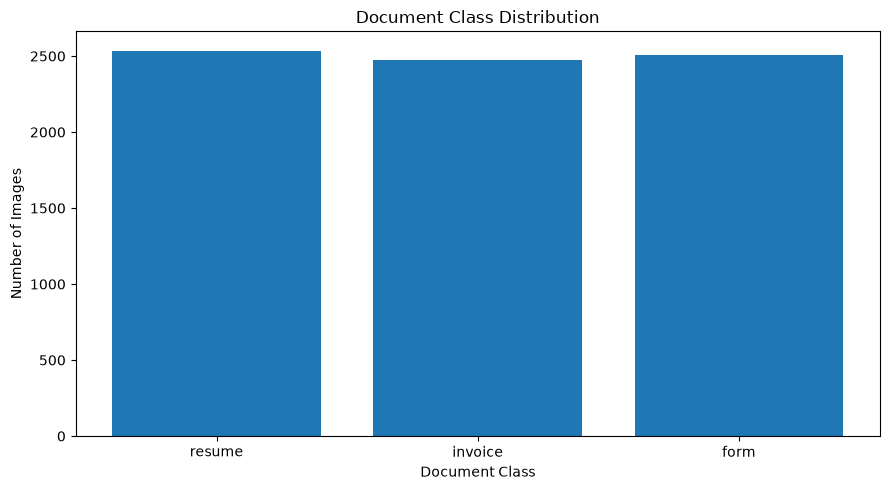

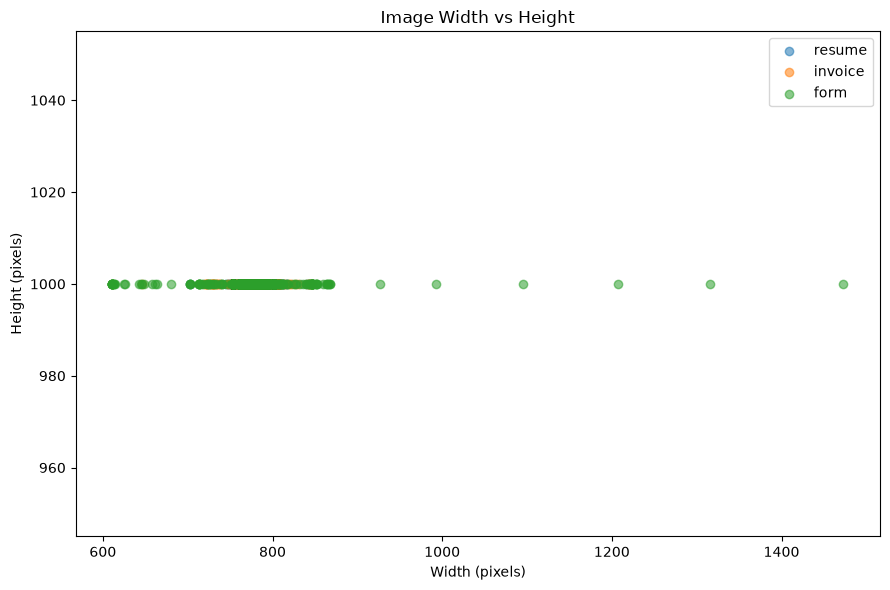

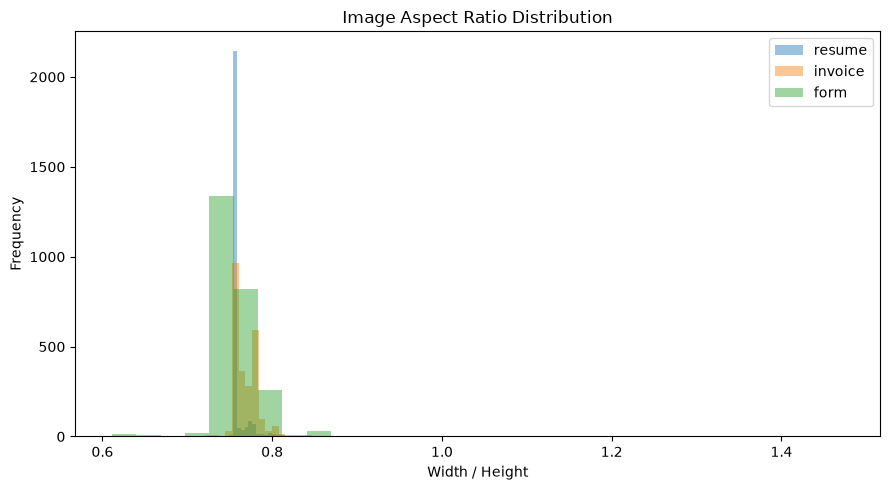

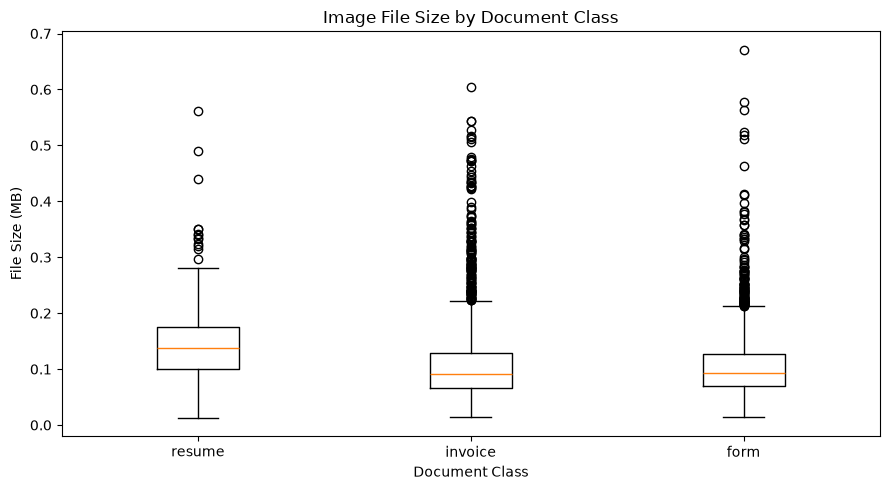

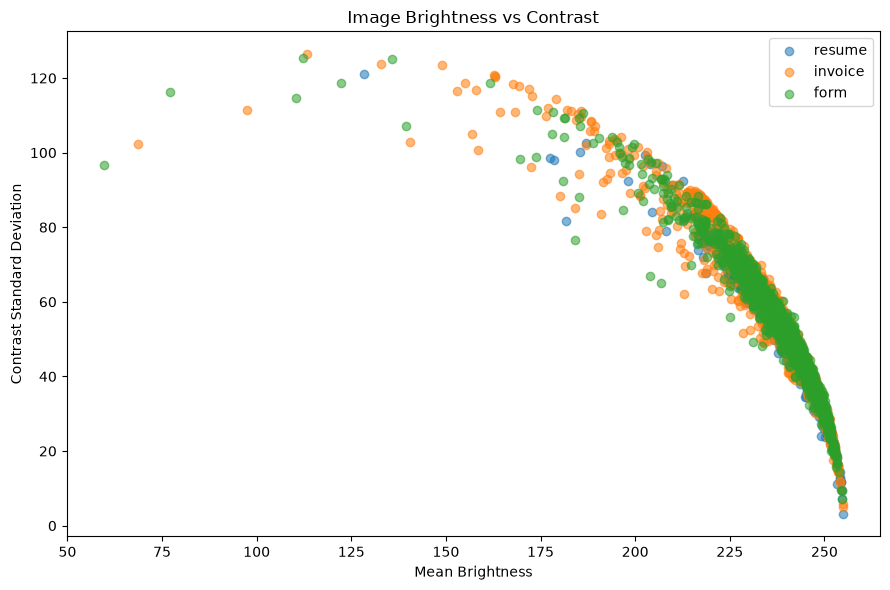

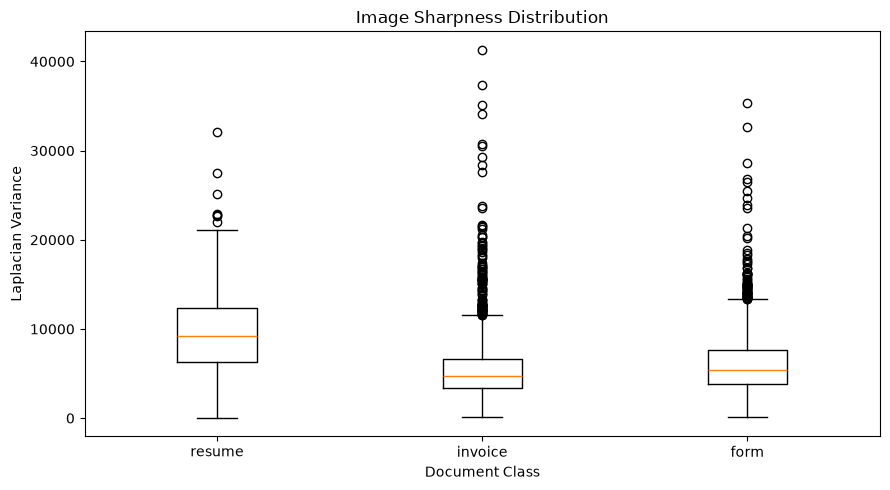


[10] CREATING REPRESENTATIVE IMAGE CONTACT SHEET
Contact sheet saved: D:\fullstackfixed\IDP_Final_Output\stage3\visual_samples\representative_dataset_samples.jpg

[11] SAVING STAGE 3 DATASET

STAGE 3 — FINAL EDA AND CLEANING REPORT
Total source records: 7519
Retained records: 7519
Removed records: 0
Quarantined records: 0
------------------------------------------------------------------------
Duplicate groups: 1
Duplicate records: 2
Duplicate records deleted: 0
------------------------------------------------------------------------
OpenCV successful reads: 7519
OpenCV failed reads: 0
Metadata issues: 0
Dimension mismatches: 0
------------------------------------------------------------------------
CLEANED MANIFEST:
D:\fullstackfixed\IDP_Final_Output\stage3\stage3_cleaned_manifest.csv

DUPLICATE REVIEW:
D:\fullstackfixed\IDP_Final_Output\stage3\stage3_exact_duplicates_review.csv

EDA SUMMARY:
D:\fullstackfixed\IDP_Final_Output\stage3\stage3_eda_summary.json

QUALITY ISSUES:
D:\fullst

In [3]:

# =====================================================================
# IDP FINAL PIPELINE
# STAGE 3 — DATA CLEANING AND EXPLORATORY DATA ANALYSIS
#
# Tools:
#   Python, Pandas, NumPy, OpenCV, Matplotlib, Pillow
#
# Operations:
#   1. Load Stage 2 quality manifest
#   2. Validate metadata and class labels
#   3. Preserve and identify exact duplicates
#   4. Analyze image dimensions and aspect ratios
#   5. Analyze image file sizes
#   6. Analyze brightness and contrast
#   7. Analyze sharpness and high-frequency residuals
#   8. Generate EDA charts and sample contact sheet
#   9. Create cleaned dataset manifest
#
# SAFETY:
#   - No images deleted
#   - No images quarantined
#   - No source images modified
#   - No preprocessing performed
# =====================================================================

from pathlib import Path
from datetime import datetime
from PIL import Image, ImageOps, ImageDraw
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import json
import os


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

ROOT = Path(idp_path(r"D:\fullstackfixed\IDP_Final_Output"))

INPUT_FILE = (
    ROOT
    / "stage2"
    / "stage2_quality_manifest.csv"
)

OUTPUT_DIR = ROOT / "stage3"

PLOTS_DIR = OUTPUT_DIR / "plots"

SAMPLE_DIR = OUTPUT_DIR / "visual_samples"

EXPECTED_TOTAL = 7519

CLASS_LABELS = {
    "resume": 0,
    "invoice": 1,
    "form": 2
}

EXPECTED_CLASSES = {
    "resume": 2536,
    "invoice": 2477,
    "form": 2506
}


# =====================================================================
# 2. HELPER FUNCTIONS
# =====================================================================

def normalize(value):

    if value is None or pd.isna(value):
        return ""

    return str(value).strip().lower()


def calculate_iqr_outliers(series):

    values = pd.to_numeric(
        series,
        errors="coerce"
    )

    valid = values.dropna()

    if valid.empty:
        return pd.Series(False, index=series.index)

    q1 = valid.quantile(0.25)
    q3 = valid.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return (
        (values < lower)
        | (values > upper)
    ).fillna(False)


def read_image_opencv(path):

    """
    Read an image using OpenCV.

    np.fromfile + imdecode supports paths that may contain
    non-ASCII characters on Windows.
    """

    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(str(path))

    image_data = np.fromfile(
        str(path),
        dtype=np.uint8
    )

    image = cv2.imdecode(
        image_data,
        cv2.IMREAD_UNCHANGED
    )

    if image is None:
        raise ValueError("OpenCV could not decode image.")

    return image


def to_gray_uint8(image):

    if image.ndim == 2:

        gray = image

    elif image.ndim == 3 and image.shape[2] == 3:

        gray = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2GRAY
        )

    elif image.ndim == 3 and image.shape[2] == 4:

        gray = cv2.cvtColor(
            image,
            cv2.COLOR_BGRA2GRAY
        )

    else:

        raise ValueError(
            f"Unsupported image shape: {image.shape}"
        )

    if gray.dtype == np.uint8:

        return gray

    if np.issubdtype(gray.dtype, np.integer):

        dtype_max = np.iinfo(gray.dtype).max

        dtype_min = np.iinfo(gray.dtype).min

        if dtype_max == dtype_min:
            return np.zeros(gray.shape, dtype=np.uint8)

        scaled = (
            (gray.astype(np.float32) - dtype_min)
            / (dtype_max - dtype_min)
            * 255
        )

        return np.clip(
            scaled,
            0,
            255
        ).astype(np.uint8)

    if np.issubdtype(gray.dtype, np.floating):

        scaled = cv2.normalize(
            gray.astype(np.float32),
            None,
            0,
            255,
            cv2.NORM_MINMAX
        )

        return scaled.astype(np.uint8)

    raise ValueError(
        f"Unsupported image data type: {gray.dtype}"
    )


def extract_image_metrics(path):

    image = read_image_opencv(path)

    gray = to_gray_uint8(image)

    height, width = gray.shape

    # Brightness.
    mean_brightness = float(
        np.mean(gray)
    )

    p5 = float(
        np.percentile(gray, 5)
    )

    p95 = float(
        np.percentile(gray, 95)
    )

    # Contrast.
    contrast_std = float(
        np.std(gray)
    )

    # Proportion of very dark and very bright pixels.
    dark_pixel_ratio = float(
        np.mean(gray < 50)
    )

    bright_pixel_ratio = float(
        np.mean(gray > 245)
    )

    # Sharpness proxy.
    laplacian = cv2.Laplacian(
        gray,
        cv2.CV_64F
    )

    laplacian_variance = float(
        laplacian.var()
    )

    # High-frequency residual proxy.
    median_image = cv2.medianBlur(
        gray,
        3
    )

    residual = cv2.absdiff(
        gray,
        median_image
    )

    median_filter_residual_mean = float(
        np.mean(residual)
    )

    # Image format and channel information.
    if image.ndim == 2:
        channels = 1
    else:
        channels = image.shape[2]

    return {

        "actual_width": width,

        "actual_height": height,

        "actual_pixel_count": width * height,

        "actual_aspect_ratio": width / height,

        "opencv_dtype": str(image.dtype),

        "opencv_channels": channels,

        "mean_brightness": mean_brightness,

        "contrast_std": contrast_std,

        "p5_brightness": p5,

        "p95_brightness": p95,

        "dark_pixel_ratio": dark_pixel_ratio,

        "bright_pixel_ratio": bright_pixel_ratio,

        "laplacian_variance": laplacian_variance,

        "median_filter_residual_mean": (
            median_filter_residual_mean
        ),

    }


# =====================================================================
# 3. LOAD STAGE 2 MANIFEST
# =====================================================================

print("=" * 72)
print("IDP — STAGE 3: DATA CLEANING AND EDA")
print("=" * 72)

if not INPUT_FILE.is_file():

    raise FileNotFoundError(
        f"Stage 2 manifest not found:\n{INPUT_FILE}"
    )


df = pd.read_csv(INPUT_FILE)

print("\n[1] DATASET LOADED")

print("Records:", len(df))

print("Columns:", len(df.columns))


if len(df) != EXPECTED_TOTAL:

    raise ValueError(
        f"Expected {EXPECTED_TOTAL} records, "
        f"found {len(df)}."
    )


required_columns = [
    "file_name",
    "file_path",
    "class_name",
    "label",
    "sha256",
    "file_size_bytes",
    "width",
    "height",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# =====================================================================
# 4. DATA CLEANING AND METADATA VALIDATION
# =====================================================================

print("\n[2] DATA CLEANING")

df["class_name"] = (
    df["class_name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df["label"] = pd.to_numeric(
    df["label"],
    errors="coerce"
)

df["width"] = pd.to_numeric(
    df["width"],
    errors="coerce"
)

df["height"] = pd.to_numeric(
    df["height"],
    errors="coerce"
)

df["file_size_bytes"] = pd.to_numeric(
    df["file_size_bytes"],
    errors="coerce"
)

df["sha256"] = (
    df["sha256"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Validate class names.
df["valid_class_name"] = (
    df["class_name"].isin(CLASS_LABELS)
)

# Validate integer class labels.
df["expected_label"] = (
    df["class_name"]
    .map(CLASS_LABELS)
)

df["valid_label"] = (
    df["label"] == df["expected_label"]
)

# Validate dimensions.
df["valid_dimensions"] = (
    df["width"].notna()
    & df["height"].notna()
    & (df["width"] > 0)
    & (df["height"] > 0)
)

# Validate file sizes.
df["valid_file_size"] = (
    df["file_size_bytes"].notna()
    & (df["file_size_bytes"] > 0)
)

# Validate file paths.
df["file_exists"] = (
    df["file_path"]
    .map(lambda value: Path(str(value)).is_file())
)

# Validate hashes.
df["valid_sha256"] = (
    df["sha256"].str.fullmatch(r"[0-9a-fA-F]{64}")
    .fillna(False)
)

# Record metadata issues without deleting records.
df["metadata_review_required"] = ~(
    df["valid_class_name"]
    & df["valid_label"]
    & df["valid_dimensions"]
    & df["valid_file_size"]
    & df["file_exists"]
    & df["valid_sha256"]
)


# =====================================================================
# 5. CLASS DISTRIBUTION
# =====================================================================

print("\n[3] CLASS DISTRIBUTION")

class_counts = (
    df["class_name"]
    .value_counts()
    .reindex(
        CLASS_LABELS.keys(),
        fill_value=0
    )
)

class_distribution = pd.DataFrame({

    "class_name": class_counts.index,

    "image_count": class_counts.values,

    "percentage": (
        class_counts.values
        / len(df)
        * 100
    ).round(3),

    "expected_count": [
        EXPECTED_CLASSES[name]
        for name in class_counts.index
    ],

})

print(
    class_distribution.to_string(index=False)
)

class_distribution["count_matches_expected"] = (
    class_distribution["image_count"]
    == class_distribution["expected_count"]
)


# =====================================================================
# 6. EXACT DUPLICATE IDENTIFICATION
# =====================================================================

print("\n[4] EXACT DUPLICATE IDENTIFICATION")

df["duplicate_group_id"] = ""

df["duplicate_group_size"] = 1

df["duplicate_class_count"] = 1

df["duplicate_status"] = "UNIQUE_IMAGE"

valid_hash_rows = df[
    df["valid_sha256"]
].copy()

hash_counts = (
    valid_hash_rows["sha256"]
    .value_counts()
)

duplicate_hashes = sorted(
    hash_counts[
        hash_counts > 1
    ].index.tolist()
)

duplicate_records = []

for group_number, digest in enumerate(
    duplicate_hashes,
    start=1
):

    group_id = f"DUP_{group_number:04d}"

    indices = df.index[
        df["sha256"] == digest
    ].tolist()

    group = df.loc[indices]

    group_size = len(group)

    class_count = group[
        "class_name"
    ].nunique()

    for index in indices:

        df.loc[
            index,
            "duplicate_group_id"
        ] = group_id

        df.loc[
            index,
            "duplicate_group_size"
        ] = group_size

        df.loc[
            index,
            "duplicate_class_count"
        ] = class_count

        if class_count > 1:

            status = "CROSS_CLASS_DUPLICATE_REVIEW"

        else:

            status = "EXACT_DUPLICATE_RETAINED"

        df.loc[
            index,
            "duplicate_status"
        ] = status

        duplicate_records.append({

            "duplicate_group_id": group_id,

            "sha256": digest,

            "file_name": df.loc[
                index, "file_name"
            ],

            "file_path": df.loc[
                index, "file_path"
            ],

            "class_name": df.loc[
                index, "class_name"
            ],

            "duplicate_group_size": group_size,

            "duplicate_class_count": class_count,

            "duplicate_status": status,

        })


duplicates = pd.DataFrame(
    duplicate_records
)

duplicate_record_count = len(duplicates)

duplicate_group_count = len(duplicate_hashes)

if not duplicates.empty:

    print("Duplicate groups:", duplicate_group_count)

    print("Duplicate records:", duplicate_record_count)

    print(
        duplicates[
            [
                "duplicate_group_id",
                "file_name",
                "class_name",
                "duplicate_status"
            ]
        ].to_string(index=False)
    )

else:

    print("No exact duplicates found.")


# =====================================================================
# 7. OPENCV IMAGE QUALITY ANALYSIS
# =====================================================================

print("\n[5] OPENCV IMAGE QUALITY ANALYSIS")

metrics = []

for index, row in df.iterrows():

    try:

        result = extract_image_metrics(
            row["file_path"]
        )

        result["opencv_read_status"] = "SUCCESS"

        result["opencv_error"] = ""

    except Exception as exc:

        result = {

            "actual_width": np.nan,

            "actual_height": np.nan,

            "actual_pixel_count": np.nan,

            "actual_aspect_ratio": np.nan,

            "opencv_dtype": "",

            "opencv_channels": np.nan,

            "mean_brightness": np.nan,

            "contrast_std": np.nan,

            "p5_brightness": np.nan,

            "p95_brightness": np.nan,

            "dark_pixel_ratio": np.nan,

            "bright_pixel_ratio": np.nan,

            "laplacian_variance": np.nan,

            "median_filter_residual_mean": np.nan,

            "opencv_read_status": "FAILED",

            "opencv_error": str(exc),

        }

    metrics.append(result)

    if (index + 1) % 500 == 0:

        print(
            f"Analyzed {index + 1}/{len(df)} images"
        )


metrics_df = pd.DataFrame(metrics)

df = pd.concat(
    [
        df.reset_index(drop=True),
        metrics_df.reset_index(drop=True)
    ],
    axis=1
)


# =====================================================================
# 8. COMPARE ORIGINAL AND OPENCV DIMENSIONS
# =====================================================================

print("\n[6] DIMENSION VALIDATION")

df["dimension_match"] = (

    df["width"].astype("float64")
    == df["actual_width"].astype("float64")

) & (

    df["height"].astype("float64")
    == df["actual_height"].astype("float64")

)

df["aspect_ratio"] = (
    df["actual_aspect_ratio"]
)

df["file_size_mb"] = (
    df["file_size_bytes"]
    / (1024 * 1024)
)

print(
    "Dimension matches:",
    int(df["dimension_match"].sum())
)

print(
    "Dimension mismatches:",
    int((~df["dimension_match"]).sum())
)

print(
    "OpenCV successful reads:",
    int((df["opencv_read_status"] == "SUCCESS").sum())
)


# =====================================================================
# 9. OUTLIER ANALYSIS
# =====================================================================

print("\n[7] IMAGE PROPERTY OUTLIERS")

df["file_size_iqr_outlier"] = calculate_iqr_outliers(
    df["file_size_mb"]
)

df["resolution_iqr_outlier"] = calculate_iqr_outliers(
    df["actual_pixel_count"]
)

df["aspect_ratio_iqr_outlier"] = calculate_iqr_outliers(
    df["aspect_ratio"]
)

print(
    "File-size statistical outliers:",
    int(df["file_size_iqr_outlier"].sum())
)

print(
    "Resolution statistical outliers:",
    int(df["resolution_iqr_outlier"].sum())
)

print(
    "Aspect-ratio statistical outliers:",
    int(df["aspect_ratio_iqr_outlier"].sum())
)

# These are investigation indicators, not automatic failures.


# =====================================================================
# 10. DATASET QUALITY FLAGS
# =====================================================================

df["image_read_review_required"] = (
    df["opencv_read_status"] != "SUCCESS"
)

df["dimension_review_required"] = (
    ~df["dimension_match"].fillna(False)
)

df["quality_review_required"] = (

    df["metadata_review_required"]

    | df["image_read_review_required"]

    | df["dimension_review_required"]

)

# Duplicates are separately identified.
# They are not automatically removed or quarantined.

df["cleaning_status"] = np.where(
    df["quality_review_required"],
    "REVIEW_REQUIRED",
    "RETAINED"
)

df.loc[
    df["duplicate_group_id"] != "",
    "cleaning_status"
] = np.where(
    df.loc[
        df["duplicate_group_id"] != "",
        "duplicate_class_count"
    ] > 1,
    "REVIEW_DUPLICATE_LABEL",
    df.loc[
        df["duplicate_group_id"] != "",
        "cleaning_status"
    ]
)


# =====================================================================
# 11. EDA SUMMARY
# =====================================================================

print("\n[8] GENERATING EDA SUMMARY")

metric_columns = [
    "actual_width",
    "actual_height",
    "actual_pixel_count",
    "aspect_ratio",
    "file_size_mb",
    "mean_brightness",
    "contrast_std",
    "dark_pixel_ratio",
    "bright_pixel_ratio",
    "laplacian_variance",
    "median_filter_residual_mean",
]

overall_statistics = (
    df[metric_columns]
    .describe()
    .round(4)
    .to_dict()
)

class_statistics = (
    df.groupby("class_name")[
        [
            "actual_width",
            "actual_height",
            "aspect_ratio",
            "file_size_mb",
            "mean_brightness",
            "contrast_std",
            "laplacian_variance",
        ]
    ]
    .agg(["mean", "median", "std", "min", "max"])
    .round(4)
)

print("\nIMAGE METRICS BY CLASS")

print(class_statistics.to_string())


# =====================================================================
# 12. CREATE OUTPUT DIRECTORIES
# =====================================================================

print("\n[9] GENERATING EDA OUTPUTS")

PLOTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SAMPLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# =====================================================================
# 13. EDA PLOT — CLASS DISTRIBUTION
# =====================================================================

plt.figure(figsize=(9, 5))

plt.bar(
    class_distribution["class_name"],
    class_distribution["image_count"]
)

plt.title("Document Class Distribution")

plt.xlabel("Document Class")

plt.ylabel("Number of Images")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "class_distribution.png",
    dpi=160
)

plt.show()

plt.close()


# =====================================================================
# 14. EDA PLOT — IMAGE DIMENSIONS
# =====================================================================

plt.figure(figsize=(9, 6))

for class_name in CLASS_LABELS:

    subset = df[
        df["class_name"] == class_name
    ]

    plt.scatter(
        subset["actual_width"],
        subset["actual_height"],
        label=class_name,
        alpha=0.55
    )

plt.title("Image Width vs Height")

plt.xlabel("Width (pixels)")

plt.ylabel("Height (pixels)")

plt.legend()

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "image_dimensions.png",
    dpi=160
)

plt.show()

plt.close()


# =====================================================================
# 15. EDA PLOT — ASPECT RATIO
# =====================================================================

plt.figure(figsize=(9, 5))

for class_name in CLASS_LABELS:

    subset = df[
        df["class_name"] == class_name
    ]

    plt.hist(
        subset["aspect_ratio"].dropna(),
        bins=30,
        alpha=0.45,
        label=class_name
    )

plt.title("Image Aspect Ratio Distribution")

plt.xlabel("Width / Height")

plt.ylabel("Frequency")

plt.legend()

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "aspect_ratio_distribution.png",
    dpi=160
)

plt.show()

plt.close()


# =====================================================================
# 16. EDA PLOT — FILE SIZE
# =====================================================================

plt.figure(figsize=(9, 5))

size_data = [
    df.loc[
        df["class_name"] == class_name,
        "file_size_mb"
    ].dropna()
    for class_name in CLASS_LABELS
]

plt.boxplot(
    size_data,
    tick_labels=list(CLASS_LABELS.keys())
)

plt.title("Image File Size by Document Class")

plt.xlabel("Document Class")

plt.ylabel("File Size (MB)")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "file_size_distribution.png",
    dpi=160
)

plt.show()

plt.close()


# =====================================================================
# 17. EDA PLOT — BRIGHTNESS AND CONTRAST
# =====================================================================

plt.figure(figsize=(9, 6))

for class_name in CLASS_LABELS:

    subset = df[
        df["class_name"] == class_name
    ]

    plt.scatter(
        subset["mean_brightness"],
        subset["contrast_std"],
        label=class_name,
        alpha=0.55
    )

plt.title("Image Brightness vs Contrast")

plt.xlabel("Mean Brightness")

plt.ylabel("Contrast Standard Deviation")

plt.legend()

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "brightness_contrast.png",
    dpi=160
)

plt.show()

plt.close()


# =====================================================================
# 18. EDA PLOT — SHARPNESS
# =====================================================================

plt.figure(figsize=(9, 5))

sharpness_data = [
    df.loc[
        df["class_name"] == class_name,
        "laplacian_variance"
    ].dropna()
    for class_name in CLASS_LABELS
]

plt.boxplot(
    sharpness_data,
    tick_labels=list(CLASS_LABELS.keys())
)

plt.title("Image Sharpness Distribution")

plt.xlabel("Document Class")

plt.ylabel("Laplacian Variance")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "sharpness_distribution.png",
    dpi=160
)

plt.show()

plt.close()


# =====================================================================
# 19. VISUAL SAMPLE CONTACT SHEET
# =====================================================================

print("\n[10] CREATING REPRESENTATIVE IMAGE CONTACT SHEET")

rng = np.random.default_rng(42)

SAMPLE_PER_CLASS = 6

CELL_W = 230
CELL_H = 270

SHEET_COLS = 3

sample_rows = []

for class_name in CLASS_LABELS:

    subset = df[
        df["class_name"] == class_name
    ]

    selected = subset.sample(
        n=min(SAMPLE_PER_CLASS, len(subset)),
        random_state=42
    )

    sample_rows.extend(
        selected.to_dict("records")
    )


SHEET_ROWS = len(sample_rows)

sheet = Image.new(
    "RGB",
    (
        SHEET_COLS * CELL_W,
        SHEET_ROWS // SHEET_COLS * CELL_H
        + (CELL_H if SHEET_ROWS % SHEET_COLS else 0)
    ),
    "white"
)

draw = ImageDraw.Draw(sheet)

for index, row in enumerate(sample_rows):

    col = index % SHEET_COLS

    row_number = index // SHEET_COLS

    x = col * CELL_W

    y = row_number * CELL_H

    path = Path(row["file_path"])

    try:

        with Image.open(path) as image:

            image.load()

            thumbnail = ImageOps.contain(
                image.convert("RGB"),
                (CELL_W - 20, CELL_H - 55),
                method=Image.Resampling.LANCZOS
            )

        sheet.paste(
            thumbnail,
            (x + 10, y + 35)
        )

        draw.text(
            (x + 8, y + 8),
            f"{row['class_name']} | {row['file_name']}",
            fill="black"
        )

    except Exception as exc:

        draw.text(
            (x + 8, y + 40),
            f"Image error: {exc}",
            fill="red"
        )


CONTACT_SHEET = (
    SAMPLE_DIR / "representative_dataset_samples.jpg"
)

sheet.save(
    CONTACT_SHEET,
    quality=92
)

print("Contact sheet saved:", CONTACT_SHEET)


# =====================================================================
# 20. GENERATE CLEANED MANIFEST AND REVIEW REPORTS
# =====================================================================

print("\n[11] SAVING STAGE 3 DATASET")

CLEANED_MANIFEST = (
    OUTPUT_DIR / "stage3_cleaned_manifest.csv"
)

DUPLICATE_REPORT = (
    OUTPUT_DIR / "stage3_exact_duplicates_review.csv"
)

QUALITY_ISSUES = (
    OUTPUT_DIR / "stage3_quality_issues.csv"
)

CLASS_REPORT = (
    OUTPUT_DIR / "stage3_class_distribution.csv"
)

EDA_REPORT = (
    OUTPUT_DIR / "stage3_eda_summary.json"
)


# All 7,519 records are retained.
# Duplicate groups remain linked via duplicate_group_id.

df.to_csv(
    CLEANED_MANIFEST,
    index=False,
    encoding="utf-8-sig"
)

duplicates.to_csv(
    DUPLICATE_REPORT,
    index=False,
    encoding="utf-8-sig"
)

issues = df[
    df["quality_review_required"]
].copy()

issues.to_csv(
    QUALITY_ISSUES,
    index=False,
    encoding="utf-8-sig"
)

class_distribution.to_csv(
    CLASS_REPORT,
    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 21. GENERATE FINAL STAGE 3 SUMMARY
# =====================================================================

summary = {

    "stage": 3,

    "stage_name": (
        "Data Cleaning and Exploratory Data Analysis"
    ),

    "generated_at": datetime.now().isoformat(
        timespec="seconds"
    ),

    "total_records": len(df),

    "retained_records": len(df),

    "removed_records": 0,

    "quarantined_records": 0,

    "class_distribution": class_distribution[
        [
            "class_name",
            "image_count",
            "percentage",
        ]
    ].to_dict(orient="records"),

    "duplicate_analysis": {

        "unique_sha256_hashes": int(
            df["sha256"].nunique()
        ),

        "duplicate_groups": duplicate_group_count,

        "duplicate_records": duplicate_record_count,

        "duplicate_images_deleted": 0,

        "duplicate_groups_kept_together": True,

    },

    "image_validation": {

        "opencv_successful_reads": int(
            (df["opencv_read_status"] == "SUCCESS").sum()
        ),

        "opencv_failed_reads": int(
            (df["opencv_read_status"] != "SUCCESS").sum()
        ),

        "dimension_mismatches": int(
            (~df["dimension_match"]).sum()
        ),

        "invalid_metadata_records": int(
            df["metadata_review_required"].sum()
        ),

    },

    "statistical_outliers": {

        "file_size": int(
            df["file_size_iqr_outlier"].sum()
        ),

        "resolution": int(
            df["resolution_iqr_outlier"].sum()
        ),

        "aspect_ratio": int(
            df["aspect_ratio_iqr_outlier"].sum()
        ),

        "outliers_automatically_removed": 0,

    },

    "image_quality_metrics": overall_statistics,

    "cleaning_policy": (
        "All original records retained. Exact duplicates identified "
        "and linked by SHA-256. Statistical outliers flagged for "
        "inspection, not automatically removed."
    ),

    "source_images_modified": False,

    "preprocessing_performed": False,

    "next_stage": (
        "Stage 4 — OpenCV Image Preprocessing"
    ),

}


with open(
    EDA_REPORT,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False,
        default=str
    )


# =====================================================================
# 22. FINAL REPORT
# =====================================================================

print("\n" + "=" * 72)
print("STAGE 3 — FINAL EDA AND CLEANING REPORT")
print("=" * 72)

print("Total source records:", len(df))

print("Retained records:", len(df))

print("Removed records: 0")

print("Quarantined records: 0")

print("-" * 72)

print("Duplicate groups:", duplicate_group_count)

print("Duplicate records:", duplicate_record_count)

print("Duplicate records deleted: 0")

print("-" * 72)

print(
    "OpenCV successful reads:",
    int((df["opencv_read_status"] == "SUCCESS").sum())
)

print(
    "OpenCV failed reads:",
    int((df["opencv_read_status"] != "SUCCESS").sum())
)

print(
    "Metadata issues:",
    int(df["metadata_review_required"].sum())
)

print(
    "Dimension mismatches:",
    int((~df["dimension_match"]).sum())
)

print("-" * 72)

print("CLEANED MANIFEST:")
print(CLEANED_MANIFEST)

print("\nDUPLICATE REVIEW:")
print(DUPLICATE_REPORT)

print("\nEDA SUMMARY:")
print(EDA_REPORT)

print("\nQUALITY ISSUES:")
print(QUALITY_ISSUES)

print("\nPLOTS DIRECTORY:")
print(PLOTS_DIR)

print("\nVISUAL CONTACT SHEET:")
print(CONTACT_SHEET)

print("-" * 72)

print("Original images modified: NO")

print("Images deleted: NO")

print("Images quarantined: NO")

print("Image preprocessing performed: NO")

print("STAGE 3 STATUS: COMPLETED")

print("NEXT: STAGE 4 — OPENCV IMAGE PREPROCESSING")

print("=" * 72)


**Stage 4 — OpenCV Preprocessing**

**Stage 4 — Pilot execution cell**

In [4]:

# =====================================================================
# IDP FINAL PIPELINE
# STAGE 4 — OPENCV + PADDLEOCR PILOT
#
# Pilot: 5 resumes + 5 invoices + 5 forms
#
# Tests:
#   1. Four-angle document orientation classification.
#   2. Rotation-direction comparison.
#   3. OpenCV grayscale conversion.
#   4. Conditional CLAHE.
#   5. Adaptive thresholding for OCR.
#
# No automatic rotation acceptance.
# No quarantine.
# No original image modification.
# =====================================================================

from pathlib import Path
from datetime import datetime
from PIL import Image, ImageOps, ImageDraw
from paddleocr import DocImgOrientationClassification
from importlib.metadata import version
import pandas as pd
import numpy as np
import cv2
import json
import re


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

ROOT = Path(idp_path(r"D:\fullstackfixed\IDP_Final_Output"))

INPUT_FILE = (
    ROOT
    / "stage3"
    / "stage3_cleaned_manifest.csv"
)

OUTPUT_DIR = ROOT / "stage4_pilot"

CANONICAL_DIR = OUTPUT_DIR / "canonical_gray"

OCR_DIR = OUTPUT_DIR / "ocr_adaptive"

REVIEW_DIR = OUTPUT_DIR / "orientation_review"

PILOT_SIZE_PER_CLASS = 5

RANDOM_STATE = 42

CLASS_NAMES = [
    "resume",
    "invoice",
    "form"
]

ORIENTATION_MODEL = "PP-LCNet_x1_0_doc_ori"

# Conservative enhancement settings.
CLAHE_CONTRAST_THRESHOLD = 35.0
CLAHE_CLIP_LIMIT = 2.0
CLAHE_TILE_SIZE = (8, 8)

ADAPTIVE_BLOCK_SIZE = 35
ADAPTIVE_C = 11


# =====================================================================
# 2. PRE-FLIGHT VALIDATION
# =====================================================================

print("=" * 72)
print("IDP — STAGE 4: OPENCV + PADDLEOCR PILOT")
print("=" * 72)

if not INPUT_FILE.is_file():
    raise FileNotFoundError(INPUT_FILE)

print("\nPaddleOCR version:", version("paddleocr"))
print("OpenCV version:", cv2.__version__)

df = pd.read_csv(INPUT_FILE)

if len(df) != 7519:
    raise ValueError(
        f"Expected 7519 records, found {len(df)}."
    )

required = [
    "file_name",
    "file_path",
    "class_name",
    "sha256"
]

missing = [
    column for column in required
    if column not in df.columns
]

if missing:
    raise ValueError(
        f"Missing manifest columns: {missing}"
    )

# Ensure the orientation model is available before processing.
print("\nInitializing document orientation model...")

orientation_model = DocImgOrientationClassification(
    model_name=ORIENTATION_MODEL,
    device="cpu"
)

print("Orientation model initialized.")


# =====================================================================
# 3. SELECT A STRATIFIED PILOT SAMPLE
# =====================================================================

print("\n[1] SELECTING PILOT SAMPLE")

pilot_parts = []

for class_name in CLASS_NAMES:

    subset = df[
        df["class_name"].astype(str).str.lower()
        == class_name
    ].copy()

    # Avoid selecting both copies of an exact duplicate.
    subset = subset.drop_duplicates(
        subset=["sha256"],
        keep="first"
    )

    selected = subset.sample(
        n=PILOT_SIZE_PER_CLASS,
        random_state=RANDOM_STATE
    )

    pilot_parts.append(selected)

pilot = pd.concat(
    pilot_parts,
    ignore_index=True
)

if len(pilot) != 15:
    raise ValueError("Pilot sample must contain 15 images.")

print(
    pilot["class_name"]
    .value_counts()
    .to_string()
)

print("Total pilot images:", len(pilot))


# =====================================================================
# 4. HELPER FUNCTIONS
# =====================================================================

def read_cv_image(path):

    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(path)

    data = np.fromfile(
        str(path),
        dtype=np.uint8
    )

    image = cv2.imdecode(
        data,
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise ValueError(
            f"OpenCV could not decode: {path.name}"
        )

    return image


def parse_orientation_result(result):

    """
    Extract orientation label and confidence from
    PaddleOCR 3.x Result.json.
    """

    payload = result.json

    if callable(payload):
        payload = payload()

    if isinstance(payload, str):
        payload = json.loads(payload)

    if not isinstance(payload, dict):
        raise ValueError(
            "Unexpected PaddleOCR result format."
        )

    data = payload.get("res", payload)

    labels = data.get("label_names")

    scores = data.get("scores")

    if labels is None or scores is None:
        raise ValueError(
            f"Missing orientation fields: {data.keys()}"
        )

    label = str(np.asarray(labels).reshape(-1)[0])

    score = float(
        np.asarray(scores).reshape(-1)[0]
    )

    match = re.search(
        r"0|90|180|270",
        label
    )

    if match is None:
        raise ValueError(
            f"Unknown orientation label: {label}"
        )

    angle = int(match.group())

    if angle not in {0, 90, 180, 270}:
        raise ValueError(
            f"Unsupported angle: {angle}"
        )

    return angle, score


def get_gray(image):

    return cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )


def apply_conditional_clahe(gray):

    contrast = float(gray.std())

    if contrast < CLAHE_CONTRAST_THRESHOLD:

        clahe = cv2.createCLAHE(
            clipLimit=CLAHE_CLIP_LIMIT,
            tileGridSize=CLAHE_TILE_SIZE
        )

        return clahe.apply(gray), True, contrast

    return gray.copy(), False, contrast


def create_ocr_variant(gray):

    return cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        ADAPTIVE_BLOCK_SIZE,
        ADAPTIVE_C
    )


def save_png(array, destination):

    destination = Path(destination)

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    success, encoded = cv2.imencode(
        ".png",
        array
    )

    if not success:
        raise RuntimeError(
            f"Could not encode image: {destination}"
        )

    encoded.tofile(str(destination))


def make_thumbnail(array, size=(330, 230)):

    if array.ndim == 2:

        image = Image.fromarray(array)

    else:

        image = Image.fromarray(
            cv2.cvtColor(
                array,
                cv2.COLOR_BGR2RGB
            )
        )

    return ImageOps.contain(
        image,
        size,
        method=Image.Resampling.LANCZOS
    )


# =====================================================================
# 5. PROCESS PILOT IMAGES
# =====================================================================

print("\n[2] PROCESSING PILOT IMAGES")

results = []

preview_records = []

for number, (_, row) in enumerate(
    pilot.iterrows(),
    start=1
):

    source_path = Path(
        str(row["file_path"])
    )

    class_name = str(
        row["class_name"]
    ).lower()

    file_name = str(row["file_name"])

    print(
        f"\n[{number}/15] {class_name} | {file_name}"
    )

    # Original image.
    original = read_cv_image(source_path)

    original_h, original_w = original.shape[:2]

    gray = get_gray(original)

    # ---------------------------------------------------------------
    # PaddleOCR page orientation classification
    # ---------------------------------------------------------------

    prediction = orientation_model.predict(
        str(source_path),
        batch_size=1
    )

    prediction = list(prediction)

    if len(prediction) != 1:
        raise RuntimeError(
            f"Unexpected prediction count for {file_name}"
        )

    predicted_angle, confidence = (
        parse_orientation_result(prediction[0])
    )

    print(
        f"Predicted angle: {predicted_angle}° | "
        f"Confidence: {confidence:.4f}"
    )

    # ---------------------------------------------------------------
    # OpenCV grayscale and optional CLAHE
    # ---------------------------------------------------------------

    enhanced_gray, clahe_applied, contrast = (
        apply_conditional_clahe(gray)
    )

    # ---------------------------------------------------------------
    # OCR-oriented adaptive threshold
    # ---------------------------------------------------------------

    ocr_variant = create_ocr_variant(
        enhanced_gray
    )

    # ---------------------------------------------------------------
    # Save separate pilot outputs.
    # Original orientation is retained until mapping is validated.
    # ---------------------------------------------------------------

    canonical_path = (
        CANONICAL_DIR
        / class_name
        / f"{source_path.stem}.png"
    )

    ocr_path = (
        OCR_DIR
        / class_name
        / f"{source_path.stem}_ocr.png"
    )

    save_png(
        enhanced_gray,
        canonical_path
    )

    save_png(
        ocr_variant,
        ocr_path
    )

    # ---------------------------------------------------------------
    # Generate both rotation directions for human comparison.
    # Do NOT automatically select either candidate.
    # ---------------------------------------------------------------

    if predicted_angle == 0:

        candidate_cw = gray.copy()

        candidate_ccw = gray.copy()

    elif predicted_angle == 180:

        candidate_cw = cv2.rotate(
            gray,
            cv2.ROTATE_180
        )

        candidate_ccw = candidate_cw.copy()

    else:

        candidate_cw = cv2.rotate(
            gray,
            cv2.ROTATE_90_CLOCKWISE
        )

        candidate_ccw = cv2.rotate(
            gray,
            cv2.ROTATE_90_COUNTERCLOCKWISE
        )


    results.append({

        "file_name": file_name,

        "file_path": str(source_path),

        "class_name": class_name,

        "sha256": row["sha256"],

        "original_width": original_w,

        "original_height": original_h,

        "predicted_orientation_deg": predicted_angle,

        "orientation_confidence": confidence,

        "contrast_std": contrast,

        "clahe_applied": clahe_applied,

        "canonical_path": str(canonical_path),

        "ocr_variant_path": str(ocr_path),

        "rotation_automatically_applied": False,

        "orientation_decision": "PENDING_PILOT_REVIEW",

    })


    preview_records.append({

        "file_name": file_name,

        "class_name": class_name,

        "angle": predicted_angle,

        "confidence": confidence,

        "original": gray,

        "clockwise": candidate_cw,

        "counterclockwise": candidate_ccw,

        "canonical": enhanced_gray,

        "ocr": ocr_variant,

    })


# =====================================================================
# 6. GENERATE ORIENTATION COMPARISON SHEET
# =====================================================================

print("\n[3] CREATING ORIENTATION COMPARISON")

REVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CELL_W = 360
CELL_H = 330
HEADER_H = 50

SHEET_COLUMNS = 3

SHEET_ROWS = len(preview_records)

sheet = Image.new(
    "RGB",
    (
        SHEET_COLUMNS * CELL_W,
        HEADER_H + SHEET_ROWS * CELL_H
    ),
    "white"
)

draw = ImageDraw.Draw(sheet)

draw.text(
    (12, 15),
    "STAGE 4 PILOT — ORIGINAL / CLOCKWISE / COUNTERCLOCKWISE",
    fill="black"
)

for index, record in enumerate(preview_records):

    y = HEADER_H + index * CELL_H

    draw.text(
        (8, y + 3),
        (
            f"{record['class_name']} | "
            f"{record['file_name']} | "
            f"Predicted={record['angle']}° | "
            f"Confidence={record['confidence']:.3f}"
        ),
        fill="black"
    )

    variants = [
        ("ORIGINAL", record["original"]),
        ("ROTATE 90 CW", record["clockwise"]),
        ("ROTATE 90 CCW", record["counterclockwise"]),
    ]

    for column, (label, array) in enumerate(variants):

        x = column * CELL_W

        draw.text(
            (x + 8, y + 23),
            label,
            fill="black"
        )

        thumbnail = make_thumbnail(
            array,
            (CELL_W - 16, CELL_H - 55)
        )

        sheet.paste(
            thumbnail,
            (x + 8, y + 45)
        )

        draw.rectangle(
            (
                x,
                y,
                x + CELL_W - 2,
                y + CELL_H - 2
            ),
            outline="#AAAAAA"
        )


CONTACT_PATH = (
    REVIEW_DIR
    / "stage4_orientation_pilot_comparison.jpg"
)

sheet.save(
    CONTACT_PATH,
    quality=92
)


# =====================================================================
# 7. SAVE PILOT REPORTS
# =====================================================================

print("\n[4] SAVING PILOT REPORTS")

pilot_results = pd.DataFrame(results)

PILOT_CSV = (
    OUTPUT_DIR
    / "stage4_pilot_results.csv"
)

PILOT_SUMMARY = (
    OUTPUT_DIR
    / "stage4_pilot_summary.json"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

pilot_results.to_csv(
    PILOT_CSV,
    index=False,
    encoding="utf-8-sig"
)

summary = {

    "stage": 4,

    "operation": "OpenCV and PaddleOCR pilot",

    "generated_at": datetime.now().isoformat(
        timespec="seconds"
    ),

    "total_dataset_records": len(df),

    "pilot_records": len(pilot_results),

    "class_distribution": (
        pilot_results["class_name"]
        .value_counts()
        .to_dict()
    ),

    "orientation_model": ORIENTATION_MODEL,

    "orientation_predictions": (
        pilot_results["predicted_orientation_deg"]
        .value_counts()
        .to_dict()
    ),

    "orientation_mean_confidence": float(
        pilot_results["orientation_confidence"].mean()
    ),

    "clahe_applied_records": int(
        pilot_results["clahe_applied"].sum()
    ),

    "rotation_automatically_applied": 0,

    "source_images_modified": False,

    "full_dataset_processed": False,

    "next_action": (
        "Inspect pilot orientation comparisons and validate "
        "rotation convention before full-dataset processing."
    ),

    "outputs": {

        "pilot_results": str(PILOT_CSV),

        "orientation_comparison": str(CONTACT_PATH),

    },

}


with open(
    PILOT_SUMMARY,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )


# =====================================================================
# 8. FINAL PILOT REPORT
# =====================================================================

print("\n" + "=" * 72)

print("STAGE 4 — PILOT COMPLETED")

print("=" * 72)

print("Pilot images:", len(pilot_results))

print("\nOrientation distribution:")

print(
    pilot_results[
        "predicted_orientation_deg"
    ].value_counts().sort_index()
)

print(
    "\nMean orientation confidence:",
    round(
        pilot_results[
            "orientation_confidence"
        ].mean(),
        4
    )
)

print(
    "CLAHE applied:",
    int(pilot_results["clahe_applied"].sum())
)

print("\nPILOT RESULTS:")

print(PILOT_CSV)

print("\nORIENTATION COMPARISON:")

print(CONTACT_PATH)

print("\nPILOT SUMMARY:")

print(PILOT_SUMMARY)

print("\nOriginal images modified: NO")

print("Automatic rotation accepted: NO")

print("Quarantine created: NO")

print("Full dataset processed: NO")

print("=" * 72)


IDP — STAGE 4: OPENCV + PADDLEOCR PILOT

PaddleOCR version: 3.7.0
OpenCV version: 4.10.0

Initializing document orientation model...


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\ashis\.paddlex\official_models\PP-LCNet_x1_0_doc_ori`.
c:\Users\ashis\anaconda3\envs\idp-cv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Orientation model initialized.

[1] SELECTING PILOT SAMPLE
class_name
resume     5
invoice    5
form       5
Total pilot images: 15

[2] PROCESSING PILOT IMAGES

[1/15] resume | 50500514-0515.tif
Predicted angle: 0° | Confidence: 0.9228

[2/15] resume | 11284567_11284568.tif
Predicted angle: 0° | Confidence: 0.9232

[3/15] resume | 40003076-3077.tif
Predicted angle: 0° | Confidence: 0.9235

[4/15] resume | 50675937-5937.tif
Predicted angle: 0° | Confidence: 0.9253

[5/15] resume | 50609269-9270.tif
Predicted angle: 0° | Confidence: 0.9228

[6/15] invoice | 85701843.tif
Predicted angle: 180° | Confidence: 0.8733

[7/15] invoice | 0060218057.tif
Predicted angle: 0° | Confidence: 0.9276

[8/15] invoice | 91515343.tif
Predicted angle: 270° | Confidence: 0.8681

[9/15] invoice | 2048373725.tif
Predicted angle: 0° | Confidence: 0.9173

[10/15] invoice | 0001136696.tif
Predicted angle: 0° | Confidence: 0.9158

[11/15] form | 503259945_503259949.tif
Predicted angle: 0° | Confidence: 0.9284

[1

In [5]:

# =====================================================================
# STAGE 4 — CORRECTED ORIENTATION COMPARISON
#
# Reuses existing Stage 4 pilot results.
# Uses PaddleOCR post-processing rotation convention.
# No new model inference.
# No original image modification.
# No automatic rotation acceptance.
# =====================================================================

from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
import pandas as pd
import numpy as np
import cv2

ROOT = Path(idp_path(r"D:\fullstackfixed\IDP_Final_Output"))

PILOT_FILE = ROOT / "stage4_pilot" / "stage4_pilot_results.csv"

OUTPUT_DIR = ROOT / "stage4_pilot" / "orientation_review"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not PILOT_FILE.is_file():
    raise FileNotFoundError(PILOT_FILE)

pilot = pd.read_csv(PILOT_FILE)

if len(pilot) != 15:
    raise ValueError(
        f"Expected 15 pilot records, found {len(pilot)}"
    )


def read_image(path):

    data = np.fromfile(str(path), dtype=np.uint8)

    image = cv2.imdecode(
        data,
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError(f"Cannot read {path}")

    return image


def apply_paddleocr_correction(image, angle):

    angle = int(angle)

    if angle == 0:
        return image.copy(), "NO ROTATION"

    if angle == 90:
        return (
            cv2.rotate(
                image,
                cv2.ROTATE_90_COUNTERCLOCKWISE
            ),
            "ROTATE 90 CCW"
        )

    if angle == 180:
        return (
            cv2.rotate(
                image,
                cv2.ROTATE_180
            ),
            "ROTATE 180"
        )

    if angle == 270:
        return (
            cv2.rotate(
                image,
                cv2.ROTATE_90_CLOCKWISE
            ),
            "ROTATE 90 CW"
        )

    raise ValueError(f"Unsupported angle: {angle}")


def thumbnail(array, size=(450, 240)):

    image = Image.fromarray(array)

    return ImageOps.contain(
        image,
        size,
        method=Image.Resampling.LANCZOS
    )


# Two columns: original and correction candidate.
CELL_W = 480
CELL_H = 290
HEADER_H = 55

sheet = Image.new(
    "RGB",
    (
        CELL_W * 2,
        HEADER_H + CELL_H * len(pilot)
    ),
    "white"
)

draw = ImageDraw.Draw(sheet)

draw.text(
    (10, 18),
    "ORIGINAL IMAGE VS PADDLEOCR-MAPPED CORRECTION",
    fill="black"
)

audit = []

for index, row in pilot.iterrows():

    original_path = Path(row["file_path"])

    angle = int(row["predicted_orientation_deg"])

    confidence = float(row["orientation_confidence"])

    original = read_image(original_path)

    corrected, correction_name = (
        apply_paddleocr_correction(
            original,
            angle
        )
    )

    y = HEADER_H + index * CELL_H

    draw.text(
        (8, y + 5),
        (
            f"{row['class_name']} | {row['file_name']} | "
            f"Prediction: {angle} degrees | "
            f"Confidence: {confidence:.3f}"
        ),
        fill="black"
    )

    draw.text(
        (8, y + 28),
        "ORIGINAL",
        fill="black"
    )

    draw.text(
        (CELL_W + 8, y + 28),
        f"CORRECTION CANDIDATE: {correction_name}",
        fill="black"
    )

    original_thumb = thumbnail(original)

    corrected_thumb = thumbnail(corrected)

    sheet.paste(
        original_thumb,
        (8, y + 48)
    )

    sheet.paste(
        corrected_thumb,
        (CELL_W + 8, y + 48)
    )

    draw.rectangle(
        (0, y, CELL_W - 2, y + CELL_H - 2),
        outline="#AAAAAA"
    )

    draw.rectangle(
        (
            CELL_W,
            y,
            CELL_W * 2 - 2,
            y + CELL_H - 2
        ),
        outline="#AAAAAA"
    )

    audit.append({

        "file_name": row["file_name"],

        "class_name": row["class_name"],

        "predicted_angle_deg": angle,

        "orientation_confidence": confidence,

        "proposed_correction": correction_name,

        "rotation_accepted": False,

    })


OUTPUT_IMAGE = (
    OUTPUT_DIR
    / "stage4_corrected_orientation_comparison.jpg"
)

OUTPUT_CSV = (
    OUTPUT_DIR
    / "stage4_corrected_orientation_audit.csv"
)

sheet.save(
    OUTPUT_IMAGE,
    quality=94
)

pd.DataFrame(audit).to_csv(
    OUTPUT_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 70)
print("CORRECTED ORIENTATION COMPARISON COMPLETED")
print("=" * 70)

print("Pilot images:", len(pilot))

print("\nCorrection distribution:")

print(
    pd.Series(
        [row["proposed_correction"] for row in audit]
    ).value_counts().to_string()
)

print("\nComparison image:")
print(OUTPUT_IMAGE)

print("\nAudit CSV:")
print(OUTPUT_CSV)

print("\nOriginal images modified: NO")
print("Rotations automatically accepted: NO")

print("=" * 70)


CORRECTED ORIENTATION COMPARISON COMPLETED
Pilot images: 15

Correction distribution:
NO ROTATION     13
ROTATE 180       1
ROTATE 90 CW     1

Comparison image:
D:\fullstackfixed\IDP_Final_Output\stage4_pilot\orientation_review\stage4_corrected_orientation_comparison.jpg

Audit CSV:
D:\fullstackfixed\IDP_Final_Output\stage4_pilot\orientation_review\stage4_corrected_orientation_audit.csv

Original images modified: NO
Rotations automatically accepted: NO


**TAGE 4 — FULL OPENCV + PADDLEOCR PREPROCESSING**

1. Techniques actually used:



No.	Technique	                    Library / method

1	Orientation detection :	        PaddleOCR PP-LCNet	

2	Orientation correction :        OpenCV 90°, 180°, 270 rotation

3	Grayscale conversion :	        OpenCV cvtColor()	

4	Deskewing :                     Canny + HoughLinesP	

5	Noise estimation :               Median-filter residual + local variance	  

6	Denoising :                      Median Blur 3×3

7	Contrast enhancement :	         CLAHE	    

8	Binarization	:                Adaptive Gaussian Thresholding	           

In [1]:

# =====================================================================
# IDP FINAL PIPELINE
# STAGE 4 — FULL OPENCV + PADDLEOCR PREPROCESSING
#
# Dataset: 7,519 images
# Classes: Resume, Invoice, Form
#
# Main operations:
#   1. PaddleOCR document orientation classification
#   2. Verified orientation correction
#   3. OpenCV grayscale conversion
#   4. Conditional noise reduction
#   5. Conservative text deskewing
#   6. Conditional CLAHE
#   7. Adaptive thresholding for OCR
#   8. Output integrity validation
#
# IMPORTANT:
#   - Original images are never overwritten.
#   - All dataset records remain represented.
#   - No automatic quarantine or deletion.
#   - Unverified rotations retain their original orientation.
#   - Canonical and OCR-ready images are saved separately.
#   - Actual OCR text extraction is performed in the later
#     feature-extraction stage.
# =====================================================================


# =====================================================================
# 1. IMPORTS
# =====================================================================

from pathlib import Path
from datetime import datetime
from collections import Counter
from paddleocr import DocImgOrientationClassification

from PIL import Image, ImageOps, ImageDraw

import pandas as pd
import numpy as np
import cv2
import json
import os
import re
import tempfile
import traceback


# =====================================================================
# 2. CONFIGURATION
# =====================================================================

ROOT = Path(
    idp_path(r"D:\fullstackfixed\IDP_Final_Output")
)

INPUT_FILE = (
    ROOT
    / "stage3"
    / "stage3_cleaned_manifest.csv"
)

OUTPUT_ROOT = ROOT / "stage4_full"

# PaddleOCR configuration.
ORIENTATION_MODEL_NAME = (
    "PP-LCNet_x1_0_doc_ori"
)

ORIENTATION_CONFIDENCE_THRESHOLD = 0.80

INFERENCE_BATCH_SIZE = 8

# OpenCV enhancement settings.
CLAHE_CONTRAST_THRESHOLD = 35.0

CLAHE_CLIP_LIMIT = 2.0

CLAHE_TILE_SIZE = (8, 8)

# Noise reduction settings.
NOISE_SIGMA_THRESHOLD = 8.0

MEDIAN_KERNEL_SIZE = 3

# Deskew settings.
ENABLE_CONSERVATIVE_DESKEW = True

DESKEW_MIN_ANGLE = 0.50

DESKEW_MAX_ANGLE = 5.0

DESKEW_MAD_LIMIT = 1.20

# OCR binarization settings.
ADAPTIVE_BLOCK_SIZE = 35

ADAPTIVE_C = 11

# Progress reporting.
PROGRESS_INTERVAL = 100

CLASS_NAMES = [
    "resume",
    "invoice",
    "form"
]

EXPECTED_TOTAL = 7519

EXPECTED_CLASSES = {
    "resume": 2536,
    "invoice": 2477,
    "form": 2506
}


# =====================================================================
# 3. HELPER FUNCTIONS — FILE AND IMAGE HANDLING
# =====================================================================

def require_file(path):

    if not Path(path).is_file():

        raise FileNotFoundError(
            f"Required file missing:\n{path}"
        )


def read_image_cv(path):

    """
    Load TIFF or other supported images using OpenCV.
    Supports Windows paths containing special characters.
    """

    path = Path(path)

    if not path.is_file():

        raise FileNotFoundError(path)

    encoded = np.fromfile(
        str(path),
        dtype=np.uint8
    )

    image = cv2.imdecode(
        encoded,
        cv2.IMREAD_UNCHANGED
    )

    if image is None:

        raise ValueError(
            f"OpenCV could not decode: {path.name}"
        )

    return image


def convert_to_uint8(image):

    if image.dtype == np.uint8:

        return image

    if np.issubdtype(
        image.dtype,
        np.integer
    ):

        minimum = float(np.min(image))

        maximum = float(np.max(image))

        if maximum <= minimum:

            return np.zeros(
                image.shape,
                dtype=np.uint8
            )

        normalized = (
            (
                image.astype(np.float32)
                - minimum
            )
            / (maximum - minimum)
            * 255.0
        )

        return np.clip(
            normalized,
            0,
            255
        ).astype(np.uint8)

    if np.issubdtype(
        image.dtype,
        np.floating
    ):

        normalized = cv2.normalize(
            image.astype(np.float32),
            None,
            0,
            255,
            cv2.NORM_MINMAX
        )

        return normalized.astype(np.uint8)

    raise ValueError(
        f"Unsupported image dtype: {image.dtype}"
    )


def convert_to_bgr(image):

    image = convert_to_uint8(image)

    if image.ndim == 2:

        return cv2.cvtColor(
            image,
            cv2.COLOR_GRAY2BGR
        )

    if image.ndim == 3:

        if image.shape[2] == 3:

            return image.copy()

        if image.shape[2] == 4:

            return cv2.cvtColor(
                image,
                cv2.COLOR_BGRA2BGR
            )

    raise ValueError(
        f"Unsupported image shape: {image.shape}"
    )


def convert_to_gray(image):

    image = convert_to_uint8(image)

    if image.ndim == 2:

        return image.copy()

    if image.ndim == 3:

        if image.shape[2] == 3:

            return cv2.cvtColor(
                image,
                cv2.COLOR_BGR2GRAY
            )

        if image.shape[2] == 4:

            return cv2.cvtColor(
                image,
                cv2.COLOR_BGRA2GRAY
            )

    raise ValueError(
        f"Unsupported image shape: {image.shape}"
    )


def save_png(image, destination):

    destination = Path(destination)

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    success, encoded = cv2.imencode(
        ".png",
        image
    )

    if not success:

        raise RuntimeError(
            f"PNG encoding failed: {destination.name}"
        )

    encoded.tofile(
        str(destination)
    )


def verify_saved_image(path):

    image = cv2.imread(
        str(path),
        cv2.IMREAD_UNCHANGED
    )

    if image is None:

        raise ValueError(
            f"Saved image cannot be reopened: {path}"
        )

    return image.shape


# =====================================================================
# 4. PADDLEOCR ORIENTATION RESULT PARSER
# =====================================================================

def parse_orientation_result(result):

    payload = result.json

    if callable(payload):

        payload = payload()

    if isinstance(payload, str):

        payload = json.loads(payload)

    if not isinstance(payload, dict):

        raise ValueError(
            "Unexpected PaddleOCR result format."
        )

    data = payload.get(
        "res",
        payload
    )

    label_names = data.get(
        "label_names"
    )

    scores = data.get(
        "scores"
    )

    if label_names is None:

        raise ValueError(
            "Orientation label_names not found."
        )

    if scores is None:

        raise ValueError(
            "Orientation scores not found."
        )

    label = str(
        np.asarray(label_names).reshape(-1)[0]
    )

    confidence = float(
        np.asarray(scores).reshape(-1)[0]
    )

    match = re.fullmatch(
        r"\s*(0|90|180|270)\s*",
        label
    )

    if match is None:

        raise ValueError(
            f"Unsupported orientation label: {label}"
        )

    angle = int(match.group(1))

    return angle, confidence


def predict_orientation_batch(model, paths):

    """
    Batch inference with a per-image fallback.
    Every input receives an output record, even if inference fails.
    """

    results = []

    try:

        outputs = list(
            model.predict(
                [str(path) for path in paths],
                batch_size=INFERENCE_BATCH_SIZE
            )
        )

        if len(outputs) != len(paths):

            raise RuntimeError(
                "PaddleOCR batch output count mismatch."
            )

        for output in outputs:

            results.append(
                parse_orientation_result(output)
            )

        return results

    except Exception as batch_error:

        print(
            "Batch inference fallback:",
            str(batch_error)[:180]
        )

    # Per-image fallback.
    for path in paths:

        try:

            outputs = list(
                model.predict(
                    str(path),
                    batch_size=1
                )
            )

            if len(outputs) != 1:

                raise RuntimeError(
                    "Unexpected single-image result count."
                )

            results.append(
                parse_orientation_result(outputs[0])
            )

        except Exception as exc:

            results.append({

                "error": str(exc)

            })

    return results


def predict_orientation_array(model, image):

    outputs = list(
        model.predict(
            image,
            batch_size=1
        )
    )

    if len(outputs) != 1:

        raise RuntimeError(
            "Unexpected orientation verification result count."
        )

    return parse_orientation_result(
        outputs[0]
    )


# =====================================================================
# 5. APPLY OFFICIAL PADDLEOCR ROTATION MAPPING
# =====================================================================

def rotate_by_predicted_orientation(image, angle):

    """
    PaddleOCR orientation post-processing convention:

    0   = no rotation
    90  = counterclockwise
    180 = 180-degree rotation
    270 = clockwise

    The rotation is accepted only after a second orientation
    prediction confirms a 0-degree result.
    """

    if angle == 0:

        return image.copy()

    if angle == 90:

        return cv2.rotate(
            image,
            cv2.ROTATE_90_COUNTERCLOCKWISE
        )

    if angle == 180:

        return cv2.rotate(
            image,
            cv2.ROTATE_180
        )

    if angle == 270:

        return cv2.rotate(
            image,
            cv2.ROTATE_90_CLOCKWISE
        )

    raise ValueError(
        f"Unsupported orientation: {angle}"
    )


# =====================================================================
# 6. CONSERVATIVE DESKEW ESTIMATION
# =====================================================================

def estimate_text_skew(gray):

    """
    Estimate small text-line skew.

    Rejects isolated detections and inconsistent line angles.
    Does not use page-border presence alone as proof of skew.
    """

    height, width = gray.shape

    edges = cv2.Canny(
        gray,
        50,
        150
    )

    margin_x = max(
        5,
        int(width * 0.035)
    )

    margin_y = max(
        5,
        int(height * 0.035)
    )

    # Exclude the outermost page boundary.
    edges[:margin_y, :] = 0

    edges[-margin_y:, :] = 0

    edges[:, :margin_x] = 0

    edges[:, -margin_x:] = 0


    lines = cv2.HoughLinesP(

        edges,

        rho=1,

        theta=np.pi / 180,

        threshold=max(
            35,
            int(width * 0.045)
        ),

        minLineLength=max(
            45,
            int(width * 0.07)
        ),

        maxLineGap=12

    )


    if lines is None:

        return 0.0, 0, 0.0


    angles = []

    for line in lines:

        x1, y1, x2, y2 = (
            line[0]
        )

        dx = x2 - x1

        dy = y2 - y1

        length = np.hypot(
            dx,
            dy
        )

        if length < max(
            45,
            width * 0.07
        ):

            continue


        center_y = (
            y1 + y2
        ) / 2

        # Ignore lines near page borders.
        if (
            center_y < height * 0.07
            or center_y > height * 0.93
        ):

            continue


        angle = np.degrees(
            np.arctan2(
                dy,
                dx
            )
        )

        # Only horizontal text-like lines are considered.
        if abs(angle) <= 7:

            angles.append(
                angle
            )


    if len(angles) < 3:

        return 0.0, len(angles), 0.0


    angles = np.asarray(
        angles,
        dtype=np.float32
    )

    median_angle = float(
        np.median(angles)
    )

    mad = float(
        np.median(
            np.abs(
                angles - median_angle
            )
        )
    )


    if not (
        DESKEW_MIN_ANGLE
        <= abs(median_angle)
        <= DESKEW_MAX_ANGLE
    ):

        return 0.0, len(angles), mad


    if mad > DESKEW_MAD_LIMIT:

        return 0.0, len(angles), mad


    same_direction_ratio = float(
        np.mean(
            np.sign(angles)
            == np.sign(median_angle)
        )
    )


    if same_direction_ratio < 0.70:

        return 0.0, len(angles), mad


    return median_angle, len(angles), mad


def rotate_bound(gray, angle):

    """
    Rotate without cropping document corners.
    White pixels are used for the expanded background.
    """

    height, width = gray.shape

    center = (
        width / 2,
        height / 2
    )

    matrix = cv2.getRotationMatrix2D(
        center,
        float(angle),
        1.0
    )

    cos_value = abs(
        matrix[0, 0]
    )

    sin_value = abs(
        matrix[0, 1]
    )

    new_width = int(
        height * sin_value
        + width * cos_value
    )

    new_height = int(
        height * cos_value
        + width * sin_value
    )

    matrix[0, 2] += (
        new_width / 2
        - center[0]
    )

    matrix[1, 2] += (
        new_height / 2
        - center[1]
    )

    return cv2.warpAffine(

        gray,

        matrix,

        (new_width, new_height),

        flags=cv2.INTER_CUBIC,

        borderMode=cv2.BORDER_CONSTANT,

        borderValue=255

    )


# =====================================================================
# 7. CONDITIONAL NOISE REDUCTION
# =====================================================================

def estimate_noise_sigma(gray):

    """
    Estimate background noise using low-local-variance regions.
    Avoids treating every text edge as scanner noise.
    """

    gray_float = gray.astype(
        np.float32
    )

    median = cv2.medianBlur(
        gray,
        3
    )

    residual = cv2.absdiff(
        gray,
        median
    ).astype(
        np.float32
    )

    local_mean = cv2.blur(
        gray_float,
        (7, 7)
    )

    local_square_mean = cv2.blur(
        gray_float ** 2,
        (7, 7)
    )

    local_variance = np.maximum(
        local_square_mean - local_mean ** 2,
        0
    )

    local_std = np.sqrt(
        local_variance
    )

    smooth_background = (
        local_std < 12.0
    )

    if np.count_nonzero(
        smooth_background
    ) < 100:

        return 0.0

    noise_residual = np.median(
        residual[smooth_background]
    )

    return float(
        noise_residual * 1.4826
    )


# =====================================================================
# 8. SAVE HELPER AND OUTPUT SETUP
# =====================================================================

if not INPUT_FILE.is_file():

    raise FileNotFoundError(INPUT_FILE)

source_df = pd.read_csv(
    INPUT_FILE
)

if len(source_df) != EXPECTED_TOTAL:

    raise ValueError(
        f"Expected {EXPECTED_TOTAL} source records, "
        f"found {len(source_df)}."
    )


if OUTPUT_ROOT.exists():

    raise FileExistsError(
        f"Stage 4 output directory already exists:\n"
        f"{OUTPUT_ROOT}\n"
        "Rename or archive the previous run before starting "
        "another full execution. Existing outputs will not "
        "be overwritten."
    )


CANONICAL_DIR = OUTPUT_ROOT / "canonical_gray"

OCR_DIR = OUTPUT_ROOT / "ocr_ready_binary"

REVIEW_DIR = OUTPUT_ROOT / "orientation_review"

REPORT_DIR = OUTPUT_ROOT / "reports"


for directory in [
    CANONICAL_DIR,
    OCR_DIR,
    REVIEW_DIR,
    REPORT_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# =====================================================================
# 9. INITIALIZE PADDLEOCR ORIENTATION MODEL
# =====================================================================

print("=" * 78)
print("IDP — STAGE 4: FULL OPENCV + PADDLEOCR PREPROCESSING")
print("=" * 78)

print("\nDataset records:", len(source_df))

print("Initializing orientation model...")

orientation_model = DocImgOrientationClassification(

    model_name=ORIENTATION_MODEL_NAME,

    device="cpu"

)

print("Orientation model initialized.")


# =====================================================================
# 10. INITIALIZE PROCESSING RESULTS
# =====================================================================

manifest_rows = []

metrics_rows = []

error_rows = []

orientation_counts = Counter()

processing_counts = Counter()

deskew_count = 0

clahe_count = 0

denoise_count = 0

verified_rotation_count = 0

unverified_rotation_count = 0


# =====================================================================
# 11. MAIN FULL-DATASET PROCESSING LOOP
# =====================================================================

total = len(source_df)

print("\nStarting full dataset processing...")

for batch_start in range(
    0,
    total,
    INFERENCE_BATCH_SIZE
):

    batch_df = source_df.iloc[
        batch_start:
        batch_start + INFERENCE_BATCH_SIZE
    ]

    batch_paths = [
        Path(str(value))
        for value in batch_df["file_path"]
    ]

    # One batch inference for the original images.
    batch_predictions = predict_orientation_batch(
        orientation_model,
        batch_paths
    )


    for local_index, (_, row) in enumerate(
        batch_df.iterrows()
    ):

        global_index = (
            batch_start + local_index + 1
        )

        source_path = Path(
            str(row["file_path"])
        )

        class_name = str(
            row["class_name"]
        ).strip().lower()

        image_id = row.get(
            "image_id",
            global_index
        )

        try:

            image_id_text = (
                f"{int(image_id):06d}"
            )

        except (
            TypeError,
            ValueError
        ):

            image_id_text = (
                f"{global_index:06d}"
            )


        file_stem = (
            f"{image_id_text}_{source_path.stem}"
        )

        canonical_path = (
            CANONICAL_DIR
            / class_name
            / f"{file_stem}.png"
        )

        ocr_path = (
            OCR_DIR
            / class_name
            / f"{file_stem}_ocr.png"
        )


        # ---------------------------------------------------------
        # A. READ ORIGINAL IMAGE
        # ---------------------------------------------------------

        try:

            original_raw = read_image_cv(
                source_path
            )

            original_bgr = convert_to_bgr(
                original_raw
            )

            original_gray = convert_to_gray(
                original_raw
            )

        except Exception as exc:

            error_rows.append({

                "image_id": image_id,

                "file_name": row["file_name"],

                "file_path": str(source_path),

                "stage": "IMAGE_LOADING",

                "error": str(exc),

            })

            manifest_rows.append({

                **row.to_dict(),

                "canonical_path": "",

                "ocr_ready_path": "",

                "processing_status": "FAILED_IMAGE_LOADING",

                "orientation_status": "NOT_EVALUATED",

                "rotation_applied": False,

                "deskew_applied": False,

                "clahe_applied": False,

                "denoising_applied": False,

                "error": str(exc),

            })

            processing_counts[
                "FAILED_IMAGE_LOADING"
            ] += 1

            continue


        # ---------------------------------------------------------
        # B. INITIAL PADDLEOCR ORIENTATION PREDICTION
        # ---------------------------------------------------------

        prediction = batch_predictions[
            local_index
        ]

        if isinstance(prediction, dict):

            initial_angle = None

            initial_confidence = None

            initial_error = prediction.get(
                "error",
                "Orientation inference failed."
            )

        else:

            initial_angle, initial_confidence = prediction

            initial_error = ""


        chosen_image = original_bgr.copy()

        rotation_applied = False

        verification_angle = None

        verification_confidence = None

        orientation_status = ""


        if initial_angle is None:

            orientation_status = (
                "ORIENTATION_INFERENCE_ERROR_ORIGINAL_RETAINED"
            )

        elif initial_angle == 0:

            if (
                initial_confidence
                >= ORIENTATION_CONFIDENCE_THRESHOLD
            ):

                orientation_status = (
                    "PREDICTED_UPRIGHT_HIGH_CONFIDENCE"
                )

            else:

                orientation_status = (
                    "LOW_CONFIDENCE_UPRIGHT_ORIGINAL_RETAINED"
                )

        elif (
            initial_confidence
            < ORIENTATION_CONFIDENCE_THRESHOLD
        ):

            orientation_status = (
                "LOW_CONFIDENCE_ROTATION_NOT_APPLIED"
            )

        else:

            # Create correction candidate.
            candidate = rotate_by_predicted_orientation(
                original_bgr,
                initial_angle
            )

            # Verify corrected candidate with the same model.
            try:

                (
                    verification_angle,
                    verification_confidence
                ) = predict_orientation_array(
                    orientation_model,
                    candidate
                )

                if (

                    verification_angle == 0

                    and verification_confidence
                    >= ORIENTATION_CONFIDENCE_THRESHOLD

                ):

                    chosen_image = candidate

                    rotation_applied = True

                    verified_rotation_count += 1

                    orientation_status = (
                        "ROTATION_APPLIED_AND_VERIFIED"
                    )

                else:

                    orientation_status = (
                        "ROTATION_NOT_VERIFIED_ORIGINAL_RETAINED"
                    )

                    unverified_rotation_count += 1


            except Exception as exc:

                orientation_status = (
                    "ROTATION_VERIFICATION_ERROR_ORIGINAL_RETAINED"
                )

                unverified_rotation_count += 1


        orientation_counts[
            orientation_status
        ] += 1


        # ---------------------------------------------------------
        # C. GRAYSCALE CANONICAL IMAGE
        # ---------------------------------------------------------

        try:

            canonical_gray = convert_to_gray(
                chosen_image
            )

            # -----------------------------------------------------
            # D. CONDITIONAL DESKEW
            # -----------------------------------------------------

            deskew_angle = 0.0

            deskew_lines = 0

            deskew_mad = 0.0

            deskew_applied = False

            if ENABLE_CONSERVATIVE_DESKEW:

                (
                    estimated_angle,
                    detected_lines,
                    angle_mad
                ) = estimate_text_skew(
                    canonical_gray
                )

                deskew_angle = estimated_angle

                deskew_lines = detected_lines

                deskew_mad = angle_mad

                if estimated_angle != 0.0:

                    canonical_gray = rotate_bound(
                        canonical_gray,
                        estimated_angle
                    )

                    deskew_applied = True

                    deskew_count += 1


            # -----------------------------------------------------
            # E. MEASURE IMAGE QUALITY
            # -----------------------------------------------------

            height, width = (
                canonical_gray.shape
            )

            brightness = float(
                np.mean(canonical_gray)
            )

            contrast = float(
                np.std(canonical_gray)
            )

            noise_sigma = estimate_noise_sigma(
                canonical_gray
            )


            # -----------------------------------------------------
            # F. PREPARE OCR VARIANT
            # -----------------------------------------------------

            ocr_base = canonical_gray.copy()

            # Conditional denoising.
            denoising_applied = False

            denoising_method = "NONE"

            if noise_sigma >= NOISE_SIGMA_THRESHOLD:

                ocr_base = cv2.medianBlur(
                    ocr_base,
                    MEDIAN_KERNEL_SIZE
                )

                denoising_applied = True

                denoising_method = "MEDIAN_3X3"

                denoise_count += 1


            # Conditional CLAHE.
            clahe_applied = False

            if float(np.std(ocr_base)) < (
                CLAHE_CONTRAST_THRESHOLD
            ):

                clahe = cv2.createCLAHE(

                    clipLimit=CLAHE_CLIP_LIMIT,

                    tileGridSize=CLAHE_TILE_SIZE

                )

                ocr_base = clahe.apply(
                    ocr_base
                )

                clahe_applied = True

                clahe_count += 1


            # Adaptive thresholding.
            if ADAPTIVE_BLOCK_SIZE >= min(
                ocr_base.shape
            ):

                raise ValueError(
                    "Image too small for adaptive threshold block size."
                )

            ocr_binary = cv2.adaptiveThreshold(

                ocr_base,

                255,

                cv2.ADAPTIVE_THRESH_GAUSSIAN_C,

                cv2.THRESH_BINARY,

                ADAPTIVE_BLOCK_SIZE,

                ADAPTIVE_C

            )


            # -----------------------------------------------------
            # G. SAVE SEPARATE OUTPUT VARIANTS
            # -----------------------------------------------------

            save_png(
                canonical_gray,
                canonical_path
            )

            save_png(
                ocr_binary,
                ocr_path
            )


            # Verify saved images.
            canonical_shape = verify_saved_image(
                canonical_path
            )

            ocr_shape = verify_saved_image(
                ocr_path
            )


            if (
                canonical_shape[0]
                != ocr_shape[0]
                or canonical_shape[1]
                != ocr_shape[1]
            ):

                raise ValueError(
                    "Canonical and OCR output dimensions differ."
                )


            processing_status = (
                "SUCCESS"
            )

            processing_counts[
                "SUCCESS"
            ] += 1


        except Exception as exc:

            error_rows.append({

                "image_id": image_id,

                "file_name": row["file_name"],

                "file_path": str(source_path),

                "stage": "IMAGE_PREPROCESSING",

                "error": str(exc),

            })

            canonical_path_value = ""

            ocr_path_value = ""

            processing_status = (
                "FAILED_PREPROCESSING"
            )

            orientation_status = (
                orientation_status
                or "PROCESSING_ERROR_ORIGINAL_RETAINED"
            )

            processing_counts[
                "FAILED_PREPROCESSING"
            ] += 1

            deskew_angle = 0.0

            deskew_applied = False

            clahe_applied = False

            denoising_applied = False

            denoising_method = "NONE"

            noise_sigma = np.nan

            brightness = np.nan

            contrast = np.nan

            height = np.nan

            width = np.nan

        else:

            canonical_path_value = str(
                canonical_path
            )

            ocr_path_value = str(
                ocr_path
            )


        # ---------------------------------------------------------
        # H. APPEND MANIFEST RECORD
        # ---------------------------------------------------------

        manifest_rows.append({

            **row.to_dict(),

            "canonical_path": canonical_path_value,

            "ocr_ready_path": ocr_path_value,

            "predicted_orientation_deg": (
                initial_angle
            ),

            "orientation_confidence": (
                initial_confidence
            ),

            "verification_orientation_deg": (
                verification_angle
            ),

            "verification_confidence": (
                verification_confidence
            ),

            "orientation_status": (
                orientation_status
            ),

            "rotation_applied": (
                rotation_applied
            ),

            "deskew_angle_deg": deskew_angle,

            "deskew_lines_detected": deskew_lines,

            "deskew_angle_mad": deskew_mad,

            "deskew_applied": deskew_applied,

            "noise_sigma_estimate": noise_sigma,

            "denoising_applied": denoising_applied,

            "denoising_method": denoising_method,

            "clahe_applied": clahe_applied,

            "adaptive_threshold_applied": (
                processing_status == "SUCCESS"
            ),

            "perspective_correction_applied": False,

            "processed_width": width,

            "processed_height": height,

            "brightness_after_orientation": brightness,

            "contrast_after_orientation": contrast,

            "processing_status": processing_status,

            "error": "",

        })


        # ---------------------------------------------------------
        # I. PROGRESS
        # ---------------------------------------------------------

        if global_index % PROGRESS_INTERVAL == 0:

            print(
                f"Processed {global_index}/{total} | "
                f"Successful: {processing_counts['SUCCESS']} | "
                f"Errors: {processing_counts['FAILED_IMAGE_LOADING'] + processing_counts['FAILED_PREPROCESSING']}"
            )


    # -----------------------------------------------------------------
    # CHECKPOINT AFTER EACH BATCH
    # -----------------------------------------------------------------

    checkpoint = pd.DataFrame(
        manifest_rows
    )

    checkpoint.to_csv(
        OUTPUT_ROOT
        / "preprocessing_manifest_CHECKPOINT.csv",
        index=False,
        encoding="utf-8-sig"
    )


# =====================================================================
# 12. FINAL MANIFEST
# =====================================================================

print("\n[FINALIZING]")

preprocessing_manifest = pd.DataFrame(
    manifest_rows
)

if len(preprocessing_manifest) != EXPECTED_TOTAL:

    raise RuntimeError(
        f"Manifest record mismatch: "
        f"{len(preprocessing_manifest)} != {EXPECTED_TOTAL}"
    )


FINAL_MANIFEST = (
    OUTPUT_ROOT
    / "preprocessing_manifest.csv"
)

METRICS_FILE = (
    OUTPUT_ROOT
    / "preprocessing_metrics.csv"
)

ERROR_FILE = (
    OUTPUT_ROOT
    / "preprocessing_errors.csv"
)

SUMMARY_FILE = (
    OUTPUT_ROOT
    / "preprocessing_summary.json"
)


preprocessing_manifest.to_csv(
    FINAL_MANIFEST,
    index=False,
    encoding="utf-8-sig"
)


metric_columns = [

    "image_id",

    "file_name",

    "class_name",

    "predicted_orientation_deg",

    "orientation_confidence",

    "verification_orientation_deg",

    "verification_confidence",

    "rotation_applied",

    "deskew_angle_deg",

    "deskew_applied",

    "noise_sigma_estimate",

    "denoising_applied",

    "clahe_applied",

    "processed_width",

    "processed_height",

    "brightness_after_orientation",

    "contrast_after_orientation",

    "processing_status",

]


metrics_df = preprocessing_manifest[
    [
        column
        for column in metric_columns
        if column in preprocessing_manifest.columns
    ]
].copy()


metrics_df.to_csv(
    METRICS_FILE,
    index=False,
    encoding="utf-8-sig"
)


errors_df = pd.DataFrame(
    error_rows
)

errors_df.to_csv(
    ERROR_FILE,
    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 13. VALIDATE OUTPUT COMPLETENESS
# =====================================================================

print("\n[VALIDATING] OUTPUT COMPLETENESS")

canonical_existing = 0

ocr_existing = 0

for path in preprocessing_manifest[
    "canonical_path"
]:

    if path and Path(path).is_file():

        canonical_existing += 1


for path in preprocessing_manifest[
    "ocr_ready_path"
]:

    if path and Path(path).is_file():

        ocr_existing += 1


successful_count = int(
    (
        preprocessing_manifest[
            "processing_status"
        ] == "SUCCESS"
    ).sum()
)

failed_count = (
    EXPECTED_TOTAL - successful_count
)


# =====================================================================
# 14. CLASS DISTRIBUTION AFTER PREPROCESSING
# =====================================================================

class_distribution = (
    preprocessing_manifest[
        "class_name"
    ]
    .value_counts()
    .reindex(
        CLASS_NAMES,
        fill_value=0
    )
    .to_dict()
)


# =====================================================================
# 15. GENERATE FINAL SUMMARY
# =====================================================================

summary = {

    "stage": 4,

    "stage_name": (
        "OpenCV and PaddleOCR Image Preprocessing"
    ),

    "generated_at": datetime.now().isoformat(
        timespec="seconds"
    ),

    "input_records": EXPECTED_TOTAL,

    "processed_records": len(
        preprocessing_manifest
    ),

    "successful_records": successful_count,

    "failed_records": failed_count,

    "canonical_images_saved": canonical_existing,

    "ocr_ready_images_saved": ocr_existing,

    "class_distribution": class_distribution,

    "orientation_model": ORIENTATION_MODEL_NAME,

    "orientation_status_distribution": dict(
        orientation_counts
    ),

    "verified_rotations_applied": (
        verified_rotation_count
    ),

    "unverified_rotations_retained_original": (
        unverified_rotation_count
    ),

    "orientation_confidence_threshold": (
        ORIENTATION_CONFIDENCE_THRESHOLD
    ),

    "deskew": {

        "enabled": ENABLE_CONSERVATIVE_DESKEW,

        "images_corrected": deskew_count,

        "maximum_applied_angle": DESKEW_MAX_ANGLE,

        "minimum_applied_angle": DESKEW_MIN_ANGLE,

    },

    "denoising": {

        "method": "Conditional median 3x3",

        "images_processed": denoise_count,

        "noise_sigma_threshold": (
            NOISE_SIGMA_THRESHOLD
        ),

    },

    "clahe": {

        "images_enhanced": clahe_count,

        "contrast_threshold": (
            CLAHE_CONTRAST_THRESHOLD
        ),

        "clip_limit": CLAHE_CLIP_LIMIT,

        "tile_size": CLAHE_TILE_SIZE,

    },

    "ocr_variant": {

        "method": "Adaptive Gaussian thresholding",

        "block_size": ADAPTIVE_BLOCK_SIZE,

        "constant_c": ADAPTIVE_C,

    },

    "perspective_correction": (
        "Not applied automatically; no camera-perspective "
        "correction was justified by the pilot."
    ),

    "automatic_quarantine": False,

    "records_deleted": 0,

    "source_images_modified": False,

    "original_images_overwritten": False,

    "full_text_ocr_extraction": (
        "Reserved for the feature-extraction stage."
    ),

    "outputs": {

        "canonical_directory": str(
            CANONICAL_DIR
        ),

        "ocr_directory": str(
            OCR_DIR
        ),

        "manifest": str(
            FINAL_MANIFEST
        ),

        "metrics": str(
            METRICS_FILE
        ),

        "errors": str(
            ERROR_FILE
        ),

    },

    "next_stage": (
        "Stage 5 — Dataset Splitting"
    ),

}


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False,
        default=str
    )


# =====================================================================
# 16. FINAL STAGE 4 REPORT
# =====================================================================

print("\n" + "=" * 78)

print("STAGE 4 — FULL PREPROCESSING REPORT")

print("=" * 78)

print("Input records:", EXPECTED_TOTAL)

print("Manifest records:", len(preprocessing_manifest))

print("Successful:", successful_count)

print("Failed:", failed_count)

print("-" * 78)

print("Canonical images saved:", canonical_existing)

print("OCR-ready images saved:", ocr_existing)

print("-" * 78)

print("Verified rotations applied:", verified_rotation_count)

print("Unverified rotations retained:", unverified_rotation_count)

print("Deskew corrections:", deskew_count)

print("Denoising applied:", denoise_count)

print("CLAHE enhanced:", clahe_count)

print("-" * 78)

print("CLASS DISTRIBUTION:")

for class_name, count in class_distribution.items():

    print(
        f"{class_name.upper():10}: {count}"
    )


print("-" * 78)

print("ORIENTATION STATUS:")

for status, count in orientation_counts.items():

    print(
        f"{status}: {count}"
    )


print("-" * 78)

print("OUTPUT DIRECTORY:")

print(OUTPUT_ROOT)

print("\nFINAL MANIFEST:")

print(FINAL_MANIFEST)

print("\nMETRICS:")

print(METRICS_FILE)

print("\nERROR REPORT:")

print(ERROR_FILE)

print("\nSUMMARY:")

print(SUMMARY_FILE)

print("-" * 78)

print("Original images modified: NO")

print("Original images deleted: NO")

print("Quarantine created: NO")

print("Existing Stage 1–3 outputs modified: NO")

print(
    "STAGE 4 STATUS:",
    (
        "COMPLETED"
        if failed_count == 0
        else "COMPLETED_WITH_ERRORS"
    )
)

print("\nNEXT: STAGE 5 — DATASET SPLITTING")

print("=" * 78)


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\ashis\.paddlex\official_models\PP-LCNet_x1_0_doc_ori`.


IDP — STAGE 4: FULL OPENCV + PADDLEOCR PREPROCESSING

Dataset records: 7519
Initializing orientation model...


c:\Users\ashis\anaconda3\envs\idp-cv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Orientation model initialized.

Starting full dataset processing...
Processed 100/7519 | Successful: 100 | Errors: 0
Processed 200/7519 | Successful: 200 | Errors: 0
Processed 300/7519 | Successful: 300 | Errors: 0
Processed 400/7519 | Successful: 400 | Errors: 0
Processed 500/7519 | Successful: 500 | Errors: 0
Processed 600/7519 | Successful: 600 | Errors: 0
Processed 700/7519 | Successful: 700 | Errors: 0
Processed 800/7519 | Successful: 800 | Errors: 0
Processed 900/7519 | Successful: 900 | Errors: 0
Processed 1000/7519 | Successful: 1000 | Errors: 0
Processed 1100/7519 | Successful: 1100 | Errors: 0
Processed 1200/7519 | Successful: 1200 | Errors: 0
Processed 1300/7519 | Successful: 1300 | Errors: 0
Processed 1400/7519 | Successful: 1400 | Errors: 0
Processed 1500/7519 | Successful: 1500 | Errors: 0
Processed 1600/7519 | Successful: 1600 | Errors: 0
Processed 1700/7519 | Successful: 1700 | Errors: 0
Processed 1800/7519 | Successful: 1800 | Errors: 0
Processed 1900/7519 | Successful

**Stage 5 — Dataset Splitting**

**Train      : 70%
Validation : 15%
 Test       : 15%**

In [3]:

# =====================================================================
# IDP FINAL PIPELINE
# STAGE 5 — STRATIFIED DATASET SPLITTING
#
# Corrected scikit-learn implementation.
#
# Train      : 70%
# Validation : 15%
# Test       : 15%
#
# Method:
#   StratifiedShuffleSplit on unique SHA-256 groups.
#
# Guarantees:
#   - Exact duplicate images stay in one split.
#   - All 7,519 records are retained.
#   - All three classes are represented.
#   - Fixed random seed for reproducibility.
#   - No image copying or modification.
# =====================================================================

from pathlib import Path
from datetime import datetime
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn import __version__ as sklearn_version

import pandas as pd
import numpy as np
import json
import os
import tempfile
import shutil


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

ROOT = Path(idp_path(r"D:\fullstackfixed\IDP_Final_Output"))

STAGE4_DIR = ROOT / "stage4_full"

INPUT_MANIFEST = (
    STAGE4_DIR / "preprocessing_manifest.csv"
)

STAGE4_SUMMARY = (
    STAGE4_DIR / "preprocessing_summary.json"
)

OUTPUT_ROOT = ROOT / "stage5_splits"

EXPECTED_TOTAL = 7519

RANDOM_STATE = 42

TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

CLASS_NAMES = [
    "resume",
    "invoice",
    "form"
]


# =====================================================================
# 2. HELPER FUNCTIONS
# =====================================================================

def require_file(path):

    if not Path(path).is_file():

        raise FileNotFoundError(
            f"Required file missing:\n{path}"
        )


def normalized_path(value):

    return os.path.normcase(
        os.path.normpath(str(value))
    )


def write_csv(frame, destination):

    frame.to_csv(
        destination,
        index=False,
        encoding="utf-8-sig"
    )


def write_json(data, destination):

    with open(
        destination,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            data,
            file,
            indent=4,
            ensure_ascii=False,
            default=str
        )


# =====================================================================
# 3. VERIFY STAGE 4
# =====================================================================

print("=" * 75)
print("IDP — STAGE 5: DATASET SPLITTING")
print("=" * 75)

print("Scikit-learn version:", sklearn_version)

require_file(INPUT_MANIFEST)
require_file(STAGE4_SUMMARY)

with open(
    STAGE4_SUMMARY,
    "r",
    encoding="utf-8"
) as file:

    stage4_summary = json.load(file)


if stage4_summary.get("processed_records") != EXPECTED_TOTAL:
    raise ValueError("Stage 4 processed record count mismatch.")

if stage4_summary.get("successful_records") != EXPECTED_TOTAL:
    raise ValueError("Stage 4 successful record count mismatch.")

if stage4_summary.get("failed_records") != 0:
    raise ValueError("Stage 4 reports processing failures.")

print("\nStage 4 verification: PASS")


# =====================================================================
# 4. LOAD PREPROCESSED MANIFEST
# =====================================================================

print("\n[1] LOADING PREPROCESSED DATASET")

df = pd.read_csv(INPUT_MANIFEST)

if len(df) != EXPECTED_TOTAL:

    raise ValueError(
        f"Expected {EXPECTED_TOTAL} records, found {len(df)}."
    )


required_columns = [
    "file_name",
    "file_path",
    "class_name",
    "label",
    "sha256",
    "canonical_path",
    "ocr_ready_path",
    "processing_status"
]

missing = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing:

    raise ValueError(
        f"Required columns missing: {missing}"
    )

print("Records loaded:", len(df))


# =====================================================================
# 5. VALIDATE PREPROCESSING OUTPUTS
# =====================================================================

print("\n[2] VERIFYING PREPROCESSED IMAGES")

if not df["processing_status"].astype(str).eq("SUCCESS").all():

    raise ValueError(
        "Some images have unsuccessful preprocessing status."
    )


canonical_missing = []
ocr_missing = []

for index, row in df.iterrows():

    canonical = Path(str(row["canonical_path"]))

    ocr = Path(str(row["ocr_ready_path"]))

    if not canonical.is_file():

        canonical_missing.append(row["file_name"])

    if not ocr.is_file():

        ocr_missing.append(row["file_name"])


if canonical_missing or ocr_missing:

    raise FileNotFoundError(
        f"Missing canonical images: {len(canonical_missing)}\n"
        f"Missing OCR images: {len(ocr_missing)}\n"
        f"Canonical examples: {canonical_missing[:5]}\n"
        f"OCR examples: {ocr_missing[:5]}"
    )


print("Canonical images verified:", len(df))
print("OCR-ready images verified:", len(df))


# =====================================================================
# 6. VALIDATE CLASS LABELS
# =====================================================================

print("\n[3] VALIDATING DOCUMENT CLASSES")

df["class_name"] = (
    df["class_name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df["label"] = pd.to_numeric(
    df["label"],
    errors="coerce"
)

class_mapping = {
    "resume": 0,
    "invoice": 1,
    "form": 2
}

if set(df["class_name"].unique()) != set(CLASS_NAMES):

    raise ValueError(
        "Unexpected or missing document class."
    )


for class_name, expected_label in class_mapping.items():

    actual_labels = set(
        df.loc[
            df["class_name"] == class_name,
            "label"
        ].dropna().astype(int)
    )

    if actual_labels != {expected_label}:

        raise ValueError(
            f"Label mapping error for {class_name}: "
            f"{actual_labels}"
        )


initial_distribution = (
    df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

print(initial_distribution.to_string())


# =====================================================================
# 7. VALIDATE SHA-256 GROUPS
# =====================================================================

print("\n[4] IDENTIFYING EXACT DUPLICATE GROUPS")

df["sha256"] = (
    df["sha256"]
    .astype(str)
    .str.strip()
    .str.lower()
)

if df["sha256"].eq("").any():

    raise ValueError("Missing SHA-256 hashes found.")

if not df["sha256"].str.fullmatch(r"[0-9a-f]{64}").all():

    raise ValueError("Invalid SHA-256 hash found.")


# All records sharing a hash must have the same class.
group_class_counts = (
    df.groupby("sha256")["class_name"]
    .nunique()
)

if (group_class_counts > 1).any():

    raise ValueError(
        "Exact duplicates have conflicting class labels. "
        "Resolve the class conflict before splitting."
    )


# One row per unique SHA-256 group.
# This is the key correction: split groups, then map assignments
# back to every original image record.

group_table = (
    df[
        [
            "sha256",
            "class_name"
        ]
    ]
    .drop_duplicates(subset="sha256")
    .reset_index(drop=True)
)


group_sizes = (
    df.groupby("sha256")
    .size()
)

duplicate_hashes = group_sizes[
    group_sizes > 1
].index.tolist()


print("Original records:", len(df))

print("Unique image groups:", len(group_table))

print("Exact duplicate groups:", len(duplicate_hashes))

print(
    "Records belonging to duplicate groups:",
    int(group_sizes[group_sizes > 1].sum())
)


# =====================================================================
# 8. FIRST SPLIT — TEST SET (15%)
# =====================================================================

print("\n[5] CREATING TEST SPLIT")

group_X = np.zeros(
    (len(group_table), 1),
    dtype=np.uint8
)

group_y = group_table["class_name"].to_numpy()


splitter_test = StratifiedShuffleSplit(

    n_splits=1,

    test_size=TEST_RATIO,

    random_state=RANDOM_STATE

)


train_validation_indices, test_indices = next(

    splitter_test.split(
        group_X,
        group_y
    )

)


train_validation_groups = (
    group_table.iloc[
        train_validation_indices
    ].copy()
)

test_groups = (
    group_table.iloc[
        test_indices
    ].copy()
)


# =====================================================================
# 9. SECOND SPLIT — VALIDATION SET (15% TOTAL)
# =====================================================================

print("\n[6] CREATING VALIDATION SPLIT")

relative_validation_size = (
    VALIDATION_RATIO
    / (TRAIN_RATIO + VALIDATION_RATIO)
)


train_validation_X = np.zeros(
    (len(train_validation_groups), 1),
    dtype=np.uint8
)


splitter_validation = StratifiedShuffleSplit(

    n_splits=1,

    test_size=relative_validation_size,

    random_state=RANDOM_STATE + 1

)


train_group_indices, validation_group_indices = next(

    splitter_validation.split(

        train_validation_X,

        train_validation_groups["class_name"].to_numpy()

    )

)


train_groups = (
    train_validation_groups.iloc[
        train_group_indices
    ].copy()
)

validation_groups = (
    train_validation_groups.iloc[
        validation_group_indices
    ].copy()
)


# =====================================================================
# 10. MAP GROUP ASSIGNMENTS BACK TO ORIGINAL IMAGE RECORDS
# =====================================================================

print("\n[7] ASSIGNING ALL ORIGINAL RECORDS")

hash_to_split = {}

for frame, split_name in [
    (train_groups, "train"),
    (validation_groups, "validation"),
    (test_groups, "test")
]:

    for digest in frame["sha256"]:

        if digest in hash_to_split:

            raise RuntimeError(
                "A SHA-256 group was assigned more than once."
            )

        hash_to_split[digest] = split_name


df["split"] = df["sha256"].map(hash_to_split)


if df["split"].isna().any():

    raise ValueError(
        "Some original records have no split assignment."
    )


train = df[df["split"] == "train"].copy()

validation = df[df["split"] == "validation"].copy()

test = df[df["split"] == "test"].copy()


# =====================================================================
# 11. VERIFY RECORD PRESERVATION
# =====================================================================

print("\n[8] VERIFYING SPLIT INTEGRITY")

combined = pd.concat(
    [
        train,
        validation,
        test
    ],
    ignore_index=True
)


if len(combined) != EXPECTED_TOTAL:

    raise ValueError(
        "Dataset record count changed during splitting."
    )


original_paths = set(
    df["file_path"].map(normalized_path)
)

split_paths = set(
    combined["file_path"].map(normalized_path)
)


if len(split_paths) != EXPECTED_TOTAL:

    raise ValueError(
        "Duplicate source paths detected."
    )


if original_paths != split_paths:

    raise ValueError(
        "Split output does not match all source records."
    )


# =====================================================================
# 12. VERIFY DUPLICATE LEAKAGE
# =====================================================================

print("\n[9] VERIFYING DUPLICATE GROUP ISOLATION")

hash_split_counts = (
    combined.groupby("sha256")["split"]
    .nunique()
)

leaking_groups = hash_split_counts[
    hash_split_counts > 1
]


if not leaking_groups.empty:

    raise ValueError(
        "Exact duplicate groups were separated across splits."
    )


duplicate_assignments = combined[
    combined["sha256"].isin(duplicate_hashes)
][
    [
        "file_name",
        "class_name",
        "sha256",
        "split"
    ]
].copy()


print("Cross-split duplicate groups:", len(leaking_groups))

print("Duplicate isolation: PASS")


# =====================================================================
# 13. CLASS DISTRIBUTION
# =====================================================================

print("\n[10] CALCULATING CLASS DISTRIBUTION")

split_frames = {
    "train": train,
    "validation": validation,
    "test": test
}

split_counts = {}

split_percentages = {}

distribution_rows = []

class_distribution = {}

for split_name, frame in split_frames.items():

    split_counts[split_name] = len(frame)

    split_percentages[split_name] = round(
        len(frame) / EXPECTED_TOTAL * 100,
        3
    )

    counts = (
        frame["class_name"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
    )

    class_distribution[split_name] = {}

    for class_name in CLASS_NAMES:

        count = int(counts[class_name])

        class_distribution[split_name][class_name] = count

        distribution_rows.append({

            "split": split_name,

            "class_name": class_name,

            "image_count": count,

            "percentage_within_split": round(
                count / len(frame) * 100,
                3
            )

        })


distribution_df = pd.DataFrame(
    distribution_rows
)


for split_name, frame in split_frames.items():

    if set(frame["class_name"].unique()) != set(CLASS_NAMES):

        raise ValueError(
            f"Missing class in {split_name}."
        )


# =====================================================================
# 14. ADD DUPLICATE GROUP ID TO MANIFEST
# =====================================================================

duplicate_group_ids = {}

for number, digest in enumerate(
    sorted(duplicate_hashes),
    start=1
):

    duplicate_group_ids[digest] = (
        f"DUP_{number:04d}"
    )


combined["duplicate_group_id"] = (
    combined["sha256"]
    .map(duplicate_group_ids)
    .fillna("")
)


# Update separate split frames with duplicate group IDs.
train = combined[
    combined["split"] == "train"
].copy()

validation = combined[
    combined["split"] == "validation"
].copy()

test = combined[
    combined["split"] == "test"
].copy()


# =====================================================================
# 15. CREATE OUTPUT DIRECTORY
# =====================================================================

print("\n[11] CREATING OUTPUT FILES")

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

OUTPUT_DIR = (
    OUTPUT_ROOT
    / f"run_{timestamp}"
)

if OUTPUT_DIR.exists():

    raise FileExistsError(
        f"Output folder already exists:\n{OUTPUT_DIR}"
    )


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False
)


# =====================================================================
# 16. SAVE SPLIT MANIFESTS
# =====================================================================

TRAIN_FILE = OUTPUT_DIR / "train.csv"

VALIDATION_FILE = OUTPUT_DIR / "validation.csv"

TEST_FILE = OUTPUT_DIR / "test.csv"

COMBINED_FILE = (
    OUTPUT_DIR / "stage5_combined_split_manifest.csv"
)

DISTRIBUTION_FILE = (
    OUTPUT_DIR / "stage5_class_distribution.csv"
)

DUPLICATE_FILE = (
    OUTPUT_DIR / "stage5_duplicate_group_assignments.csv"
)

SUMMARY_FILE = (
    OUTPUT_DIR / "stage5_split_summary.json"
)


write_csv(train, TRAIN_FILE)

write_csv(validation, VALIDATION_FILE)

write_csv(test, TEST_FILE)

write_csv(combined, COMBINED_FILE)

write_csv(distribution_df, DISTRIBUTION_FILE)

write_csv(duplicate_assignments, DUPLICATE_FILE)


# =====================================================================
# 17. SAVE FINAL SUMMARY
# =====================================================================

summary = {

    "stage": 5,

    "stage_name": "Stratified Dataset Splitting",

    "status": "COMPLETED",

    "generated_at": datetime.now().isoformat(),

    "scikit_learn_version": sklearn_version,

    "method": (
        "Two-stage StratifiedShuffleSplit applied to "
        "one row per unique SHA-256 group."
    ),

    "random_state": RANDOM_STATE,

    "target_ratios": {

        "train": TRAIN_RATIO,

        "validation": VALIDATION_RATIO,

        "test": TEST_RATIO

    },

    "actual_split_counts": split_counts,

    "actual_split_percentages": split_percentages,

    "total_records": len(combined),

    "unique_sha256_groups": len(group_table),

    "duplicate_groups": len(duplicate_hashes),

    "cross_split_duplicate_groups": len(leaking_groups),

    "record_loss": 0,

    "record_duplication": 0,

    "images_copied": False,

    "original_images_modified": False,

    "dataset_semantics": (
        "Custom experimental split from the available source "
        "directory named test. This is not an official "
        "independent RVL-CDIP test evaluation."
    ),

    "class_distribution": class_distribution,

    "output_files": {

        "train": str(TRAIN_FILE),

        "validation": str(VALIDATION_FILE),

        "test": str(TEST_FILE),

        "combined_manifest": str(COMBINED_FILE),

        "class_distribution": str(DISTRIBUTION_FILE),

        "duplicate_group_assignments": str(DUPLICATE_FILE),

    },

    "next_stage": "Stage 6 — OCR and Feature Extraction"

}


write_json(
    summary,
    SUMMARY_FILE
)


# =====================================================================
# 18. FINAL REPORT
# =====================================================================

print("\n" + "=" * 75)
print("STAGE 5 — FINAL DATASET SPLITTING REPORT")
print("=" * 75)

print("Total source records:", EXPECTED_TOTAL)

print("\nSPLIT COUNTS")

for split_name in [
    "train",
    "validation",
    "test"
]:

    print(
        f"{split_name.upper():12}",
        f"{split_counts[split_name]:6}",
        f"({split_percentages[split_name]}%)"
    )


print("\nCLASS DISTRIBUTION")

print(
    distribution_df.pivot(
        index="split",
        columns="class_name",
        values="image_count"
    ).to_string()
)


print("\nDATA INTEGRITY")

print("Total split records:", len(combined))

print("Unique source paths:", len(split_paths))

print("Unique SHA-256 groups:", len(group_table))

print("Duplicate groups:", len(duplicate_hashes))

print("Cross-split duplicate leakage:", len(leaking_groups))

print("Record loss: 0")

print("Record duplication: 0")


print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nGENERATED FILES:")

for path in sorted(OUTPUT_DIR.iterdir()):

    print(" -", path.name)


print("\nSTAGE 5 STATUS: COMPLETED")

print("NEXT: STAGE 6 — OCR AND FEATURE EXTRACTION")

print("=" * 75)


IDP — STAGE 5: DATASET SPLITTING
Scikit-learn version: 1.9.1

Stage 4 verification: PASS

[1] LOADING PREPROCESSED DATASET
Records loaded: 7519

[2] VERIFYING PREPROCESSED IMAGES
Canonical images verified: 7519
OCR-ready images verified: 7519

[3] VALIDATING DOCUMENT CLASSES
class_name
resume     2536
invoice    2477
form       2506

[4] IDENTIFYING EXACT DUPLICATE GROUPS
Original records: 7519
Unique image groups: 7518
Exact duplicate groups: 1
Records belonging to duplicate groups: 2

[5] CREATING TEST SPLIT

[6] CREATING VALIDATION SPLIT

[7] ASSIGNING ALL ORIGINAL RECORDS

[8] VERIFYING SPLIT INTEGRITY

[9] VERIFYING DUPLICATE GROUP ISOLATION
Cross-split duplicate groups: 0
Duplicate isolation: PASS

[10] CALCULATING CLASS DISTRIBUTION

[11] CREATING OUTPUT FILES

STAGE 5 — FINAL DATASET SPLITTING REPORT
Total source records: 7519

SPLIT COUNTS
TRAIN          5262 (69.983%)
VALIDATION     1128 (15.002%)
TEST           1129 (15.015%)

CLASS DISTRIBUTION
class_name  form  invoice  re

**Stage 6 — OCR and feature extraction**

Cell 1 — Load and verify Stage 5 splits

In [4]:
# ============================================================
# STAGE 6 — CELL 1: LOAD AND VERIFY EXISTING DATASET SPLITS
# This cell does not run OCR or modify any images.
# ============================================================

from pathlib import Path
import pandas as pd
import json
import importlib.metadata

# Project paths
PROJECT_ROOT = Path(idp_path(r"D:\fullstackfixed"))
OUTPUT_ROOT = PROJECT_ROOT / "IDP_Final_Output"

STAGE5_DIR = (
    OUTPUT_ROOT
    / "stage5_splits"
    / "run_20261107_154640"
)

STAGE6_DIR = OUTPUT_ROOT / "stage6_ocr_features"

SPLIT_FILES = {
    "train": STAGE5_DIR / "train.csv",
    "validation": STAGE5_DIR / "validation.csv",
    "test": STAGE5_DIR / "test.csv"
}

# ------------------------------------------------------------
# 1. Verify environment
# ------------------------------------------------------------

print("=" * 65)
print("STAGE 6 — ENVIRONMENT AND INPUT VERIFICATION")
print("=" * 65)

print("Pandas:", pd.__version__)
print("PaddleOCR:", importlib.metadata.version("paddleocr"))

# ------------------------------------------------------------
# 2. Verify split files
# ------------------------------------------------------------

for split_name, file_path in SPLIT_FILES.items():
    if not file_path.exists():
        raise FileNotFoundError(
            f"Missing {split_name} split: {file_path}"
        )

print("\nAll three Stage 5 CSV files exist.")

# ------------------------------------------------------------
# 3. Load existing splits
# ------------------------------------------------------------

splits = {
    split_name: pd.read_csv(file_path, low_memory=False)
    for split_name, file_path in SPLIT_FILES.items()
}

# ------------------------------------------------------------
# 4. Check record counts and class distributions
# ------------------------------------------------------------

expected_counts = {
    "train": 5262,
    "validation": 1128,
    "test": 1129
}

for split_name, df in splits.items():
    print(f"\n--- {split_name.upper()} ---")
    print("Records:", len(df))
    print("Columns:", df.columns.tolist())

    if len(df) != expected_counts[split_name]:
        raise ValueError(
            f"{split_name} count mismatch: "
            f"expected {expected_counts[split_name]}, got {len(df)}"
        )

    if "class_name" in df.columns:
        print("\nClass distribution:")
        print(df["class_name"].value_counts().sort_index())

print("\nTotal records:", sum(len(df) for df in splits.values()))

# ------------------------------------------------------------
# 5. Identify all image-path columns
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("IMAGE PATH COLUMN INSPECTION")
print("=" * 65)

for split_name, df in splits.items():
    path_columns = [
        col for col in df.columns
        if "path" in col.lower()
    ]

    print(f"\n{split_name.upper()} path columns: {path_columns}")

    for col in path_columns:
        values = df[col].dropna().astype(str)

        if len(values) == 0:
            continue

        existing = sum(Path(p).is_file() for p in values)

        print(
            f"  {col}: {existing}/{len(values)} "
            "referenced files exist"
        )
        print("  Example:", values.iloc[0])

# ------------------------------------------------------------
# 6. Inspect one complete record from each split
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SAMPLE RECORDS")
print("=" * 65)

for split_name, df in splits.items():
    print(f"\n{split_name.upper()} SAMPLE:")
    print(df.iloc[0].to_dict())

# ------------------------------------------------------------
# 7. Create Stage 6 output directory
# ------------------------------------------------------------

STAGE6_DIR.mkdir(parents=True, exist_ok=True)

print("\nStage 6 output directory:")
print(STAGE6_DIR)

print("\nCELL 1 COMPLETED — NO OCR RUN, NO IMAGE MODIFICATIONS.")

STAGE 6 — ENVIRONMENT AND INPUT VERIFICATION
Pandas: 3.0.6
PaddleOCR: 3.7.0

All three Stage 5 CSV files exist.

--- TRAIN ---
Records: 5262
Columns: ['image_id', 'file_name', 'file_path', 'relative_path', 'class_name', 'label', 'extension', 'file_size_bytes', 'readable', 'width', 'height', 'image_format', 'image_mode', 'frame_count', 'error', 'sha256', 'file_size_mb', 'aspect_ratio', 'pixel_count', 'zero_or_negative_dimensions', 'zero_byte_file', 'exact_duplicate', 'valid_class_name', 'expected_label', 'valid_label', 'valid_dimensions', 'valid_file_size', 'file_exists', 'valid_sha256', 'metadata_review_required', 'duplicate_group_id', 'duplicate_group_size', 'duplicate_class_count', 'duplicate_status', 'actual_width', 'actual_height', 'actual_pixel_count', 'actual_aspect_ratio', 'opencv_dtype', 'opencv_channels', 'mean_brightness', 'contrast_std', 'p5_brightness', 'p95_brightness', 'dark_pixel_ratio', 'bright_pixel_ratio', 'laplacian_variance', 'median_filter_residual_mean', 'opencv_r

Cell 2: Balanced OCR pilot

In [5]:
# ============================================================
# STAGE 6 — CELL 2: BALANCED OCR PILOT
# Compare Stage 4 grayscale and binary images.
# Uses TRAINING DATA ONLY.
# Does not modify source or processed images.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import traceback
from paddleocr import PaddleOCR

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

PILOT_DIR = STAGE6_DIR / "stage6_ocr_pilot"
PILOT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLES_PER_CLASS = 5
RANDOM_STATE = 42

# ------------------------------------------------------------
# 2. Validate required columns
# ------------------------------------------------------------

train_df = splits["train"].copy()

required_columns = [
    "class_name",
    "canonical_path",
    "ocr_ready_path",
    "sha256",
    "orientation_status"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# ------------------------------------------------------------
# 3. Select balanced training samples
# ------------------------------------------------------------

sample_parts = []

for class_name in ["invoice", "resume", "form"]:

    class_df = train_df[
        train_df["class_name"] == class_name
    ]

    if len(class_df) < SAMPLES_PER_CLASS:
        raise ValueError(
            f"Insufficient records for {class_name}"
        )

    sampled = class_df.sample(
        n=SAMPLES_PER_CLASS,
        random_state=RANDOM_STATE
    )

    sample_parts.append(sampled)

pilot_samples = pd.concat(
    sample_parts,
    ignore_index=True
)

# Verify the sample
print("PILOT SAMPLE DISTRIBUTION")
print(pilot_samples["class_name"].value_counts())

# Verify image paths
for col in ["canonical_path", "ocr_ready_path"]:
    missing = pilot_samples[
        ~pilot_samples[col].apply(
            lambda x: Path(str(x)).is_file()
        )
    ]

    if not missing.empty:
        raise FileNotFoundError(
            f"Missing files in {col}:\n"
            f"{missing[['file_name', col]]}"
        )

# Save sample manifest
pilot_samples.to_csv(
    PILOT_DIR / "ocr_pilot_sample_manifest.csv",
    index=False
)

# ------------------------------------------------------------
# 4. Initialize PaddleOCR 3.7
# ------------------------------------------------------------

print("\nInitializing PaddleOCR...")

ocr_engine = PaddleOCR(
    lang="en",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False
)

print("PaddleOCR initialized successfully.")

# ------------------------------------------------------------
# 5. OCR result extraction helper
# ------------------------------------------------------------

def to_python_list(value):
    if value is None:
        return []

    if hasattr(value, "tolist"):
        return value.tolist()

    return list(value)


def extract_ocr_result(result):

    texts = result.get("rec_texts", [])
    scores = result.get("rec_scores", [])
    boxes = result.get("rec_boxes", [])

    texts = to_python_list(texts)
    scores = to_python_list(scores)
    boxes = to_python_list(boxes)

    texts = [
        str(text)
        for text in texts
        if text is not None
    ]

    scores = [
        float(score)
        for score in scores
        if score is not None
    ]

    text_output = "\n".join(texts)

    mean_confidence = (
        float(np.mean(scores))
        if scores else None
    )

    return {
        "recognized_text": text_output,
        "line_count": len(texts),
        "word_count": sum(
            len(text.split()) for text in texts
        ),
        "character_count": sum(
            len(text) for text in texts
        ),
        "mean_confidence": mean_confidence,
        "line_confidences": scores,
        "text_boxes": boxes
    }

# ------------------------------------------------------------
# 6. Process both image variants
# ------------------------------------------------------------

results = []

for position, (_, row) in enumerate(
    pilot_samples.iterrows(), start=1
):

    image_variants = {
        "canonical_gray": row["canonical_path"],
        "ocr_ready_binary": row["ocr_ready_path"]
    }

    print(
        f"\n[{position}/15] "
        f"{row['class_name']} — {row['file_name']}"
    )

    for branch_name, image_path in image_variants.items():

        print(f"  Processing: {branch_name}")

        record = {
            "image_id": row["image_id"],
            "file_name": row["file_name"],
            "class_name": row["class_name"],
            "label": row["label"],
            "sha256": row["sha256"],
            "orientation_status": row["orientation_status"],
            "ocr_branch": branch_name,
            "image_path": image_path,
            "status": "FAILED",
            "error": None
        }

        try:
            prediction_results = ocr_engine.predict(
                str(image_path)
            )

            page_outputs = []

            for page_index, prediction in enumerate(
                prediction_results
            ):

                extracted = extract_ocr_result(prediction)

                page_outputs.append({
                    "page_index": page_index,
                    **extracted
                })

            combined_text = "\n".join(
                page["recognized_text"]
                for page in page_outputs
            )

            all_scores = [
                score
                for page in page_outputs
                for score in page["line_confidences"]
            ]

            total_lines = sum(
                page["line_count"]
                for page in page_outputs
            )

            total_words = sum(
                page["word_count"]
                for page in page_outputs
            )

            total_characters = sum(
                page["character_count"]
                for page in page_outputs
            )

            record.update({
                "status": "SUCCESS",
                "page_count": len(page_outputs),
                "recognized_text": combined_text,
                "line_count": total_lines,
                "word_count": total_words,
                "character_count": total_characters,
                "mean_confidence": (
                    float(np.mean(all_scores))
                    if all_scores else None
                ),
                "line_confidences": json.dumps(all_scores),
                "text_boxes": json.dumps([
                    page["text_boxes"]
                    for page in page_outputs
                ]),
                "error": None
            })

        except Exception as exc:
            record["error"] = str(exc)

            print("  OCR ERROR:", exc)

        results.append(record)

# ------------------------------------------------------------
# 7. Save detailed OCR results
# ------------------------------------------------------------

ocr_results_df = pd.DataFrame(results)

results_path = PILOT_DIR / "ocr_pilot_results.csv"

ocr_results_df.to_csv(
    results_path,
    index=False
)

# ------------------------------------------------------------
# 8. Generate comparison summary
# ------------------------------------------------------------

successful = ocr_results_df[
    ocr_results_df["status"] == "SUCCESS"
].copy()

if not successful.empty:

    comparison_summary = (
        successful
        .groupby(["class_name", "ocr_branch"])
        .agg(
            images_processed=("file_name", "nunique"),
            mean_lines=("line_count", "mean"),
            mean_words=("word_count", "mean"),
            mean_characters=("character_count", "mean"),
            mean_ocr_confidence=("mean_confidence", "mean")
        )
        .reset_index()
    )

else:
    comparison_summary = pd.DataFrame()

summary_path = PILOT_DIR / "ocr_pilot_summary.csv"

comparison_summary.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 9. Display recognized text for manual comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OCR PILOT SUMMARY")
print("=" * 70)

print("Total OCR attempts:", len(ocr_results_df))
print(
    "Successful:",
    (ocr_results_df["status"] == "SUCCESS").sum()
)
print(
    "Failed:",
    (ocr_results_df["status"] == "FAILED").sum()
)

display(comparison_summary)

print("\n" + "=" * 70)
print("RECOGNIZED TEXT — BRANCH COMPARISON")
print("=" * 70)

for _, result in ocr_results_df.iterrows():

    print("\n" + "-" * 70)
    print(
        result["class_name"].upper(),
        "|",
        result["file_name"],
        "|",
        result["ocr_branch"]
    )
    print("-" * 70)

    if result["status"] == "SUCCESS":
        print("Lines:", result["line_count"])
        print("Words:", result["word_count"])
        print("Mean confidence:", result["mean_confidence"])
        print("\nRecognized text:\n")
        print(result["recognized_text"])
    else:
        print("ERROR:", result["error"])

# ------------------------------------------------------------
# 10. Final output paths
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 2 COMPLETED")
print("=" * 70)

print("Sample manifest:", PILOT_DIR / "ocr_pilot_sample_manifest.csv")
print("OCR results:", results_path)
print("Comparison summary:", summary_path)

print(
    "\nNo images were modified. "
    "No validation or test records were used."
)

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\ashis\.paddlex\official_models\PP-OCRv6_medium_det`.


PILOT SAMPLE DISTRIBUTION
class_name
invoice    5
resume     5
form       5
Name: count, dtype: int64

Initializing PaddleOCR...


Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\ashis\.paddlex\official_models\PP-OCRv6_medium_rec`.


PaddleOCR initialized successfully.

[1/15] invoice — 2028719087.tif
  Processing: canonical_gray
  Processing: ocr_ready_binary

[2/15] invoice — 0060027749.tif
  Processing: canonical_gray
  Processing: ocr_ready_binary

[3/15] invoice — 2049433368.tif
  Processing: canonical_gray
  Processing: ocr_ready_binary

[4/15] invoice — 89293047.tif
  Processing: canonical_gray
  Processing: ocr_ready_binary

[5/15] invoice — 91553117.tif
  Processing: canonical_gray
  Processing: ocr_ready_binary

[6/15] resume — 1000710164_1000710165.tif
  Processing: canonical_gray
  Processing: ocr_ready_binary

[7/15] resume — 50495224-5225.tif
  Processing: canonical_gray
  Processing: ocr_ready_binary

[8/15] resume — 50478295-8296.tif
  Processing: canonical_gray
  Processing: ocr_ready_binary

[9/15] resume — 40011225-1226.tif
  Processing: canonical_gray
  Processing: ocr_ready_binary

[10/15] resume — 50270190-0197.tif
  Processing: canonical_gray
  Processing: ocr_ready_binary

[11/15] form — 202

,class_name,ocr_branch,images_processed,mean_lines,mean_words,mean_characters,mean_ocr_confidence
0,form,canonical_gray,5,65.4,145.6,852.0,0.941784
1,form,ocr_ready_binary,5,62.8,134.6,784.0,0.890027
2,invoice,canonical_gray,5,78.6,169.8,1025.2,0.967538
3,invoice,ocr_ready_binary,5,79.8,162.4,950.4,0.871677
4,resume,canonical_gray,5,62.4,371.6,2614.4,0.988068
5,resume,ocr_ready_binary,5,52.0,304.4,2136.2,0.964533



RECOGNIZED TEXT — BRANCH COMPARISON

----------------------------------------------------------------------
INVOICE | 2028719087.tif | canonical_gray
----------------------------------------------------------------------
Lines: 83
Words: 212
Mean confidence: 0.9618253937686783

Recognized text:

C
UAIE-IN
03458 27.26
HRA
413.307 568
194.919
27.AUG. 1992
413.307 568/02/160/1
320-0917362-26
614
000-0834286-80
220-0870620-9
intersafe
Heiveldekens 2 - 2550 Kontich
ACULIPT MAIL
beigium
nv.
REGISTER
veiligheid zonder kömpromis
CRC Contract Research Center
Faktuur/Facture
Tollaan 101 C
1932 Zaventem.
N°
1014 / 12853
L
BTW/TVA:
Kontich
435.085.085
voor verkoop van het volgende betaaltaar te Antwerpen
24-08-92
pour vente el livraison de ce qur suit. payable à Anvers
Code
Omschrijving
Hoeveelheld
Eenheidapnja
Bedrag
Libelle
Quantité
Pnx unitaire
Montant
onderaan /
Artikelnr. : 120
Pr.korrektieglazen vr.Cillen Lut
0/o: 22135.
1
2810
2810,--
Artikelnr. : 120
V-korrektiebril vr.Dietmar Drews
0/o:2

Cell 3 — Full OCR extraction across all 7,519 documents

In [7]:
# ============================================================
# STAGE 6 — CELL 3: FULL OCR EXTRACTION
# Input: Stage 5 train / validation / test CSVs
# OCR input: Stage 4 canonical grayscale images
# Total expected records: 7,519
#
# Features saved:
# - Recognized document text
# - Text line count
# - Word and character counts
# - OCR confidence per line
# - OCR bounding boxes and polygons
#
# Supports checkpoint recovery.
# Does not modify source or processed images.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import os
import importlib.metadata
from datetime import datetime

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

FULL_OCR_DIR = STAGE6_DIR / "full_ocr"
FULL_OCR_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_TOTAL = 7519

SPLIT_DATA = {
    "train": splits["train"].copy(),
    "validation": splits["validation"].copy(),
    "test": splits["test"].copy()
}

# ------------------------------------------------------------
# 2. Verify existing input data
# ------------------------------------------------------------

total_records = sum(
    len(df) for df in SPLIT_DATA.values()
)

if total_records != EXPECTED_TOTAL:
    raise ValueError(
        f"Expected {EXPECTED_TOTAL} records, "
        f"found {total_records}"
    )

for split_name, df in SPLIT_DATA.items():

    required = [
        "image_id",
        "file_name",
        "file_path",
        "canonical_path",
        "class_name",
        "label",
        "sha256"
    ]

    missing = [
        col for col in required
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{split_name}: missing columns {missing}"
        )

    invalid_paths = df[
        ~df["canonical_path"].apply(
            lambda p: Path(str(p)).is_file()
        )
    ]

    if not invalid_paths.empty:
        raise FileNotFoundError(
            f"{split_name}: missing canonical images: "
            f"{len(invalid_paths)}"
        )

print("Input validation passed.")
print("Total documents:", total_records)

# ------------------------------------------------------------
# 3. Reuse PaddleOCR engine from pilot
# ------------------------------------------------------------

if "ocr_engine" not in globals():

    from paddleocr import PaddleOCR

    ocr_engine = PaddleOCR(
        lang="en",
        use_doc_orientation_classify=False,
        use_doc_unwarping=False,
        use_textline_orientation=False
    )

print("PaddleOCR engine ready.")
print(
    "PaddleOCR version:",
    importlib.metadata.version("paddleocr")
)

# ------------------------------------------------------------
# 4. Helper functions
# ------------------------------------------------------------

def convert_to_list(value):

    if value is None:
        return []

    if hasattr(value, "tolist"):
        return value.tolist()

    return list(value)


def convert_box(box):

    if box is None:
        return None

    try:
        values = convert_to_list(box)

        return [
            float(value)
            for value in values
        ]

    except Exception:
        return None


def load_existing_checkpoint(jsonl_path):
    """
    Load valid existing records.
    Repair an incomplete JSONL file if interrupted.
    Keep the latest record for each source image.
    """

    latest_records = {}

    if not jsonl_path.exists():
        return latest_records

    valid_lines = []
    needs_repair = False

    with open(
        jsonl_path,
        "r",
        encoding="utf-8"
    ) as file:

        for raw_line in file:

            try:
                record = json.loads(raw_line)

                key = record["record_key"]

                latest_records[key] = record

                valid_lines.append(
                    json.dumps(
                        record,
                        ensure_ascii=False
                    ) + "\n"
                )

            except Exception:
                needs_repair = True

    if needs_repair:

        temporary_path = jsonl_path.with_suffix(
            ".recovered.tmp"
        )

        with open(
            temporary_path,
            "w",
            encoding="utf-8"
        ) as file:

            file.writelines(valid_lines)

        os.replace(
            temporary_path,
            jsonl_path
        )

    return latest_records


def process_one_document(row, split_name):

    image_path = Path(
        str(row["canonical_path"])
    )

    record = {
        "record_key": str(row["file_path"]),
        "image_id": int(row["image_id"]),
        "file_name": str(row["file_name"]),
        "file_path": str(row["file_path"]),
        "canonical_path": str(image_path),
        "sha256": str(row["sha256"]),
        "class_name": str(row["class_name"]),
        "label": int(row["label"]),
        "split": split_name,
        "ocr_branch": "canonical_gray",
        "status": "FAILED",
        "page_count": 0,
        "line_count": 0,
        "word_count": 0,
        "character_count": 0,
        "mean_confidence": None,
        "recognized_text": "",
        "pages": [],
        "error": None
    }

    try:

        predictions = ocr_engine.predict(
            str(image_path)
        )

        page_results = []
        all_text = []
        all_scores = []

        for page_number, result in enumerate(
            predictions, start=1
        ):

            texts = convert_to_list(
                result.get("rec_texts", [])
            )

            scores = convert_to_list(
                result.get("rec_scores", [])
            )

            boxes = convert_to_list(
                result.get("rec_boxes", [])
            )

            polygons = convert_to_list(
                result.get("rec_polys", [])
            )

            lines = []

            for index, text_value in enumerate(texts):

                text_value = (
                    str(text_value)
                    if text_value is not None
                    else ""
                )

                score = (
                    float(scores[index])
                    if index < len(scores)
                    and scores[index] is not None
                    else None
                )

                if (
                    score is not None
                    and not np.isfinite(score)
                ):
                    score = None

                box = (
                    convert_box(boxes[index])
                    if index < len(boxes)
                    else None
                )

                polygon = (
                    convert_box(polygons[index])
                    if index < len(polygons)
                    else None
                )

                lines.append({
                    "line_index": index,
                    "text": text_value,
                    "confidence": score,
                    "bbox": box,
                    "polygon": polygon
                })

                if text_value.strip():

                    all_text.append(
                        text_value.strip()
                    )

                if score is not None:
                    all_scores.append(score)

            page_results.append({
                "page_number": page_number,
                "lines": lines
            })

        recognized_text = "\n".join(
            all_text
        )

        record.update({

            "status": (
                "SUCCESS"
                if all_text
                else "EMPTY"
            ),

            "page_count": len(page_results),
            "line_count": sum(
                len(page["lines"])
                for page in page_results
            ),

            "word_count": sum(
                len(text.split())
                for text in all_text
            ),

            "character_count": sum(
                len(text)
                for text in all_text
            ),

            "mean_confidence": (
                float(np.mean(all_scores))
                if all_scores else None
            ),

            "recognized_text": recognized_text,
            "pages": page_results,
            "error": None
        })

    except Exception as exc:

        record["status"] = "FAILED"
        record["error"] = str(exc)

    return record


# ------------------------------------------------------------
# 5. Process all three splits with checkpoints
# ------------------------------------------------------------

run_started = datetime.now()

for split_name, df in SPLIT_DATA.items():

    print("\n" + "=" * 65)
    print(f"FULL OCR — {split_name.upper()}")
    print("=" * 65)

    checkpoint_path = (
        FULL_OCR_DIR
        / f"ocr_{split_name}.jsonl"
    )

    latest_records = load_existing_checkpoint(
        checkpoint_path
    )

    completed_keys = {
        key
        for key, record in latest_records.items()
        if record.get("status") in {
            "SUCCESS",
            "EMPTY"
        }
    }

    remaining = len(df) - len(
        completed_keys.intersection(
            set(df["file_path"].astype(str))
        )
    )

    print("Split records:", len(df))
    print("Previously completed:", len(df) - remaining)
    print("Remaining:", remaining)

    with open(
        checkpoint_path,
        "a",
        encoding="utf-8"
    ) as checkpoint:

        processed_now = 0

        for _, row in df.iterrows():

            record_key = str(row["file_path"])

            if record_key in completed_keys:
                continue

            result = process_one_document(
                row,
                split_name
            )

            # Save each document immediately.
            checkpoint.write(
                json.dumps(
                    result,
                    ensure_ascii=False
                ) + "\n"
            )

            checkpoint.flush()

            latest_records[record_key] = result

            processed_now += 1

            if processed_now % 25 == 0:

                successful = sum(
                    r["status"] == "SUCCESS"
                    for r in latest_records.values()
                )

                failed = sum(
                    r["status"] == "FAILED"
                    for r in latest_records.values()
                )

                empty = sum(
                    r["status"] == "EMPTY"
                    for r in latest_records.values()
                )

                print(
                    f"Progress: "
                    f"{processed_now}/{remaining} new records | "
                    f"Success: {successful} | "
                    f"Empty: {empty} | "
                    f"Failed: {failed}"
                )

    # Print split completion
    split_success = sum(
        r["status"] == "SUCCESS"
        for r in latest_records.values()
    )

    split_empty = sum(
        r["status"] == "EMPTY"
        for r in latest_records.values()
    )

    split_failed = sum(
        r["status"] == "FAILED"
        for r in latest_records.values()
    )

    print("\nSplit checkpoint saved.")
    print("Successful:", split_success)
    print("Empty OCR:", split_empty)
    print("Failed:", split_failed)


# ------------------------------------------------------------
# 6. Consolidate latest OCR records
# ------------------------------------------------------------

all_latest_records = []

for split_name in SPLIT_DATA:

    checkpoint_path = (
        FULL_OCR_DIR
        / f"ocr_{split_name}.jsonl"
    )

    latest_records = load_existing_checkpoint(
        checkpoint_path
    )

    expected_keys = set(
        SPLIT_DATA[split_name]["file_path"]
        .astype(str)
    )

    missing_keys = expected_keys - set(
        latest_records.keys()
    )

    if missing_keys:
        print(
            f"WARNING: {split_name} missing "
            f"{len(missing_keys)} records."
        )

    all_latest_records.extend(
        latest_records.values()
    )


# ------------------------------------------------------------
# 7. Create document-level OCR summary
# ------------------------------------------------------------

document_rows = []

for record in all_latest_records:

    document_rows.append({

        "image_id": record["image_id"],
        "file_name": record["file_name"],
        "file_path": record["file_path"],
        "canonical_path": record["canonical_path"],
        "sha256": record["sha256"],
        "class_name": record["class_name"],
        "label": record["label"],
        "split": record["split"],
        "ocr_branch": record["ocr_branch"],
        "status": record["status"],
        "page_count": record["page_count"],
        "line_count": record["line_count"],
        "word_count": record["word_count"],
        "character_count": record["character_count"],
        "mean_confidence": record["mean_confidence"],
        "recognized_text": record["recognized_text"],
        "error": record["error"]

    })

ocr_document_df = pd.DataFrame(
    document_rows
)

ocr_document_path = (
    FULL_OCR_DIR
    / "ocr_document_results.csv"
)

ocr_document_df.to_csv(
    ocr_document_path,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 8. Create line-level OCR dataset
# ------------------------------------------------------------

line_rows = []

for record in all_latest_records:

    for page in record.get("pages", []):

        for line in page.get("lines", []):

            bbox = line.get("bbox") or [
                None, None, None, None
            ]

            line_rows.append({

                "image_id": record["image_id"],
                "file_name": record["file_name"],
                "class_name": record["class_name"],
                "label": record["label"],
                "split": record["split"],
                "sha256": record["sha256"],
                "page_number": page["page_number"],
                "line_index": line["line_index"],
                "recognized_text": line["text"],
                "confidence": line["confidence"],
                "x_min": bbox[0] if len(bbox) > 0 else None,
                "y_min": bbox[1] if len(bbox) > 1 else None,
                "x_max": bbox[2] if len(bbox) > 2 else None,
                "y_max": bbox[3] if len(bbox) > 3 else None,
                "bbox": json.dumps(
                    line.get("bbox"),
                    ensure_ascii=False
                ),
                "polygon": json.dumps(
                    line.get("polygon"),
                    ensure_ascii=False
                )

            })

ocr_line_df = pd.DataFrame(line_rows)

ocr_line_path = (
    FULL_OCR_DIR
    / "ocr_line_results.csv"
)

ocr_line_df.to_csv(
    ocr_line_path,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 9. Generate extraction status summary
# ------------------------------------------------------------

status_summary = (
    ocr_document_df
    .groupby(
        ["split", "class_name", "status"],
        dropna=False
    )
    .size()
    .reset_index(name="document_count")
)

status_path = (
    FULL_OCR_DIR
    / "ocr_extraction_status_summary.csv"
)

status_summary.to_csv(
    status_path,
    index=False
)

run_finished = datetime.now()

run_metadata = {
    "stage": "Stage 6 - Full OCR Extraction",
    "ocr_engine": "PaddleOCR",
    "paddleocr_version": importlib.metadata.version(
        "paddleocr"
    ),
    "ocr_input_branch": "canonical_gray",
    "expected_documents": EXPECTED_TOTAL,
    "records_in_document_output": len(ocr_document_df),
    "records_with_text": int(
        (ocr_document_df["status"] == "SUCCESS").sum()
    ),
    "empty_ocr_records": int(
        (ocr_document_df["status"] == "EMPTY").sum()
    ),
    "failed_records": int(
        (ocr_document_df["status"] == "FAILED").sum()
    ),
    "ocr_lines": len(ocr_line_df),
    "started_at": run_started.isoformat(),
    "finished_at": run_finished.isoformat()
}

with open(
    FULL_OCR_DIR / "ocr_run_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        run_metadata,
        file,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 10. Final report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 6 — FULL OCR EXTRACTION REPORT")
print("=" * 70)

print("Expected documents:", EXPECTED_TOTAL)
print("Document records:", len(ocr_document_df))
print("OCR lines:", len(ocr_line_df))

print(
    "Recognized:",
    (ocr_document_df["status"] == "SUCCESS").sum()
)

print(
    "Empty OCR:",
    (ocr_document_df["status"] == "EMPTY").sum()
)

print(
    "Failed:",
    (ocr_document_df["status"] == "FAILED").sum()
)

print("\nStatus by split and class:")
display(status_summary)

print("\nSaved outputs:")
print("Document OCR:", ocr_document_path)
print("Line-level OCR:", ocr_line_path)
print("Status summary:", status_path)
print("Run metadata:", FULL_OCR_DIR / "ocr_run_summary.json")

print("\nFULL OCR CELL FINISHED.")

Input validation passed.
Total documents: 7519
PaddleOCR engine ready.
PaddleOCR version: 3.7.0

FULL OCR — TRAIN
Split records: 5262
Previously completed: 5262
Remaining: 0

Split checkpoint saved.
Successful: 5262
Empty OCR: 0
Failed: 0

FULL OCR — VALIDATION
Split records: 1128
Previously completed: 205
Remaining: 923
Progress: 25/923 new records | Success: 230 | Empty: 0 | Failed: 0
Progress: 50/923 new records | Success: 255 | Empty: 0 | Failed: 0
Progress: 75/923 new records | Success: 280 | Empty: 0 | Failed: 0
Progress: 100/923 new records | Success: 305 | Empty: 0 | Failed: 0
Progress: 125/923 new records | Success: 330 | Empty: 0 | Failed: 0
Progress: 150/923 new records | Success: 355 | Empty: 0 | Failed: 0
Progress: 175/923 new records | Success: 380 | Empty: 0 | Failed: 0
Progress: 200/923 new records | Success: 405 | Empty: 0 | Failed: 0
Progress: 225/923 new records | Success: 430 | Empty: 0 | Failed: 0
Progress: 250/923 new records | Success: 455 | Empty: 0 | Failed: 0


,split,class_name,status,document_count
0,test,form,SUCCESS,377
1,test,invoice,SUCCESS,372
2,test,resume,SUCCESS,380
3,train,form,SUCCESS,1753
4,train,invoice,SUCCESS,1734
5,train,resume,SUCCESS,1775
6,validation,form,SUCCESS,376
7,validation,invoice,SUCCESS,371
8,validation,resume,SUCCESS,381



Saved outputs:
Document OCR: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\full_ocr\ocr_document_results.csv
Line-level OCR: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\full_ocr\ocr_line_results.csv
Status summary: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\full_ocr\ocr_extraction_status_summary.csv
Run metadata: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\full_ocr\ocr_run_summary.json

FULL OCR CELL FINISHED.


Cell 4 — Structured field extraction and feature engineering

In [10]:
# ============================================================
# STAGE 6 — CELL 3: FULL OCR EXTRACTION
# Input: Stage 5 train / validation / test CSVs
# OCR input: Stage 4 canonical grayscale images
# Total expected records: 7,519
#
# Features saved:
# - Recognized document text
# - Text line count
# - Word and character counts
# - OCR confidence per line
# - OCR bounding boxes and polygons
#
# Supports checkpoint recovery.
# Does not modify source or processed images.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import os
import importlib.metadata
from datetime import datetime

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

FULL_OCR_DIR = STAGE6_DIR / "full_ocr"
FULL_OCR_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_TOTAL = 7519

SPLIT_DATA = {
    "train": splits["train"].copy(),
    "validation": splits["validation"].copy(),
    "test": splits["test"].copy()
}

# ------------------------------------------------------------
# 2. Verify existing input data
# ------------------------------------------------------------

total_records = sum(
    len(df) for df in SPLIT_DATA.values()
)

if total_records != EXPECTED_TOTAL:
    raise ValueError(
        f"Expected {EXPECTED_TOTAL} records, "
        f"found {total_records}"
    )

for split_name, df in SPLIT_DATA.items():

    required = [
        "image_id",
        "file_name",
        "file_path",
        "canonical_path",
        "class_name",
        "label",
        "sha256"
    ]

    missing = [
        col for col in required
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{split_name}: missing columns {missing}"
        )

    invalid_paths = df[
        ~df["canonical_path"].apply(
            lambda p: Path(str(p)).is_file()
        )
    ]

    if not invalid_paths.empty:
        raise FileNotFoundError(
            f"{split_name}: missing canonical images: "
            f"{len(invalid_paths)}"
        )

print("Input validation passed.")
print("Total documents:", total_records)

# ------------------------------------------------------------
# 3. Reuse PaddleOCR engine from pilot
# ------------------------------------------------------------

if "ocr_engine" not in globals():

    from paddleocr import PaddleOCR

    ocr_engine = PaddleOCR(
        lang="en",
        use_doc_orientation_classify=False,
        use_doc_unwarping=False,
        use_textline_orientation=False
    )

print("PaddleOCR engine ready.")
print(
    "PaddleOCR version:",
    importlib.metadata.version("paddleocr")
)

# ------------------------------------------------------------
# 4. Helper functions
# ------------------------------------------------------------

def convert_to_list(value):

    if value is None:
        return []

    if hasattr(value, "tolist"):
        return value.tolist()

    return list(value)


def convert_box(box):

    if box is None:
        return None

    try:
        values = convert_to_list(box)

        return [
            float(value)
            for value in values
        ]

    except Exception:
        return None


def load_existing_checkpoint(jsonl_path):
    """
    Load valid existing records.
    Repair an incomplete JSONL file if interrupted.
    Keep the latest record for each source image.
    """

    latest_records = {}

    if not jsonl_path.exists():
        return latest_records

    valid_lines = []
    needs_repair = False

    with open(
        jsonl_path,
        "r",
        encoding="utf-8"
    ) as file:

        for raw_line in file:

            try:
                record = json.loads(raw_line)

                key = record["record_key"]

                latest_records[key] = record

                valid_lines.append(
                    json.dumps(
                        record,
                        ensure_ascii=False
                    ) + "\n"
                )

            except Exception:
                needs_repair = True

    if needs_repair:

        temporary_path = jsonl_path.with_suffix(
            ".recovered.tmp"
        )

        with open(
            temporary_path,
            "w",
            encoding="utf-8"
        ) as file:

            file.writelines(valid_lines)

        os.replace(
            temporary_path,
            jsonl_path
        )

    return latest_records


def process_one_document(row, split_name):

    image_path = Path(
        str(row["canonical_path"])
    )

    record = {
        "record_key": str(row["file_path"]),
        "image_id": int(row["image_id"]),
        "file_name": str(row["file_name"]),
        "file_path": str(row["file_path"]),
        "canonical_path": str(image_path),
        "sha256": str(row["sha256"]),
        "class_name": str(row["class_name"]),
        "label": int(row["label"]),
        "split": split_name,
        "ocr_branch": "canonical_gray",
        "status": "FAILED",
        "page_count": 0,
        "line_count": 0,
        "word_count": 0,
        "character_count": 0,
        "mean_confidence": None,
        "recognized_text": "",
        "pages": [],
        "error": None
    }

    try:

        predictions = ocr_engine.predict(
            str(image_path)
        )

        page_results = []
        all_text = []
        all_scores = []

        for page_number, result in enumerate(
            predictions, start=1
        ):

            texts = convert_to_list(
                result.get("rec_texts", [])
            )

            scores = convert_to_list(
                result.get("rec_scores", [])
            )

            boxes = convert_to_list(
                result.get("rec_boxes", [])
            )

            polygons = convert_to_list(
                result.get("rec_polys", [])
            )

            lines = []

            for index, text_value in enumerate(texts):

                text_value = (
                    str(text_value)
                    if text_value is not None
                    else ""
                )

                score = (
                    float(scores[index])
                    if index < len(scores)
                    and scores[index] is not None
                    else None
                )

                if (
                    score is not None
                    and not np.isfinite(score)
                ):
                    score = None

                box = (
                    convert_box(boxes[index])
                    if index < len(boxes)
                    else None
                )

                polygon = (
                    convert_box(polygons[index])
                    if index < len(polygons)
                    else None
                )

                lines.append({
                    "line_index": index,
                    "text": text_value,
                    "confidence": score,
                    "bbox": box,
                    "polygon": polygon
                })

                if text_value.strip():

                    all_text.append(
                        text_value.strip()
                    )

                if score is not None:
                    all_scores.append(score)

            page_results.append({
                "page_number": page_number,
                "lines": lines
            })

        recognized_text = "\n".join(
            all_text
        )

        record.update({

            "status": (
                "SUCCESS"
                if all_text
                else "EMPTY"
            ),

            "page_count": len(page_results),
            "line_count": sum(
                len(page["lines"])
                for page in page_results
            ),

            "word_count": sum(
                len(text.split())
                for text in all_text
            ),

            "character_count": sum(
                len(text)
                for text in all_text
            ),

            "mean_confidence": (
                float(np.mean(all_scores))
                if all_scores else None
            ),

            "recognized_text": recognized_text,
            "pages": page_results,
            "error": None
        })

    except Exception as exc:

        record["status"] = "FAILED"
        record["error"] = str(exc)

    return record


# ------------------------------------------------------------
# 5. Process all three splits with checkpoints
# ------------------------------------------------------------

run_started = datetime.now()

for split_name, df in SPLIT_DATA.items():

    print("\n" + "=" * 65)
    print(f"FULL OCR — {split_name.upper()}")
    print("=" * 65)

    checkpoint_path = (
        FULL_OCR_DIR
        / f"ocr_{split_name}.jsonl"
    )

    latest_records = load_existing_checkpoint(
        checkpoint_path
    )

    completed_keys = {
        key
        for key, record in latest_records.items()
        if record.get("status") in {
            "SUCCESS",
            "EMPTY"
        }
    }

    remaining = len(df) - len(
        completed_keys.intersection(
            set(df["file_path"].astype(str))
        )
    )

    print("Split records:", len(df))
    print("Previously completed:", len(df) - remaining)
    print("Remaining:", remaining)

    with open(
        checkpoint_path,
        "a",
        encoding="utf-8"
    ) as checkpoint:

        processed_now = 0

        for _, row in df.iterrows():

            record_key = str(row["file_path"])

            if record_key in completed_keys:
                continue

            result = process_one_document(
                row,
                split_name
            )

            # Save each document immediately.
            checkpoint.write(
                json.dumps(
                    result,
                    ensure_ascii=False
                ) + "\n"
            )

            checkpoint.flush()

            latest_records[record_key] = result

            processed_now += 1

            if processed_now % 25 == 0:

                successful = sum(
                    r["status"] == "SUCCESS"
                    for r in latest_records.values()
                )

                failed = sum(
                    r["status"] == "FAILED"
                    for r in latest_records.values()
                )

                empty = sum(
                    r["status"] == "EMPTY"
                    for r in latest_records.values()
                )

                print(
                    f"Progress: "
                    f"{processed_now}/{remaining} new records | "
                    f"Success: {successful} | "
                    f"Empty: {empty} | "
                    f"Failed: {failed}"
                )

    # Print split completion
    split_success = sum(
        r["status"] == "SUCCESS"
        for r in latest_records.values()
    )

    split_empty = sum(
        r["status"] == "EMPTY"
        for r in latest_records.values()
    )

    split_failed = sum(
        r["status"] == "FAILED"
        for r in latest_records.values()
    )

    print("\nSplit checkpoint saved.")
    print("Successful:", split_success)
    print("Empty OCR:", split_empty)
    print("Failed:", split_failed)


# ------------------------------------------------------------
# 6. Consolidate latest OCR records
# ------------------------------------------------------------

all_latest_records = []

for split_name in SPLIT_DATA:

    checkpoint_path = (
        FULL_OCR_DIR
        / f"ocr_{split_name}.jsonl"
    )

    latest_records = load_existing_checkpoint(
        checkpoint_path
    )

    expected_keys = set(
        SPLIT_DATA[split_name]["file_path"]
        .astype(str)
    )

    missing_keys = expected_keys - set(
        latest_records.keys()
    )

    if missing_keys:
        print(
            f"WARNING: {split_name} missing "
            f"{len(missing_keys)} records."
        )

    all_latest_records.extend(
        latest_records.values()
    )


# ------------------------------------------------------------
# 7. Create document-level OCR summary
# ------------------------------------------------------------

document_rows = []

for record in all_latest_records:

    document_rows.append({

        "image_id": record["image_id"],
        "file_name": record["file_name"],
        "file_path": record["file_path"],
        "canonical_path": record["canonical_path"],
        "sha256": record["sha256"],
        "class_name": record["class_name"],
        "label": record["label"],
        "split": record["split"],
        "ocr_branch": record["ocr_branch"],
        "status": record["status"],
        "page_count": record["page_count"],
        "line_count": record["line_count"],
        "word_count": record["word_count"],
        "character_count": record["character_count"],
        "mean_confidence": record["mean_confidence"],
        "recognized_text": record["recognized_text"],
        "error": record["error"]

    })

ocr_document_df = pd.DataFrame(
    document_rows
)

ocr_document_path = (
    FULL_OCR_DIR
    / "ocr_document_results.csv"
)

ocr_document_df.to_csv(
    ocr_document_path,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 8. Create line-level OCR dataset
# ------------------------------------------------------------

line_rows = []

for record in all_latest_records:

    for page in record.get("pages", []):

        for line in page.get("lines", []):

            bbox = line.get("bbox") or [
                None, None, None, None
            ]

            line_rows.append({

                "image_id": record["image_id"],
                "file_name": record["file_name"],
                "class_name": record["class_name"],
                "label": record["label"],
                "split": record["split"],
                "sha256": record["sha256"],
                "page_number": page["page_number"],
                "line_index": line["line_index"],
                "recognized_text": line["text"],
                "confidence": line["confidence"],
                "x_min": bbox[0] if len(bbox) > 0 else None,
                "y_min": bbox[1] if len(bbox) > 1 else None,
                "x_max": bbox[2] if len(bbox) > 2 else None,
                "y_max": bbox[3] if len(bbox) > 3 else None,
                "bbox": json.dumps(
                    line.get("bbox"),
                    ensure_ascii=False
                ),
                "polygon": json.dumps(
                    line.get("polygon"),
                    ensure_ascii=False
                )

            })

ocr_line_df = pd.DataFrame(line_rows)

ocr_line_path = (
    FULL_OCR_DIR
    / "ocr_line_results.csv"
)

ocr_line_df.to_csv(
    ocr_line_path,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 9. Generate extraction status summary
# ------------------------------------------------------------

status_summary = (
    ocr_document_df
    .groupby(
        ["split", "class_name", "status"],
        dropna=False
    )
    .size()
    .reset_index(name="document_count")
)

status_path = (
    FULL_OCR_DIR
    / "ocr_extraction_status_summary.csv"
)

status_summary.to_csv(
    status_path,
    index=False
)

run_finished = datetime.now()

run_metadata = {
    "stage": "Stage 6 - Full OCR Extraction",
    "ocr_engine": "PaddleOCR",
    "paddleocr_version": importlib.metadata.version(
        "paddleocr"
    ),
    "ocr_input_branch": "canonical_gray",
    "expected_documents": EXPECTED_TOTAL,
    "records_in_document_output": len(ocr_document_df),
    "records_with_text": int(
        (ocr_document_df["status"] == "SUCCESS").sum()
    ),
    "empty_ocr_records": int(
        (ocr_document_df["status"] == "EMPTY").sum()
    ),
    "failed_records": int(
        (ocr_document_df["status"] == "FAILED").sum()
    ),
    "ocr_lines": len(ocr_line_df),
    "started_at": run_started.isoformat(),
    "finished_at": run_finished.isoformat()
}

with open(
    FULL_OCR_DIR / "ocr_run_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        run_metadata,
        file,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 10. Final report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 6 — FULL OCR EXTRACTION REPORT")
print("=" * 70)

print("Expected documents:", EXPECTED_TOTAL)
print("Document records:", len(ocr_document_df))
print("OCR lines:", len(ocr_line_df))

print(
    "Recognized:",
    (ocr_document_df["status"] == "SUCCESS").sum()
)

print(
    "Empty OCR:",
    (ocr_document_df["status"] == "EMPTY").sum()
)

print(
    "Failed:",
    (ocr_document_df["status"] == "FAILED").sum()
)

print("\nStatus by split and class:")
display(status_summary)

print("\nSaved outputs:")
print("Document OCR:", ocr_document_path)
print("Line-level OCR:", ocr_line_path)
print("Status summary:", status_path)
print("Run metadata:", FULL_OCR_DIR / "ocr_run_summary.json")

print("\nFULL OCR CELL FINISHED.")

Input validation passed.
Total documents: 7519
PaddleOCR engine ready.
PaddleOCR version: 3.7.0

FULL OCR — TRAIN
Split records: 5262
Previously completed: 5262
Remaining: 0

Split checkpoint saved.
Successful: 5262
Empty OCR: 0
Failed: 0

FULL OCR — VALIDATION
Split records: 1128
Previously completed: 1128
Remaining: 0

Split checkpoint saved.
Successful: 1128
Empty OCR: 0
Failed: 0

FULL OCR — TEST
Split records: 1129
Previously completed: 1129
Remaining: 0

Split checkpoint saved.
Successful: 1129
Empty OCR: 0
Failed: 0

STAGE 6 — FULL OCR EXTRACTION REPORT
Expected documents: 7519
Document records: 7519
OCR lines: 418115
Recognized: 7519
Empty OCR: 0
Failed: 0

Status by split and class:


,split,class_name,status,document_count
0,test,form,SUCCESS,377
1,test,invoice,SUCCESS,372
2,test,resume,SUCCESS,380
3,train,form,SUCCESS,1753
4,train,invoice,SUCCESS,1734
5,train,resume,SUCCESS,1775
6,validation,form,SUCCESS,376
7,validation,invoice,SUCCESS,371
8,validation,resume,SUCCESS,381



Saved outputs:
Document OCR: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\full_ocr\ocr_document_results.csv
Line-level OCR: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\full_ocr\ocr_line_results.csv
Status summary: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\full_ocr\ocr_extraction_status_summary.csv
Run metadata: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\full_ocr\ocr_run_summary.json

FULL OCR CELL FINISHED.


Cell 5: Corrected Visual and Structured Feature Extraction

It will process all 7,519 documents using:
1. HOG — visual gradient features.
2. LBP — image texture features.
3. GLCM — texture statistics.
4. OCR layout features — bounding boxes, text positions and confidence.
5. Structured extraction — invoice, resume and form field candidates.

In [13]:
# ============================================================
# STAGE 6 — CELL 5: FINAL FEATURE EXTRACTION
#
# VISUAL FEATURES:
#   1. HOG — Histogram of Oriented Gradients
#   2. LBP — Local Binary Patterns
#   3. GLCM — Gray-Level Co-occurrence Matrix
#
# OCR FEATURES:
#   1. Recognized text statistics
#   2. Recognition confidence
#   3. Text bounding-box geometry
#
# STRUCTURED FIELDS:
#   1. Invoice
#   2. Resume
#   3. Form
#
# NO TF-IDF
# NO TEXT VECTORIZATION
# NO OCR RERUN
# NO PREPROCESSING RERUN
# NO NEW DATA SPLITTING
# NO SOURCE IMAGE MODIFICATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import cv2
import re
import json
import gc
import time

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(idp_path(r"D:\fullstackfixed"))

OUTPUT_ROOT = PROJECT_ROOT / "IDP_Final_Output"

STAGE5_DIR = (
    OUTPUT_ROOT
    / "stage5_splits"
    / "run_20261107_154640"
)

STAGE6_DIR = OUTPUT_ROOT / "stage6_ocr_features"

FULL_OCR_DIR = STAGE6_DIR / "full_ocr"

FEATURE_DIR = STAGE6_DIR / "feature_extraction"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

HOG_DIR = FEATURE_DIR / "hog_features"
HOG_DIR.mkdir(parents=True, exist_ok=True)

SPLIT_FILES = {
    "train": STAGE5_DIR / "train.csv",
    "validation": STAGE5_DIR / "validation.csv",
    "test": STAGE5_DIR / "test.csv"
}

OCR_DOCUMENT_PATH = (
    FULL_OCR_DIR / "ocr_document_results.csv"
)

OCR_LINE_PATH = (
    FULL_OCR_DIR / "ocr_line_results.csv"
)

EXPECTED_SPLITS = {
    "train": 5262,
    "validation": 1128,
    "test": 1129
}

EXPECTED_TOTAL = 7519

# ============================================================
# 2. LOAD EXISTING DATA
# ============================================================

print("=" * 70)
print("STAGE 6 — CELL 5: FINAL FEATURE EXTRACTION")
print("=" * 70)

required_files = [
    OCR_DOCUMENT_PATH,
    OCR_LINE_PATH,
    *SPLIT_FILES.values()
]

for path in required_files:

    if not path.exists():
        raise FileNotFoundError(
            f"Required input file missing: {path}"
        )

ocr_docs = pd.read_csv(
    OCR_DOCUMENT_PATH,
    low_memory=False,
    keep_default_na=False
)

ocr_lines = pd.read_csv(
    OCR_LINE_PATH,
    low_memory=False,
    keep_default_na=False
)

metadata_parts = []

for split_name, split_path in SPLIT_FILES.items():

    part = pd.read_csv(
        split_path,
        low_memory=False
    )

    metadata_parts.append(part)

metadata = pd.concat(
    metadata_parts,
    ignore_index=True
)

print("OCR documents:", len(ocr_docs))
print("OCR text lines:", len(ocr_lines))
print("Stage 5 records:", len(metadata))

# ============================================================
# 3. INPUT VALIDATION
# ============================================================

required_doc_columns = [
    "image_id",
    "file_name",
    "file_path",
    "sha256",
    "class_name",
    "label",
    "split",
    "status",
    "recognized_text"
]

missing_doc_columns = [
    col for col in required_doc_columns
    if col not in ocr_docs.columns
]

if missing_doc_columns:
    raise ValueError(
        f"Missing OCR columns: {missing_doc_columns}"
    )

if len(ocr_docs) != EXPECTED_TOTAL:
    raise ValueError(
        f"Expected {EXPECTED_TOTAL} OCR documents, "
        f"found {len(ocr_docs)}"
    )

if len(metadata) != EXPECTED_TOTAL:
    raise ValueError(
        "Stage 5 metadata record count mismatch."
    )

if ocr_docs["file_path"].duplicated().any():
    raise ValueError(
        "Duplicate OCR document paths detected."
    )

if metadata["file_path"].duplicated().any():
    raise ValueError(
        "Duplicate Stage 5 document paths detected."
    )

if set(ocr_docs["status"].astype(str)) != {"SUCCESS"}:
    raise ValueError(
        "OCR output contains unsuccessful records."
    )

if set(ocr_docs["class_name"].unique()) != {
    "invoice", "resume", "form"
}:
    raise ValueError(
        "Unexpected document classes detected."
    )

for split_name, expected in EXPECTED_SPLITS.items():

    actual = int(
        (metadata["split"] == split_name).sum()
    )

    if actual != expected:
        raise ValueError(
            f"{split_name}: expected {expected}, "
            f"found {actual}"
        )

ocr_paths = set(
    ocr_docs["file_path"].astype(str)
)

metadata_paths = set(
    metadata["file_path"].astype(str)
)

if ocr_paths != metadata_paths:
    raise ValueError(
        "OCR paths and Stage 5 paths do not match."
    )

print("\nInput validation passed.")

# ============================================================
# 4. MERGE IMAGE METADATA
#
# IMPORTANT:
# canonical_path comes only from Stage 5 metadata.
# This prevents canonical_path_x / canonical_path_y.
# ============================================================

metadata_columns = [
    "file_path",
    "canonical_path",
    "processed_width",
    "processed_height",
    "file_size_bytes",
    "aspect_ratio",
    "mean_brightness",
    "contrast_std",
    "dark_pixel_ratio",
    "bright_pixel_ratio",
    "laplacian_variance",
    "deskew_angle_deg",
    "deskew_applied",
    "rotation_applied",
    "clahe_applied"
]

available_metadata_columns = [
    col for col in metadata_columns
    if col in metadata.columns
]

if "canonical_path" not in available_metadata_columns:
    raise ValueError(
        "canonical_path missing from Stage 5 metadata."
    )

metadata_features = metadata[
    available_metadata_columns
].copy()

# Remove canonical_path from OCR records before merging.
ocr_docs_merge = ocr_docs.drop(
    columns=["canonical_path"],
    errors="ignore"
)

merged = ocr_docs_merge.merge(
    metadata_features,
    on="file_path",
    how="left",
    validate="one_to_one"
)

if len(merged) != EXPECTED_TOTAL:
    raise ValueError(
        "Metadata merge changed document count."
    )

if "canonical_path" not in merged.columns:
    raise ValueError(
        "canonical_path was not restored correctly."
    )

missing_images = merged[
    ~merged["canonical_path"].apply(
        lambda p: Path(str(p)).is_file()
    )
]

if not missing_images.empty:
    raise FileNotFoundError(
        f"{len(missing_images)} canonical images missing."
    )

print("Canonical images verified:", len(merged))

# ============================================================
# 5. RESTORE file_path IN OCR LINE DATA
#
# Cell 3 did not include file_path in its line CSV.
# Restore it using stable document identity columns.
# ============================================================

print("\nRestoring OCR line source paths...")

if "file_path" not in ocr_lines.columns:

    identity_columns = [
        "image_id",
        "file_name",
        "sha256",
        "class_name",
        "label",
        "split"
    ]

    missing_identity = [
        col for col in identity_columns
        if (
            col not in ocr_lines.columns
            or col not in ocr_docs.columns
        )
    ]

    if missing_identity:
        raise ValueError(
            f"Missing identity columns: {missing_identity}"
        )

    path_mapping = ocr_docs[
        identity_columns + ["file_path"]
    ].copy()

    if path_mapping.duplicated(identity_columns).any():
        raise ValueError(
            "OCR document identity mapping is not unique."
        )

    original_line_count = len(ocr_lines)

    ocr_lines = ocr_lines.merge(
        path_mapping,
        on=identity_columns,
        how="left",
        validate="many_to_one",
        indicator=True
    )

    unmatched = ocr_lines["_merge"] != "both"

    if unmatched.any():
        raise ValueError(
            f"{int(unmatched.sum())} OCR lines "
            "could not be mapped to source documents."
        )

    ocr_lines.drop(
        columns=["_merge"],
        inplace=True
    )

    if len(ocr_lines) != original_line_count:
        raise ValueError(
            "OCR line count changed during path restoration."
        )

if ocr_lines["file_path"].nunique() != EXPECTED_TOTAL:
    raise ValueError(
        "OCR line data does not cover all 7,519 documents."
    )

print(
    "OCR source paths restored:",
    ocr_lines["file_path"].nunique()
)

# ============================================================
# 6. OCR LAYOUT FEATURE EXTRACTION
# ============================================================

required_line_columns = [
    "file_path",
    "recognized_text",
    "confidence",
    "x_min",
    "y_min",
    "x_max",
    "y_max"
]

missing_line_columns = [
    col for col in required_line_columns
    if col not in ocr_lines.columns
]

if missing_line_columns:
    raise ValueError(
        f"Missing OCR layout columns: {missing_line_columns}"
    )

layout = ocr_lines.copy()

for col in [
    "confidence",
    "x_min",
    "y_min",
    "x_max",
    "y_max"
]:

    layout[col] = pd.to_numeric(
        layout[col],
        errors="coerce"
    )

layout["recognized_text"] = (
    layout["recognized_text"]
    .fillna("")
    .astype(str)
)

layout["line_characters"] = (
    layout["recognized_text"].str.len()
)

layout["line_words"] = (
    layout["recognized_text"]
    .str.split()
    .str.len()
)

layout["is_numeric_line"] = (
    layout["recognized_text"]
    .str.contains(r"\d", regex=True)
    .astype(int)
)


def is_uppercase_line(value):

    letters = re.sub(
        r"[^A-Za-z]",
        "",
        str(value)
    )

    return int(
        len(letters) > 0 and letters.isupper()
    )


layout["is_uppercase_line"] = (
    layout["recognized_text"].apply(
        is_uppercase_line
    )
)

layout["bbox_width"] = (
    layout["x_max"] - layout["x_min"]
)

layout["bbox_height"] = (
    layout["y_max"] - layout["y_min"]
)

layout["bbox_center_x"] = (
    layout["x_min"] + layout["x_max"]
) / 2

layout["bbox_center_y"] = (
    layout["y_min"] + layout["y_max"]
) / 2

layout_features = (
    layout
    .groupby("file_path")
    .agg(

        line_count_from_boxes=("recognized_text", "size"),
        mean_line_characters=("line_characters", "mean"),
        mean_words_per_line=("line_words", "mean"),

        numeric_line_ratio=("is_numeric_line", "mean"),
        uppercase_line_ratio=("is_uppercase_line", "mean"),

        mean_line_confidence=("confidence", "mean"),
        min_line_confidence=("confidence", "min"),
        confidence_std=("confidence", "std"),

        mean_bbox_width=("bbox_width", "mean"),
        mean_bbox_height=("bbox_height", "mean"),

        bbox_x_min=("x_min", "min"),
        bbox_y_min=("y_min", "min"),
        bbox_x_max=("x_max", "max"),
        bbox_y_max=("y_max", "max"),

        bbox_center_x_std=("bbox_center_x", "std"),
        bbox_center_y_std=("bbox_center_y", "std")

    )
    .reset_index()
)

if len(layout_features) != EXPECTED_TOTAL:
    raise ValueError(
        "Layout aggregation does not cover all documents."
    )

layout_path = (
    FEATURE_DIR / "stage6_layout_features.csv"
)

layout_features.to_csv(
    layout_path,
    index=False
)

print("Layout feature records:", len(layout_features))

# ============================================================
# 7. STRUCTURED EXTRACTION PATTERNS
# ============================================================

EMAIL_RE = re.compile(
    r"\b[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}\b",
    re.IGNORECASE
)

URL_RE = re.compile(
    r"(?:https?://|www\.)[^\s,;]+|"
    r"\b(?:linkedin\.com/in/|github\.com/)[^\s,;]+",
    re.IGNORECASE
)

GSTIN_RE = re.compile(
    r"\b\d{2}[A-Z]{5}\d{4}[A-Z][1-9A-Z]Z[0-9A-Z]\b",
    re.IGNORECASE
)

DATE_RE = re.compile(
    r"\b(?:"
    r"\d{1,2}[/-]\d{1,2}[/-]\d{2,4}"
    r"|"
    r"(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)"
    r"[a-z]*\s+\d{1,2},?\s+\d{2,4}"
    r"|"
    r"\d{1,2}\s+"
    r"(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)"
    r"[a-z]*\s+\d{2,4}"
    r")\b",
    re.IGNORECASE
)

AMOUNT_RE = re.compile(
    r"(?<!\w)(?:[$€£₹]\s*)?-?"
    r"(?:\d{1,3}(?:,\d{3})+|\d+)"
    r"\.\d{2}(?!\w)"
)

PHONE_RE = re.compile(
    r"(?<!\d)"
    r"(?:\+?\d{1,3}[\s().-]*)?"
    r"(?:\(?\d{2,4}\)?[\s.-]*)?"
    r"\d{3,4}[\s.-]\d{4}"
    r"(?!\d)"
)

SKILL_VOCABULARY = [
    "python", "java", "c++", "c#", "javascript",
    "typescript", "sql", "mysql", "mongodb",
    "machine learning", "deep learning",
    "artificial intelligence", "data science",
    "data analysis", "statistics",
    "pandas", "numpy", "scikit-learn",
    "tensorflow", "pytorch", "keras",
    "opencv", "paddleocr", "flask", "fastapi",
    "django", "react", "node.js",
    "html", "css", "tailwind",
    "docker", "kubernetes", "git", "github",
    "aws", "azure", "google cloud",
    "excel", "power bi", "tableau",
    "natural language processing",
    "nlp", "computer vision"
]

DEGREE_TERMS = [
    "bachelor", "b.sc", "bsc", "b.e", "b.tech",
    "master", "m.sc", "msc", "m.tech", "mba",
    "ph.d", "phd", "diploma", "doctorate"
]

EXPERIENCE_TERMS = [
    "experience", "engineer", "developer",
    "analyst", "manager", "consultant",
    "intern", "research associate",
    "professor", "specialist", "director"
]


def clean_lines(text):

    return [
        line.strip()
        for line in str(text).splitlines()
        if line.strip()
    ]


def json_encode(value):

    return json.dumps(
        value,
        ensure_ascii=False
    )


def find_labeled_value(lines, patterns):

    for index, line in enumerate(lines):

        for pattern in patterns:

            match = re.search(
                rf"(?:{pattern})\s*[:#.-]?\s*(.*)$",
                line,
                flags=re.IGNORECASE
            )

            if not match:
                continue

            value = match.group(1).strip(
                " \t:#.-"
            )

            if value:
                return value

            if index + 1 < len(lines):

                next_line = lines[index + 1]

                if (
                    next_line
                    and len(next_line) <= 120
                    and not next_line.endswith(":")
                ):
                    return next_line

    return None


# ============================================================
# 8. INVOICE, RESUME AND FORM FIELD EXTRACTION
# ============================================================

print("\nStarting structured field extraction...")

structured_records = []

for index, row in merged.iterrows():

    text = str(row["recognized_text"])
    lines = clean_lines(text)
    text_lower = text.lower()

    class_name = str(row["class_name"])

    emails = list(dict.fromkeys(
        EMAIL_RE.findall(text)
    ))

    urls = list(dict.fromkeys(
        URL_RE.findall(text)
    ))

    dates = list(dict.fromkeys(
        DATE_RE.findall(text)
    ))

    gstins = list(dict.fromkeys(
        GSTIN_RE.findall(text)
    ))

    amounts = list(dict.fromkeys(
        AMOUNT_RE.findall(text)
    ))

    phones = []

    for line in lines:

        if (
            re.search(
                r"\b(phone|telephone|mobile|cell|tel|fax)\b",
                line,
                re.IGNORECASE
            )
            or re.search(r"\(\d{3}\)", line)
        ):

            for candidate in PHONE_RE.findall(line):

                digits = re.sub(
                    r"\D",
                    "",
                    candidate
                )

                if 10 <= len(digits) <= 13:
                    phones.append(candidate)

    phones = list(dict.fromkeys(phones))

    fields = {

        "emails": emails,
        "phone_candidates": phones,
        "urls": urls,
        "date_candidates": dates

    }

    count_features = {

        "structured_email_candidate_count": len(emails),
        "structured_phone_candidate_count": len(phones),
        "structured_url_candidate_count": len(urls),
        "structured_date_candidate_count": len(dates)

    }

    # --------------------------------------------------------
    # INVOICE
    # --------------------------------------------------------

    if class_name == "invoice":

        invoice_number = find_labeled_value(
            lines,
            [
                r"\binvoice\s*(?:number|no\.?|#)",
                r"\binv\.?\s*(?:number|no\.?|#)"
            ]
        )

        invoice_date = find_labeled_value(
            lines,
            [
                r"\binvoice\s*date\b",
                r"\bfaktuurdatum\b"
            ]
        )

        due_date = find_labeled_value(
            lines,
            [
                r"\bdue\s*date\b",
                r"\bpayment\s*due\b"
            ]
        )

        purchase_order = find_labeled_value(
            lines,
            [
                r"\bpurchase\s*order\s*(?:number|no\.?|#)",
                r"\bpo\s*(?:number|no\.?|#)"
            ]
        )

        seller_name = find_labeled_value(
            lines,
            [
                r"\bseller\b",
                r"\bvendor\b",
                r"\bsupplier\b"
            ]
        )

        buyer_name = find_labeled_value(
            lines,
            [
                r"\bbill\s*to\b",
                r"\bbuyer\b",
                r"\bcustomer\b"
            ]
        )

        subtotal = None
        tax_amount = None
        total_amount = None

        for line in lines:

            line_lower = line.lower()
            values = AMOUNT_RE.findall(line)

            if not values:
                continue

            candidate = values[-1]

            if re.search(
                r"\b(subtotal|sub-total|net amount)\b",
                line_lower
            ):

                subtotal = candidate

            elif re.search(
                r"\b(vat|gst|tax|cgst|sgst|igst)\b",
                line_lower
            ):

                tax_amount = candidate

            elif re.search(
                r"\b(grand total|total payable|amount due|"
                r"total amount|total to pay|invoice total)\b",
                line_lower
            ):

                total_amount = candidate

        table_header = any(
            re.search(
                r"\b(quantity|qty|description|unit price|"
                r"amount|item|product)\b",
                line,
                re.IGNORECASE
            )
            for line in lines
        )

        fields.update({

            "invoice_number_candidate": invoice_number,
            "invoice_date_candidate": invoice_date,
            "due_date_candidate": due_date,
            "purchase_order_candidate": purchase_order,
            "seller_name_candidate": seller_name,
            "buyer_name_candidate": buyer_name,
            "gstin_candidates": gstins,
            "subtotal_candidate": subtotal,
            "tax_amount_candidate": tax_amount,
            "total_amount_candidate": total_amount,
            "all_amount_candidates": amounts,
            "table_header_detected": table_header

        })

        count_features.update({

            "invoice_gstin_candidate_count": len(gstins),
            "invoice_amount_candidate_count": len(amounts),
            "invoice_table_header_detected": int(table_header)

        })

    # --------------------------------------------------------
    # RESUME
    # --------------------------------------------------------

    elif class_name == "resume":

        name_candidate = None

        for line in lines[:12]:

            if len(line) > 80:
                continue

            if re.search(
                r"\b(resume|curriculum vitae|biographical sketch|"
                r"professional summary)\b",
                line,
                re.IGNORECASE
            ):
                continue

            if re.fullmatch(r"[\d\s._/-]+", line):
                continue

            if len(line.split()) <= 8:

                name_candidate = line
                break

        skills = [
            skill
            for skill in SKILL_VOCABULARY
            if skill in text_lower
        ]

        education_lines = [
            line
            for line in lines
            if any(
                term in line.lower()
                for term in DEGREE_TERMS
            )
        ]

        experience_lines = [
            line
            for line in lines
            if any(
                term in line.lower()
                for term in EXPERIENCE_TERMS
            )
        ]

        project_lines = [
            line
            for line in lines
            if re.search(
                r"\b(projects?|portfolio)\b",
                line,
                re.IGNORECASE
            )
        ]

        certification_lines = [
            line
            for line in lines
            if re.search(
                r"\b(certification|certified|certificate)\b",
                line,
                re.IGNORECASE
            )
        ]

        section_presence = {

            section: bool(
                re.search(pattern, text, re.IGNORECASE)
            )

            for section, pattern in {

                "education": r"\beducation\b",
                "experience": r"\b(experience|employment)\b",
                "skills": r"\b(skills|technical skills)\b",
                "projects": r"\bprojects?\b",
                "certifications": r"\b(certifications?|certificates?)\b",
                "summary": r"\b(summary|objective|profile)\b"

            }.items()
        }

        fields.update({

            "candidate_name_candidate": name_candidate,
            "skill_keyword_candidates": skills,
            "education_line_candidates": education_lines,
            "experience_line_candidates": experience_lines,
            "project_line_candidates": project_lines,
            "certification_line_candidates": certification_lines,
            "section_presence": section_presence

        })

        count_features.update({

            "resume_skill_keyword_count": len(skills),
            "resume_education_line_count": len(education_lines),
            "resume_experience_line_count": len(experience_lines),
            "resume_project_line_count": len(project_lines),
            "resume_certification_line_count": len(certification_lines)

        })

    # --------------------------------------------------------
    # FORM
    # --------------------------------------------------------

    elif class_name == "form":

        form_title = None

        for line in lines[:20]:

            if re.search(
                r"\b(form|application|survey|questionnaire|"
                r"registration|request|report|statement|"
                r"data sheet|information sheet)\b",
                line,
                re.IGNORECASE
            ):

                form_title = line
                break

        reference_number = find_labeled_value(
            lines,
            [
                r"\b(reference|application|form|case)"
                r"\s*(?:number|no\.?|#)"
            ]
        )

        field_pairs = []
        blank_field_labels = []
        question_candidates = []

        for line_index, line in enumerate(lines):

            match = re.match(
                r"^\s*"
                r"([A-Za-z][A-Za-z0-9 /().#&_-]{1,60})"
                r"\s*:\s*(.*?)\s*$",
                line
            )

            if match:

                label = match.group(1).strip()
                value = match.group(2).strip()

                if value:

                    field_pairs.append({

                        "label": label,
                        "value_candidate": value,
                        "source": "same_line"

                    })

                else:

                    blank_field_labels.append(label)

                    if line_index + 1 < len(lines):

                        next_line = lines[line_index + 1]

                        next_is_label = bool(
                            re.match(
                                r"^[A-Za-z][A-Za-z0-9 /().#&_-]{1,60}\s*:",
                                next_line
                            )
                        )

                        if not next_is_label:

                            field_pairs.append({

                                "label": label,
                                "value_candidate": next_line,
                                "source": "next_line_candidate"

                            })

            elif line.endswith("?"):

                question_candidates.append(line)

        fields.update({

            "form_title_candidate": form_title,
            "reference_number_candidate": reference_number,
            "field_value_candidates": field_pairs,
            "blank_field_label_candidates": blank_field_labels,
            "question_candidates": question_candidates,

            "checkbox_status": "NOT_INFERRED_FROM_TEXT_OCR",
            "signature_status": "NOT_INFERRED_FROM_TEXT_OCR"

        })

        count_features.update({

            "form_field_candidate_count": len(field_pairs),
            "form_blank_field_count": len(blank_field_labels),
            "form_question_count": len(question_candidates)

        })

    record = {

        "image_id": row["image_id"],
        "file_name": row["file_name"],
        "file_path": row["file_path"],
        "sha256": row["sha256"],

        "class_name": class_name,
        "label": row["label"],
        "split": row["split"],

        "field_extraction_method": (
            "REGEX_AND_LAYOUT_HEURISTICS"
        ),

        **count_features

    }

    for key, value in fields.items():

        record[key] = (
            json_encode(value)
            if isinstance(value, (list, dict))
            else value
        )

    structured_records.append(record)

    if (index + 1) % 1000 == 0:
        print(
            f"Structured extraction: "
            f"{index + 1}/{EXPECTED_TOTAL}"
        )

structured_df = pd.DataFrame(structured_records)

if len(structured_df) != EXPECTED_TOTAL:
    raise ValueError(
        "Structured extraction record count mismatch."
    )

if structured_df["file_path"].duplicated().any():
    raise ValueError(
        "Duplicate paths in structured output."
    )

structured_path = (
    FEATURE_DIR / "stage6_structured_fields.csv"
)

structured_df.to_csv(
    structured_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nStructured records:", len(structured_df))

# ============================================================
# 9. HOG INITIALIZATION
# ============================================================

HOG_WIDTH = 96
HOG_HEIGHT = 128

hog_descriptor = cv2.HOGDescriptor(

    (HOG_WIDTH, HOG_HEIGHT),

    (16, 16),

    (8, 8),

    (8, 8),

    9

)

HOG_LENGTH = hog_descriptor.getDescriptorSize()

print("HOG descriptor length:", HOG_LENGTH)

# ============================================================
# 10. LBP FEATURE EXTRACTION
# ============================================================

def extract_lbp_histogram(gray):

    center = gray[1:-1, 1:-1]

    neighbors = [

        gray[:-2, :-2],
        gray[:-2, 1:-1],
        gray[:-2, 2:],
        gray[1:-1, 2:],
        gray[2:, 2:],
        gray[2:, 1:-1],
        gray[2:, :-2],
        gray[1:-1, :-2]

    ]

    codes = np.zeros(
        center.shape,
        dtype=np.uint8
    )

    for bit, neighbor in enumerate(neighbors):

        codes |= (
            (neighbor >= center).astype(np.uint8)
            << bit
        )

    transitions = np.zeros_like(
        codes,
        dtype=np.uint8
    )

    ones_count = np.zeros_like(
        codes,
        dtype=np.uint8
    )

    for bit in range(8):

        current = (
            (codes >> bit) & 1
        )

        next_bit = (
            (codes >> ((bit + 1) % 8)) & 1
        )

        transitions += (
            current != next_bit
        ).astype(np.uint8)

        ones_count += current

    labels = np.where(
        transitions <= 2,
        ones_count,
        9
    )

    histogram = np.bincount(
        labels.ravel(),
        minlength=10
    ).astype(np.float32)

    total = histogram.sum()

    if total > 0:
        histogram /= total

    return histogram


# ============================================================
# 11. GLCM FEATURE EXTRACTION
# ============================================================

def extract_glcm_features(gray):

    quantized = (
        gray.astype(np.uint8) // 16
    )

    levels = 16

    offsets = [
        (0, 1),
        (1, 1),
        (1, 0),
        (1, -1)
    ]

    i, j = np.indices(
        (levels, levels)
    )

    distance = np.abs(i - j)

    height, width = quantized.shape

    results = []

    for dy, dx in offsets:

        y0 = max(0, -dy)
        y1 = min(height, height - dy)

        x0 = max(0, -dx)
        x1 = min(width, width - dx)

        first = quantized[
            y0:y1,
            x0:x1
        ]

        second = quantized[
            y0 + dy:y1 + dy,
            x0 + dx:x1 + dx
        ]

        indices = (
            first.ravel() * levels
            + second.ravel()
        )

        matrix = np.bincount(
            indices,
            minlength=levels * levels
        ).reshape(
            levels,
            levels
        ).astype(np.float64)

        matrix += matrix.T

        total = matrix.sum()

        if total == 0:
            continue

        matrix /= total

        mean_i = np.sum(matrix * i)
        mean_j = np.sum(matrix * j)

        std_i = np.sqrt(
            np.sum(
                matrix * (i - mean_i) ** 2
            )
        )

        std_j = np.sqrt(
            np.sum(
                matrix * (j - mean_j) ** 2
            )
        )

        contrast = np.sum(
            matrix * distance ** 2
        )

        dissimilarity = np.sum(
            matrix * distance
        )

        homogeneity = np.sum(
            matrix / (1 + distance ** 2)
        )

        asm = np.sum(
            matrix ** 2
        )

        energy = np.sqrt(asm)

        denominator = std_i * std_j

        if denominator > 1e-12:

            correlation = np.sum(
                matrix
                * (i - mean_i)
                * (j - mean_j)
            ) / denominator

        else:

            correlation = 1.0

        results.append({

            "contrast": float(contrast),
            "dissimilarity": float(dissimilarity),
            "homogeneity": float(homogeneity),
            "asm": float(asm),
            "energy": float(energy),
            "correlation": float(correlation)

        })

    names = [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "asm",
        "energy",
        "correlation"
    ]

    features = {}

    for name in names:

        values = [
            result[name]
            for result in results
        ]

        features[f"glcm_{name}_mean"] = (
            float(np.mean(values))
            if values else np.nan
        )

        features[f"glcm_{name}_std"] = (
            float(np.std(values))
            if values else np.nan
        )

    return features


# ============================================================
# 12. COMBINED VISUAL FEATURE EXTRACTION
# ============================================================

def extract_visual_features(image_path):

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError(
            f"OpenCV could not read: {image_path}"
        )

    resized = cv2.resize(
        image,
        (HOG_WIDTH, HOG_HEIGHT),
        interpolation=cv2.INTER_AREA
    )

    # HOG
    hog_vector = hog_descriptor.compute(
        resized
    ).flatten().astype(np.float32)

    if len(hog_vector) != HOG_LENGTH:
        raise ValueError(
            "HOG descriptor length mismatch."
        )

    # LBP
    lbp_histogram = extract_lbp_histogram(
        resized
    )

    # GLCM
    glcm_features = extract_glcm_features(
        resized
    )

    scalar_features = {

        f"lbp_hist_{i}": float(value)

        for i, value in enumerate(lbp_histogram)

    }

    scalar_features.update(
        glcm_features
    )

    return hog_vector, scalar_features


# ============================================================
# 13. VISUAL FEATURE EXTRACTION WITH SPLIT CHECKPOINTS
# ============================================================

visual_parts = []
visual_errors = []

visual_started = time.time()

for split_name in [
    "train",
    "validation",
    "test"
]:

    split_df = (
        merged[
            merged["split"] == split_name
        ]
        .reset_index(drop=True)
    )

    expected_count = EXPECTED_SPLITS[split_name]

    if len(split_df) != expected_count:
        raise ValueError(
            f"{split_name} split count mismatch."
        )

    print("\n" + "=" * 70)
    print(
        f"VISUAL FEATURE EXTRACTION — {split_name.upper()}"
    )
    print("=" * 70)

    # Checkpoint files for each split.
    split_visual_path = (
        FEATURE_DIR
        / f"stage6_visual_features_{split_name}.csv"
    )

    hog_output_path = (
        HOG_DIR / f"hog_{split_name}.npz"
    )

    row_mapping_path = (
        HOG_DIR / f"hog_{split_name}_row_mapping.csv"
    )

    status_path = (
        HOG_DIR / f"hog_{split_name}_status.csv"
    )

    # Reuse an existing completed split only when all
    # expected files and source identities match.

    checkpoint_valid = False

    if all(
        path.exists()
        for path in [
            split_visual_path,
            hog_output_path,
            row_mapping_path,
            status_path
        ]
    ):

        saved_visual = pd.read_csv(
            split_visual_path,
            keep_default_na=False
        )

        saved_mapping = pd.read_csv(
            row_mapping_path,
            keep_default_na=False
        )

        saved_status = pd.read_csv(
            status_path
        )

        saved_hog = np.load(
            hog_output_path
        )

        saved_hog_matrix = saved_hog["features"]

        expected_paths = (
            split_df["file_path"]
            .astype(str)
            .tolist()
        )

        checkpoint_valid = (

            len(saved_visual) == expected_count

            and len(saved_mapping) == expected_count

            and len(saved_status) == expected_count

            and saved_hog_matrix.shape == (
                expected_count,
                HOG_LENGTH
            )

            and saved_visual["file_path"].astype(str).tolist()
            == expected_paths

            and saved_mapping["file_path"].astype(str).tolist()
            == expected_paths

        )

        saved_hog.close()

        if checkpoint_valid:

            print(
                f"Using verified existing {split_name} "
                "visual checkpoint."
            )

            visual_parts.append(saved_visual)

            for _, failed_row in saved_visual[
                saved_visual["visual_status"] == "FAILED"
            ].iterrows():

                visual_errors.append({

                    "image_id": failed_row["image_id"],
                    "file_name": failed_row["file_name"],
                    "file_path": failed_row["file_path"],
                    "class_name": failed_row["class_name"],
                    "split": split_name,
                    "error": failed_row["visual_error"]

                })

            continue

    print(
        f"Processing {expected_count} {split_name} images."
    )

    # NaN indicates failed extraction, not a valid zero descriptor.
    hog_matrix = np.full(
        (len(split_df), HOG_LENGTH),
        np.nan,
        dtype=np.float32
    )

    split_visual_records = []

    for index, row in split_df.iterrows():

        record = {

            "image_id": row["image_id"],
            "file_name": row["file_name"],
            "file_path": row["file_path"],
            "sha256": row["sha256"],
            "class_name": row["class_name"],
            "label": row["label"],
            "split": split_name,

            "visual_status": "FAILED",
            "visual_error": None

        }

        try:

            hog_vector, scalar_features = (
                extract_visual_features(
                    row["canonical_path"]
                )
            )

            hog_matrix[index] = hog_vector

            record.update(
                scalar_features
            )

            record["visual_status"] = "SUCCESS"

        except Exception as exc:

            record["visual_error"] = str(exc)

            visual_errors.append({

                "image_id": row["image_id"],
                "file_name": row["file_name"],
                "file_path": row["file_path"],
                "class_name": row["class_name"],
                "split": split_name,
                "error": str(exc)

            })

        split_visual_records.append(record)

        if (index + 1) % 100 == 0:

            successful_count = sum(
                r["visual_status"] == "SUCCESS"
                for r in split_visual_records
            )

            print(
                f"Processed {index + 1}/{len(split_df)} | "
                f"Successful: {successful_count}"
            )

    split_visual_df = pd.DataFrame(
        split_visual_records
    )

    if len(split_visual_df) != expected_count:
        raise ValueError(
            f"{split_name} visual record count mismatch."
        )

    if split_visual_df["file_path"].duplicated().any():
        raise ValueError(
            f"Duplicate paths in {split_name}."
        )

    # Save HOG descriptor.
    np.savez_compressed(
        hog_output_path,
        features=hog_matrix
    )

    # Save row mapping.
    row_mapping = split_df[[

        "image_id",
        "file_name",
        "file_path",
        "sha256",
        "class_name",
        "label",
        "split"

    ]].copy()

    row_mapping.to_csv(
        row_mapping_path,
        index=False
    )

    # Save HOG status.
    hog_status = pd.DataFrame({

        "image_id": row_mapping["image_id"],
        "file_path": row_mapping["file_path"],

        "hog_available": np.isfinite(
            hog_matrix
        ).all(axis=1)

    })

    hog_status.to_csv(
        status_path,
        index=False
    )

    # Save split-specific scalar visual features.
    split_visual_df.to_csv(
        split_visual_path,
        index=False,
        encoding="utf-8-sig"
    )

    visual_parts.append(
        split_visual_df
    )

    print(
        f"{split_name} HOG shape:",
        hog_matrix.shape
    )

    print(
        "HOG successful:",
        int(hog_status["hog_available"].sum())
    )

    print(
        "HOG failed:",
        int((~hog_status["hog_available"]).sum())
    )

    del hog_matrix
    gc.collect()


# ============================================================
# 14. COMBINE VISUAL FEATURE OUTPUTS
# ============================================================

visual_df = pd.concat(
    visual_parts,
    ignore_index=True
)

if len(visual_df) != EXPECTED_TOTAL:
    raise ValueError(
        "Combined visual feature record count mismatch."
    )

if visual_df["file_path"].duplicated().any():
    raise ValueError(
        "Duplicate paths in combined visual features."
    )

if set(visual_df["file_path"].astype(str)) != metadata_paths:
    raise ValueError(
        "Visual feature paths do not match original dataset."
    )

visual_path = (
    FEATURE_DIR / "stage6_visual_features.csv"
)

visual_df.to_csv(
    visual_path,
    index=False,
    encoding="utf-8-sig"
)

# Save visual extraction errors.
error_columns = [
    "image_id",
    "file_name",
    "file_path",
    "class_name",
    "split",
    "error"
]

errors_df = pd.DataFrame(
    visual_errors,
    columns=error_columns
)

errors_path = (
    FEATURE_DIR / "stage6_visual_extraction_errors.csv"
)

errors_df.to_csv(
    errors_path,
    index=False
)


# ============================================================
# 15. MERGE OCR + LAYOUT + STRUCTURED + VISUAL FEATURES
# ============================================================

print("\nCombining feature datasets...")

# Merge OCR document records and layout.
feature_df = merged.merge(
    layout_features,
    on="file_path",
    how="left",
    validate="one_to_one"
)

# Select only structured numerical counts.
structured_count_columns = [
    "file_path"
] + [
    col
    for col in structured_df.columns
    if (
        col.endswith("_candidate_count")
        or col.endswith("_header_detected")
        or col.endswith("_line_count")
        or col.endswith("_field_count")
        or col.endswith("_question_count")
    )
]

feature_df = feature_df.merge(
    structured_df[structured_count_columns],
    on="file_path",
    how="left",
    validate="one_to_one"
)

# Select scalar visual features.
visual_scalar_columns = [
    "file_path",
    "visual_status",
    "visual_error"
] + [
    col
    for col in visual_df.columns
    if (
        col.startswith("lbp_hist_")
        or col.startswith("glcm_")
    )
]

feature_df = feature_df.merge(
    visual_df[visual_scalar_columns],
    on="file_path",
    how="left",
    validate="one_to_one"
)

if len(feature_df) != EXPECTED_TOTAL:
    raise ValueError(
        "Combined feature merge changed document count."
    )

if feature_df["file_path"].duplicated().any():
    raise ValueError(
        "Duplicate file paths after feature merging."
    )

print(
    "Combined feature records:",
    len(feature_df)
)


# ============================================================
# 16. OCR-DERIVED NUMERICAL FEATURES
# ============================================================

feature_df["ocr_text_digit_ratio"] = (
    feature_df["recognized_text"]
    .apply(
        lambda x: (
            sum(c.isdigit() for c in str(x))
            / max(len(str(x)), 1)
        )
    )
)

feature_df["ocr_text_uppercase_ratio"] = (
    feature_df["recognized_text"]
    .apply(
        lambda x: (
            sum(c.isupper() for c in str(x))
            /
            max(
                sum(c.isalpha() for c in str(x)),
                1
            )
        )
    )
)

feature_df["ocr_date_candidate_count"] = (
    feature_df["recognized_text"]
    .apply(
        lambda x: len(DATE_RE.findall(str(x)))
    )
)

feature_df["ocr_email_candidate_count"] = (
    feature_df["recognized_text"]
    .apply(
        lambda x: len(EMAIL_RE.findall(str(x)))
    )
)

feature_df["ocr_amount_candidate_count"] = (
    feature_df["recognized_text"]
    .apply(
        lambda x: len(AMOUNT_RE.findall(str(x)))
    )
)

feature_df["ocr_gstin_candidate_count"] = (
    feature_df["recognized_text"]
    .apply(
        lambda x: len(GSTIN_RE.findall(str(x)))
    )
)

feature_df["ocr_url_candidate_count"] = (
    feature_df["recognized_text"]
    .apply(
        lambda x: len(URL_RE.findall(str(x)))
    )
)


# ============================================================
# 17. NORMALIZE OCR LAYOUT COORDINATES
# ============================================================

normalization_pairs = [

    ("bbox_x_min", "processed_width"),
    ("bbox_x_max", "processed_width"),

    ("bbox_y_min", "processed_height"),
    ("bbox_y_max", "processed_height"),

    ("mean_bbox_width", "processed_width"),
    ("mean_bbox_height", "processed_height"),

    ("bbox_center_x_std", "processed_width"),
    ("bbox_center_y_std", "processed_height")

]

for column, dimension in normalization_pairs:

    if (
        column in feature_df.columns
        and dimension in feature_df.columns
    ):

        numerator = pd.to_numeric(
            feature_df[column],
            errors="coerce"
        )

        denominator = pd.to_numeric(
            feature_df[dimension],
            errors="coerce"
        ).replace(0, np.nan)

        feature_df[column + "_normalized"] = (
            numerator / denominator
        )


# ============================================================
# 18. CREATE NUMERICAL FEATURE DATASET
# ============================================================

identity_columns = [

    "image_id",
    "file_name",
    "file_path",
    "sha256",
    "class_name",
    "label",
    "split"

]

excluded_columns = {

    "recognized_text",
    "error",
    "visual_error",
    "canonical_path",
    "file_path"

}

numeric_columns = [

    col
    for col in feature_df.columns

    if (
        col not in excluded_columns
        and col not in identity_columns
        and pd.api.types.is_numeric_dtype(
            feature_df[col]
        )
    )

]

numeric_features = feature_df[
    identity_columns + numeric_columns
].copy()

# Convert boolean numerical columns into 0 and 1.
for col in numeric_features.columns:

    if pd.api.types.is_bool_dtype(
        numeric_features[col]
    ):

        numeric_features[col] = (
            numeric_features[col].astype("int8")
        )


# ============================================================
# 19. FINAL DATASET IDENTITY VALIDATION
# ============================================================

if len(numeric_features) != EXPECTED_TOTAL:
    raise ValueError(
        "Final numerical feature count mismatch."
    )

if numeric_features["file_path"].duplicated().any():
    raise ValueError(
        "Duplicate file paths in numerical features."
    )

if set(numeric_features["file_path"].astype(str)) != metadata_paths:
    raise ValueError(
        "Final feature dataset does not match source records."
    )

for split_name, expected in EXPECTED_SPLITS.items():

    actual = int(
        (
            numeric_features["split"] == split_name
        ).sum()
    )

    if actual != expected:
        raise ValueError(
            f"{split_name}: expected {expected}, "
            f"found {actual}"
        )


# ============================================================
# 20. SAVE FINAL FEATURE DATASETS
# ============================================================

numeric_path = (
    FEATURE_DIR / "stage6_numeric_features.csv"
)

numeric_features.to_csv(
    numeric_path,
    index=False
)

for split_name in [
    "train",
    "validation",
    "test"
]:

    subset = numeric_features[
        numeric_features["split"] == split_name
    ].copy()

    subset.to_csv(
        FEATURE_DIR / f"stage6_{split_name}_features.csv",
        index=False
    )


# ============================================================
# 21. SAVE VISUAL STATUS SUMMARY
# ============================================================

visual_summary = (
    visual_df
    .groupby(
        ["split", "class_name", "visual_status"]
    )
    .size()
    .reset_index(name="document_count")
)

visual_summary_path = (
    FEATURE_DIR / "stage6_visual_status_summary.csv"
)

visual_summary.to_csv(
    visual_summary_path,
    index=False
)

visual_success = int(
    (
        visual_df["visual_status"] == "SUCCESS"
    ).sum()
)

visual_failed = int(
    (
        visual_df["visual_status"] == "FAILED"
    ).sum()
)


# ============================================================
# 22. SAVE FINAL SUMMARY
# ============================================================

summary = {

    "stage": (
        "Stage 6 - OCR, Structured and Visual Feature Extraction"
    ),

    "total_documents": EXPECTED_TOTAL,

    "ocr_documents": int(len(ocr_docs)),

    "ocr_text_lines": int(len(ocr_lines)),

    "structured_field_records": int(len(structured_df)),

    "layout_feature_records": int(len(layout_features)),

    "visual_feature_records": int(len(visual_df)),

    "visual_success": visual_success,

    "visual_failed": visual_failed,

    "hog_descriptor_length": int(HOG_LENGTH),

    "lbp_histogram_bins": 10,

    "glcm_feature_count": 12,

    "numerical_feature_count": int(len(numeric_columns)),

    "visual_methods": [
        "Histogram of Oriented Gradients (HOG)",
        "Uniform Local Binary Patterns (LBP)",
        "Gray-Level Co-occurrence Matrix (GLCM)"
    ],

    "ocr_methods": [
        "PaddleOCR recognized text",
        "OCR confidence statistics",
        "Text bounding-box geometry"
    ],

    "text_vectorization": "NOT_USED",

    "tfidf": "NOT_USED",

    "ocr_input": "canonical_gray",

    "split_counts": {
        split_name: int(
            (
                numeric_features["split"] == split_name
            ).sum()
        )
        for split_name in EXPECTED_SPLITS
    },

    "field_extraction_method": (
        "REGEX_AND_LAYOUT_HEURISTICS"
    ),

    "field_accuracy": (
        "NOT_EVALUATED_NO_MANUALLY_VERIFIED_FIELD_ANNOTATIONS"
    ),

    "visual_errors_path": str(errors_path)

}

summary_path = (
    FEATURE_DIR / "stage6_feature_summary.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 23. FINAL REPORT
# ============================================================

elapsed_minutes = (
    time.time() - visual_started
) / 60

print("\n" + "=" * 70)
print("STAGE 6 — FINAL FEATURE EXTRACTION REPORT")
print("=" * 70)

print("Total documents:", EXPECTED_TOTAL)

print("OCR documents:", len(ocr_docs))

print("OCR text lines:", len(ocr_lines))

print("Structured field records:", len(structured_df))

print("Layout feature records:", len(layout_features))

print("Visual feature records:", len(visual_df))

print("Visual successful:", visual_success)

print("Visual failed:", visual_failed)

print("HOG descriptor length:", HOG_LENGTH)

print("LBP histogram bins:", 10)

print("GLCM feature count:", 12)

print("Numerical feature count:", len(numeric_columns))

print(
    "Visual extraction elapsed time (minutes):",
    round(elapsed_minutes, 2)
)

print("\nSplit distribution:")
display(
    numeric_features["split"].value_counts()
)

print("\nVisual extraction status:")
display(
    visual_df["visual_status"].value_counts()
)

print("\nVisual status by class and split:")
display(visual_summary)

print("\nNumerical feature sample:")
display(
    numeric_features.head(5)
)

print("\nStructured extraction sample:")
display(
    structured_df.head(3)
)

print("\nSaved outputs:")

print("Structured fields:", structured_path)

print("Layout features:", layout_path)

print("Visual features:", visual_path)

print("Numerical features:", numeric_path)

print("HOG directory:", HOG_DIR)

print("Visual errors:", errors_path)

print("Visual summary:", visual_summary_path)

print("Final summary:", summary_path)

print("\nCELL 5 COMPLETED.")

STAGE 6 — CELL 5: FINAL FEATURE EXTRACTION
OCR documents: 7519
OCR text lines: 418115
Stage 5 records: 7519

Input validation passed.
Canonical images verified: 7519

Restoring OCR line source paths...
OCR source paths restored: 7519
Layout feature records: 7519

Starting structured field extraction...
Structured extraction: 1000/7519
Structured extraction: 2000/7519
Structured extraction: 3000/7519
Structured extraction: 4000/7519
Structured extraction: 5000/7519
Structured extraction: 6000/7519
Structured extraction: 7000/7519

Structured records: 7519
HOG descriptor length: 5940

VISUAL FEATURE EXTRACTION — TRAIN
Processing 5262 train images.
Processed 100/5262 | Successful: 100
Processed 200/5262 | Successful: 200
Processed 300/5262 | Successful: 300
Processed 400/5262 | Successful: 400
Processed 500/5262 | Successful: 500
Processed 600/5262 | Successful: 600
Processed 700/5262 | Successful: 700
Processed 800/5262 | Successful: 800
Processed 900/5262 | Successful: 900
Processed 100

split
train         5262
test          1129
validation    1128
Name: count, dtype: int64


Visual extraction status:


visual_status
SUCCESS    7519
Name: count, dtype: int64


Visual status by class and split:


,split,class_name,visual_status,document_count
0,test,form,SUCCESS,377
1,test,invoice,SUCCESS,372
2,test,resume,SUCCESS,380
3,train,form,SUCCESS,1753
4,train,invoice,SUCCESS,1734
5,train,resume,SUCCESS,1775
6,validation,form,SUCCESS,376
7,validation,invoice,SUCCESS,371
8,validation,resume,SUCCESS,381



Numerical feature sample:


,image_id,file_name,file_path,sha256,class_name,label,split,page_count,line_count,word_count,...,ocr_gstin_candidate_count,ocr_url_candidate_count,bbox_x_min_normalized,bbox_x_max_normalized,bbox_y_min_normalized,bbox_y_max_normalized,mean_bbox_width_normalized,mean_bbox_height_normalized,bbox_center_x_std_normalized,bbox_center_y_std_normalized
0,2,0000093958.tif,C:\Users\ashis\OneDrive\Desktop\idp project\ar...,48e4d53b7bf53a13c439138c51982a6f83366e2e244659...,resume,0,train,1,36,268,...,0,0,0.102362,0.841207,0.048,0.798,0.462270,0.016861,0.112404,0.185505
1,3,0000106113.tif,C:\Users\ashis\OneDrive\Desktop\idp project\ar...,9b32e8e648ad0bb960105c714e109235055f4c65835f1d...,resume,0,train,1,16,41,...,0,0,0.144357,0.814961,0.029,0.808,0.168061,0.026000,0.122507,0.226354
2,4,0000106121.tif,C:\Users\ashis\OneDrive\Desktop\idp project\ar...,ceaa725743889f856ec260734835b7b9620b43a80b9640...,resume,0,train,1,9,21,...,0,0,0.266404,0.811024,0.029,0.803,0.171479,0.031444,0.120831,0.238164
3,5,0000106131.tif,C:\Users\ashis\OneDrive\Desktop\idp project\ar...,4c93dd161d7acd446efce9d5bed3a5d60ac44ffc0c00e7...,resume,0,train,1,14,32,...,0,0,0.000000,0.808399,0.027,0.811,0.161511,0.026929,0.153951,0.215105
4,8,0000153376.tif,C:\Users\ashis\OneDrive\Desktop\idp project\ar...,0706dddecbd6defa9e3be2d2bb1af5cf3684793cfc8fb5...,resume,0,train,1,44,243,...,0,0,0.094488,0.884514,0.022,0.896,0.402619,0.017409,0.156204,0.229183



Structured extraction sample:


,image_id,file_name,file_path,sha256,class_name,label,split,field_extraction_method,structured_email_candidate_count,structured_phone_candidate_count,...,form_field_candidate_count,form_blank_field_count,form_question_count,form_title_candidate,reference_number_candidate,field_value_candidates,blank_field_label_candidates,question_candidates,checkbox_status,signature_status
0,2,0000093958.tif,C:\Users\ashis\OneDrive\Desktop\idp project\ar...,48e4d53b7bf53a13c439138c51982a6f83366e2e244659...,resume,0,train,REGEX_AND_LAYOUT_HEURISTICS,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3,0000106113.tif,C:\Users\ashis\OneDrive\Desktop\idp project\ar...,9b32e8e648ad0bb960105c714e109235055f4c65835f1d...,resume,0,train,REGEX_AND_LAYOUT_HEURISTICS,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4,0000106121.tif,C:\Users\ashis\OneDrive\Desktop\idp project\ar...,ceaa725743889f856ec260734835b7b9620b43a80b9640...,resume,0,train,REGEX_AND_LAYOUT_HEURISTICS,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Saved outputs:
Structured fields: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\feature_extraction\stage6_structured_fields.csv
Layout features: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\feature_extraction\stage6_layout_features.csv
Visual features: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\feature_extraction\stage6_visual_features.csv
Numerical features: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\feature_extraction\stage6_numeric_features.csv
HOG directory: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\feature_extraction\hog_features
Visual errors: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\feature_extraction\stage6_visual_extraction_errors.csv
Visual summary: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\feature_extraction\stage6_visual_status_summary.csv
Final summary: D:\fullstackfixed\IDP_Final_Output\stage6_ocr_features\feature_extraction\stage6_feature_summary.json

CELL 5 COMPLETED.


**Stage 7 — Model Training and Fine-Tuning**

**Machine Learning:Model training + hyperparameter optimization**

**MODEL 1: LOGISTIC REGRESSION**


LOGISTIC REGRESSION — NESTED GROUP CV
Development documents: 6387
Class distribution:
class_name
resume     2154
form       2128
invoice    2105
Name: count, dtype: int64
train HOG: (5259, 5940)
validation HOG: (1128, 5940)
Final HOG matrix: (6387, 5940)

OUTER FOLD 1/5
Selected parameters: {'classifier__C': 0.0001, 'classifier__class_weight': 'balanced'}
Inner CV macro F1: 0.8073
Training macro F1: 0.8663
Outer validation macro F1: 0.8002
Macro F1 gap: 0.0661
Search time: 199.91 seconds
Convergence warnings: 0

OUTER FOLD 2/5
Selected parameters: {'classifier__C': 0.001, 'classifier__class_weight': None}
Inner CV macro F1: 0.8005
Training macro F1: 0.9544
Outer validation macro F1: 0.8061
Macro F1 gap: 0.1482
Search time: 212.24 seconds
Convergence warnings: 0

OUTER FOLD 3/5
Selected parameters: {'classifier__C': 0.0001, 'classifier__class_weight': None}
Inner CV macro F1: 0.8057
Training macro F1: 0.8644
Outer validation macro F1: 0.8189
Macro F1 gap: 0.0455
Search time: 211.16 seco

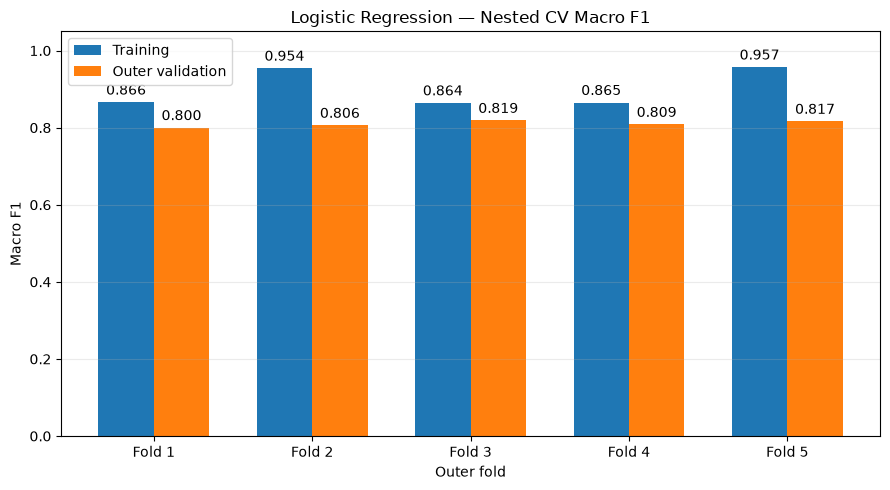

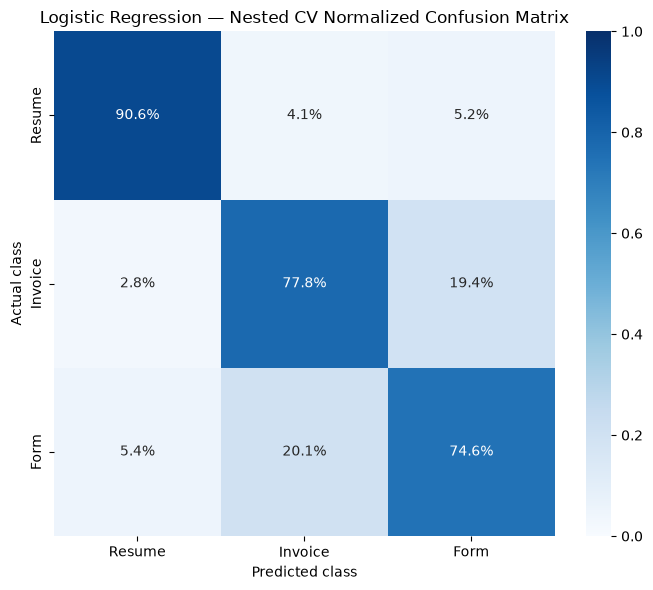


FINAL DEVELOPMENT MODEL FIT
Final selected parameters: {'classifier__C': 0.0001, 'classifier__class_weight': 'balanced'}
Final inner CV macro F1: 0.8067
Final fit/search time: 348.15 seconds

LOGISTIC REGRESSION — NESTED CV COMPLETED

OUTER FOLD RESULTS:


,outer_fold,selected_C,selected_class_weight,train_macro_f1,validation_macro_f1,macro_f1_gap,validation_accuracy
0,1,0.0001,balanced,0.866342,0.800224,0.066118,0.801252
1,2,0.0010,None,0.954366,0.806138,0.148228,0.805795
2,3,0.0001,None,0.864408,0.818869,0.045538,0.818324
3,4,0.0001,balanced,0.865305,0.808519,0.056786,0.809077
4,5,0.0010,balanced,0.957270,0.816575,0.140695,0.817541



OUT-OF-FOLD METRICS:
accuracy: 0.81040
macro_precision: 0.81047
macro_recall: 0.80989
macro_f1: 0.81013
weighted_f1: 0.81069

CLASS-WISE PERFORMANCE:


,class,precision,recall,f1_score,support
0,Resume,0.918588,0.906221,0.912363,2154.0
1,Invoice,0.760334,0.777672,0.768906,2105.0
2,Form,0.752489,0.745771,0.749115,2128.0



FINAL DEVELOPMENT PARAMETERS:
{'classifier__C': 0.0001, 'classifier__class_weight': 'balanced'}

MEAN OUTER VALIDATION MACRO F1: 0.81007
STD OUTER VALIDATION MACRO F1: 0.00766
MEAN TRAINING-VALIDATION MACRO F1 GAP: 0.09147

MODEL DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\logistic_regression\nested_cv_corrected\models

RESULT DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\logistic_regression\nested_cv_corrected\results

GRAPH DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\logistic_regression\nested_cv_corrected\graphs

TEST SET: NOT LOADED
HYPERPARAMETER SELECTION: NESTED GROUP CV
STATUS: COMPLETED


In [10]:

# =====================================================================
# IDP SYSTEM — STAGE 7.3
# LOGISTIC REGRESSION — CORRECTED NESTED CV EXPERIMENT
#
# Previous experiment: reference/dummy result only
# New experiment: nested group-aware CV + fresh hyperparameter tuning
#
# Outer CV: 5 folds
# Inner CV: 4 folds
# Selection metric: Macro F1
# Input: 5940-dimensional HOG
# Test set: NEVER LOADED
#
# Only 2 graphs:
#   1. Training vs validation macro F1
#   2. Normalized out-of-fold confusion matrix
# =====================================================================

from pathlib import Path
from datetime import datetime
import os
import json
import time
import warnings
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.exceptions import ConvergenceWarning


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE = Path(idp_path(r"D:\fullstackfixed\IDP_Final_Output"))

DATA_DIR = BASE / "stage7_model_ready_dataset"

ASSIGNMENT_FILE = (
    DATA_DIR / "model_ready_development_cv_assignments.csv"
)

OUTPUT_DIR = (
    BASE
    / "stage7_model_training_v2"
    / "logistic_regression"
    / "nested_cv_corrected"
)

MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"
GRAPH_DIR = OUTPUT_DIR / "graphs"

for directory in [MODEL_DIR, RESULT_DIR, GRAPH_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

N_FEATURES = 5940
OUTER_FOLDS = 5
INNER_FOLDS = 4
RANDOM_STATE = 42

CLASS_IDS = [0, 1, 2]
CLASS_NAMES = ["Resume", "Invoice", "Form"]

# Fresh search space. Includes the neutral C=1, no-class-weight
# configuration instead of assuming the previous selected settings.
PARAM_GRID = {
    "classifier__C": [
        1e-5,
        1e-4,
        1e-3,
        1e-2,
        1e-1,
        1.0,
        10.0
    ],
    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

print("=" * 75)
print("LOGISTIC REGRESSION — NESTED GROUP CV")
print("=" * 75)


# =====================================================================
# 2. LOAD AND VERIFY DEVELOPMENT ASSIGNMENTS
# =====================================================================

if not ASSIGNMENT_FILE.is_file():
    raise FileNotFoundError(ASSIGNMENT_FILE)

data = pd.read_csv(
    ASSIGNMENT_FILE,
    low_memory=False
)

required = [
    "image_id",
    "file_path",
    "class_name",
    "label",
    "split",
    "duplicate_group_id",
    "cv_fold"
]

missing = [c for c in required if c not in data.columns]

if missing:
    raise ValueError(f"Missing assignment columns: {missing}")

if len(data) != 6387:
    raise ValueError(
        f"Expected 6387 development records; found {len(data)}."
    )

def normalize_path(path):
    return os.path.normcase(
        os.path.normpath(str(path).strip())
    )

data["_key"] = data["file_path"].map(normalize_path)

if data["_key"].duplicated().any():
    raise ValueError("Duplicate file paths in assignments.")

data["label"] = data["label"].astype(int)
data["cv_fold"] = data["cv_fold"].astype(int)

if not data["split"].isin(["train", "validation"]).all():
    raise ValueError("Unexpected split. Test data must be excluded.")

if set(data["cv_fold"].unique()) != set(range(1, 6)):
    raise ValueError("Expected outer folds 1 through 5.")

if data["duplicate_group_id"].isna().any():
    raise ValueError("Missing duplicate group IDs.")

label_map = {
    "resume": 0,
    "invoice": 1,
    "form": 2
}

expected_labels = (
    data["class_name"].str.lower().map(label_map)
)

if expected_labels.isna().any():
    raise ValueError("Unknown class name found.")

if not np.array_equal(
    expected_labels.to_numpy(),
    data["label"].to_numpy()
):
    raise ValueError("Class and numeric label mismatch.")

groups = data["duplicate_group_id"].astype(str).to_numpy()
y = data["label"].to_numpy()
outer_fold_ids = data["cv_fold"].to_numpy()

print("Development documents:", len(data))
print("Class distribution:")
print(data["class_name"].value_counts())


# =====================================================================
# 3. LOAD AND ALIGN HOG FEATURES
# =====================================================================

path_to_position = {
    key: i for i, key in enumerate(data["_key"])
}

X = np.empty(
    (len(data), N_FEATURES),
    dtype=np.float32
)

filled = np.zeros(len(data), dtype=bool)

for split in ["train", "validation"]:

    npz_path = DATA_DIR / f"model_ready_hog_{split}.npz"
    csv_path = DATA_DIR / f"model_ready_hog_mapping_{split}.csv"

    if not npz_path.is_file():
        raise FileNotFoundError(npz_path)

    if not csv_path.is_file():
        raise FileNotFoundError(csv_path)

    archive = np.load(npz_path, allow_pickle=False)
    features = archive["features"]

    mapping = pd.read_csv(csv_path, low_memory=False)

    if features.shape != (len(mapping), N_FEATURES):
        raise ValueError(f"{split}: HOG shape mismatch.")

    if not np.isfinite(features).all():
        raise ValueError(f"{split}: non-finite HOG values.")

    positions = []

    for path in mapping["file_path"]:

        key = normalize_path(path)

        if key not in path_to_position:
            raise ValueError(f"Unexpected HOG path: {path}")

        position = path_to_position[key]

        if data.iloc[position]["split"] != split:
            raise ValueError(
                f"{split}: HOG mapping does not match split."
            )

        positions.append(position)

    positions = np.asarray(positions, dtype=np.int64)

    if filled[positions].any():
        raise ValueError("Duplicate HOG row assignment.")

    X[positions] = features
    filled[positions] = True

    print(f"{split} HOG:", features.shape)

    del archive, features, mapping
    gc.collect()

if not filled.all():
    raise ValueError(
        f"HOG alignment incomplete: {(~filled).sum()} missing rows."
    )

print("Final HOG matrix:", X.shape)


# =====================================================================
# 4. PIPELINE AND METRICS
# =====================================================================

def make_pipeline():

    return Pipeline([
        (
            "scaler",
            StandardScaler(with_mean=False)
        ),
        (
            "classifier",
            LogisticRegression(
                penalty="l2",
                solver="lbfgs",
                max_iter=5000,
                tol=1e-4,
                random_state=RANDOM_STATE
            )
        )
    ])


def calculate_metrics(y_true, y_pred):

    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "macro_precision": float(
            precision_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),
        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),
        "weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="weighted",
                zero_division=0
            )
        )
    }


# =====================================================================
# 5. OUTER 5-FOLD EVALUATION WITH INNER 4-FOLD TUNING
# =====================================================================

outer_results = []
oof_predictions = np.full(len(y), -1, dtype=np.int64)

selected_parameters = []
convergence_messages = []

for outer_fold in range(1, OUTER_FOLDS + 1):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {outer_fold}/{OUTER_FOLDS}")
    print("=" * 70)

    train_idx = np.flatnonzero(
        outer_fold_ids != outer_fold
    )

    valid_idx = np.flatnonzero(
        outer_fold_ids == outer_fold
    )

    X_train = X[train_idx]
    X_valid = X[valid_idx]

    y_train = y[train_idx]
    y_valid = y[valid_idx]

    groups_train = groups[train_idx]
    groups_valid = groups[valid_idx]

    overlap = set(groups_train).intersection(
        set(groups_valid)
    )

    if overlap:
        raise RuntimeError(
            f"Outer fold {outer_fold}: duplicate group leakage."
        )

    # Inner CV operates ONLY on the outer training partition.
    inner_cv = StratifiedGroupKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE + outer_fold
    )

    for inner_train, inner_valid in inner_cv.split(
        X_train,
        y_train,
        groups_train
    ):

        inner_overlap = set(
            groups_train[inner_train]
        ).intersection(
            set(groups_train[inner_valid])
        )

        if inner_overlap:
            raise RuntimeError(
                "Inner CV duplicate group leakage."
            )

    search = GridSearchCV(
        estimator=make_pipeline(),
        param_grid=PARAM_GRID,
        scoring="f1_macro",
        cv=inner_cv,
        refit=True,
        n_jobs=1,
        verbose=0,
        return_train_score=False,
        error_score="raise"
    )

    start = time.perf_counter()

    with warnings.catch_warnings(record=True) as caught:

        warnings.simplefilter("always")

        search.fit(
            X_train,
            y_train,
            groups=groups_train
        )

    elapsed = time.perf_counter() - start

    convergence = [
        str(w.message)
        for w in caught
        if issubclass(w.category, ConvergenceWarning)
    ]

    convergence_messages.extend([
        {
            "outer_fold": outer_fold,
            "message": message
        }
        for message in convergence
    ])

    best_model = search.best_estimator_

    # Evaluate selected model on outer training and unseen outer fold.
    train_pred = best_model.predict(X_train)
    valid_pred = best_model.predict(X_valid)

    train_metrics = calculate_metrics(
        y_train,
        train_pred
    )

    valid_metrics = calculate_metrics(
        y_valid,
        valid_pred
    )

    if np.any(oof_predictions[valid_idx] != -1):
        raise RuntimeError("Duplicate OOF prediction assignment.")

    oof_predictions[valid_idx] = valid_pred

    result = {
        "outer_fold": outer_fold,
        "training_documents": len(train_idx),
        "validation_documents": len(valid_idx),
        "inner_best_cv_macro_f1": float(search.best_score_),
        "selected_C": float(
            search.best_params_["classifier__C"]
        ),
        "selected_class_weight": str(
            search.best_params_["classifier__class_weight"]
        ),
        "search_time_seconds": float(elapsed),
        "convergence_warnings": len(convergence)
    }

    for metric, value in train_metrics.items():
        result[f"train_{metric}"] = value

    for metric, value in valid_metrics.items():
        result[f"validation_{metric}"] = value

    result["macro_f1_gap"] = (
        train_metrics["macro_f1"]
        - valid_metrics["macro_f1"]
    )

    result["accuracy_gap"] = (
        train_metrics["accuracy"]
        - valid_metrics["accuracy"]
    )

    outer_results.append(result)

    selected_parameters.append({
        "outer_fold": outer_fold,
        "best_parameters": search.best_params_,
        "inner_best_macro_f1": float(search.best_score_)
    })

    joblib.dump(
        best_model,
        MODEL_DIR / f"logistic_regression_outer_fold_{outer_fold}.joblib"
    )

    print("Selected parameters:", search.best_params_)
    print("Inner CV macro F1:", round(search.best_score_, 4))
    print("Training macro F1:", round(train_metrics["macro_f1"], 4))
    print("Outer validation macro F1:", round(valid_metrics["macro_f1"], 4))
    print("Macro F1 gap:", round(result["macro_f1_gap"], 4))
    print("Search time:", round(elapsed, 2), "seconds")
    print("Convergence warnings:", len(convergence))

    del search, best_model
    del X_train, X_valid, y_train, y_valid
    gc.collect()


# =====================================================================
# 6. OUT-OF-FOLD EVALUATION
# =====================================================================

if np.any(oof_predictions == -1):
    raise RuntimeError("Incomplete out-of-fold predictions.")

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

oof_cm = confusion_matrix(
    y,
    oof_predictions,
    labels=CLASS_IDS
)

oof_report = classification_report(
    y,
    oof_predictions,
    labels=CLASS_IDS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

outer_df = pd.DataFrame(outer_results)

outer_df.to_csv(
    RESULT_DIR / "outer_fold_metrics.csv",
    index=False
)

pd.DataFrame(
    selected_parameters
).to_json(
    RESULT_DIR / "outer_fold_selected_parameters.json",
    orient="records",
    indent=4
)

pd.DataFrame(
    oof_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    RESULT_DIR / "oof_confusion_matrix.csv"
)

oof_export = data[
    [
        "image_id",
        "file_path",
        "class_name",
        "label",
        "split",
        "duplicate_group_id",
        "cv_fold"
    ]
].copy()

oof_export["predicted_label"] = oof_predictions
oof_export["correct"] = (
    oof_export["label"].to_numpy() == oof_predictions
)

oof_export.to_csv(
    RESULT_DIR / "out_of_fold_predictions.csv",
    index=False
)

with open(
    RESULT_DIR / "oof_classification_report.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(oof_report, f, indent=4)


# =====================================================================
# 7. GRAPH 1 — TRAINING VS VALIDATION MACRO F1
# =====================================================================

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(OUTER_FOLDS)
width = 0.35

ax.bar(
    x - width / 2,
    outer_df["train_macro_f1"],
    width,
    label="Training"
)

ax.bar(
    x + width / 2,
    outer_df["validation_macro_f1"],
    width,
    label="Outer validation"
)

ax.set_title(
    "Logistic Regression — Nested CV Macro F1"
)

ax.set_xlabel("Outer fold")
ax.set_ylabel("Macro F1")
ax.set_xticks(x)
ax.set_xticklabels([
    f"Fold {i}" for i in range(1, OUTER_FOLDS + 1)
])
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

fig.tight_layout()
fig.savefig(
    GRAPH_DIR / "01_nested_cv_macro_f1.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# =====================================================================
# 8. GRAPH 2 — NORMALIZED OOF CONFUSION MATRIX
# =====================================================================

row_totals = oof_cm.sum(axis=1, keepdims=True)

normalized_cm = np.divide(
    oof_cm,
    row_totals,
    out=np.zeros_like(oof_cm, dtype=float),
    where=row_totals != 0
)

fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    normalized_cm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax
)

ax.set_title(
    "Logistic Regression — Nested CV Normalized Confusion Matrix"
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

fig.tight_layout()
fig.savefig(
    GRAPH_DIR / "02_normalized_oof_confusion_matrix.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# =====================================================================
# 9. FINAL HYPERPARAMETER SEARCH ON ALL DEVELOPMENT DATA
#
# This creates the deployable development model.
# It does NOT provide an independent performance estimate.
# =====================================================================

print("\n" + "=" * 70)
print("FINAL DEVELOPMENT MODEL FIT")
print("=" * 70)

final_inner_cv = StratifiedGroupKFold(
    n_splits=INNER_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE + 100
)

final_search = GridSearchCV(
    estimator=make_pipeline(),
    param_grid=PARAM_GRID,
    scoring="f1_macro",
    cv=final_inner_cv,
    refit=True,
    n_jobs=1,
    verbose=0,
    error_score="raise"
)

final_start = time.perf_counter()

with warnings.catch_warnings(record=True) as final_caught:

    warnings.simplefilter("always")

    final_search.fit(
        X,
        y,
        groups=groups
    )

final_fit_time = time.perf_counter() - final_start

final_model = final_search.best_estimator_

joblib.dump(
    final_model,
    MODEL_DIR / "logistic_regression_final_development_model.joblib"
)

print("Final selected parameters:", final_search.best_params_)
print("Final inner CV macro F1:", round(final_search.best_score_, 4))
print("Final fit/search time:", round(final_fit_time, 2), "seconds")


# =====================================================================
# 10. SAVE FINAL EXPERIMENT REPORT
# =====================================================================

class_metrics = pd.DataFrame([
    {
        "class": class_name,
        "precision": oof_report[class_name]["precision"],
        "recall": oof_report[class_name]["recall"],
        "f1_score": oof_report[class_name]["f1-score"],
        "support": oof_report[class_name]["support"]
    }
    for class_name in CLASS_NAMES
])

class_metrics.to_csv(
    RESULT_DIR / "oof_class_wise_metrics.csv",
    index=False
)

summary = {
    "experiment": "Logistic Regression Nested Group CV",
    "timestamp": datetime.now().isoformat(),
    "development_documents": int(len(data)),
    "hog_features": N_FEATURES,
    "outer_folds": OUTER_FOLDS,
    "inner_folds": INNER_FOLDS,
    "selection_metric": "macro_f1",
    "parameter_grid": {
        "C": PARAM_GRID["classifier__C"],
        "class_weight": ["None", "balanced"]
    },
    "outer_cv_mean_validation_macro_f1": float(
        outer_df["validation_macro_f1"].mean()
    ),
    "outer_cv_std_validation_macro_f1": float(
        outer_df["validation_macro_f1"].std(ddof=1)
    ),
    "outer_cv_mean_validation_accuracy": float(
        outer_df["validation_accuracy"].mean()
    ),
    "outer_cv_mean_training_macro_f1": float(
        outer_df["train_macro_f1"].mean()
    ),
    "outer_cv_mean_macro_f1_gap": float(
        outer_df["macro_f1_gap"].mean()
    ),
    "out_of_fold_metrics": oof_metrics,
    "out_of_fold_class_metrics": class_metrics.to_dict(
        orient="records"
    ),
    "out_of_fold_confusion_matrix": oof_cm.tolist(),
    "final_development_parameters": final_search.best_params_,
    "final_development_inner_cv_macro_f1": float(
        final_search.best_score_
    ),
    "convergence_warnings_outer": len(convergence_messages),
    "convergence_warnings_final": sum(
        issubclass(w.category, ConvergenceWarning)
        for w in final_caught
    ),
    "test_set_loaded": False,
    "test_set_used": False,
    "status": "NESTED_CV_COMPLETED"
}

with open(
    RESULT_DIR / "logistic_regression_nested_cv_report.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )

with open(
    RESULT_DIR / "convergence_warnings.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        convergence_messages,
        f,
        indent=4
    )


# =====================================================================
# 11. FINAL OUTPUT
# =====================================================================

print("\n" + "=" * 75)
print("LOGISTIC REGRESSION — NESTED CV COMPLETED")
print("=" * 75)

print("\nOUTER FOLD RESULTS:")
display(
    outer_df[
        [
            "outer_fold",
            "selected_C",
            "selected_class_weight",
            "train_macro_f1",
            "validation_macro_f1",
            "macro_f1_gap",
            "validation_accuracy"
        ]
    ]
)

print("\nOUT-OF-FOLD METRICS:")
for key, value in oof_metrics.items():
    print(f"{key}: {value:.5f}")

print("\nCLASS-WISE PERFORMANCE:")
display(class_metrics)

print("\nFINAL DEVELOPMENT PARAMETERS:")
print(final_search.best_params_)

print("\nMEAN OUTER VALIDATION MACRO F1:",
      round(outer_df["validation_macro_f1"].mean(), 5))

print("STD OUTER VALIDATION MACRO F1:",
      round(outer_df["validation_macro_f1"].std(ddof=1), 5))

print("MEAN TRAINING-VALIDATION MACRO F1 GAP:",
      round(outer_df["macro_f1_gap"].mean(), 5))

print("\nMODEL DIRECTORY:")
print(MODEL_DIR)

print("\nRESULT DIRECTORY:")
print(RESULT_DIR)

print("\nGRAPH DIRECTORY:")
print(GRAPH_DIR)

print("\nTEST SET: NOT LOADED")
print("HYPERPARAMETER SELECTION: NESTED GROUP CV")
print("STATUS: COMPLETED")


**Model 2 — Linear SVM.**

LINEAR SVM — CORRECTIVE NESTED GROUP CV
Parameter candidates: 10
Inner fits per outer fold: 30

Development documents: 6387
Class distribution:
class_name
resume     2154
form       2128
invoice    2105
Name: count, dtype: int64
train HOG loaded: (5259, 5940)
validation HOG loaded: (1128, 5940)

Final development HOG matrix: (6387, 5940)

CORRECTIVE SVM — OUTER FOLD 1/5
Fitting 3 folds for each of 10 candidates, totalling 30 fits

SELECTED PARAMETERS: {'classifier__C': 3e-05, 'classifier__class_weight': None}
Inner CV macro F1: 0.80445
Training macro F1: 0.88493
Outer validation macro F1: 0.80444
Generalization gap: 0.08049
Search time: 238.35 seconds
Convergence warnings: 0

CORRECTIVE SVM — OUTER FOLD 2/5
Fitting 3 folds for each of 10 candidates, totalling 30 fits

SELECTED PARAMETERS: {'classifier__C': 0.0001, 'classifier__class_weight': 'balanced'}
Inner CV macro F1: 0.80439
Training macro F1: 0.93451
Outer validation macro F1: 0.81078
Generalization gap: 0.12373
Search time: 228.

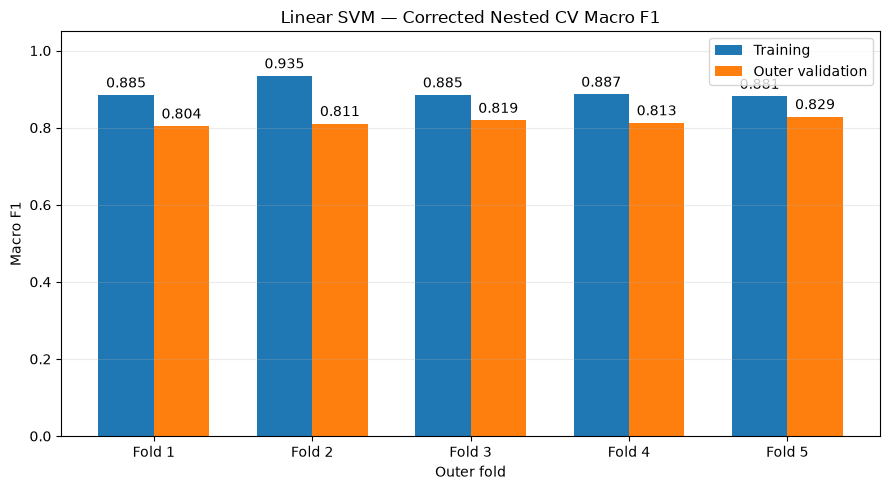

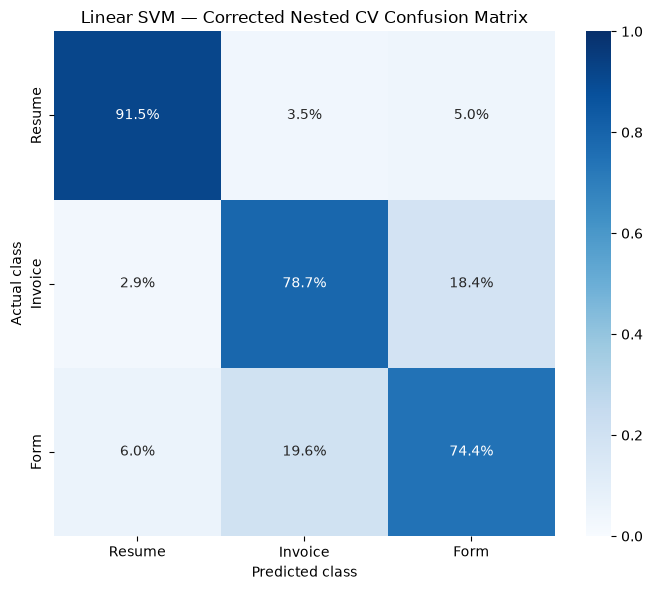


FINAL DEVELOPMENT SVM SEARCH
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Final development parameters: {'classifier__C': 3e-05, 'classifier__class_weight': 'balanced'}
Final inner CV macro F1: 0.80985

LINEAR SVM — CORRECTIVE EXPERIMENT COMPLETED

OUTER FOLD PERFORMANCE:


,outer_fold,selected_C,selected_class_weight,train_macro_f1,validation_macro_f1,macro_f1_gap,validation_accuracy,convergence_warnings
0,1,0.00003,None,0.884930,0.804442,0.080489,0.805947,0
1,2,0.00010,balanced,0.934512,0.810780,0.123732,0.810493,0
2,3,0.00003,balanced,0.885079,0.819177,0.065902,0.819107,0
3,4,0.00003,balanced,0.886821,0.812707,0.074114,0.813772,0
4,5,0.00003,balanced,0.881423,0.828651,0.052772,0.830070,0



OUT-OF-FOLD METRICS:
accuracy: 0.81588
macro_precision: 0.81516
macro_recall: 0.81537
macro_f1: 0.81520
weighted_f1: 0.81573

CLASS-WISE RESULTS:


,class,precision,recall,f1_score,support
0,Resume,0.912882,0.914578,0.913729,2154.0
1,Invoice,0.770698,0.787173,0.778848,2105.0
2,Form,0.761905,0.744361,0.753031,2128.0



MEAN OUTER VALIDATION MACRO F1: 0.81515
VALIDATION MACRO F1 STD: 0.0092
MEAN TRAINING MACRO F1: 0.89455
MEAN GENERALIZATION GAP: 0.0794

FINAL DEVELOPMENT PARAMETERS:
{'classifier__C': 3e-05, 'classifier__class_weight': 'balanced'}

MODEL DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\svm\linear_svm\corrective_nested_cv\models

RESULT DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\svm\linear_svm\corrective_nested_cv\results

GRAPH DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\svm\linear_svm\corrective_nested_cv\graphs

TEST SET: NOT LOADED
STATUS: CORRECTIVE EXPERIMENT COMPLETED


In [12]:

# =====================================================================
# IDP SYSTEM — STAGE 7
# MODEL 2: LINEAR SVM — CORRECTIVE TRAINING & FINE-TUNING
#
# Previous dummy result:
#   C=1.0, class_weight=None
#   100% training macro F1
#   76.07% validation macro F1
#   23.93 percentage-point gap
#
# Corrective strategy:
#   Stronger L2 regularization using smaller C values.
#   Compare class_weight=None and balanced.
#
# Nested evaluation:
#   Outer CV: 5 folds
#   Inner CV: 3 folds
#
# Only two graphs:
#   1. Training vs outer validation macro F1
#   2. Normalized OOF confusion matrix
#
# Test set: NEVER LOADED
# =====================================================================

from pathlib import Path
from datetime import datetime
import os
import json
import time
import warnings
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.exceptions import ConvergenceWarning


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE = Path(idp_path(r"D:\fullstackfixed\IDP_Final_Output"))

DATA_DIR = BASE / "stage7_model_ready_dataset"

ASSIGNMENT_FILE = (
    DATA_DIR / "model_ready_development_cv_assignments.csv"
)

OUTPUT_DIR = (
    BASE
    / "stage7_model_training_v2"
    / "svm"
    / "linear_svm"
    / "corrective_nested_cv"
)

MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"
GRAPH_DIR = OUTPUT_DIR / "graphs"

for folder in [MODEL_DIR, RESULT_DIR, GRAPH_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

N_FEATURES = 5940
OUTER_FOLDS = 5
INNER_FOLDS = 3

RANDOM_STATE = 42

CLASS_IDS = [0, 1, 2]
CLASS_NAMES = ["Resume", "Invoice", "Form"]

# Compact regularization search.
PARAM_GRID = {
    "classifier__C": [
        1e-6,
        1e-5,
        3e-5,
        1e-4,
        3e-4
    ],
    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

MAX_ITER = 30000
TOLERANCE = 1e-4

print("=" * 75)
print("LINEAR SVM — CORRECTIVE NESTED GROUP CV")
print("=" * 75)

print("Parameter candidates:", len(PARAM_GRID["classifier__C"]) *
      len(PARAM_GRID["classifier__class_weight"]))

print("Inner fits per outer fold:",
      len(PARAM_GRID["classifier__C"]) *
      len(PARAM_GRID["classifier__class_weight"]) *
      INNER_FOLDS)


# =====================================================================
# 2. LOAD DEVELOPMENT FOLD ASSIGNMENTS
# =====================================================================

if not ASSIGNMENT_FILE.is_file():
    raise FileNotFoundError(ASSIGNMENT_FILE)

data = pd.read_csv(
    ASSIGNMENT_FILE,
    low_memory=False
)

required_columns = [
    "image_id",
    "file_path",
    "class_name",
    "label",
    "split",
    "duplicate_group_id",
    "cv_fold"
]

missing = [
    c for c in required_columns
    if c not in data.columns
]

if missing:
    raise ValueError(
        f"Missing assignment columns: {missing}"
    )

if len(data) != 6387:
    raise ValueError(
        f"Expected 6387 development documents; got {len(data)}."
    )

def normalize_path(path):
    return os.path.normcase(
        os.path.normpath(str(path).strip())
    )

data["_key"] = data["file_path"].map(normalize_path)

if data["_key"].duplicated().any():
    raise ValueError("Duplicate document paths detected.")

data["label"] = data["label"].astype(int)
data["cv_fold"] = data["cv_fold"].astype(int)

if not data["split"].isin(
    ["train", "validation"]
).all():
    raise ValueError(
        "Unexpected split. Test data must not enter training."
    )

if set(data["cv_fold"].unique()) != set(range(1, 6)):
    raise ValueError("Expected five outer folds.")

if data["duplicate_group_id"].isna().any():
    raise ValueError("Missing duplicate group IDs.")

label_map = {
    "resume": 0,
    "invoice": 1,
    "form": 2
}

expected_labels = (
    data["class_name"]
    .astype(str)
    .str.lower()
    .map(label_map)
)

if expected_labels.isna().any():
    raise ValueError("Unknown document class.")

if not np.array_equal(
    expected_labels.to_numpy(),
    data["label"].to_numpy()
):
    raise ValueError("Class/label mapping mismatch.")

y = data["label"].to_numpy(dtype=np.int64)

groups = (
    data["duplicate_group_id"]
    .astype(str)
    .to_numpy()
)

outer_fold_ids = data["cv_fold"].to_numpy(dtype=np.int64)

print("\nDevelopment documents:", len(data))
print("Class distribution:")
print(data["class_name"].value_counts())


# =====================================================================
# 3. LOAD AND ALIGN HOG FEATURES
# =====================================================================

path_positions = {
    key: i
    for i, key in enumerate(data["_key"])
}

X = np.empty(
    (len(data), N_FEATURES),
    dtype=np.float32
)

filled = np.zeros(
    len(data),
    dtype=bool
)

for split in ["train", "validation"]:

    npz_path = (
        DATA_DIR / f"model_ready_hog_{split}.npz"
    )

    mapping_path = (
        DATA_DIR / f"model_ready_hog_mapping_{split}.csv"
    )

    if not npz_path.is_file():
        raise FileNotFoundError(npz_path)

    if not mapping_path.is_file():
        raise FileNotFoundError(mapping_path)

    archive = np.load(
        npz_path,
        allow_pickle=False
    )

    features = archive["features"]

    mapping = pd.read_csv(
        mapping_path,
        low_memory=False
    )

    if features.shape != (
        len(mapping),
        N_FEATURES
    ):
        raise ValueError(
            f"{split}: HOG matrix/mapping shape mismatch."
        )

    if not np.isfinite(features).all():
        raise ValueError(
            f"{split}: non-finite HOG values."
        )

    positions = []

    for path in mapping["file_path"]:

        key = normalize_path(path)

        if key not in path_positions:
            raise ValueError(
                f"Unknown HOG document: {path}"
            )

        position = path_positions[key]

        if data.iloc[position]["split"] != split:
            raise ValueError(
                f"{split}: incorrect HOG split mapping."
            )

        positions.append(position)

    positions = np.asarray(
        positions,
        dtype=np.int64
    )

    if filled[positions].any():
        raise ValueError(
            f"{split}: duplicate HOG row assignment."
        )

    X[positions] = features
    filled[positions] = True

    print(f"{split} HOG loaded:", features.shape)

    del archive, features, mapping
    gc.collect()

if not filled.all():
    raise ValueError(
        f"HOG alignment incomplete: {(~filled).sum()} rows."
    )

print("\nFinal development HOG matrix:", X.shape)


# =====================================================================
# 4. METRICS AND MODEL PIPELINE
# =====================================================================

def make_pipeline():

    return Pipeline([
        (
            "scaler",
            StandardScaler(
                with_mean=False,
                with_std=True
            )
        ),

        (
            "classifier",
            LinearSVC(
                penalty="l2",
                loss="squared_hinge",
                dual="auto",
                max_iter=MAX_ITER,
                tol=TOLERANCE,
                random_state=RANDOM_STATE
            )
        )
    ])


def calculate_metrics(y_true, y_pred):

    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),

        "macro_precision": float(
            precision_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),

        "macro_recall": float(
            recall_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),

        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),

        "weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="weighted",
                zero_division=0
            )
        )
    }


# =====================================================================
# 5. OUTER 5-FOLD + INNER 3-FOLD TUNING
# =====================================================================

outer_results = []

oof_predictions = np.full(
    len(y),
    -1,
    dtype=np.int64
)

convergence_records = []

for outer_fold in range(1, OUTER_FOLDS + 1):

    print("\n" + "=" * 70)
    print(
        f"CORRECTIVE SVM — OUTER FOLD "
        f"{outer_fold}/{OUTER_FOLDS}"
    )
    print("=" * 70)

    train_idx = np.flatnonzero(
        outer_fold_ids != outer_fold
    )

    valid_idx = np.flatnonzero(
        outer_fold_ids == outer_fold
    )

    X_train = X[train_idx]
    X_valid = X[valid_idx]

    y_train = y[train_idx]
    y_valid = y[valid_idx]

    groups_train = groups[train_idx]
    groups_valid = groups[valid_idx]

    # Outer duplicate isolation.
    outer_overlap = set(
        groups_train
    ).intersection(
        set(groups_valid)
    )

    if outer_overlap:
        raise RuntimeError(
            f"Outer fold {outer_fold}: duplicate-group leakage."
        )

    # Inner grouped CV operates only on outer training data.
    inner_cv = StratifiedGroupKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE + outer_fold
    )

    search = GridSearchCV(
        estimator=make_pipeline(),
        param_grid=PARAM_GRID,
        scoring="f1_macro",
        cv=inner_cv,
        refit=True,
        n_jobs=1,
        verbose=1,
        return_train_score=False,
        error_score="raise"
    )

    start = time.perf_counter()

    with warnings.catch_warnings(record=True) as caught:

        warnings.simplefilter("always")

        search.fit(
            X_train,
            y_train,
            groups=groups_train
        )

    search_time = time.perf_counter() - start

    fold_warnings = [
        str(w.message)
        for w in caught
        if issubclass(
            w.category,
            ConvergenceWarning
        )
    ]

    convergence_records.append({
        "outer_fold": outer_fold,
        "warning_count": len(fold_warnings),
        "warnings": fold_warnings
    })

    best_model = search.best_estimator_

    # Evaluate selected configuration on the complete outer
    # training partition and the untouched outer validation fold.
    train_pred = best_model.predict(X_train)
    valid_pred = best_model.predict(X_valid)

    train_metrics = calculate_metrics(
        y_train,
        train_pred
    )

    valid_metrics = calculate_metrics(
        y_valid,
        valid_pred
    )

    if np.any(oof_predictions[valid_idx] != -1):
        raise RuntimeError(
            "Duplicate OOF predictions detected."
        )

    oof_predictions[valid_idx] = valid_pred

    result = {
        "outer_fold": outer_fold,
        "training_documents": len(train_idx),
        "validation_documents": len(valid_idx),

        "selected_C": float(
            search.best_params_["classifier__C"]
        ),

        "selected_class_weight": str(
            search.best_params_["classifier__class_weight"]
        ),

        "inner_best_macro_f1": float(
            search.best_score_
        ),

        "search_time_seconds": float(
            search_time
        ),

        "convergence_warnings": len(
            fold_warnings
        )
    }

    for metric, value in train_metrics.items():
        result[f"train_{metric}"] = value

    for metric, value in valid_metrics.items():
        result[f"validation_{metric}"] = value

    result["macro_f1_gap"] = (
        train_metrics["macro_f1"]
        - valid_metrics["macro_f1"]
    )

    result["accuracy_gap"] = (
        train_metrics["accuracy"]
        - valid_metrics["accuracy"]
    )

    outer_results.append(result)

    # Save each outer-fold pipeline.
    joblib.dump(
        best_model,
        MODEL_DIR / f"linear_svm_outer_fold_{outer_fold}.joblib"
    )

    print("\nSELECTED PARAMETERS:", search.best_params_)
    print(
        "Inner CV macro F1:",
        round(search.best_score_, 5)
    )

    print(
        "Training macro F1:",
        round(train_metrics["macro_f1"], 5)
    )

    print(
        "Outer validation macro F1:",
        round(valid_metrics["macro_f1"], 5)
    )

    print(
        "Generalization gap:",
        round(result["macro_f1_gap"], 5)
    )

    print(
        "Search time:",
        round(search_time, 2),
        "seconds"
    )

    print(
        "Convergence warnings:",
        len(fold_warnings)
    )

    del search, best_model
    del X_train, X_valid, y_train, y_valid
    gc.collect()


# =====================================================================
# 6. VERIFY OOF PREDICTIONS
# =====================================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Some documents lack OOF predictions."
    )

outer_df = pd.DataFrame(outer_results)

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

oof_cm = confusion_matrix(
    y,
    oof_predictions,
    labels=CLASS_IDS
)

oof_report = classification_report(
    y,
    oof_predictions,
    labels=CLASS_IDS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame([
    {
        "class": name,
        "precision": oof_report[name]["precision"],
        "recall": oof_report[name]["recall"],
        "f1_score": oof_report[name]["f1-score"],
        "support": oof_report[name]["support"]
    }
    for name in CLASS_NAMES
])

# Save fold-level metrics.
outer_df.to_csv(
    RESULT_DIR / "outer_fold_metrics.csv",
    index=False
)

# Save per-class results.
class_metrics.to_csv(
    RESULT_DIR / "oof_class_wise_metrics.csv",
    index=False
)

# Save confusion matrix.
pd.DataFrame(
    oof_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    RESULT_DIR / "oof_confusion_matrix.csv"
)

# Save OOF predictions.
oof_export = data[
    [
        "image_id",
        "file_path",
        "class_name",
        "label",
        "split",
        "duplicate_group_id",
        "cv_fold"
    ]
].copy()

oof_export["predicted_label"] = oof_predictions

oof_export["correct"] = (
    oof_export["label"].to_numpy()
    == oof_predictions
)

oof_export.to_csv(
    RESULT_DIR / "out_of_fold_predictions.csv",
    index=False
)


# =====================================================================
# 7. GRAPH 1 — TRAINING VS VALIDATION MACRO F1
# =====================================================================

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(OUTER_FOLDS)
width = 0.35

ax.bar(
    positions - width / 2,
    outer_df["train_macro_f1"],
    width,
    label="Training"
)

ax.bar(
    positions + width / 2,
    outer_df["validation_macro_f1"],
    width,
    label="Outer validation"
)

ax.set_title(
    "Linear SVM — Corrected Nested CV Macro F1"
)

ax.set_xlabel("Outer fold")
ax.set_ylabel("Macro F1")

ax.set_xticks(positions)
ax.set_xticklabels([
    f"Fold {i}" for i in range(1, OUTER_FOLDS + 1)
])

ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

fig.tight_layout()

fig.savefig(
    GRAPH_DIR / "01_corrected_nested_cv_macro_f1.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# =====================================================================
# 8. GRAPH 2 — NORMALIZED OOF CONFUSION MATRIX
# =====================================================================

row_totals = oof_cm.sum(
    axis=1,
    keepdims=True
)

normalized_cm = np.divide(
    oof_cm,
    row_totals,
    out=np.zeros_like(oof_cm, dtype=float),
    where=row_totals != 0
)

fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    normalized_cm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax
)

ax.set_title(
    "Linear SVM — Corrected Nested CV Confusion Matrix"
)

ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

fig.tight_layout()

fig.savefig(
    GRAPH_DIR / "02_corrected_normalized_confusion_matrix.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# =====================================================================
# 9. FINAL DEVELOPMENT MODEL
#
# Fresh inner group-CV search on all development records.
# Its inner-CV score is NOT the independent performance estimate.
# The outer CV result remains the performance estimate.
# =====================================================================

print("\n" + "=" * 70)
print("FINAL DEVELOPMENT SVM SEARCH")
print("=" * 70)

final_inner_cv = StratifiedGroupKFold(
    n_splits=INNER_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE + 100
)

final_search = GridSearchCV(
    estimator=make_pipeline(),
    param_grid=PARAM_GRID,
    scoring="f1_macro",
    cv=final_inner_cv,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

with warnings.catch_warnings(record=True) as final_caught:

    warnings.simplefilter("always")

    final_search.fit(
        X,
        y,
        groups=groups
    )

final_model = final_search.best_estimator_

joblib.dump(
    final_model,
    MODEL_DIR / "linear_svm_final_development_model.joblib"
)

print(
    "Final development parameters:",
    final_search.best_params_
)

print(
    "Final inner CV macro F1:",
    round(final_search.best_score_, 5)
)


# =====================================================================
# 10. SAVE REPORT
# =====================================================================

summary = {
    "experiment": "Linear SVM Corrective Nested Group CV",

    "timestamp": datetime.now().isoformat(),

    "development_documents": len(data),

    "hog_dimensions": N_FEATURES,

    "outer_folds": OUTER_FOLDS,

    "inner_folds": INNER_FOLDS,

    "selection_metric": "macro_f1",

    "parameter_grid": {
        "C": PARAM_GRID["classifier__C"],
        "class_weight": ["None", "balanced"]
    },

    "outer_validation_macro_f1_mean": float(
        outer_df["validation_macro_f1"].mean()
    ),

    "outer_validation_macro_f1_std": float(
        outer_df["validation_macro_f1"].std(ddof=1)
    ),

    "outer_validation_accuracy_mean": float(
        outer_df["validation_accuracy"].mean()
    ),

    "mean_training_macro_f1": float(
        outer_df["train_macro_f1"].mean()
    ),

    "mean_macro_f1_gap": float(
        outer_df["macro_f1_gap"].mean()
    ),

    "oof_metrics": oof_metrics,

    "class_wise_metrics": class_metrics.to_dict(
        orient="records"
    ),

    "oof_confusion_matrix": oof_cm.tolist(),

    "fold_selected_parameters": (
        outer_df[
            [
                "outer_fold",
                "selected_C",
                "selected_class_weight",
                "inner_best_macro_f1"
            ]
        ].to_dict(orient="records")
    ),

    "final_development_parameters": final_search.best_params_,

    "convergence_warning_count": int(
        sum(
            row["convergence_warnings"]
            for row in outer_results
        )
    ),

    "test_set_loaded": False,

    "test_set_used": False,

    "status": "CORRECTIVE_NESTED_CV_COMPLETED"
}

with open(
    RESULT_DIR / "linear_svm_corrective_report.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# =====================================================================
# 11. FINAL OUTPUT
# =====================================================================

print("\n" + "=" * 75)
print("LINEAR SVM — CORRECTIVE EXPERIMENT COMPLETED")
print("=" * 75)

print("\nOUTER FOLD PERFORMANCE:")

display(
    outer_df[
        [
            "outer_fold",
            "selected_C",
            "selected_class_weight",
            "train_macro_f1",
            "validation_macro_f1",
            "macro_f1_gap",
            "validation_accuracy",
            "convergence_warnings"
        ]
    ]
)

print("\nOUT-OF-FOLD METRICS:")

for metric, value in oof_metrics.items():
    print(f"{metric}: {value:.5f}")

print("\nCLASS-WISE RESULTS:")
display(class_metrics)

print("\nMEAN OUTER VALIDATION MACRO F1:",
      round(outer_df["validation_macro_f1"].mean(), 5))

print("VALIDATION MACRO F1 STD:",
      round(outer_df["validation_macro_f1"].std(ddof=1), 5))

print("MEAN TRAINING MACRO F1:",
      round(outer_df["train_macro_f1"].mean(), 5))

print("MEAN GENERALIZATION GAP:",
      round(outer_df["macro_f1_gap"].mean(), 5))

print("\nFINAL DEVELOPMENT PARAMETERS:")
print(final_search.best_params_)

print("\nMODEL DIRECTORY:")
print(MODEL_DIR)

print("\nRESULT DIRECTORY:")
print(RESULT_DIR)

print("\nGRAPH DIRECTORY:")
print(GRAPH_DIR)

print("\nTEST SET: NOT LOADED")
print("STATUS: CORRECTIVE EXPERIMENT COMPLETED")


**Model 3 — KNN**

KNN — CORRECTIVE NESTED GROUP CV
Candidate configurations: 8
Inner CV fits per outer fold: 24

Development documents: 6387
Class distribution:
class_name
resume     2154
form       2128
invoice    2105
Name: count, dtype: int64
train HOG loaded: (5259, 5940)
validation HOG loaded: (1128, 5940)

Final development matrix: (6387, 5940)

KNN CORRECTIVE — OUTER FOLD 1/5
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Selected parameters: {'classifier__n_neighbors': 3, 'classifier__weights': 'distance'}
Inner CV macro F1: 0.65647
Training group-excluded LOO macro F1: 0.65167
Outer validation macro F1: 0.69036
Generalization gap: -0.03869
Search time: 32.09 seconds

KNN CORRECTIVE — OUTER FOLD 2/5
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Selected parameters: {'classifier__n_neighbors': 3, 'classifier__weights': 'distance'}
Inner CV macro F1: 0.6615
Training group-excluded LOO macro F1: 0.69362
Outer validation macro F1: 0.67593
Generalization gap: 0.01769
Sear

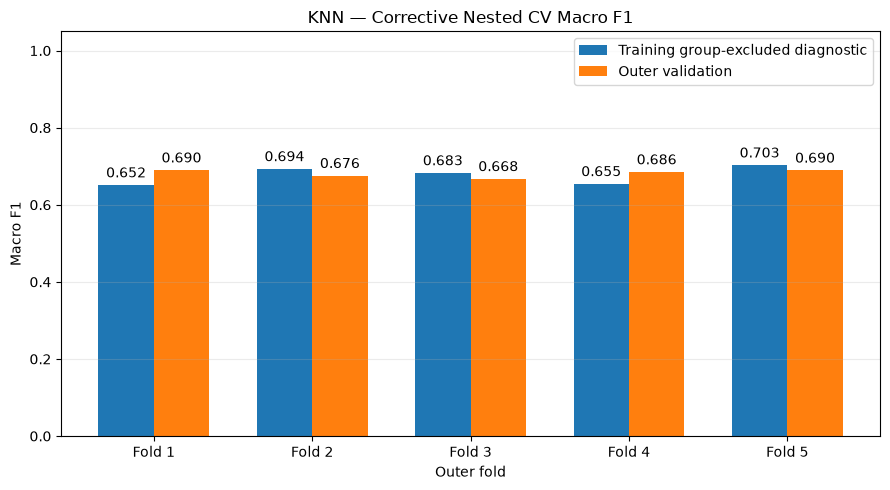

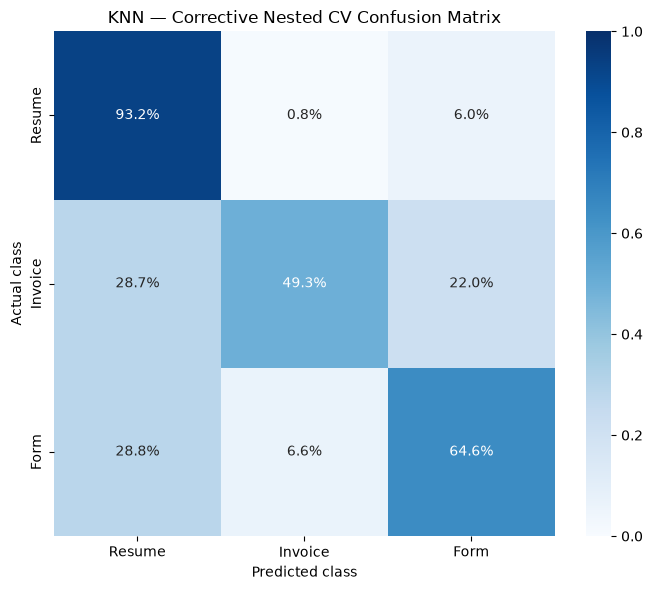


FINAL DEVELOPMENT KNN SEARCH
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Final parameters: {'classifier__n_neighbors': 3, 'classifier__weights': 'distance'}
Final inner CV macro F1: 0.67183
Final search time: 44.64 seconds

KNN — CORRECTIVE NESTED CV COMPLETED

OUTER FOLD RESULTS:


,outer_fold,selected_k,selected_weights,train_loo_macro_f1,validation_macro_f1,macro_f1_gap,validation_accuracy,search_time_seconds
0,1,3,distance,0.651668,0.690357,-0.038689,0.699531,32.093151
1,2,3,distance,0.693623,0.675935,0.017688,0.685200,33.523685
2,3,3,distance,0.683056,0.667866,0.015190,0.675803,33.118260
3,4,3,distance,0.654852,0.685501,-0.030649,0.697966,32.884375
4,5,3,distance,0.703186,0.689854,0.013332,0.700078,32.284247



OUT-OF-FOLD METRICS:
accuracy: 0.69172
macro_precision: 0.72954
macro_recall: 0.69002
macro_f1: 0.68193
weighted_f1: 0.68238

CLASS-WISE PERFORMANCE:


,class,precision,recall,f1_score,support
0,Resume,0.622326,0.931755,0.746235,2154.0
1,Invoice,0.867782,0.492637,0.628485,2105.0
2,Form,0.698526,0.645677,0.671062,2128.0



MEAN TRAINING GROUP-EXCLUDED MACRO F1: 0.67728
MEAN OUTER VALIDATION MACRO F1: 0.6819
VALIDATION MACRO F1 STD: 0.00975
MEAN GENERALIZATION GAP: -0.00463

FINAL DEVELOPMENT PARAMETERS:
{'classifier__n_neighbors': 3, 'classifier__weights': 'distance'}

MODEL DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\knn\full_hog\corrective_nested_cv\models

RESULT DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\knn\full_hog\corrective_nested_cv\results

GRAPH DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\knn\full_hog\corrective_nested_cv\graphs

TEST SET: NOT LOADED
STATUS: CORRECTIVE EXPERIMENT COMPLETED


In [15]:

# =====================================================================
# IDP SYSTEM — STAGE 7
# MODEL 3: KNN — CORRECTIVE NESTED GROUP CV
#
# Dummy baseline:
#   k=5, uniform voting, Euclidean distance
#   Validation macro F1: 64.73%
#   Training LOO macro F1: 65.25%
#
# Corrective strategy:
#   Tune neighbourhood size and distance weighting.
#
# Outer CV: 5 folds
# Inner CV: 3 folds
# Selection metric: Macro F1
#
# Training diagnostic:
#   Sampled leave-one-duplicate-group-out neighbour voting.
#
# Test set: NEVER LOADED
#
# Graphs:
#   1. Training diagnostic vs outer validation macro F1
#   2. Normalized OOF confusion matrix
# =====================================================================

from pathlib import Path
from datetime import datetime
import os
import json
import time
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE = Path(idp_path(r"D:\fullstackfixed\IDP_Final_Output"))

DATA_DIR = BASE / "stage7_model_ready_dataset"

ASSIGNMENT_FILE = (
    DATA_DIR / "model_ready_development_cv_assignments.csv"
)

OUTPUT_DIR = (
    BASE
    / "stage7_model_training_v2"
    / "knn"
    / "full_hog"
    / "corrective_nested_cv"
)

MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"
GRAPH_DIR = OUTPUT_DIR / "graphs"

for folder in [MODEL_DIR, RESULT_DIR, GRAPH_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

N_FEATURES = 5940
OUTER_FOLDS = 5
INNER_FOLDS = 3

RANDOM_STATE = 42
LOO_SAMPLE_SIZE = 500

CLASS_IDS = [0, 1, 2]
CLASS_NAMES = ["Resume", "Invoice", "Form"]

# Compact search space.
PARAM_GRID = {
    "classifier__n_neighbors": [
        3, 5, 11, 21
    ],
    "classifier__weights": [
        "uniform",
        "distance"
    ]
}

print("=" * 75)
print("KNN — CORRECTIVE NESTED GROUP CV")
print("=" * 75)

print("Candidate configurations:", 8)
print("Inner CV fits per outer fold:", 24)


# =====================================================================
# 2. LOAD AND VERIFY DEVELOPMENT ASSIGNMENTS
# =====================================================================

if not ASSIGNMENT_FILE.is_file():
    raise FileNotFoundError(ASSIGNMENT_FILE)

data = pd.read_csv(
    ASSIGNMENT_FILE,
    low_memory=False
)

required_columns = [
    "image_id",
    "file_path",
    "class_name",
    "label",
    "split",
    "duplicate_group_id",
    "cv_fold"
]

missing = [
    c for c in required_columns
    if c not in data.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}"
    )

if len(data) != 6387:
    raise ValueError(
        f"Expected 6387 development records; got {len(data)}."
    )

def normalize_path(path):
    return os.path.normcase(
        os.path.normpath(str(path).strip())
    )

data["_key"] = data["file_path"].map(normalize_path)

if data["_key"].duplicated().any():
    raise ValueError("Duplicate document paths.")

data["label"] = data["label"].astype(int)
data["cv_fold"] = data["cv_fold"].astype(int)

if not data["split"].isin(
    ["train", "validation"]
).all():
    raise ValueError(
        "Test documents detected in development assignments."
    )

if set(data["cv_fold"].unique()) != set(range(1, 6)):
    raise ValueError("Expected five outer folds.")

if data["duplicate_group_id"].isna().any():
    raise ValueError("Missing duplicate group identifiers.")

label_map = {
    "resume": 0,
    "invoice": 1,
    "form": 2
}

expected_labels = (
    data["class_name"]
    .astype(str)
    .str.lower()
    .map(label_map)
)

if expected_labels.isna().any():
    raise ValueError("Unknown class names.")

if not np.array_equal(
    expected_labels.to_numpy(),
    data["label"].to_numpy()
):
    raise ValueError("Class/label mismatch.")

y = data["label"].to_numpy(dtype=np.int64)

groups = (
    data["duplicate_group_id"]
    .astype(str)
    .to_numpy()
)

outer_fold_ids = data["cv_fold"].to_numpy(dtype=np.int64)

print("\nDevelopment documents:", len(data))
print("Class distribution:")
print(data["class_name"].value_counts())


# =====================================================================
# 3. LOAD AND ALIGN HOG FEATURES
# =====================================================================

path_positions = {
    key: i
    for i, key in enumerate(data["_key"])
}

X = np.empty(
    (len(data), N_FEATURES),
    dtype=np.float32
)

filled = np.zeros(
    len(data),
    dtype=bool
)

for split in ["train", "validation"]:

    npz_path = (
        DATA_DIR / f"model_ready_hog_{split}.npz"
    )

    mapping_path = (
        DATA_DIR / f"model_ready_hog_mapping_{split}.csv"
    )

    if not npz_path.is_file():
        raise FileNotFoundError(npz_path)

    if not mapping_path.is_file():
        raise FileNotFoundError(mapping_path)

    archive = np.load(
        npz_path,
        allow_pickle=False
    )

    features = archive["features"]

    mapping = pd.read_csv(
        mapping_path,
        low_memory=False
    )

    if features.shape != (
        len(mapping),
        N_FEATURES
    ):
        raise ValueError(
            f"{split}: HOG matrix/mapping mismatch."
        )

    if not np.isfinite(features).all():
        raise ValueError(
            f"{split}: non-finite HOG values."
        )

    positions = []

    for path in mapping["file_path"]:

        key = normalize_path(path)

        if key not in path_positions:
            raise ValueError(
                f"Unknown HOG path: {path}"
            )

        position = path_positions[key]

        if data.iloc[position]["split"] != split:
            raise ValueError(
                f"{split}: incorrect split mapping."
            )

        positions.append(position)

    positions = np.asarray(
        positions,
        dtype=np.int64
    )

    if filled[positions].any():
        raise ValueError(
            f"{split}: duplicate HOG row assignments."
        )

    X[positions] = features
    filled[positions] = True

    print(f"{split} HOG loaded:", features.shape)

    del archive, features, mapping
    gc.collect()

if not filled.all():
    raise ValueError(
        f"HOG alignment incomplete: {(~filled).sum()} rows."
    )

print("\nFinal development matrix:", X.shape)


# =====================================================================
# 4. PIPELINE AND METRICS
# =====================================================================

def make_pipeline():

    return Pipeline([
        (
            "scaler",
            StandardScaler(
                with_mean=False,
                with_std=True
            )
        ),
        (
            "classifier",
            KNeighborsClassifier(
                algorithm="brute",
                metric="euclidean",
                n_jobs=-1
            )
        )
    ])


def calculate_metrics(y_true, y_pred):

    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),

        "macro_precision": float(
            precision_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),

        "macro_recall": float(
            recall_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),

        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),

        "weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="weighted",
                zero_division=0
            )
        )
    }


# =====================================================================
# 5. GROUP-EXCLUDED TRAINING DIAGNOSTIC
# =====================================================================

def training_group_excluded_predictions(
    scaler,
    knn,
    X_train,
    y_train,
    groups_train,
    sample_size,
    seed
):
    """
    Sample training documents as queries.

    Other documents belonging to the same duplicate group
    are excluded from their neighbourhoods.

    This is a training diagnostic, not an independent test score.
    """

    rng = np.random.default_rng(seed)

    sample_size = min(
        sample_size,
        len(X_train)
    )

    sample_indices = np.sort(
        rng.choice(
            len(X_train),
            size=sample_size,
            replace=False
        )
    )

    query_groups = groups_train[sample_indices]

    unique_group_counts = pd.Series(
        groups_train
    ).value_counts()

    largest_group = int(
        unique_group_counts.max()
    )

    k = int(
        knn.n_neighbors
    )

    requested = min(
        len(X_train),
        k + largest_group
    )

    query_X = X_train[sample_indices]

    distances, indices = knn.kneighbors(
        query_X,
        n_neighbors=requested,
        return_distance=True
    )

    predictions = []

    for row_idx in range(len(sample_indices)):

        query_position = sample_indices[row_idx]
        query_group = query_groups[row_idx]

        candidate_indices = indices[row_idx]
        candidate_distances = distances[row_idx]

        valid_mask = (
            (candidate_indices != query_position)
            &
            (groups_train[candidate_indices] != query_group)
        )

        valid_indices = candidate_indices[valid_mask]
        valid_distances = candidate_distances[valid_mask]

        valid_indices = valid_indices[:k]
        valid_distances = valid_distances[:k]

        if len(valid_indices) < k:
            raise RuntimeError(
                "Not enough neighbours after excluding "
                "the query's duplicate group."
            )

        neighbour_labels = y_train[valid_indices]

        if knn.weights == "distance":

            zero_mask = valid_distances == 0

            # Match sklearn distance-voting behaviour:
            # if zero-distance neighbours exist, they receive
            # all voting weight.
            if zero_mask.any():

                votes = np.bincount(
                    neighbour_labels[zero_mask],
                    minlength=len(CLASS_IDS)
                )

            else:

                weights = 1.0 / valid_distances

                votes = np.bincount(
                    neighbour_labels,
                    weights=weights,
                    minlength=len(CLASS_IDS)
                )

        else:

            votes = np.bincount(
                neighbour_labels,
                minlength=len(CLASS_IDS)
            )

        predictions.append(
            int(np.argmax(votes))
        )

    predictions = np.asarray(
        predictions,
        dtype=np.int64
    )

    true_labels = y_train[sample_indices]

    return true_labels, predictions


# =====================================================================
# 6. OUTER 5-FOLD + INNER 3-FOLD TUNING
# =====================================================================

outer_results = []

oof_predictions = np.full(
    len(y),
    -1,
    dtype=np.int64
)

for outer_fold in range(1, OUTER_FOLDS + 1):

    print("\n" + "=" * 70)
    print(f"KNN CORRECTIVE — OUTER FOLD {outer_fold}/{OUTER_FOLDS}")
    print("=" * 70)

    train_idx = np.flatnonzero(
        outer_fold_ids != outer_fold
    )

    valid_idx = np.flatnonzero(
        outer_fold_ids == outer_fold
    )

    X_train = X[train_idx]
    X_valid = X[valid_idx]

    y_train = y[train_idx]
    y_valid = y[valid_idx]

    groups_train = groups[train_idx]
    groups_valid = groups[valid_idx]

    outer_overlap = set(groups_train).intersection(
        set(groups_valid)
    )

    if outer_overlap:
        raise RuntimeError(
            f"Outer fold {outer_fold}: duplicate-group leakage."
        )

    inner_cv = StratifiedGroupKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE + outer_fold
    )

    search = GridSearchCV(
        estimator=make_pipeline(),
        param_grid=PARAM_GRID,
        scoring="f1_macro",
        cv=inner_cv,
        refit=True,
        n_jobs=1,
        verbose=1,
        error_score="raise"
    )

    start = time.perf_counter()

    search.fit(
        X_train,
        y_train,
        groups=groups_train
    )

    elapsed = time.perf_counter() - start

    best_model = search.best_estimator_

    # Validation predictions.
    valid_pred = best_model.predict(
        X_valid
    )

    if np.any(oof_predictions[valid_idx] != -1):
        raise RuntimeError(
            "Duplicate OOF assignment."
        )

    oof_predictions[valid_idx] = valid_pred

    valid_metrics = calculate_metrics(
        y_valid,
        valid_pred
    )

    # Fold-specific training scaler and KNN.
    fitted_scaler = best_model.named_steps["scaler"]
    fitted_knn = best_model.named_steps["classifier"]

    X_train_scaled = fitted_scaler.transform(
        X_train
    )

    loo_true, loo_pred = training_group_excluded_predictions(
        fitted_scaler,
        fitted_knn,
        X_train_scaled,
        y_train,
        groups_train,
        LOO_SAMPLE_SIZE,
        RANDOM_STATE + outer_fold
    )

    train_metrics = calculate_metrics(
        loo_true,
        loo_pred
    )

    result = {
        "outer_fold": outer_fold,
        "training_documents": len(train_idx),
        "validation_documents": len(valid_idx),
        "training_loo_sample_documents": len(loo_true),

        "selected_k": int(
            search.best_params_["classifier__n_neighbors"]
        ),

        "selected_weights": str(
            search.best_params_["classifier__weights"]
        ),

        "inner_best_macro_f1": float(
            search.best_score_
        ),

        "search_time_seconds": float(elapsed)
    }

    for metric, value in train_metrics.items():
        result[f"train_loo_{metric}"] = value

    for metric, value in valid_metrics.items():
        result[f"validation_{metric}"] = value

    result["macro_f1_gap"] = (
        train_metrics["macro_f1"]
        - valid_metrics["macro_f1"]
    )

    result["accuracy_gap"] = (
        train_metrics["accuracy"]
        - valid_metrics["accuracy"]
    )

    outer_results.append(result)

    # Save fold pipeline.
    joblib.dump(
        best_model,
        MODEL_DIR / f"knn_outer_fold_{outer_fold}.joblib"
    )

    print("\nSelected parameters:", search.best_params_)

    print(
        "Inner CV macro F1:",
        round(search.best_score_, 5)
    )

    print(
        "Training group-excluded LOO macro F1:",
        round(train_metrics["macro_f1"], 5)
    )

    print(
        "Outer validation macro F1:",
        round(valid_metrics["macro_f1"], 5)
    )

    print(
        "Generalization gap:",
        round(result["macro_f1_gap"], 5)
    )

    print(
        "Search time:",
        round(elapsed, 2),
        "seconds"
    )

    del search, best_model
    del X_train_scaled
    del X_train, X_valid, y_train, y_valid
    gc.collect()


# =====================================================================
# 7. OUT-OF-FOLD EVALUATION
# =====================================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Incomplete OOF predictions."
    )

outer_df = pd.DataFrame(
    outer_results
)

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

oof_cm = confusion_matrix(
    y,
    oof_predictions,
    labels=CLASS_IDS
)

oof_report = classification_report(
    y,
    oof_predictions,
    labels=CLASS_IDS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame([
    {
        "class": name,
        "precision": oof_report[name]["precision"],
        "recall": oof_report[name]["recall"],
        "f1_score": oof_report[name]["f1-score"],
        "support": oof_report[name]["support"]
    }
    for name in CLASS_NAMES
])

outer_df.to_csv(
    RESULT_DIR / "outer_fold_metrics.csv",
    index=False
)

class_metrics.to_csv(
    RESULT_DIR / "oof_class_wise_metrics.csv",
    index=False
)

pd.DataFrame(
    oof_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    RESULT_DIR / "oof_confusion_matrix.csv"
)

oof_export = data[
    [
        "image_id",
        "file_path",
        "class_name",
        "label",
        "split",
        "duplicate_group_id",
        "cv_fold"
    ]
].copy()

oof_export["predicted_label"] = oof_predictions

oof_export["correct"] = (
    y == oof_predictions
)

oof_export.to_csv(
    RESULT_DIR / "out_of_fold_predictions.csv",
    index=False
)


# =====================================================================
# 8. GRAPH 1 — TRAINING VS VALIDATION MACRO F1
# =====================================================================

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(OUTER_FOLDS)
width = 0.35

ax.bar(
    positions - width / 2,
    outer_df["train_loo_macro_f1"],
    width,
    label="Training group-excluded diagnostic"
)

ax.bar(
    positions + width / 2,
    outer_df["validation_macro_f1"],
    width,
    label="Outer validation"
)

ax.set_title(
    "KNN — Corrective Nested CV Macro F1"
)

ax.set_xlabel("Outer fold")
ax.set_ylabel("Macro F1")

ax.set_xticks(positions)
ax.set_xticklabels([
    f"Fold {i}" for i in range(1, OUTER_FOLDS + 1)
])

ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

fig.tight_layout()

fig.savefig(
    GRAPH_DIR / "01_corrective_nested_cv_macro_f1.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# =====================================================================
# 9. GRAPH 2 — NORMALIZED OOF CONFUSION MATRIX
# =====================================================================

row_totals = oof_cm.sum(
    axis=1,
    keepdims=True
)

normalized_cm = np.divide(
    oof_cm,
    row_totals,
    out=np.zeros_like(oof_cm, dtype=float),
    where=row_totals != 0
)

fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    normalized_cm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax
)

ax.set_title(
    "KNN — Corrective Nested CV Confusion Matrix"
)

ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

fig.tight_layout()

fig.savefig(
    GRAPH_DIR / "02_corrective_normalized_confusion_matrix.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# =====================================================================
# 10. FINAL DEVELOPMENT MODEL
#
# Select hyperparameters with group-aware CV on all development data.
# This inner-CV score is not the independent performance estimate.
# The outer CV result remains the performance estimate.
# =====================================================================

print("\n" + "=" * 70)
print("FINAL DEVELOPMENT KNN SEARCH")
print("=" * 70)

final_inner_cv = StratifiedGroupKFold(
    n_splits=INNER_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE + 100
)

final_search = GridSearchCV(
    estimator=make_pipeline(),
    param_grid=PARAM_GRID,
    scoring="f1_macro",
    cv=final_inner_cv,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

start = time.perf_counter()

final_search.fit(
    X,
    y,
    groups=groups
)

final_search_time = time.perf_counter() - start

final_model = final_search.best_estimator_

joblib.dump(
    final_model,
    MODEL_DIR / "knn_final_development_model.joblib"
)

print("Final parameters:", final_search.best_params_)

print(
    "Final inner CV macro F1:",
    round(final_search.best_score_, 5)
)

print(
    "Final search time:",
    round(final_search_time, 2),
    "seconds"
)


# =====================================================================
# 11. SAVE FINAL REPORT
# =====================================================================

summary = {
    "experiment": "KNN Corrective Nested Group CV",

    "timestamp": datetime.now().isoformat(),

    "development_documents": len(data),

    "hog_dimensions": N_FEATURES,

    "outer_folds": OUTER_FOLDS,

    "inner_folds": INNER_FOLDS,

    "selection_metric": "macro_f1",

    "parameter_grid": PARAM_GRID,

    "outer_validation_macro_f1_mean": float(
        outer_df["validation_macro_f1"].mean()
    ),

    "outer_validation_macro_f1_std": float(
        outer_df["validation_macro_f1"].std(ddof=1)
    ),

    "outer_validation_accuracy_mean": float(
        outer_df["validation_accuracy"].mean()
    ),

    "mean_training_group_excluded_macro_f1": float(
        outer_df["train_loo_macro_f1"].mean()
    ),

    "mean_macro_f1_gap": float(
        outer_df["macro_f1_gap"].mean()
    ),

    "oof_metrics": oof_metrics,

    "class_wise_metrics": class_metrics.to_dict(
        orient="records"
    ),

    "oof_confusion_matrix": oof_cm.tolist(),

    "fold_selected_parameters": (
        outer_df[
            [
                "outer_fold",
                "selected_k",
                "selected_weights",
                "inner_best_macro_f1"
            ]
        ].to_dict(orient="records")
    ),

    "final_development_parameters": final_search.best_params_,

    "final_development_inner_cv_macro_f1": float(
        final_search.best_score_
    ),

    "training_diagnostic": (
        "Sampled training queries; exclude self and all documents "
        "belonging to the same duplicate group from neighbour voting."
    ),

    "test_set_loaded": False,

    "test_set_used": False,

    "status": "CORRECTIVE_NESTED_CV_COMPLETED"
}

with open(
    RESULT_DIR / "knn_corrective_nested_cv_report.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# =====================================================================
# 12. FINAL OUTPUT
# =====================================================================

print("\n" + "=" * 75)
print("KNN — CORRECTIVE NESTED CV COMPLETED")
print("=" * 75)

print("\nOUTER FOLD RESULTS:")

display(
    outer_df[
        [
            "outer_fold",
            "selected_k",
            "selected_weights",
            "train_loo_macro_f1",
            "validation_macro_f1",
            "macro_f1_gap",
            "validation_accuracy",
            "search_time_seconds"
        ]
    ]
)

print("\nOUT-OF-FOLD METRICS:")

for key, value in oof_metrics.items():
    print(f"{key}: {value:.5f}")

print("\nCLASS-WISE PERFORMANCE:")
display(class_metrics)

print("\nMEAN TRAINING GROUP-EXCLUDED MACRO F1:",
      round(outer_df["train_loo_macro_f1"].mean(), 5))

print("MEAN OUTER VALIDATION MACRO F1:",
      round(outer_df["validation_macro_f1"].mean(), 5))

print("VALIDATION MACRO F1 STD:",
      round(outer_df["validation_macro_f1"].std(ddof=1), 5))

print("MEAN GENERALIZATION GAP:",
      round(outer_df["macro_f1_gap"].mean(), 5))

print("\nFINAL DEVELOPMENT PARAMETERS:")
print(final_search.best_params_)

print("\nMODEL DIRECTORY:")
print(MODEL_DIR)

print("\nRESULT DIRECTORY:")
print(RESULT_DIR)

print("\nGRAPH DIRECTORY:")
print(GRAPH_DIR)

print("\nTEST SET: NOT LOADED")
print("STATUS: CORRECTIVE EXPERIMENT COMPLETED")


**Model 4 — Gaussian Naive Bayes**

GAUSSIAN NAIVE BAYES — CORRECTIVE NESTED GROUP CV
Smoothing candidates: [1e-12, 1e-11, 1e-10, 1e-09, 1e-08, 1e-07, 1e-06, 1e-05, 0.0001]
Inner fits per outer fold: 27

Development documents: 6387

Class distribution:
class_name
resume     2154
form       2128
invoice    2105
Name: count, dtype: int64
train HOG loaded: (5259, 5940)
validation HOG loaded: (1128, 5940)

Final development HOG matrix: (6387, 5940)

GAUSSIAN NB CORRECTIVE — OUTER FOLD 1/5
Fitting 3 folds for each of 9 candidates, totalling 27 fits

Selected var_smoothing: 0.0001
Inner CV macro F1: 0.72483
Training macro F1: 0.73927
Outer validation macro F1: 0.7262
Generalization gap: 0.01308
Search time: 20.83 seconds

GAUSSIAN NB CORRECTIVE — OUTER FOLD 2/5
Fitting 3 folds for each of 9 candidates, totalling 27 fits

Selected var_smoothing: 1e-12
Inner CV macro F1: 0.72636
Training macro F1: 0.74196
Outer validation macro F1: 0.71138
Generalization gap: 0.03058
Search time: 22.29 seconds

GAUSSIAN NB CORRECTIVE — OUTER FOL

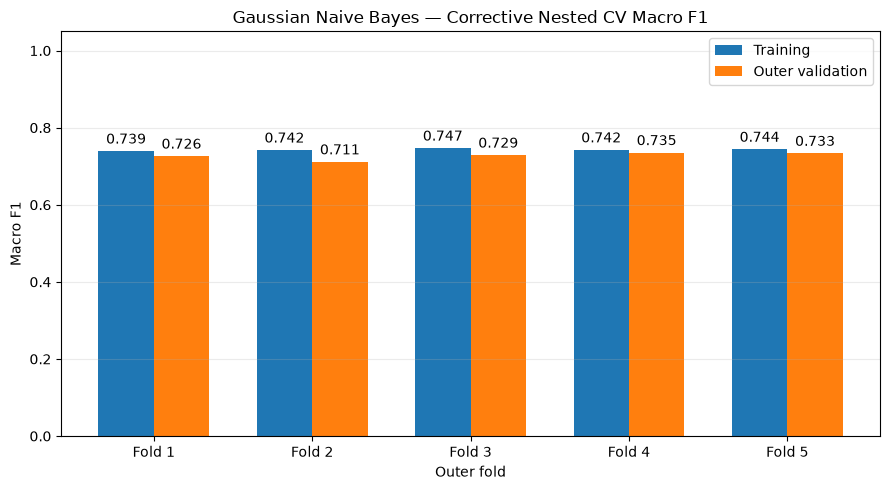

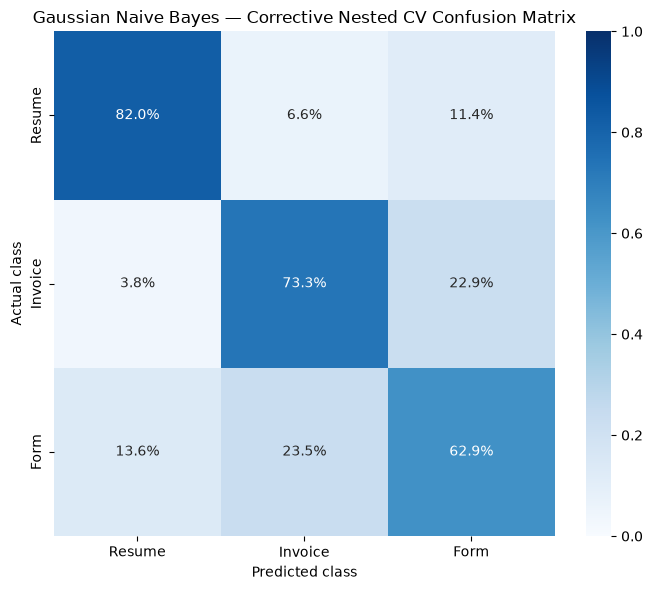


FINAL DEVELOPMENT GAUSSIAN NB SEARCH
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Final parameters: {'classifier__var_smoothing': 0.0001}
Final inner CV macro F1: 0.72929
Final search time: 25.36 seconds

GAUSSIAN NAIVE BAYES — CORRECTIVE EXPERIMENT COMPLETED

OUTER FOLD RESULTS:


,outer_fold,selected_var_smoothing,train_macro_f1,validation_macro_f1,macro_f1_gap,validation_accuracy,search_time_seconds
0,1,1.000000e-04,0.739274,0.726195,0.013079,0.726917,20.826568
1,2,1.000000e-12,0.741963,0.711382,0.030581,0.711825,22.293937
2,3,1.000000e-12,0.747037,0.728826,0.018211,0.729836,22.416511
3,4,1.000000e-12,0.742434,0.735322,0.007112,0.737089,23.296321
4,5,1.000000e-12,0.744023,0.733408,0.010616,0.732968,23.587339



OUT-OF-FOLD METRICS:
accuracy: 0.72773
macro_precision: 0.72702
macro_recall: 0.72737
macro_f1: 0.72706
weighted_f1: 0.72748

CLASS-WISE PERFORMANCE:


,class,precision,recall,f1_score,support
0,Resume,0.827247,0.820334,0.823776,2154.0
1,Invoice,0.706178,0.733017,0.719347,2105.0
2,Form,0.647628,0.628759,0.638054,2128.0



MEAN TRAINING MACRO F1: 0.74295
MEAN OUTER VALIDATION MACRO F1: 0.72703
VALIDATION MACRO F1 STD: 0.00946
MEAN GENERALIZATION GAP: 0.01592

FINAL DEVELOPMENT PARAMETERS:
{'classifier__var_smoothing': 0.0001}

MODEL DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\naive_bayes\gaussian_nb\full_hog\corrective_nested_cv\models

RESULT DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\naive_bayes\gaussian_nb\full_hog\corrective_nested_cv\results

GRAPH DIRECTORY:
D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\naive_bayes\gaussian_nb\full_hog\corrective_nested_cv\graphs

TEST SET: NOT LOADED
STATUS: CORRECTIVE EXPERIMENT COMPLETED


In [17]:

# =====================================================================
# IDP SYSTEM — STAGE 7
# MODEL 4: GAUSSIAN NAIVE BAYES — CORRECTIVE NESTED GROUP CV
#
# Dummy baseline:
#   var_smoothing = 1e-9
#   Validation macro F1 approximately 72.70%
#   Generalization gap approximately 1.60 pp
#
# Correction:
#   Tune var_smoothing using inner group-aware CV.
#
# Outer CV: 5 folds
# Inner CV: 3 folds
# Selection metric: Macro F1
#
# Input: Full HOG (5940 dimensions)
# No scaler, no PCA.
#
# Test set: NEVER LOADED
#
# Graphs:
#   1. Training vs outer validation macro F1
#   2. Normalized OOF confusion matrix
# =====================================================================

from pathlib import Path
from datetime import datetime
import os
import json
import time
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE = Path(idp_path(r"D:\fullstackfixed\IDP_Final_Output"))

DATA_DIR = BASE / "stage7_model_ready_dataset"

ASSIGNMENT_FILE = (
    DATA_DIR / "model_ready_development_cv_assignments.csv"
)

OUTPUT_DIR = (
    BASE
    / "stage7_model_training_v2"
    / "naive_bayes"
    / "gaussian_nb"
    / "full_hog"
    / "corrective_nested_cv"
)

MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"
GRAPH_DIR = OUTPUT_DIR / "graphs"

for folder in [MODEL_DIR, RESULT_DIR, GRAPH_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

N_FEATURES = 5940
OUTER_FOLDS = 5
INNER_FOLDS = 3

RANDOM_STATE = 42

CLASS_IDS = [0, 1, 2]
CLASS_NAMES = ["Resume", "Invoice", "Form"]

# Includes the original 1e-9 baseline value.
VAR_SMOOTHING_GRID = [
    1e-12,
    1e-11,
    1e-10,
    1e-9,
    1e-8,
    1e-7,
    1e-6,
    1e-5,
    1e-4
]

PARAM_GRID = {
    "classifier__var_smoothing": VAR_SMOOTHING_GRID
}

print("=" * 75)
print("GAUSSIAN NAIVE BAYES — CORRECTIVE NESTED GROUP CV")
print("=" * 75)

print("Smoothing candidates:", VAR_SMOOTHING_GRID)
print("Inner fits per outer fold:", len(VAR_SMOOTHING_GRID) * INNER_FOLDS)


# =====================================================================
# 2. LOAD AND VERIFY DEVELOPMENT ASSIGNMENTS
# =====================================================================

if not ASSIGNMENT_FILE.is_file():
    raise FileNotFoundError(ASSIGNMENT_FILE)

data = pd.read_csv(
    ASSIGNMENT_FILE,
    low_memory=False
)

required_columns = [
    "image_id",
    "file_path",
    "class_name",
    "label",
    "split",
    "duplicate_group_id",
    "cv_fold"
]

missing = [
    c for c in required_columns
    if c not in data.columns
]

if missing:
    raise ValueError(
        f"Missing assignment columns: {missing}"
    )

if len(data) != 6387:
    raise ValueError(
        f"Expected 6387 development records; got {len(data)}."
    )

def normalize_path(path):
    return os.path.normcase(
        os.path.normpath(str(path).strip())
    )

data["_key"] = data["file_path"].map(normalize_path)

if data["_key"].duplicated().any():
    raise ValueError("Duplicate document paths detected.")

data["label"] = data["label"].astype(int)
data["cv_fold"] = data["cv_fold"].astype(int)

if not data["split"].isin(
    ["train", "validation"]
).all():
    raise ValueError(
        "Test documents detected in development assignments."
    )

if set(data["cv_fold"].unique()) != set(range(1, 6)):
    raise ValueError("Expected five outer folds.")

if data["duplicate_group_id"].isna().any():
    raise ValueError("Missing duplicate group IDs.")

label_map = {
    "resume": 0,
    "invoice": 1,
    "form": 2
}

expected_labels = (
    data["class_name"]
    .astype(str)
    .str.lower()
    .map(label_map)
)

if expected_labels.isna().any():
    raise ValueError("Unknown document class.")

if not np.array_equal(
    expected_labels.to_numpy(),
    data["label"].to_numpy()
):
    raise ValueError("Class/label mismatch.")

y = data["label"].to_numpy(dtype=np.int64)

groups = (
    data["duplicate_group_id"]
    .astype(str)
    .to_numpy()
)

outer_fold_ids = data["cv_fold"].to_numpy(dtype=np.int64)

print("\nDevelopment documents:", len(data))
print("\nClass distribution:")
print(data["class_name"].value_counts())


# =====================================================================
# 3. LOAD AND ALIGN HOG FEATURES
# =====================================================================

path_positions = {
    key: i
    for i, key in enumerate(data["_key"])
}

X = np.empty(
    (len(data), N_FEATURES),
    dtype=np.float32
)

filled = np.zeros(
    len(data),
    dtype=bool
)

for split in ["train", "validation"]:

    npz_path = (
        DATA_DIR / f"model_ready_hog_{split}.npz"
    )

    mapping_path = (
        DATA_DIR / f"model_ready_hog_mapping_{split}.csv"
    )

    if not npz_path.is_file():
        raise FileNotFoundError(npz_path)

    if not mapping_path.is_file():
        raise FileNotFoundError(mapping_path)

    archive = np.load(
        npz_path,
        allow_pickle=False
    )

    features = archive["features"]

    mapping = pd.read_csv(
        mapping_path,
        low_memory=False
    )

    if features.shape != (
        len(mapping),
        N_FEATURES
    ):
        raise ValueError(
            f"{split}: HOG matrix/mapping mismatch."
        )

    if not np.isfinite(features).all():
        raise ValueError(
            f"{split}: non-finite HOG values."
        )

    positions = []

    for path in mapping["file_path"]:

        key = normalize_path(path)

        if key not in path_positions:
            raise ValueError(
                f"Unknown HOG document: {path}"
            )

        position = path_positions[key]

        if data.iloc[position]["split"] != split:
            raise ValueError(
                f"{split}: incorrect HOG mapping."
            )

        positions.append(position)

    positions = np.asarray(
        positions,
        dtype=np.int64
    )

    if filled[positions].any():
        raise ValueError(
            f"{split}: duplicate HOG assignment."
        )

    X[positions] = features
    filled[positions] = True

    print(f"{split} HOG loaded:", features.shape)

    del archive, features, mapping
    gc.collect()

if not filled.all():
    raise ValueError(
        f"HOG alignment incomplete: {(~filled).sum()} rows."
    )

print("\nFinal development HOG matrix:", X.shape)


# =====================================================================
# 4. MODEL PIPELINE AND METRICS
# =====================================================================

def make_pipeline():

    # GaussianNB receives raw HOG features.
    # No scaler or PCA is fitted here.
    return Pipeline([
        (
            "classifier",
            GaussianNB()
        )
    ])


def calculate_metrics(y_true, y_pred):

    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),

        "macro_precision": float(
            precision_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),

        "macro_recall": float(
            recall_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),

        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="macro",
                zero_division=0
            )
        ),

        "weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=CLASS_IDS,
                average="weighted",
                zero_division=0
            )
        )
    }


# =====================================================================
# 5. OUTER 5-FOLD + INNER 3-FOLD TUNING
# =====================================================================

outer_results = []

oof_predictions = np.full(
    len(y),
    -1,
    dtype=np.int64
)

for outer_fold in range(1, OUTER_FOLDS + 1):

    print("\n" + "=" * 70)
    print(
        f"GAUSSIAN NB CORRECTIVE — OUTER FOLD "
        f"{outer_fold}/{OUTER_FOLDS}"
    )
    print("=" * 70)

    train_idx = np.flatnonzero(
        outer_fold_ids != outer_fold
    )

    valid_idx = np.flatnonzero(
        outer_fold_ids == outer_fold
    )

    X_train = X[train_idx]
    X_valid = X[valid_idx]

    y_train = y[train_idx]
    y_valid = y[valid_idx]

    groups_train = groups[train_idx]
    groups_valid = groups[valid_idx]

    overlap = set(groups_train).intersection(
        set(groups_valid)
    )

    if overlap:
        raise RuntimeError(
            f"Outer fold {outer_fold}: duplicate-group leakage."
        )

    inner_cv = StratifiedGroupKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE + outer_fold
    )

    search = GridSearchCV(
        estimator=make_pipeline(),
        param_grid=PARAM_GRID,
        scoring="f1_macro",
        cv=inner_cv,
        refit=True,
        n_jobs=1,
        verbose=1,
        error_score="raise"
    )

    start = time.perf_counter()

    search.fit(
        X_train,
        y_train,
        groups=groups_train
    )

    elapsed = time.perf_counter() - start

    best_model = search.best_estimator_

    train_pred = best_model.predict(
        X_train
    )

    valid_pred = best_model.predict(
        X_valid
    )

    if np.any(oof_predictions[valid_idx] != -1):
        raise RuntimeError(
            "Duplicate OOF prediction assignment."
        )

    oof_predictions[valid_idx] = valid_pred

    train_metrics = calculate_metrics(
        y_train,
        train_pred
    )

    valid_metrics = calculate_metrics(
        y_valid,
        valid_pred
    )

    result = {
        "outer_fold": outer_fold,
        "training_documents": len(train_idx),
        "validation_documents": len(valid_idx),

        "selected_var_smoothing": float(
            search.best_params_[
                "classifier__var_smoothing"
            ]
        ),

        "inner_best_macro_f1": float(
            search.best_score_
        ),

        "search_time_seconds": float(elapsed)
    }

    for metric, value in train_metrics.items():
        result[f"train_{metric}"] = value

    for metric, value in valid_metrics.items():
        result[f"validation_{metric}"] = value

    result["macro_f1_gap"] = (
        train_metrics["macro_f1"]
        - valid_metrics["macro_f1"]
    )

    result["accuracy_gap"] = (
        train_metrics["accuracy"]
        - valid_metrics["accuracy"]
    )

    outer_results.append(result)

    joblib.dump(
        best_model,
        MODEL_DIR / f"gaussian_nb_outer_fold_{outer_fold}.joblib"
    )

    print("\nSelected var_smoothing:",
          search.best_params_["classifier__var_smoothing"])

    print("Inner CV macro F1:",
          round(search.best_score_, 5))

    print("Training macro F1:",
          round(train_metrics["macro_f1"], 5))

    print("Outer validation macro F1:",
          round(valid_metrics["macro_f1"], 5))

    print("Generalization gap:",
          round(result["macro_f1_gap"], 5))

    print("Search time:",
          round(elapsed, 2), "seconds")

    del search, best_model
    del X_train, X_valid, y_train, y_valid
    gc.collect()


# =====================================================================
# 6. OUT-OF-FOLD EVALUATION
# =====================================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Incomplete OOF predictions."
    )

outer_df = pd.DataFrame(outer_results)

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

oof_cm = confusion_matrix(
    y,
    oof_predictions,
    labels=CLASS_IDS
)

oof_report = classification_report(
    y,
    oof_predictions,
    labels=CLASS_IDS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame([
    {
        "class": name,
        "precision": oof_report[name]["precision"],
        "recall": oof_report[name]["recall"],
        "f1_score": oof_report[name]["f1-score"],
        "support": oof_report[name]["support"]
    }
    for name in CLASS_NAMES
])

outer_df.to_csv(
    RESULT_DIR / "outer_fold_metrics.csv",
    index=False
)

class_metrics.to_csv(
    RESULT_DIR / "oof_class_wise_metrics.csv",
    index=False
)

pd.DataFrame(
    oof_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    RESULT_DIR / "oof_confusion_matrix.csv"
)

oof_export = data[
    [
        "image_id",
        "file_path",
        "class_name",
        "label",
        "split",
        "duplicate_group_id",
        "cv_fold"
    ]
].copy()

oof_export["predicted_label"] = oof_predictions
oof_export["correct"] = (
    y == oof_predictions
)

oof_export.to_csv(
    RESULT_DIR / "out_of_fold_predictions.csv",
    index=False
)


# =====================================================================
# 7. GRAPH 1 — TRAINING VS VALIDATION MACRO F1
# =====================================================================

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(OUTER_FOLDS)
width = 0.35

ax.bar(
    positions - width / 2,
    outer_df["train_macro_f1"],
    width,
    label="Training"
)

ax.bar(
    positions + width / 2,
    outer_df["validation_macro_f1"],
    width,
    label="Outer validation"
)

ax.set_title(
    "Gaussian Naive Bayes — Corrective Nested CV Macro F1"
)

ax.set_xlabel("Outer fold")
ax.set_ylabel("Macro F1")

ax.set_xticks(positions)
ax.set_xticklabels([
    f"Fold {i}" for i in range(1, OUTER_FOLDS + 1)
])

ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

fig.tight_layout()

fig.savefig(
    GRAPH_DIR / "01_corrective_nested_cv_macro_f1.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# =====================================================================
# 8. GRAPH 2 — NORMALIZED OOF CONFUSION MATRIX
# =====================================================================

row_totals = oof_cm.sum(
    axis=1,
    keepdims=True
)

normalized_cm = np.divide(
    oof_cm,
    row_totals,
    out=np.zeros_like(
        oof_cm,
        dtype=float
    ),
    where=row_totals != 0
)

fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    normalized_cm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax
)

ax.set_title(
    "Gaussian Naive Bayes — Corrective Nested CV Confusion Matrix"
)

ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

fig.tight_layout()

fig.savefig(
    GRAPH_DIR / "02_corrective_normalized_confusion_matrix.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# =====================================================================
# 9. FINAL DEVELOPMENT MODEL
#
# The inner CV score below selects the final development
# configuration. The outer CV score remains the performance estimate.
# =====================================================================

print("\n" + "=" * 70)
print("FINAL DEVELOPMENT GAUSSIAN NB SEARCH")
print("=" * 70)

final_inner_cv = StratifiedGroupKFold(
    n_splits=INNER_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE + 100
)

final_search = GridSearchCV(
    estimator=make_pipeline(),
    param_grid=PARAM_GRID,
    scoring="f1_macro",
    cv=final_inner_cv,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

start = time.perf_counter()

final_search.fit(
    X,
    y,
    groups=groups
)

final_search_time = time.perf_counter() - start

final_model = final_search.best_estimator_

joblib.dump(
    final_model,
    MODEL_DIR / "gaussian_nb_final_development_model.joblib"
)

print("Final parameters:", final_search.best_params_)

print("Final inner CV macro F1:",
      round(final_search.best_score_, 5))

print("Final search time:",
      round(final_search_time, 2), "seconds")


# =====================================================================
# 10. SAVE FINAL EXPERIMENT REPORT
# =====================================================================

summary = {
    "experiment": "Gaussian Naive Bayes Corrective Nested Group CV",

    "timestamp": datetime.now().isoformat(),

    "development_documents": len(data),

    "hog_dimensions": N_FEATURES,

    "preprocessing": "Raw HOG; no scaler; no PCA",

    "outer_folds": OUTER_FOLDS,

    "inner_folds": INNER_FOLDS,

    "selection_metric": "macro_f1",

    "var_smoothing_candidates": VAR_SMOOTHING_GRID,

    "outer_validation_macro_f1_mean": float(
        outer_df["validation_macro_f1"].mean()
    ),

    "outer_validation_macro_f1_std": float(
        outer_df["validation_macro_f1"].std(ddof=1)
    ),

    "outer_validation_accuracy_mean": float(
        outer_df["validation_accuracy"].mean()
    ),

    "mean_training_macro_f1": float(
        outer_df["train_macro_f1"].mean()
    ),

    "mean_macro_f1_gap": float(
        outer_df["macro_f1_gap"].mean()
    ),

    "oof_metrics": oof_metrics,

    "class_wise_metrics": class_metrics.to_dict(
        orient="records"
    ),

    "oof_confusion_matrix": oof_cm.tolist(),

    "fold_selected_parameters": (
        outer_df[
            [
                "outer_fold",
                "selected_var_smoothing",
                "inner_best_macro_f1"
            ]
        ].to_dict(orient="records")
    ),

    "final_development_parameters": final_search.best_params_,

    "final_development_inner_cv_macro_f1": float(
        final_search.best_score_
    ),

    "test_set_loaded": False,

    "test_set_used": False,

    "status": "CORRECTIVE_NESTED_CV_COMPLETED"
}

with open(
    RESULT_DIR / "gaussian_nb_corrective_nested_cv_report.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# =====================================================================
# 11. FINAL OUTPUT
# =====================================================================

print("\n" + "=" * 75)
print("GAUSSIAN NAIVE BAYES — CORRECTIVE EXPERIMENT COMPLETED")
print("=" * 75)

print("\nOUTER FOLD RESULTS:")

display(
    outer_df[
        [
            "outer_fold",
            "selected_var_smoothing",
            "train_macro_f1",
            "validation_macro_f1",
            "macro_f1_gap",
            "validation_accuracy",
            "search_time_seconds"
        ]
    ]
)

print("\nOUT-OF-FOLD METRICS:")

for key, value in oof_metrics.items():
    print(f"{key}: {value:.5f}")

print("\nCLASS-WISE PERFORMANCE:")
display(class_metrics)

print("\nMEAN TRAINING MACRO F1:",
      round(outer_df["train_macro_f1"].mean(), 5))

print("MEAN OUTER VALIDATION MACRO F1:",
      round(outer_df["validation_macro_f1"].mean(), 5))

print("VALIDATION MACRO F1 STD:",
      round(outer_df["validation_macro_f1"].std(ddof=1), 5))

print("MEAN GENERALIZATION GAP:",
      round(outer_df["macro_f1_gap"].mean(), 5))

print("\nFINAL DEVELOPMENT PARAMETERS:")
print(final_search.best_params_)

print("\nMODEL DIRECTORY:")
print(MODEL_DIR)

print("\nRESULT DIRECTORY:")
print(RESULT_DIR)

print("\nGRAPH DIRECTORY:")
print(GRAPH_DIR)

print("\nTEST SET: NOT LOADED")
print("STATUS: CORRECTIVE EXPERIMENT COMPLETED")


**MACHINE LEARNING MODEL COMPARISON**

Loading: Logistic Regression
Loading: Linear SVM
Loading: KNN
Loading: Gaussian Naive Bayes

All four experiment reports loaded successfully.

CLASSICAL MACHINE LEARNING — MODEL COMPARISON

Ranking by Out-of-Fold Accuracy:


,Rank,Model,OOF Accuracy,OOF Macro Precision,OOF Macro Recall,OOF Macro F1,OOF Weighted F1,Outer CV Mean Macro F1,Outer CV Macro F1 Std,Mean Generalization Gap
0,1,Linear SVM,81.59,81.52,81.54,81.52,81.57,81.52,0.92,7.94
1,2,Logistic Regression,81.04,81.05,80.99,81.01,81.07,81.01,0.77,9.15
2,3,Gaussian Naive Bayes,72.77,72.70,72.74,72.71,72.75,72.70,0.95,1.59
3,4,KNN,69.17,72.95,69.00,68.19,68.24,68.19,0.98,-0.46



BEST PERFORMING CLASSICAL ML MODEL
Model: Linear SVM
OOF Accuracy: 81.59%
OOF Macro F1: 81.52%
OOF Macro Precision: 81.52%
OOF Macro Recall: 81.54%
Accuracy advantage over second model: 0.55 percentage points


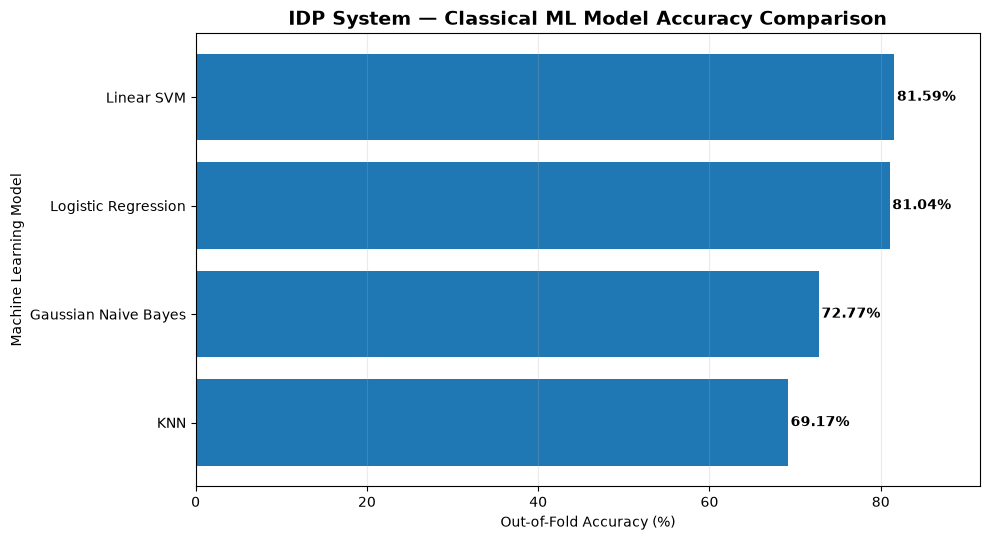


CLASSICAL ML COMPARISON COMPLETED

FINAL RANKING:
1. Linear SVM: 81.59% accuracy | 81.52% macro F1
2. Logistic Regression: 81.04% accuracy | 81.01% macro F1
3. Gaussian Naive Bayes: 72.77% accuracy | 72.71% macro F1
4. KNN: 69.17% accuracy | 68.19% macro F1

BEST MODEL: Linear SVM

SAVED OUTPUTS:
Comparison CSV: D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\classical_ml_model_comparison\results\classical_ml_model_comparison.csv
Comparison JSON: D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\classical_ml_model_comparison\results\classical_ml_model_comparison.json
Accuracy graph: D:\fullstackfixed\IDP_Final_Output\stage7_model_training_v2\classical_ml_model_comparison\graphs\classical_ml_accuracy_comparison.png

TEST SET: NOT LOADED
STATUS: COMPARISON COMPLETED


In [18]:

# =====================================================================
# IDP SYSTEM — STAGE 7
# CLASSICAL MACHINE LEARNING MODEL COMPARISON
#
# Models:
#   1. Logistic Regression
#   2. Linear SVM
#   3. K-Nearest Neighbors
#   4. Gaussian Naive Bayes
#
# Comparison:
#   - Out-of-fold accuracy
#   - Out-of-fold macro precision
#   - Out-of-fold macro recall
#   - Out-of-fold macro F1
#   - Outer CV validation macro F1
#   - Generalization gap
#
# Output:
#   1. Ranked comparison table
#   2. Accuracy bar graph
#   3. CSV and JSON comparison reports
#
# No model retraining.
# No test-set access.
# =====================================================================

from pathlib import Path
from datetime import datetime
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# =====================================================================
# 1. PATH CONFIGURATION
# =====================================================================

BASE = Path(
    idp_path(r"D:\fullstackfixed\IDP_Final_Output")
)

RESULT_FILES = {
    "Logistic Regression": (
        BASE
        / "stage7_model_training_v2"
        / "logistic_regression"
        / "nested_cv_corrected"
        / "results"
        / "logistic_regression_nested_cv_report.json"
    ),

    "Linear SVM": (
        BASE
        / "stage7_model_training_v2"
        / "svm"
        / "linear_svm"
        / "corrective_nested_cv"
        / "results"
        / "linear_svm_corrective_report.json"
    ),

    "KNN": (
        BASE
        / "stage7_model_training_v2"
        / "knn"
        / "full_hog"
        / "corrective_nested_cv"
        / "results"
        / "knn_corrective_nested_cv_report.json"
    ),

    "Gaussian Naive Bayes": (
        BASE
        / "stage7_model_training_v2"
        / "naive_bayes"
        / "gaussian_nb"
        / "full_hog"
        / "corrective_nested_cv"
        / "results"
        / "gaussian_nb_corrective_nested_cv_report.json"
    )
}

OUTPUT_DIR = (
    BASE / "stage7_model_training_v2"
    / "classical_ml_model_comparison"
)

GRAPH_DIR = OUTPUT_DIR / "graphs"
RESULT_DIR = OUTPUT_DIR / "results"

GRAPH_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# =====================================================================
# 2. LOAD AND VALIDATE EXPERIMENT REPORTS
# =====================================================================

comparison_rows = []

for model_name, report_path in RESULT_FILES.items():

    print(f"Loading: {model_name}")

    if not report_path.is_file():
        raise FileNotFoundError(
            f"Experiment report missing:\n{report_path}"
        )

    with open(
        report_path,
        "r",
        encoding="utf-8"
    ) as f:

        report = json.load(f)

    # Support the different report field names used in the
    # four previously completed experiments.
    metrics = (
        report.get("oof_metrics")
        or report.get("out_of_fold_metrics")
    )

    if not isinstance(metrics, dict):
        raise ValueError(
            f"{model_name}: OOF metrics not found."
        )

    required_metrics = [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "weighted_f1"
    ]

    missing_metrics = [
        metric
        for metric in required_metrics
        if metric not in metrics
    ]

    if missing_metrics:
        raise ValueError(
            f"{model_name}: missing metrics {missing_metrics}"
        )

    values = {
        metric: float(metrics[metric])
        for metric in required_metrics
    }

    if not all(
        np.isfinite(value)
        for value in values.values()
    ):
        raise ValueError(
            f"{model_name}: non-finite evaluation metrics."
        )

    if not all(
        0 <= value <= 1
        for value in values.values()
    ):
        raise ValueError(
            f"{model_name}: metric outside valid range."
        )

    # Read nested CV summaries.
    validation_macro_f1 = (
        report.get("outer_cv_mean_validation_macro_f1")
        or report.get("outer_validation_macro_f1_mean")
    )

    validation_macro_f1_std = (
        report.get("outer_cv_std_validation_macro_f1")
        or report.get("outer_validation_macro_f1_std")
    )

    generalization_gap = (
        report.get("outer_cv_mean_macro_f1_gap")
    )

    if generalization_gap is None:
        generalization_gap = report.get(
            "mean_macro_f1_gap"
        )

    comparison_rows.append({
        "Model": model_name,

        "OOF Accuracy": values["accuracy"],

        "OOF Macro Precision": values["macro_precision"],

        "OOF Macro Recall": values["macro_recall"],

        "OOF Macro F1": values["macro_f1"],

        "OOF Weighted F1": values["weighted_f1"],

        "Outer CV Mean Macro F1": (
            float(validation_macro_f1)
            if validation_macro_f1 is not None
            else np.nan
        ),

        "Outer CV Macro F1 Std": (
            float(validation_macro_f1_std)
            if validation_macro_f1_std is not None
            else np.nan
        ),

        "Mean Generalization Gap": (
            float(generalization_gap)
            if generalization_gap is not None
            else np.nan
        )
    })

print("\nAll four experiment reports loaded successfully.")


# =====================================================================
# 3. CREATE RANKED COMPARISON TABLE
# =====================================================================

comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_df = comparison_df.sort_values(
    by="OOF Accuracy",
    ascending=False
).reset_index(drop=True)

comparison_df.insert(
    0,
    "Rank",
    range(1, len(comparison_df) + 1)
)

# Percentage presentation.
percentage_columns = [
    "OOF Accuracy",
    "OOF Macro Precision",
    "OOF Macro Recall",
    "OOF Macro F1",
    "OOF Weighted F1",
    "Outer CV Mean Macro F1",
    "Outer CV Macro F1 Std",
    "Mean Generalization Gap"
]

comparison_display = comparison_df.copy()

for column in percentage_columns:

    comparison_display[column] = (
        comparison_display[column] * 100
    )

print("\n" + "=" * 90)
print("CLASSICAL MACHINE LEARNING — MODEL COMPARISON")
print("=" * 90)

print("\nRanking by Out-of-Fold Accuracy:")

display(
    comparison_display.round(2)
)


# =====================================================================
# 4. IDENTIFY BEST MODEL
# =====================================================================

best_model = comparison_df.iloc[0]

second_model = comparison_df.iloc[1]

accuracy_difference = (
    best_model["OOF Accuracy"]
    - second_model["OOF Accuracy"]
) * 100

print("\n" + "=" * 75)
print("BEST PERFORMING CLASSICAL ML MODEL")
print("=" * 75)

print("Model:", best_model["Model"])

print(
    "OOF Accuracy:",
    f"{best_model['OOF Accuracy'] * 100:.2f}%"
)

print(
    "OOF Macro F1:",
    f"{best_model['OOF Macro F1'] * 100:.2f}%"
)

print(
    "OOF Macro Precision:",
    f"{best_model['OOF Macro Precision'] * 100:.2f}%"
)

print(
    "OOF Macro Recall:",
    f"{best_model['OOF Macro Recall'] * 100:.2f}%"
)

print(
    "Accuracy advantage over second model:",
    f"{accuracy_difference:.2f} percentage points"
)


# =====================================================================
# 5. ACCURACY COMPARISON GRAPH
# =====================================================================

fig, ax = plt.subplots(figsize=(10, 5.5))

plot_data = comparison_df.sort_values(
    "OOF Accuracy",
    ascending=True
)

bars = ax.barh(
    plot_data["Model"],
    plot_data["OOF Accuracy"] * 100
)

for bar, value in zip(
    bars,
    plot_data["OOF Accuracy"] * 100
):

    ax.text(
        value + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "IDP System — Classical ML Model Accuracy Comparison",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Out-of-Fold Accuracy (%)")
ax.set_ylabel("Machine Learning Model")

ax.set_xlim(
    0,
    min(
        100,
        max(plot_data["OOF Accuracy"] * 100) + 10
    )
)

ax.grid(
    axis="x",
    alpha=0.25
)

fig.tight_layout()

accuracy_graph_path = (
    GRAPH_DIR / "classical_ml_accuracy_comparison.png"
)

fig.savefig(
    accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# =====================================================================
# 6. SAVE COMPARISON RESULTS
# =====================================================================

# Save raw decimal metrics.
comparison_csv = (
    RESULT_DIR / "classical_ml_model_comparison.csv"
)

comparison_df.to_csv(
    comparison_csv,
    index=False
)

comparison_json = (
    RESULT_DIR / "classical_ml_model_comparison.json"
)

summary = {
    "project": "IDP System",

    "stage": "Stage 7 — Classical ML Comparison",

    "timestamp": datetime.now().isoformat(),

    "comparison_method": (
        "Out-of-fold predictions from five-fold "
        "nested group-aware cross-validation."
    ),

    "primary_ranking_metric": "OOF Accuracy",

    "models_compared": len(comparison_df),

    "ranked_models": comparison_df.to_dict(
        orient="records"
    ),

    "best_accuracy_model": best_model["Model"],

    "best_oof_accuracy": float(
        best_model["OOF Accuracy"]
    ),

    "accuracy_advantage_over_second_model_pp": float(
        accuracy_difference
    ),

    "test_set_loaded": False,

    "test_set_used": False
}

with open(
    comparison_json,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# =====================================================================
# 7. FINAL DISPLAY
# =====================================================================

print("\n" + "=" * 90)
print("CLASSICAL ML COMPARISON COMPLETED")
print("=" * 90)

print("\nFINAL RANKING:")

for _, row in comparison_df.iterrows():

    print(
        f"{int(row['Rank'])}. {row['Model']}: "
        f"{row['OOF Accuracy'] * 100:.2f}% accuracy | "
        f"{row['OOF Macro F1'] * 100:.2f}% macro F1"
    )

print("\nBEST MODEL:", best_model["Model"])

print("\nSAVED OUTPUTS:")
print("Comparison CSV:", comparison_csv)
print("Comparison JSON:", comparison_json)
print("Accuracy graph:", accuracy_graph_path)

print("\nTEST SET: NOT LOADED")
print("STATUS: COMPARISON COMPLETED")


**Deep Learning + Fine tuning**

**Model 1: ResNet18**

RESNET18 — FULL-BACKBONE FINE-TUNING
Python: c:\Users\ashis\anaconda3\envs\idp-tf210\python.exe
TensorFlow: 2.10.1
Keras: 2.10.0
tfimm: 0.2.14
NumPy: 1.23.5

Detected GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Configuration loaded.

LOADING DEVELOPMENT DATA
Development records: 6387
Class mapping: {0: 'resume', 1: 'invoice', 2: 'form'}
Fold distribution:
cv_fold
1    1278
2    1277
3    1277
4    1278
5    1277
Name: count, dtype: int64

GROUP-AWARE CV AUDIT
Fold 1: Train=5109, Validation=1278, Group overlap=0
Fold 2: Train=5110, Validation=1277, Group overlap=0
Fold 3: Train=5110, Validation=1277, Group overlap=0
Fold 4: Train=5109, Validation=1278, Group overlap=0
Fold 5: Train=5110, Validation=1277, Group overlap=0

Canonical images verified: 6387

GPU MEMORY PREFLIGHT

Testing batch size 4...

Full backbone verified.
Trainable convolutional layers: 20
Frozen BatchNormalization layers: 20
Trainable backbone parameters: 11,166,912
Preflight PASSED.
Sele

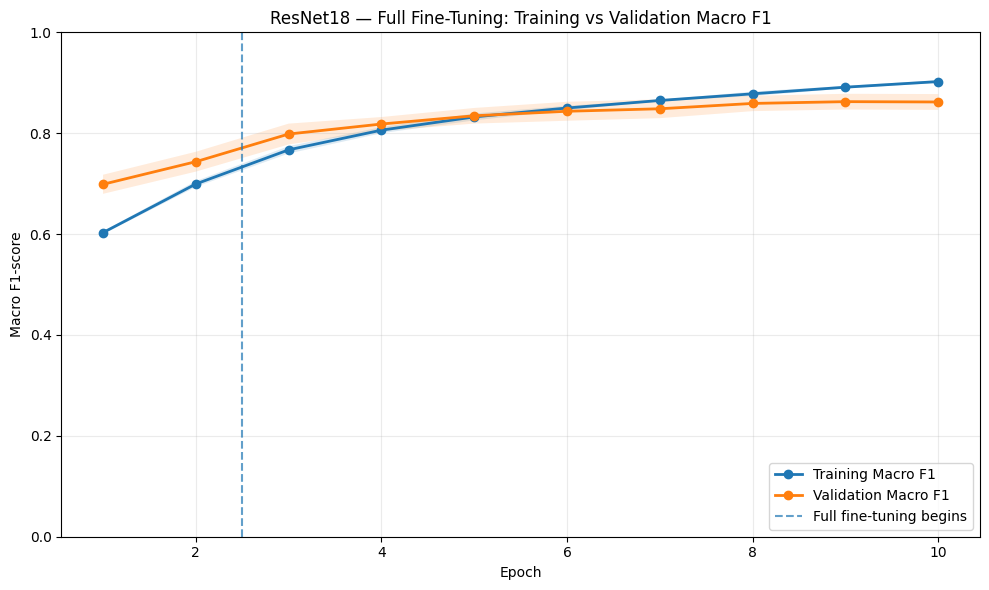

Saved: D:\fullstackfixed\IDP_Final_Output\stage8_deep_learning\resnet18_full_finetuning\graphs\resnet18_full_finetuning_training_validation_macro_f1.png


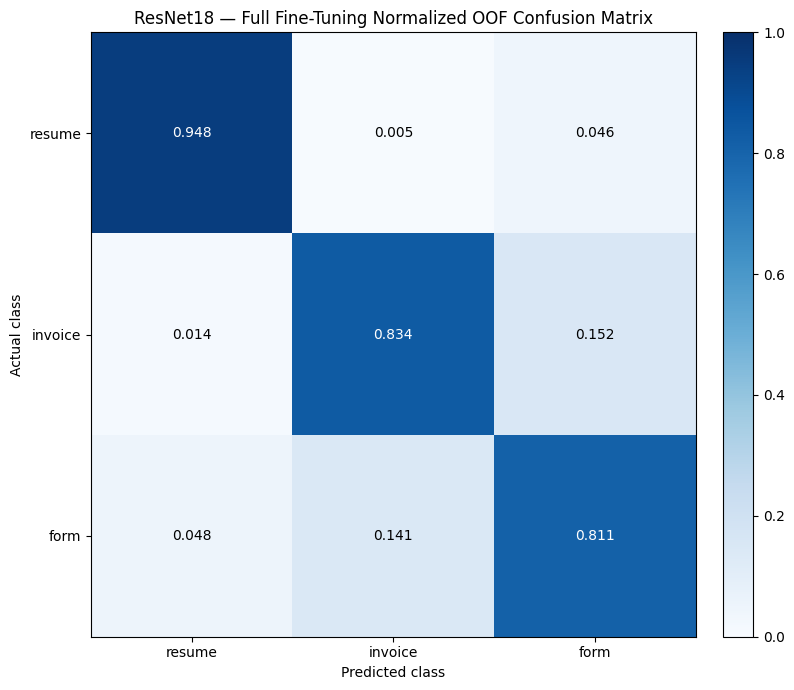

Saved: D:\fullstackfixed\IDP_Final_Output\stage8_deep_learning\resnet18_full_finetuning\graphs\resnet18_full_finetuning_normalized_oof_confusion_matrix.png

FROZEN BASELINE VS FULL FINE-TUNED RESNET18
         Metric  Frozen baseline  Full fine-tuned  Change_pp
       accuracy           0.7661           0.8650     9.8951
macro_precision           0.7618           0.8645    10.2713
   macro_recall           0.7655           0.8646     9.9117
       macro_f1           0.7617           0.8645    10.2847
    weighted_f1           0.7621           0.8649    10.2805

SAVING RESULTS

RESNET18 FULL-BACKBONE FINE-TUNING COMPLETED

FINAL OOF METRICS
accuracy                 : 0.8650 (86.50%)
macro_precision          : 0.8645 (86.45%)
macro_recall             : 0.8646 (86.46%)
macro_f1                 : 0.8645 (86.45%)
weighted_f1              : 0.8649 (86.49%)

FIT DIAGNOSTICS
Mean best train Macro F1: 0.8985
Mean best validation Macro F1: 0.8644
Mean generalization gap: +0.0341

CHECKPOINTS: D:

In [10]:
# RESNET18 — FULL-BACKBONE FINE-TUNING

import os
import sys
import gc
import json
import warnings

from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tfimm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore", category=UserWarning)

print("=" * 75)
print("RESNET18 — FULL-BACKBONE FINE-TUNING")
print("=" * 75)

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)
print("tfimm:", version("tfimm"))
print("NumPy:", np.__version__)

if tf.__version__ != "2.10.1":
    raise RuntimeError("Incorrect TensorFlow version.")

CUDA_BIN = Path(sys.prefix) / "Library" / "bin"

if not CUDA_BIN.is_dir():
    raise FileNotFoundError(CUDA_BIN)

CUDA_DLL_HANDLE = os.add_dll_directory(str(CUDA_BIN))

os.environ["PATH"] = (
    str(CUDA_BIN) + os.pathsep + os.environ.get("PATH", "")
)

GPUS = tf.config.list_physical_devices("GPU")

print("\nDetected GPUs:", GPUS)

if not GPUS:
    raise RuntimeError("RTX 3050 not detected.")

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass


# CONFIGURATION

DATA_DIR = Path(
    idp_path(r"D:\fullstackfixed\IDP_Final_Output\stage7_model_ready_dataset")
)

MODEL_DIR = Path(
    idp_path(r"D:\fullstackfixed\pretrained_models\tfimm_resnet18\model")
)

BASELINE_DIR = Path(
    idp_path('D:\\fullstackfixed\\IDP_Final_Output\\stage8_deep_learning\\resnet18_frozen_baseline')
)

OUTPUT_DIR = Path(
    idp_path('D:\\fullstackfixed\\IDP_Final_Output\\stage8_deep_learning\\resnet18_full_finetuning')
)

GRAPH_DIR = OUTPUT_DIR / "graphs"
RESULT_DIR = OUTPUT_DIR / "results"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

for folder in [GRAPH_DIR, RESULT_DIR, CHECKPOINT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224

WARMUP_EPOCHS = 2
FINETUNE_EPOCHS = 8

WARMUP_LR = 1e-3
FINETUNE_LR = 1e-5

DROPOUT_RATE = 0.30
L2_STRENGTH = 1e-4

EARLY_STOP_PATIENCE = 3
LR_REDUCTION_PATIENCE = 2

FOLDS = [1, 2, 3, 4, 5]
LABELS = [0, 1, 2]
CLASS_NAMES = ["resume", "invoice", "form"]

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("\nConfiguration loaded.")


# LOAD DEVELOPMENT DATA

print("\n" + "=" * 75)
print("LOADING DEVELOPMENT DATA")
print("=" * 75)

TRAIN_CSV = DATA_DIR / "model_ready_train.csv"
VALIDATION_CSV = DATA_DIR / "model_ready_validation.csv"
CV_CSV = DATA_DIR / "model_ready_development_cv_assignments.csv"

for path in [
    TRAIN_CSV,
    VALIDATION_CSV,
    CV_CSV,
    MODEL_DIR / "saved_model.pb"
]:
    if not path.is_file():
        raise FileNotFoundError(path)

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VALIDATION_CSV)
cv_df = pd.read_csv(CV_CSV)

dev_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

if len(dev_df) != 6387 or len(cv_df) != 6387:
    raise ValueError("Unexpected development dataset size.")

print("Development records:", len(dev_df))

required_manifest = [
    "image_id",
    "canonical_path",
    "class_name",
    "label",
    "duplicate_group_id",
    "split",
    "file_path"
]

required_cv = [
    "image_id",
    "label",
    "split",
    "duplicate_group_id",
    "cv_fold",
    "file_path"
]

for col in required_manifest:
    if col not in dev_df.columns:
        raise KeyError(f"Missing manifest column: {col}")

for col in required_cv:
    if col not in cv_df.columns:
        raise KeyError(f"Missing CV column: {col}")

if dev_df["image_id"].duplicated().any():
    raise ValueError("Duplicate development image IDs.")

if cv_df["image_id"].duplicated().any():
    raise ValueError("Duplicate CV image IDs.")

dev_df = dev_df.merge(
    cv_df[required_cv],
    on="image_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_cv"),
    indicator=True
)

if not (dev_df["_merge"] == "both").all():
    raise ValueError("Missing CV assignments.")

for left, right in [
    ("label", "label_cv"),
    ("split", "split_cv"),
    ("duplicate_group_id", "duplicate_group_id_cv"),
    ("file_path", "file_path_cv")
]:
    if not np.array_equal(
        dev_df[left].astype(str).to_numpy(),
        dev_df[right].astype(str).to_numpy()
    ):
        raise ValueError(f"Manifest/CV mismatch: {left}")

dev_df.drop(
    columns=[
        "_merge",
        "label_cv",
        "split_cv",
        "duplicate_group_id_cv",
        "file_path_cv"
    ],
    inplace=True
)

dev_df["label"] = dev_df["label"].astype(int)
dev_df["cv_fold"] = dev_df["cv_fold"].astype(int)

expected_mapping = {
    0: "resume",
    1: "invoice",
    2: "form"
}

label_mapping = (
    dev_df[["label", "class_name"]]
    .drop_duplicates()
    .sort_values("label")
    .set_index("label")["class_name"]
    .to_dict()
)

if label_mapping != expected_mapping:
    raise ValueError(f"Incorrect class mapping: {label_mapping}")

if set(dev_df["cv_fold"].unique()) != set(FOLDS):
    raise ValueError("Incorrect CV folds.")

print("Class mapping:", label_mapping)
print("Fold distribution:")
print(dev_df["cv_fold"].value_counts().sort_index())


# GROUP-LEAKAGE AUDIT

print("\n" + "=" * 75)
print("GROUP-AWARE CV AUDIT")
print("=" * 75)

for fold in FOLDS:

    fold_train = dev_df[dev_df["cv_fold"] != fold]
    fold_val = dev_df[dev_df["cv_fold"] == fold]

    overlap = (
        set(fold_train["duplicate_group_id"])
        &
        set(fold_val["duplicate_group_id"])
    )

    if overlap:
        raise RuntimeError(
            f"Duplicate-group leakage in fold {fold}."
        )

    print(
        f"Fold {fold}: "
        f"Train={len(fold_train)}, "
        f"Validation={len(fold_val)}, "
        f"Group overlap=0"
    )


# IMAGE VALIDATION

canonical_paths = dev_df["canonical_path"].astype(str).tolist()

if dev_df["canonical_path"].isna().any():
    raise ValueError("Missing canonical image paths.")

missing_images = [
    p for p in canonical_paths
    if not Path(p).is_file()
]

if missing_images:
    raise FileNotFoundError(
        f"Missing {len(missing_images)} images. "
        f"Examples: {missing_images[:5]}"
    )

print("\nCanonical images verified:", len(canonical_paths))


# IMAGE PREPROCESSING

preprocess = tfimm.create_preprocessing(
    "resnet18",
    dtype="float32"
)


def load_document(path, label):

    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_png(
        image_bytes,
        channels=1
    )

    image = tf.image.grayscale_to_rgb(image)

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE],
        method="bilinear",
        antialias=True
    )

    image = tf.cast(image, tf.float32)
    image = preprocess(image)

    image.set_shape(
        [IMAGE_SIZE, IMAGE_SIZE, 3]
    )

    return image, tf.cast(label, tf.int32)


def make_dataset(frame, training, fold, batch_size):

    paths = frame["canonical_path"].astype(str).to_numpy()
    labels = frame["label"].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(frame),
            seed=RANDOM_SEED + fold,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_document,
        num_parallel_calls=2,
        deterministic=True
    )

    dataset = dataset.batch(
        batch_size,
        drop_remainder=False
    )

    return dataset.prefetch(1)


# MACRO F1 METRIC

class MacroF1Metric(tf.keras.metrics.Metric):

    def __init__(self, num_classes=3, name="macro_f1", **kwargs):

        super().__init__(name=name, **kwargs)

        self.num_classes = num_classes

        self.confusion = self.add_weight(
            name="confusion",
            shape=(num_classes, num_classes),
            initializer="zeros",
            dtype=tf.float32
        )

    def update_state(self, y_true, y_pred, sample_weight=None):

        y_true = tf.cast(
            tf.reshape(y_true, [-1]),
            tf.int32
        )

        y_pred = tf.argmax(
            y_pred,
            axis=-1,
            output_type=tf.int32
        )

        weights = None

        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(sample_weight, [-1]),
                tf.float32
            )

        batch_cm = tf.math.confusion_matrix(
            y_true,
            y_pred,
            num_classes=self.num_classes,
            weights=weights,
            dtype=tf.float32
        )

        self.confusion.assign_add(batch_cm)

    def result(self):

        tp = tf.linalg.diag_part(self.confusion)
        predicted = tf.reduce_sum(self.confusion, axis=0)
        actual = tf.reduce_sum(self.confusion, axis=1)

        precision = tf.math.divide_no_nan(tp, predicted)
        recall = tf.math.divide_no_nan(tp, actual)

        f1 = tf.math.divide_no_nan(
            2.0 * precision * recall,
            precision + recall
        )

        return tf.reduce_mean(f1)

    def reset_state(self):
        self.confusion.assign(tf.zeros_like(self.confusion))

    def reset_states(self):
        self.reset_state()


# MODEL CONSTRUCTION

def build_model():

    backbone = tfimm.create_model(
        "resnet18",
        model_path=str(MODEL_DIR),
        nb_classes=0
    )

    backbone.trainable = False

    image_input = tf.keras.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        name="document_image"
    )

    feature_output = backbone(
        image_input,
        training=False
    )

    if feature_output.shape.rank == 4:
        feature_output = tf.keras.layers.GlobalAveragePooling2D(
            name="global_average_pooling"
        )(feature_output)

    if feature_output.shape.rank != 2:
        raise ValueError(
            f"Unexpected feature shape: {feature_output.shape}"
        )

    x = tf.keras.layers.Dropout(
        DROPOUT_RATE,
        name="classifier_dropout"
    )(feature_output)

    logits = tf.keras.layers.Dense(
        3,
        activation=None,
        kernel_regularizer=tf.keras.regularizers.l2(
            L2_STRENGTH
        ),
        dtype="float32",
        name="document_classifier"
    )(x)

    model = tf.keras.Model(
        inputs=image_input,
        outputs=logits,
        name="resnet18_full_finetuning"
    )

    return model, backbone


# FULL-BACKBONE UNFREEZING

def unfreeze_full_backbone(backbone):

    backbone.trainable = True

    for layer in backbone.layers:
        layer.trainable = True

    bn_layers = [
        layer
        for layer in backbone.submodules
        if isinstance(
            layer,
            tf.keras.layers.BatchNormalization
        )
    ]

    for layer in bn_layers:
        layer.trainable = False

    conv_layers = [
        layer
        for layer in backbone.submodules
        if isinstance(
            layer,
            tf.keras.layers.Conv2D
        )
    ]

    frozen_conv_layers = [
        layer.name
        for layer in conv_layers
        if not layer.trainable
    ]

    if frozen_conv_layers:
        raise RuntimeError(
            f"Unexpected frozen convolutional layers: "
            f"{frozen_conv_layers}"
        )

    if not backbone.trainable_variables:
        raise RuntimeError("No trainable backbone variables.")

    trainable_parameters = sum(
        int(tf.keras.backend.count_params(v))
        for v in backbone.trainable_variables
    )

    print("\nFull backbone verified.")
    print("Trainable convolutional layers:", len(conv_layers))
    print("Frozen BatchNormalization layers:", len(bn_layers))
    print("Trainable backbone parameters:", f"{trainable_parameters:,}")

    return trainable_parameters


def compile_model(model, learning_rate):

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            ),
            MacroF1Metric(
                num_classes=3,
                name="macro_f1"
            )
        ]
    )


# BEST MACRO F1 CHECKPOINT

class BestMacroF1Checkpoint(tf.keras.callbacks.Callback):

    def __init__(
        self,
        initial_best_score=-1.0,
        initial_weights=None,
        initial_epoch=0,
        initial_train_f1=0.0,
        patience=3,
        min_delta=0.0001,
        epoch_offset=0
    ):

        super().__init__()

        self.best_score = float(initial_best_score)

        self.best_weights = (
            [np.array(w, copy=True) for w in initial_weights]
            if initial_weights is not None
            else None
        )

        self.best_epoch = int(initial_epoch)
        self.best_train_f1 = float(initial_train_f1)

        self.patience = patience
        self.min_delta = min_delta
        self.epoch_offset = epoch_offset
        self.wait = 0

    def on_epoch_end(self, epoch, logs=None):

        logs = logs or {}
        score = logs.get("val_macro_f1")

        if score is None or not np.isfinite(score):
            raise RuntimeError("Missing or invalid validation Macro F1.")

        score = float(score)

        if score > self.best_score + self.min_delta:

            self.best_score = score

            self.best_weights = [
                np.array(w, copy=True)
                for w in self.model.get_weights()
            ]

            self.best_epoch = self.epoch_offset + epoch + 1

            self.best_train_f1 = float(
                logs.get("macro_f1", 0.0)
            )

            self.wait = 0

            print(
                f"\nBest validation Macro F1: {score:.4f}"
            )

        else:

            self.wait += 1

            if self.wait >= self.patience:
                print("\nEarly stopping triggered.")
                self.model.stop_training = True

    def on_train_end(self, logs=None):

        if self.best_weights is None:
            raise RuntimeError("No best checkpoint available.")

        self.model.set_weights(self.best_weights)


# GPU MEMORY PREFLIGHT

def test_training_memory(batch_size):

    tf.keras.backend.clear_session()
    gc.collect()

    model, backbone = build_model()

    unfreeze_full_backbone(backbone)

    compile_model(model, FINETUNE_LR)

    dummy_x = tf.random.uniform(
        (batch_size, IMAGE_SIZE, IMAGE_SIZE, 3),
        minval=-1.0,
        maxval=1.0,
        dtype=tf.float32
    )

    dummy_y = tf.constant(
        [0] * batch_size,
        dtype=tf.int32
    )

    result = model.train_on_batch(
        dummy_x,
        dummy_y
    )

    if not np.isfinite(np.asarray(result)).all():
        raise RuntimeError("Invalid GPU preflight result.")

    del model, backbone, dummy_x, dummy_y

    tf.keras.backend.clear_session()
    gc.collect()


print("\n" + "=" * 75)
print("GPU MEMORY PREFLIGHT")
print("=" * 75)

BATCH_SIZE = None

for candidate_batch in [4, 2, 1]:

    try:

        print(f"\nTesting batch size {candidate_batch}...")

        test_training_memory(candidate_batch)

        BATCH_SIZE = candidate_batch

        print("Preflight PASSED.")
        print("Selected batch size:", BATCH_SIZE)

        break

    except tf.errors.ResourceExhaustedError:

        print(
            f"Insufficient GPU memory at batch size {candidate_batch}."
        )

        tf.keras.backend.clear_session()
        gc.collect()

if BATCH_SIZE is None:
    raise RuntimeError(
        "Full-backbone GPU training could not fit even at batch size 1."
    )


# FIVE-FOLD TRAINING

fold_ids = dev_df["cv_fold"].to_numpy(dtype=np.int64)
labels_all = dev_df["label"].to_numpy(dtype=np.int64)

oof_probabilities = np.full(
    (len(dev_df), 3),
    np.nan,
    dtype=np.float32
)

oof_covered = np.zeros(
    len(dev_df),
    dtype=bool
)

all_train_curves = []
all_val_curves = []
fold_results = []

print("\n" + "=" * 75)
print("STARTING FIVE-FOLD FULL-BACKBONE TRAINING")
print("=" * 75)

for fold in FOLDS:

    print("\n" + "=" * 75)
    print(f"FOLD {fold}/{len(FOLDS)}")
    print("=" * 75)

    tf.keras.backend.clear_session()
    gc.collect()

    tf.random.set_seed(RANDOM_SEED + fold)
    np.random.seed(RANDOM_SEED + fold)

    train_idx = np.where(fold_ids != fold)[0]
    val_idx = np.where(fold_ids == fold)[0]

    train_frame = dev_df.iloc[train_idx].copy()
    val_frame = dev_df.iloc[val_idx].copy()

    if len(train_idx) == 0 or len(val_idx) == 0:
        raise RuntimeError(f"Empty fold: {fold}")

    train_ds = make_dataset(
        train_frame,
        True,
        fold,
        BATCH_SIZE
    )

    val_ds = make_dataset(
        val_frame,
        False,
        fold,
        BATCH_SIZE
    )

    val_images_ds = val_ds.map(
        lambda image, label: image,
        num_parallel_calls=1
    )

    model, backbone = build_model()

    print("Total parameters:", f"{model.count_params():,}")
    print("Selected batch size:", BATCH_SIZE)

    # PHASE 1: FROZEN HEAD WARM-UP

    print("\nPhase 1: Classifier head warm-up")

    compile_model(model, WARMUP_LR)

    warmup_callback = BestMacroF1Checkpoint(
        patience=WARMUP_EPOCHS + 1
    )

    warmup_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=WARMUP_EPOCHS,
        callbacks=[
            warmup_callback,
            tf.keras.callbacks.TerminateOnNaN()
        ],
        verbose=2
    )

    warmup_train_curve = list(
        warmup_history.history["macro_f1"]
    )

    warmup_val_curve = list(
        warmup_history.history["val_macro_f1"]
    )

    warmup_best_score = warmup_callback.best_score
    warmup_best_weights = warmup_callback.best_weights
    warmup_best_epoch = warmup_callback.best_epoch
    warmup_best_train_f1 = warmup_callback.best_train_f1

    print(
        "Best warm-up validation Macro F1:",
        f"{warmup_best_score:.4f}"
    )

    # PHASE 2: FULL-BACKBONE FINE-TUNING

    print("\nPhase 2: Full-backbone fine-tuning")

    trainable_parameters = unfreeze_full_backbone(backbone)

    compile_model(model, FINETUNE_LR)

    finetune_callback = BestMacroF1Checkpoint(
        initial_best_score=warmup_best_score,
        initial_weights=warmup_best_weights,
        initial_epoch=warmup_best_epoch,
        initial_train_f1=warmup_best_train_f1,
        patience=EARLY_STOP_PATIENCE,
        min_delta=0.0001,
        epoch_offset=WARMUP_EPOCHS
    )

    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_macro_f1",
        mode="max",
        factor=0.5,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )

    finetune_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FINETUNE_EPOCHS,
        callbacks=[
            reduce_lr,
            finetune_callback,
            tf.keras.callbacks.TerminateOnNaN()
        ],
        verbose=2
    )

    fine_train_curve = list(
        finetune_history.history["macro_f1"]
    )

    fine_val_curve = list(
        finetune_history.history["val_macro_f1"]
    )

    train_curve = warmup_train_curve + fine_train_curve
    val_curve = warmup_val_curve + fine_val_curve

    all_train_curves.append(train_curve)
    all_val_curves.append(val_curve)

    best_epoch = finetune_callback.best_epoch
    best_train_f1 = finetune_callback.best_train_f1
    best_val_f1 = finetune_callback.best_score

    print("\nBest model weights restored.")
    print("Best epoch:", best_epoch)
    print("Training Macro F1:", f"{best_train_f1:.4f}")
    print("Validation Macro F1:", f"{best_val_f1:.4f}")
    print(
        "Generalization gap:",
        f"{best_train_f1 - best_val_f1:+.4f}"
    )

    # OOF PREDICTIONS

    fold_logits = model.predict(
        val_images_ds,
        verbose=0
    )

    fold_probabilities = tf.nn.softmax(
        fold_logits,
        axis=-1
    ).numpy()

    if not np.isfinite(fold_probabilities).all():
        raise RuntimeError(f"Invalid predictions in fold {fold}.")

    if oof_covered[val_idx].any():
        raise RuntimeError(f"Duplicate OOF assignment in fold {fold}.")

    oof_probabilities[val_idx] = fold_probabilities
    oof_covered[val_idx] = True

    fold_checkpoint = (
        CHECKPOINT_DIR /
        f"resnet18_full_finetuned_fold_{fold}_best.weights.h5"
    )

    model.save_weights(str(fold_checkpoint))

    fold_results.append(
        {
            "fold": fold,
            "train_records": len(train_idx),
            "validation_records": len(val_idx),
            "batch_size": BATCH_SIZE,
            "warmup_epochs": len(warmup_train_curve),
            "finetuning_epochs": len(fine_train_curve),
            "best_epoch": best_epoch,
            "best_train_macro_f1": best_train_f1,
            "best_validation_macro_f1": best_val_f1,
            "generalization_gap": best_train_f1 - best_val_f1,
            "trainable_backbone_parameters": trainable_parameters,
            "checkpoint": str(fold_checkpoint)
        }
    )

    print("Checkpoint saved:", fold_checkpoint)

    del model, backbone
    del train_ds, val_ds, val_images_ds
    del train_frame, val_frame

    gc.collect()
    tf.keras.backend.clear_session()


# OOF VALIDATION

print("\n" + "=" * 75)
print("OOF INTEGRITY CHECK")
print("=" * 75)

if not oof_covered.all():
    raise RuntimeError(
        f"{np.sum(~oof_covered)} OOF predictions missing."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError("Invalid OOF probabilities.")

oof_predictions = np.argmax(
    oof_probabilities,
    axis=1
)

print("Development records:", len(dev_df))
print("OOF predictions:", len(oof_predictions))
print("Missing predictions:", int(np.sum(~oof_covered)))
print("OOF integrity: PASSED")


# CLASSIFICATION METRICS

print("\n" + "=" * 75)
print("RESNET18 FULL FINE-TUNING METRICS")
print("=" * 75)

metrics = {
    "accuracy": accuracy_score(
        labels_all,
        oof_predictions
    ),

    "macro_precision": precision_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "macro_recall": recall_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "macro_f1": f1_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "weighted_f1": f1_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="weighted",
        zero_division=0
    )
}

metrics_df = pd.DataFrame(
    [
        {
            "Metric": key.replace("_", " ").title(),
            "Score": value,
            "Percentage": value * 100
        }
        for key, value in metrics.items()
    ]
)

print(metrics_df.to_string(index=False))

report = classification_report(
    labels_all,
    oof_predictions,
    labels=LABELS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nPER-CLASS CLASSIFICATION REPORT")
print(report_df.round(4).to_string())


# FIT DIAGNOSTICS

fold_results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 75)
print("FOLD-WISE DIAGNOSTICS")
print("=" * 75)

print(fold_results_df.round(4).to_string(index=False))

mean_train_f1 = fold_results_df[
    "best_train_macro_f1"
].mean()

mean_val_f1 = fold_results_df[
    "best_validation_macro_f1"
].mean()

mean_gap = fold_results_df[
    "generalization_gap"
].mean()

print("\nMean best train Macro F1:", round(mean_train_f1, 4))
print("Mean best validation Macro F1:", round(mean_val_f1, 4))
print("Mean generalization gap:", round(mean_gap, 4))


# GRAPH 1: LEARNING CURVE

max_curve_length = max(
    len(curve) for curve in all_train_curves
)

train_matrix = np.full(
    (len(FOLDS), max_curve_length),
    np.nan,
    dtype=np.float32
)

val_matrix = np.full(
    (len(FOLDS), max_curve_length),
    np.nan,
    dtype=np.float32
)

for i, (train_curve, val_curve) in enumerate(
    zip(all_train_curves, all_val_curves)
):
    train_matrix[i, :len(train_curve)] = train_curve
    val_matrix[i, :len(val_curve)] = val_curve

train_mean = np.nanmean(train_matrix, axis=0)
train_std = np.nanstd(train_matrix, axis=0)

val_mean = np.nanmean(val_matrix, axis=0)
val_std = np.nanstd(val_matrix, axis=0)

epochs_axis = np.arange(1, max_curve_length + 1)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    epochs_axis,
    train_mean,
    marker="o",
    linewidth=2,
    label="Training Macro F1"
)

ax.plot(
    epochs_axis,
    val_mean,
    marker="o",
    linewidth=2,
    label="Validation Macro F1"
)

ax.fill_between(
    epochs_axis,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

ax.fill_between(
    epochs_axis,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15
)

ax.axvline(
    WARMUP_EPOCHS + 0.5,
    linestyle="--",
    alpha=0.7,
    label="Full fine-tuning begins"
)

ax.set_title(
    "ResNet18 — Full Fine-Tuning: Training vs Validation Macro F1"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Macro F1-score")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

graph1_path = (
    GRAPH_DIR /
    "resnet18_full_finetuning_training_validation_macro_f1.png"
)

plt.savefig(
    graph1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", graph1_path)


# GRAPH 2: NORMALIZED CONFUSION MATRIX

cm = confusion_matrix(
    labels_all,
    oof_predictions,
    labels=LABELS,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    cm,
    cmap="Blues",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

ax.set(
    xticks=np.arange(3),
    yticks=np.arange(3),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="ResNet18 — Full Fine-Tuning Normalized OOF Confusion Matrix"
)

for i in range(3):
    for j in range(3):

        value = cm[i, j]

        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            color="white" if value > 0.55 else "black"
        )

plt.tight_layout()

graph2_path = (
    GRAPH_DIR /
    "resnet18_full_finetuning_normalized_oof_confusion_matrix.png"
)

plt.savefig(
    graph2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", graph2_path)


# BASELINE COMPARISON

print("\n" + "=" * 75)
print("FROZEN BASELINE VS FULL FINE-TUNED RESNET18")
print("=" * 75)

BASELINE_METRICS_FILE = (
    BASELINE_DIR /
    "results" /
    "resnet18_baseline_metrics.csv"
)

comparison_df = None

if BASELINE_METRICS_FILE.is_file():

    baseline_df = pd.read_csv(BASELINE_METRICS_FILE)

    baseline_map = {
        str(row["Metric"]).strip().lower().replace(" ", "_"):
        float(row["Score"])
        for _, row in baseline_df.iterrows()
    }

    comparison_rows = []

    for metric_name, tuned_value in metrics.items():

        baseline_value = baseline_map.get(metric_name)

        comparison_rows.append(
            {
                "Metric": metric_name,
                "Frozen baseline": baseline_value,
                "Full fine-tuned": float(tuned_value),
                "Change_pp": (
                    (float(tuned_value) - baseline_value) * 100
                    if baseline_value is not None
                    else np.nan
                )
            }
        )

    comparison_df = pd.DataFrame(comparison_rows)

    print(comparison_df.round(4).to_string(index=False))

    comparison_df.to_csv(
        RESULT_DIR / "resnet18_baseline_vs_full_finetuned.csv",
        index=False
    )

else:
    print("Baseline metrics file not found.")


# SAVE RESULTS

print("\n" + "=" * 75)
print("SAVING RESULTS")
print("=" * 75)

metrics_df.to_csv(
    RESULT_DIR / "resnet18_full_finetuned_metrics.csv",
    index=False
)

report_df.to_csv(
    RESULT_DIR / "resnet18_full_finetuned_classification_report.csv"
)

fold_results_df.to_csv(
    RESULT_DIR / "resnet18_full_finetuned_fold_diagnostics.csv",
    index=False
)

oof_output = dev_df[
    [
        "image_id",
        "canonical_path",
        "class_name",
        "label",
        "duplicate_group_id",
        "cv_fold"
    ]
].copy()

oof_output["predicted_label"] = oof_predictions

oof_output["predicted_class"] = [
    CLASS_NAMES[int(label)]
    for label in oof_predictions
]

for index, class_name in enumerate(CLASS_NAMES):
    oof_output[
        f"probability_{class_name}"
    ] = oof_probabilities[:, index]

oof_output.to_csv(
    RESULT_DIR / "resnet18_full_finetuned_oof_predictions.csv",
    index=False
)

curve_rows = []

for fold_index, (train_curve, val_curve) in enumerate(
    zip(all_train_curves, all_val_curves),
    start=1
):
    for epoch_index, (train_f1, val_f1) in enumerate(
        zip(train_curve, val_curve),
        start=1
    ):
        curve_rows.append(
            {
                "fold": fold_index,
                "epoch": epoch_index,
                "train_macro_f1": train_f1,
                "validation_macro_f1": val_f1
            }
        )

pd.DataFrame(curve_rows).to_csv(
    RESULT_DIR / "resnet18_full_finetuned_learning_curves.csv",
    index=False
)

summary = {
    "experiment": "ResNet18 Full-Backbone Fine-Tuning",
    "framework": "TensorFlow 2.10.1 / Keras 2.10",
    "backbone": "ImageNet-1K pretrained ResNet18",
    "full_backbone_trainable": True,
    "batch_normalization_frozen": True,
    "warmup_epochs": WARMUP_EPOCHS,
    "maximum_finetuning_epochs": FINETUNE_EPOCHS,
    "batch_size": BATCH_SIZE,
    "warmup_learning_rate": WARMUP_LR,
    "finetuning_learning_rate": FINETUNE_LR,
    "development_records": len(dev_df),
    "cross_validation_folds": len(FOLDS),
    "metrics": {
        key: float(value)
        for key, value in metrics.items()
    },
    "mean_best_train_macro_f1": float(mean_train_f1),
    "mean_best_validation_macro_f1": float(mean_val_f1),
    "mean_generalization_gap": float(mean_gap),
    "test_set_used": False
}

with open(
    RESULT_DIR / "resnet18_full_finetuning_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(summary, file, indent=4)


# FINAL REPORT

print("\n" + "=" * 75)
print("RESNET18 FULL-BACKBONE FINE-TUNING COMPLETED")
print("=" * 75)

print("\nFINAL OOF METRICS")

for name, value in metrics.items():
    print(
        f"{name:25s}: {value:.4f} ({value * 100:.2f}%)"
    )

print("\nFIT DIAGNOSTICS")
print("Mean best train Macro F1:", f"{mean_train_f1:.4f}")
print("Mean best validation Macro F1:", f"{mean_val_f1:.4f}")
print("Mean generalization gap:", f"{mean_gap:+.4f}")

print("\nCHECKPOINTS:", CHECKPOINT_DIR)
print("RESULTS:", RESULT_DIR)
print("GRAPHS:", GRAPH_DIR)

print("\nTEST SET: NOT USED")
print("BASELINE COMPARISON: COMPLETED" if comparison_df is not None else "BASELINE COMPARISON: UNAVAILABLE")

print("\nNEXT: REVIEW FULL FINE-TUNING RESULTS.")
print("=" * 75)

**Model 2 :MobileNetV2**

MOBILENETV2 — CORRECTIVE FULL-BACKBONE FINE-TUNING
Python: c:\Users\ashis\anaconda3\envs\idp-tf210\python.exe
TensorFlow: 2.10.1
Keras: 2.10.0
NumPy: 1.23.5

Detected GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Configuration loaded.

LOADING DEVELOPMENT DATA
Development records: 6387
Class mapping: {0: 'resume', 1: 'invoice', 2: 'form'}
Fold distribution:
cv_fold
1    1278
2    1277
3    1277
4    1278
5    1277
Name: count, dtype: int64

GROUP-AWARE CV AUDIT
Fold 1: Train=5109, Validation=1278, Group overlap=0
Fold 2: Train=5110, Validation=1277, Group overlap=0
Fold 3: Train=5110, Validation=1277, Group overlap=0
Fold 4: Train=5109, Validation=1278, Group overlap=0
Fold 5: Train=5110, Validation=1277, Group overlap=0

Canonical images verified: 6387

GPU MEMORY PREFLIGHT

Testing batch size 4...

Full backbone verified.
Trainable convolutional layers: 52
Frozen BatchNormalization layers: 52
Trainable backbone parameters: 2,189,760
Preflight PASSED.
Selec

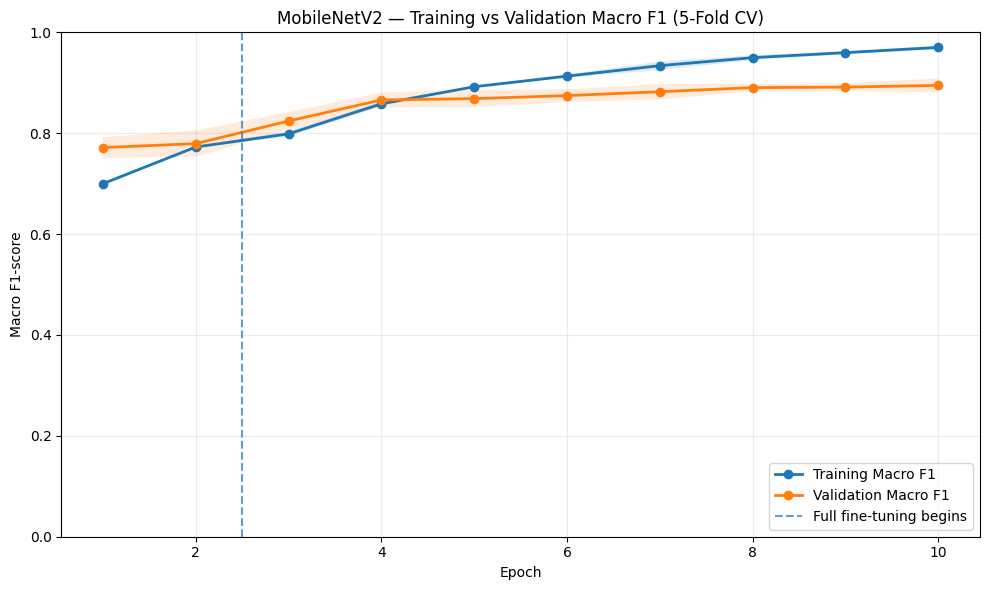

Saved: D:\fullstackfixed\IDP_Final_Output\stage8_deep_learning\mobilenetv2_full_finetuning\graphs\mobilenetv2_finetuning_training_validation_macro_f1.png


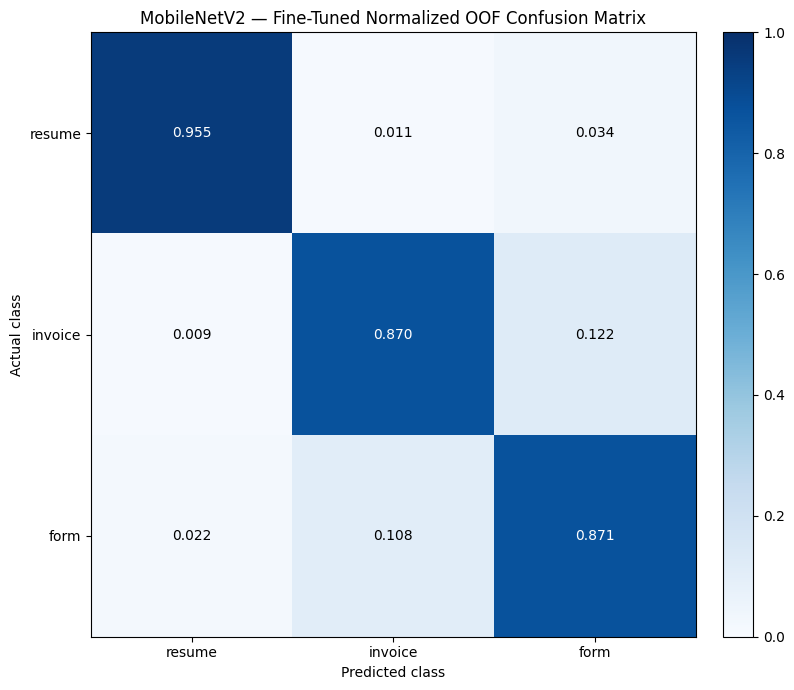

Saved: D:\fullstackfixed\IDP_Final_Output\stage8_deep_learning\mobilenetv2_full_finetuning\graphs\mobilenetv2_finetuning_normalized_oof_confusion_matrix.png

MOBILENETV2 FROZEN BASELINE VS FINE-TUNED
         Metric  Frozen baseline  Full fine-tuned  Change_pp
       accuracy           0.8162           0.8990     8.2824
macro_precision           0.8134           0.8994     8.5962
   macro_recall           0.8156           0.8987     8.3038
       macro_f1           0.8134           0.8989     8.5564
    weighted_f1           0.8139           0.8993     8.5443

SAVING MOBILENETV2 FINE-TUNING RESULTS

MOBILENETV2 FULL-BACKBONE FINE-TUNING COMPLETED

FINAL OOF METRICS
accuracy                 : 0.8990 (89.90%)
macro_precision          : 0.8994 (89.94%)
macro_recall             : 0.8987 (89.87%)
macro_f1                 : 0.8989 (89.89%)
weighted_f1              : 0.8993 (89.93%)

FIT DIAGNOSTICS
Mean best train Macro F1: 0.9637
Mean best validation Macro F1: 0.8988
Mean generalization gap

In [12]:
# MOBILENETV2 — CORRECTIVE FULL-BACKBONE FINE-TUNING

import os
import sys
import gc
import json
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.applications import MobileNetV2

warnings.filterwarnings("ignore", category=UserWarning)

print("=" * 75)
print("MOBILENETV2 — CORRECTIVE FULL-BACKBONE FINE-TUNING")
print("=" * 75)

# ENVIRONMENT

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)
print("NumPy:", np.__version__)

if tf.__version__ != "2.10.1":
    raise RuntimeError("Incorrect TensorFlow version.")

CUDA_BIN = Path(sys.prefix) / "Library" / "bin"

if not CUDA_BIN.is_dir():
    raise FileNotFoundError(CUDA_BIN)

CUDA_DLL_HANDLE = os.add_dll_directory(str(CUDA_BIN))

os.environ["PATH"] = (
    str(CUDA_BIN) + os.pathsep + os.environ.get("PATH", "")
)

GPUS = tf.config.list_physical_devices("GPU")

print("\nDetected GPUs:", GPUS)

if not GPUS:
    raise RuntimeError("RTX 3050 not detected.")

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass


# CONFIGURATION

DATA_DIR = Path(
    idp_path(r"D:\fullstackfixed\IDP_Final_Output\stage7_model_ready_dataset")
)

BASELINE_DIR = Path(
    idp_path('D:\\fullstackfixed\\IDP_Final_Output\\stage8_deep_learning\\mobilenetv2_frozen_baseline')
)

OUTPUT_DIR = Path(
    idp_path('D:\\fullstackfixed\\IDP_Final_Output\\stage8_deep_learning\\mobilenetv2_full_finetuning')
)

GRAPH_DIR = OUTPUT_DIR / "graphs"
RESULT_DIR = OUTPUT_DIR / "results"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

for folder in [GRAPH_DIR, RESULT_DIR, CHECKPOINT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224

WARMUP_EPOCHS = 2
FINETUNE_EPOCHS = 8

WARMUP_LR = 1e-3
FINETUNE_LR = 1e-5

DROPOUT_RATE = 0.30
L2_STRENGTH = 1e-4

EARLY_STOP_PATIENCE = 3
LR_REDUCTION_PATIENCE = 2

FOLDS = [1, 2, 3, 4, 5]
LABELS = [0, 1, 2]
CLASS_NAMES = ["resume", "invoice", "form"]

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("\nConfiguration loaded.")


# DEVELOPMENT DATA

print("\n" + "=" * 75)
print("LOADING DEVELOPMENT DATA")
print("=" * 75)

TRAIN_CSV = DATA_DIR / "model_ready_train.csv"
VALIDATION_CSV = DATA_DIR / "model_ready_validation.csv"
CV_CSV = DATA_DIR / "model_ready_development_cv_assignments.csv"

for path in [TRAIN_CSV, VALIDATION_CSV, CV_CSV]:
    if not path.is_file():
        raise FileNotFoundError(path)

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VALIDATION_CSV)
cv_df = pd.read_csv(CV_CSV)

dev_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

if len(dev_df) != 6387 or len(cv_df) != 6387:
    raise ValueError("Unexpected development dataset size.")

print("Development records:", len(dev_df))

required_manifest = [
    "image_id",
    "canonical_path",
    "class_name",
    "label",
    "duplicate_group_id",
    "split",
    "file_path"
]

required_cv = [
    "image_id",
    "label",
    "split",
    "duplicate_group_id",
    "cv_fold",
    "file_path"
]

for col in required_manifest:
    if col not in dev_df.columns:
        raise KeyError(f"Missing manifest column: {col}")

for col in required_cv:
    if col not in cv_df.columns:
        raise KeyError(f"Missing CV column: {col}")

if dev_df["image_id"].duplicated().any():
    raise ValueError("Duplicate development image IDs.")

if cv_df["image_id"].duplicated().any():
    raise ValueError("Duplicate CV image IDs.")

dev_df = dev_df.merge(
    cv_df[required_cv],
    on="image_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_cv"),
    indicator=True
)

if not (dev_df["_merge"] == "both").all():
    raise ValueError("Missing CV assignments.")

for left, right in [
    ("label", "label_cv"),
    ("split", "split_cv"),
    ("duplicate_group_id", "duplicate_group_id_cv"),
    ("file_path", "file_path_cv")
]:
    if not np.array_equal(
        dev_df[left].astype(str).to_numpy(),
        dev_df[right].astype(str).to_numpy()
    ):
        raise ValueError(f"Manifest/CV mismatch: {left}")

dev_df.drop(
    columns=[
        "_merge",
        "label_cv",
        "split_cv",
        "duplicate_group_id_cv",
        "file_path_cv"
    ],
    inplace=True
)

dev_df["label"] = dev_df["label"].astype(int)
dev_df["cv_fold"] = dev_df["cv_fold"].astype(int)

expected_mapping = {
    0: "resume",
    1: "invoice",
    2: "form"
}

label_mapping = (
    dev_df[["label", "class_name"]]
    .drop_duplicates()
    .sort_values("label")
    .set_index("label")["class_name"]
    .to_dict()
)

if label_mapping != expected_mapping:
    raise ValueError(f"Incorrect class mapping: {label_mapping}")

if set(dev_df["cv_fold"].unique()) != set(FOLDS):
    raise ValueError("Incorrect CV folds.")

print("Class mapping:", label_mapping)
print("Fold distribution:")
print(dev_df["cv_fold"].value_counts().sort_index())


# GROUP-LEAKAGE AUDIT

print("\n" + "=" * 75)
print("GROUP-AWARE CV AUDIT")
print("=" * 75)

for fold in FOLDS:

    fold_train = dev_df[dev_df["cv_fold"] != fold]
    fold_val = dev_df[dev_df["cv_fold"] == fold]

    overlap = (
        set(fold_train["duplicate_group_id"])
        &
        set(fold_val["duplicate_group_id"])
    )

    if overlap:
        raise RuntimeError(
            f"Duplicate-group leakage in fold {fold}."
        )

    print(
        f"Fold {fold}: "
        f"Train={len(fold_train)}, "
        f"Validation={len(fold_val)}, "
        f"Group overlap=0"
    )


# CANONICAL IMAGE VALIDATION

canonical_paths = dev_df["canonical_path"].astype(str).tolist()

if dev_df["canonical_path"].isna().any():
    raise ValueError("Missing canonical image paths.")

missing_images = [
    path for path in canonical_paths
    if not Path(path).is_file()
]

if missing_images:
    raise FileNotFoundError(
        f"{len(missing_images)} images missing. "
        f"Examples: {missing_images[:5]}"
    )

print("\nCanonical images verified:", len(canonical_paths))


# PREPROCESSING

def load_document(path, label):

    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_png(
        image_bytes,
        channels=1
    )

    image = tf.image.grayscale_to_rgb(image)

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE],
        method="bilinear",
        antialias=True
    )

    image = tf.cast(image, tf.float32)

    image = tf.keras.applications.mobilenet_v2.preprocess_input(
        image
    )

    image.set_shape([IMAGE_SIZE, IMAGE_SIZE, 3])

    return image, tf.cast(label, tf.int32)


def make_dataset(frame, training, fold, batch_size):

    paths = frame["canonical_path"].astype(str).to_numpy()
    labels = frame["label"].to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame),
            seed=RANDOM_SEED + fold,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_document,
        num_parallel_calls=2,
        deterministic=True
    )

    ds = ds.batch(
        batch_size,
        drop_remainder=False
    )

    return ds.prefetch(1)


# MACRO F1 METRIC

class MacroF1Metric(tf.keras.metrics.Metric):

    def __init__(self, num_classes=3, name="macro_f1", **kwargs):

        super().__init__(name=name, **kwargs)

        self.num_classes = num_classes

        self.confusion = self.add_weight(
            name="confusion",
            shape=(num_classes, num_classes),
            initializer="zeros",
            dtype=tf.float32
        )

    def update_state(self, y_true, y_pred, sample_weight=None):

        y_true = tf.cast(
            tf.reshape(y_true, [-1]),
            tf.int32
        )

        y_pred = tf.argmax(
            y_pred,
            axis=-1,
            output_type=tf.int32
        )

        weights = None

        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(sample_weight, [-1]),
                tf.float32
            )

        batch_cm = tf.math.confusion_matrix(
            y_true,
            y_pred,
            num_classes=self.num_classes,
            weights=weights,
            dtype=tf.float32
        )

        self.confusion.assign_add(batch_cm)

    def result(self):

        tp = tf.linalg.diag_part(self.confusion)

        predicted = tf.reduce_sum(
            self.confusion,
            axis=0
        )

        actual = tf.reduce_sum(
            self.confusion,
            axis=1
        )

        precision = tf.math.divide_no_nan(
            tp,
            predicted
        )

        recall = tf.math.divide_no_nan(
            tp,
            actual
        )

        f1 = tf.math.divide_no_nan(
            2.0 * precision * recall,
            precision + recall
        )

        return tf.reduce_mean(f1)

    def reset_state(self):
        self.confusion.assign(
            tf.zeros_like(self.confusion)
        )

    def reset_states(self):
        self.reset_state()


# MODEL CONSTRUCTION

def build_model():

    backbone = MobileNetV2(
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        alpha=1.0,
        include_top=False,
        weights="imagenet",
        pooling="avg"
    )

    backbone.trainable = False

    image_input = tf.keras.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        name="document_image"
    )

    features = backbone(
        image_input,
        training=False
    )

    x = tf.keras.layers.Dropout(
        DROPOUT_RATE,
        name="classifier_dropout"
    )(features)

    logits = tf.keras.layers.Dense(
        3,
        activation=None,
        kernel_regularizer=tf.keras.regularizers.l2(
            L2_STRENGTH
        ),
        dtype="float32",
        name="document_classifier"
    )(x)

    model = tf.keras.Model(
        inputs=image_input,
        outputs=logits,
        name="mobilenetv2_document_finetuning"
    )

    return model, backbone


# FULL-BACKBONE UNFREEZING

def unfreeze_full_backbone(backbone):

    backbone.trainable = True

    for layer in backbone.layers:
        layer.trainable = True

    bn_layers = [
        layer
        for layer in backbone.layers
        if isinstance(
            layer,
            tf.keras.layers.BatchNormalization
        )
    ]

    for layer in bn_layers:
        layer.trainable = False

    conv_types = (
        tf.keras.layers.Conv2D,
        tf.keras.layers.DepthwiseConv2D
    )

    conv_layers = [
        layer
        for layer in backbone.layers
        if isinstance(layer, conv_types)
    ]

    frozen_conv_layers = [
        layer.name
        for layer in conv_layers
        if not layer.trainable
    ]

    if frozen_conv_layers:
        raise RuntimeError(
            f"Some convolutional layers remain frozen: "
            f"{frozen_conv_layers}"
        )

    if any(layer.trainable for layer in bn_layers):
        raise RuntimeError(
            "Batch Normalization was not frozen."
        )

    trainable_parameters = sum(
        int(tf.keras.backend.count_params(v))
        for v in backbone.trainable_variables
    )

    print("\nFull backbone verified.")
    print("Trainable convolutional layers:", len(conv_layers))
    print("Frozen BatchNormalization layers:", len(bn_layers))
    print(
        "Trainable backbone parameters:",
        f"{trainable_parameters:,}"
    )

    if trainable_parameters <= 0:
        raise RuntimeError("No trainable backbone parameters.")

    return trainable_parameters


def compile_model(model, learning_rate):

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            ),
            MacroF1Metric(
                num_classes=3,
                name="macro_f1"
            )
        ]
    )


# BEST MACRO F1 CHECKPOINT

class BestMacroF1Checkpoint(tf.keras.callbacks.Callback):

    def __init__(
        self,
        initial_best_score=-1.0,
        initial_weights=None,
        initial_epoch=0,
        initial_train_f1=0.0,
        patience=3,
        min_delta=0.0001,
        epoch_offset=0
    ):

        super().__init__()

        self.best_score = float(initial_best_score)

        self.best_weights = (
            [np.array(w, copy=True) for w in initial_weights]
            if initial_weights is not None
            else None
        )

        self.best_epoch = int(initial_epoch)
        self.best_train_f1 = float(initial_train_f1)

        self.patience = patience
        self.min_delta = min_delta
        self.epoch_offset = epoch_offset
        self.wait = 0

    def on_epoch_end(self, epoch, logs=None):

        logs = logs or {}

        score = logs.get("val_macro_f1")

        if score is None or not np.isfinite(score):
            raise RuntimeError(
                "Missing or invalid validation Macro F1."
            )

        score = float(score)

        if score > self.best_score + self.min_delta:

            self.best_score = score

            self.best_weights = [
                np.array(w, copy=True)
                for w in self.model.get_weights()
            ]

            self.best_epoch = self.epoch_offset + epoch + 1

            self.best_train_f1 = float(
                logs.get("macro_f1", 0.0)
            )

            self.wait = 0

            print(
                f"\nBest validation Macro F1: {score:.4f}"
            )

        else:

            self.wait += 1

            if self.wait >= self.patience:
                print("\nEarly stopping triggered.")
                self.model.stop_training = True

    def on_train_end(self, logs=None):

        if self.best_weights is None:
            raise RuntimeError("No best checkpoint available.")

        self.model.set_weights(self.best_weights)


# GPU MEMORY PREFLIGHT

def test_training_memory(batch_size):

    tf.keras.backend.clear_session()
    gc.collect()

    model, backbone = build_model()

    unfreeze_full_backbone(backbone)

    compile_model(
        model,
        FINETUNE_LR
    )

    dummy_x = tf.random.uniform(
        (batch_size, IMAGE_SIZE, IMAGE_SIZE, 3),
        minval=-1.0,
        maxval=1.0,
        dtype=tf.float32
    )

    dummy_y = tf.constant(
        [0] * batch_size,
        dtype=tf.int32
    )

    result = model.train_on_batch(
        dummy_x,
        dummy_y
    )

    if not np.isfinite(np.asarray(result)).all():
        raise RuntimeError("Invalid GPU preflight result.")

    del model, backbone, dummy_x, dummy_y

    tf.keras.backend.clear_session()
    gc.collect()


print("\n" + "=" * 75)
print("GPU MEMORY PREFLIGHT")
print("=" * 75)

BATCH_SIZE = None

for candidate_batch in [4, 2, 1]:

    try:

        print(f"\nTesting batch size {candidate_batch}...")

        test_training_memory(candidate_batch)

        BATCH_SIZE = candidate_batch

        print("Preflight PASSED.")
        print("Selected batch size:", BATCH_SIZE)

        break

    except tf.errors.ResourceExhaustedError:

        print(
            f"Insufficient GPU memory at batch size {candidate_batch}."
        )

        tf.keras.backend.clear_session()
        gc.collect()

if BATCH_SIZE is None:
    raise RuntimeError(
        "Full-backbone training could not fit even at batch size 1."
    )


# FIVE-FOLD FINE-TUNING

fold_ids = dev_df["cv_fold"].to_numpy(dtype=np.int64)
labels_all = dev_df["label"].to_numpy(dtype=np.int64)

oof_probabilities = np.full(
    (len(dev_df), 3),
    np.nan,
    dtype=np.float32
)

oof_covered = np.zeros(
    len(dev_df),
    dtype=bool
)

all_train_curves = []
all_val_curves = []
fold_results = []

print("\n" + "=" * 75)
print("STARTING FIVE-FOLD MOBILENETV2 FINE-TUNING")
print("=" * 75)

for fold in FOLDS:

    print("\n" + "=" * 75)
    print(f"FOLD {fold}/{len(FOLDS)}")
    print("=" * 75)

    tf.keras.backend.clear_session()
    gc.collect()

    tf.random.set_seed(RANDOM_SEED + fold)
    np.random.seed(RANDOM_SEED + fold)

    train_idx = np.where(fold_ids != fold)[0]
    val_idx = np.where(fold_ids == fold)[0]

    train_frame = dev_df.iloc[train_idx].copy()
    val_frame = dev_df.iloc[val_idx].copy()

    if len(train_idx) == 0 or len(val_idx) == 0:
        raise RuntimeError(f"Empty fold: {fold}")

    train_ds = make_dataset(
        train_frame,
        True,
        fold,
        BATCH_SIZE
    )

    val_ds = make_dataset(
        val_frame,
        False,
        fold,
        BATCH_SIZE
    )

    val_images_ds = val_ds.map(
        lambda image, label: image,
        num_parallel_calls=1
    )

    model, backbone = build_model()

    print("Total model parameters:", f"{model.count_params():,}")
    print("Selected batch size:", BATCH_SIZE)

    # PHASE 1: CLASSIFIER HEAD WARM-UP

    print("\nPhase 1: Frozen-backbone head warm-up")

    compile_model(
        model,
        WARMUP_LR
    )

    warmup_callback = BestMacroF1Checkpoint(
        patience=WARMUP_EPOCHS + 1
    )

    warmup_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=WARMUP_EPOCHS,
        callbacks=[
            warmup_callback,
            tf.keras.callbacks.TerminateOnNaN()
        ],
        verbose=2
    )

    warmup_train_curve = list(
        warmup_history.history["macro_f1"]
    )

    warmup_val_curve = list(
        warmup_history.history["val_macro_f1"]
    )

    warmup_best_score = warmup_callback.best_score
    warmup_best_weights = warmup_callback.best_weights
    warmup_best_epoch = warmup_callback.best_epoch
    warmup_best_train_f1 = warmup_callback.best_train_f1

    print(
        "Best warm-up validation Macro F1:",
        f"{warmup_best_score:.4f}"
    )

    # PHASE 2: FULL-BACKBONE FINE-TUNING

    print("\nPhase 2: Full-backbone fine-tuning")

    trainable_parameters = unfreeze_full_backbone(
        backbone
    )

    compile_model(
        model,
        FINETUNE_LR
    )

    finetune_callback = BestMacroF1Checkpoint(
        initial_best_score=warmup_best_score,
        initial_weights=warmup_best_weights,
        initial_epoch=warmup_best_epoch,
        initial_train_f1=warmup_best_train_f1,
        patience=EARLY_STOP_PATIENCE,
        min_delta=0.0001,
        epoch_offset=WARMUP_EPOCHS
    )

    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_macro_f1",
        mode="max",
        factor=0.5,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )

    finetune_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FINETUNE_EPOCHS,
        callbacks=[
            reduce_lr,
            finetune_callback,
            tf.keras.callbacks.TerminateOnNaN()
        ],
        verbose=2
    )

    fine_train_curve = list(
        finetune_history.history["macro_f1"]
    )

    fine_val_curve = list(
        finetune_history.history["val_macro_f1"]
    )

    train_curve = warmup_train_curve + fine_train_curve
    val_curve = warmup_val_curve + fine_val_curve

    all_train_curves.append(train_curve)
    all_val_curves.append(val_curve)

    best_epoch = finetune_callback.best_epoch
    best_train_f1 = finetune_callback.best_train_f1
    best_val_f1 = finetune_callback.best_score

    print("\nBest checkpoint restored.")
    print("Best epoch:", best_epoch)
    print("Training Macro F1:", f"{best_train_f1:.4f}")
    print("Validation Macro F1:", f"{best_val_f1:.4f}")
    print(
        "Generalization gap:",
        f"{best_train_f1 - best_val_f1:+.4f}"
    )

    # OOF PREDICTIONS

    fold_logits = model.predict(
        val_images_ds,
        verbose=0
    )

    fold_probabilities = tf.nn.softmax(
        fold_logits,
        axis=-1
    ).numpy()

    if not np.isfinite(fold_probabilities).all():
        raise RuntimeError(f"Invalid probabilities in fold {fold}.")

    if oof_covered[val_idx].any():
        raise RuntimeError(f"Duplicate OOF predictions in fold {fold}.")

    oof_probabilities[val_idx] = fold_probabilities
    oof_covered[val_idx] = True

    fold_checkpoint = (
        CHECKPOINT_DIR /
        f"mobilenetv2_full_finetuned_fold_{fold}_best.weights.h5"
    )

    model.save_weights(str(fold_checkpoint))

    fold_results.append(
        {
            "fold": fold,
            "train_records": len(train_idx),
            "validation_records": len(val_idx),
            "batch_size": BATCH_SIZE,
            "warmup_epochs": len(warmup_train_curve),
            "finetuning_epochs": len(fine_train_curve),
            "best_epoch": best_epoch,
            "best_train_macro_f1": best_train_f1,
            "best_validation_macro_f1": best_val_f1,
            "generalization_gap": best_train_f1 - best_val_f1,
            "trainable_backbone_parameters": trainable_parameters,
            "checkpoint": str(fold_checkpoint)
        }
    )

    print("Checkpoint saved:", fold_checkpoint)

    del model, backbone
    del train_ds, val_ds, val_images_ds
    del train_frame, val_frame

    gc.collect()
    tf.keras.backend.clear_session()


# OOF INTEGRITY

print("\n" + "=" * 75)
print("OOF INTEGRITY CHECK")
print("=" * 75)

if not oof_covered.all():
    raise RuntimeError(
        f"{np.sum(~oof_covered)} OOF predictions are missing."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError("Invalid OOF probabilities.")

oof_predictions = np.argmax(
    oof_probabilities,
    axis=1
)

print("Development records:", len(dev_df))
print("OOF predictions:", len(oof_predictions))
print("Missing predictions:", int(np.sum(~oof_covered)))
print("OOF integrity: PASSED")


# CLASSIFICATION METRICS

print("\n" + "=" * 75)
print("MOBILENETV2 FINE-TUNED CLASSIFICATION METRICS")
print("=" * 75)

metrics = {
    "accuracy": accuracy_score(
        labels_all,
        oof_predictions
    ),

    "macro_precision": precision_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "macro_recall": recall_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "macro_f1": f1_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "weighted_f1": f1_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="weighted",
        zero_division=0
    )
}

metrics_df = pd.DataFrame(
    [
        {
            "Metric": key.replace("_", " ").title(),
            "Score": value,
            "Percentage": value * 100
        }
        for key, value in metrics.items()
    ]
)

print(metrics_df.to_string(index=False))

report = classification_report(
    labels_all,
    oof_predictions,
    labels=LABELS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nPER-CLASS CLASSIFICATION REPORT")
print(report_df.round(4).to_string())


# FOLD DIAGNOSTICS

fold_results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 75)
print("FOLD-WISE DIAGNOSTICS")
print("=" * 75)

print(fold_results_df.round(4).to_string(index=False))

mean_train_f1 = fold_results_df[
    "best_train_macro_f1"
].mean()

mean_val_f1 = fold_results_df[
    "best_validation_macro_f1"
].mean()

mean_gap = fold_results_df[
    "generalization_gap"
].mean()

print("\nMean best training Macro F1:", round(mean_train_f1, 4))
print("Mean best validation Macro F1:", round(mean_val_f1, 4))
print("Mean generalization gap:", round(mean_gap, 4))


# GRAPH 1: LEARNING CURVE

max_curve_length = max(
    len(curve) for curve in all_train_curves
)

train_matrix = np.full(
    (len(FOLDS), max_curve_length),
    np.nan,
    dtype=np.float32
)

val_matrix = np.full(
    (len(FOLDS), max_curve_length),
    np.nan,
    dtype=np.float32
)

for i, (train_curve, val_curve) in enumerate(
    zip(all_train_curves, all_val_curves)
):
    train_matrix[i, :len(train_curve)] = train_curve
    val_matrix[i, :len(val_curve)] = val_curve

train_mean = np.nanmean(train_matrix, axis=0)
train_std = np.nanstd(train_matrix, axis=0)

val_mean = np.nanmean(val_matrix, axis=0)
val_std = np.nanstd(val_matrix, axis=0)

epochs_axis = np.arange(1, max_curve_length + 1)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    epochs_axis,
    train_mean,
    marker="o",
    linewidth=2,
    label="Training Macro F1"
)

ax.plot(
    epochs_axis,
    val_mean,
    marker="o",
    linewidth=2,
    label="Validation Macro F1"
)

ax.fill_between(
    epochs_axis,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

ax.fill_between(
    epochs_axis,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15
)

ax.axvline(
    WARMUP_EPOCHS + 0.5,
    linestyle="--",
    alpha=0.7,
    label="Full fine-tuning begins"
)

ax.set_title(
    "MobileNetV2 — Training vs Validation Macro F1 (5-Fold CV)"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Macro F1-score")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

graph1_path = (
    GRAPH_DIR /
    "mobilenetv2_finetuning_training_validation_macro_f1.png"
)

plt.savefig(
    graph1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", graph1_path)


# GRAPH 2: NORMALIZED CONFUSION MATRIX

cm = confusion_matrix(
    labels_all,
    oof_predictions,
    labels=LABELS,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    cm,
    cmap="Blues",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

ax.set(
    xticks=np.arange(3),
    yticks=np.arange(3),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="MobileNetV2 — Fine-Tuned Normalized OOF Confusion Matrix"
)

for i in range(3):
    for j in range(3):

        value = cm[i, j]

        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            color="white" if value > 0.55 else "black"
        )

plt.tight_layout()

graph2_path = (
    GRAPH_DIR /
    "mobilenetv2_finetuning_normalized_oof_confusion_matrix.png"
)

plt.savefig(
    graph2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", graph2_path)


# BASELINE COMPARISON

print("\n" + "=" * 75)
print("MOBILENETV2 FROZEN BASELINE VS FINE-TUNED")
print("=" * 75)

BASELINE_METRICS_FILE = (
    BASELINE_DIR /
    "results" /
    "mobilenetv2_baseline_metrics.csv"
)

comparison_df = None

if BASELINE_METRICS_FILE.is_file():

    baseline_df = pd.read_csv(BASELINE_METRICS_FILE)

    baseline_map = {
        str(row["Metric"]).strip().lower().replace(" ", "_"):
        float(row["Score"])
        for _, row in baseline_df.iterrows()
    }

    comparison_rows = []

    for metric_name, tuned_value in metrics.items():

        baseline_value = baseline_map.get(metric_name)

        comparison_rows.append(
            {
                "Metric": metric_name,
                "Frozen baseline": baseline_value,
                "Full fine-tuned": float(tuned_value),
                "Change_pp": (
                    (float(tuned_value) - baseline_value) * 100
                    if baseline_value is not None
                    else np.nan
                )
            }
        )

    comparison_df = pd.DataFrame(comparison_rows)

    print(comparison_df.round(4).to_string(index=False))

    comparison_df.to_csv(
        RESULT_DIR / "mobilenetv2_baseline_vs_finetuned.csv",
        index=False
    )

else:
    print("Baseline metrics file not found.")


# SAVE RESULTS

print("\n" + "=" * 75)
print("SAVING MOBILENETV2 FINE-TUNING RESULTS")
print("=" * 75)

metrics_df.to_csv(
    RESULT_DIR / "mobilenetv2_finetuned_metrics.csv",
    index=False
)

report_df.to_csv(
    RESULT_DIR / "mobilenetv2_finetuned_classification_report.csv"
)

fold_results_df.to_csv(
    RESULT_DIR / "mobilenetv2_finetuned_fold_diagnostics.csv",
    index=False
)

oof_output = dev_df[
    [
        "image_id",
        "canonical_path",
        "class_name",
        "label",
        "duplicate_group_id",
        "cv_fold"
    ]
].copy()

oof_output["predicted_label"] = oof_predictions

oof_output["predicted_class"] = [
    CLASS_NAMES[int(label)]
    for label in oof_predictions
]

for index, class_name in enumerate(CLASS_NAMES):
    oof_output[
        f"probability_{class_name}"
    ] = oof_probabilities[:, index]

oof_output.to_csv(
    RESULT_DIR / "mobilenetv2_finetuned_oof_predictions.csv",
    index=False
)

curve_rows = []

for fold_index, (train_curve, val_curve) in enumerate(
    zip(all_train_curves, all_val_curves),
    start=1
):
    for epoch_index, (train_f1, val_f1) in enumerate(
        zip(train_curve, val_curve),
        start=1
    ):
        curve_rows.append(
            {
                "fold": fold_index,
                "epoch": epoch_index,
                "train_macro_f1": train_f1,
                "validation_macro_f1": val_f1
            }
        )

pd.DataFrame(curve_rows).to_csv(
    RESULT_DIR / "mobilenetv2_finetuned_learning_curves.csv",
    index=False
)

summary = {
    "experiment": "MobileNetV2 Full-Backbone Fine-Tuning",
    "framework": "TensorFlow 2.10.1 / Keras 2.10",
    "backbone": "ImageNet-1K pretrained MobileNetV2",
    "full_backbone_trainable": True,
    "batch_normalization_frozen": True,
    "warmup_epochs": WARMUP_EPOCHS,
    "maximum_finetuning_epochs": FINETUNE_EPOCHS,
    "batch_size": BATCH_SIZE,
    "warmup_learning_rate": WARMUP_LR,
    "finetuning_learning_rate": FINETUNE_LR,
    "development_records": len(dev_df),
    "cross_validation_folds": len(FOLDS),
    "metrics": {
        key: float(value)
        for key, value in metrics.items()
    },
    "mean_best_train_macro_f1": float(mean_train_f1),
    "mean_best_validation_macro_f1": float(mean_val_f1),
    "mean_generalization_gap": float(mean_gap),
    "test_set_used": False
}

with open(
    RESULT_DIR / "mobilenetv2_finetuning_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(summary, file, indent=4)


# FINAL REPORT

print("\n" + "=" * 75)
print("MOBILENETV2 FULL-BACKBONE FINE-TUNING COMPLETED")
print("=" * 75)

print("\nFINAL OOF METRICS")

for name, value in metrics.items():
    print(
        f"{name:25s}: {value:.4f} ({value * 100:.2f}%)"
    )

print("\nFIT DIAGNOSTICS")
print("Mean best train Macro F1:", f"{mean_train_f1:.4f}")
print("Mean best validation Macro F1:", f"{mean_val_f1:.4f}")
print("Mean generalization gap:", f"{mean_gap:+.4f}")

print("\nCHECKPOINTS:", CHECKPOINT_DIR)
print("RESULTS:", RESULT_DIR)
print("GRAPHS:", GRAPH_DIR)

print("\nTEST SET: NOT USED")
print("BASELINE COMPARISON:", comparison_df is not None)

print("\nNEXT: REVIEW MOBILENETV2 FINE-TUNING RESULTS.")
print("=" * 75)

**Model 3 :EfficientNetB0**

EFFICIENTNETB0 — FULL-BACKBONE FINE-TUNING
Python: c:\Users\ashis\anaconda3\envs\idp-tf210\python.exe
TensorFlow: 2.10.1
Keras: 2.10.0
NumPy: 1.23.5

Detected GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Configuration loaded.

LOADING DEVELOPMENT DATA
Development records: 6387
Class mapping: {0: 'resume', 1: 'invoice', 2: 'form'}
Fold distribution:
cv_fold
1    1278
2    1277
3    1277
4    1278
5    1277
Name: count, dtype: int64

GROUP-AWARE CV AUDIT
Fold 1: Train=5109, Validation=1278, Group overlap=0
Fold 2: Train=5110, Validation=1277, Group overlap=0
Fold 3: Train=5110, Validation=1277, Group overlap=0
Fold 4: Train=5109, Validation=1278, Group overlap=0
Fold 5: Train=5110, Validation=1277, Group overlap=0

Canonical images verified: 6387

GPU MEMORY PREFLIGHT

Testing batch size 4...

Full backbone verified.
Trainable convolutional layers: 81
Frozen BatchNormalization layers: 49
Trainable backbone parameters: 3,965,532
Preflight PASSED.
Selected batc

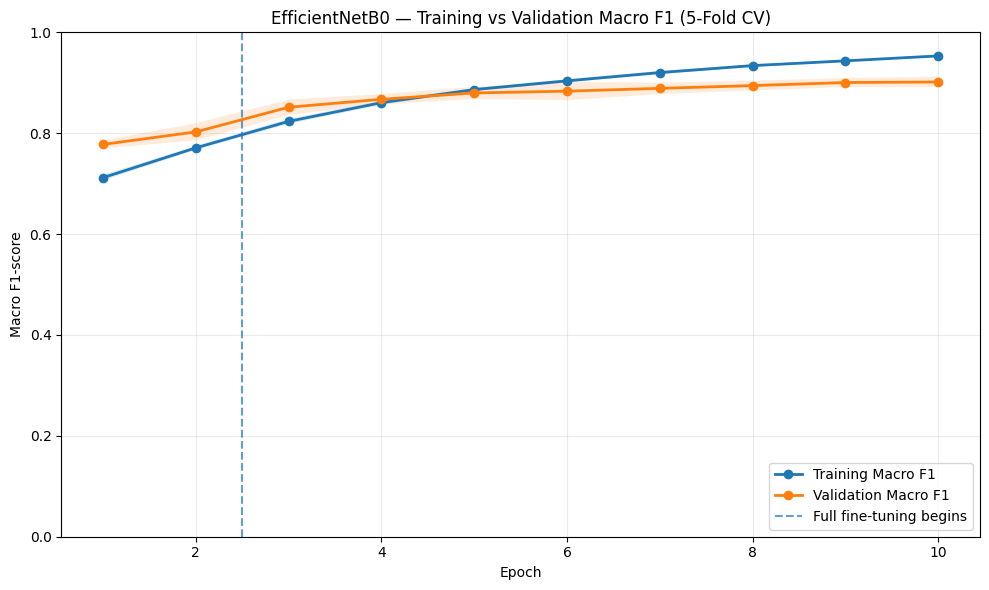

Saved: D:\fullstackfixed\IDP_Final_Output\stage8_deep_learning\efficientnetb0_full_finetuning\graphs\efficientnetb0_finetuning_training_validation_macro_f1.png


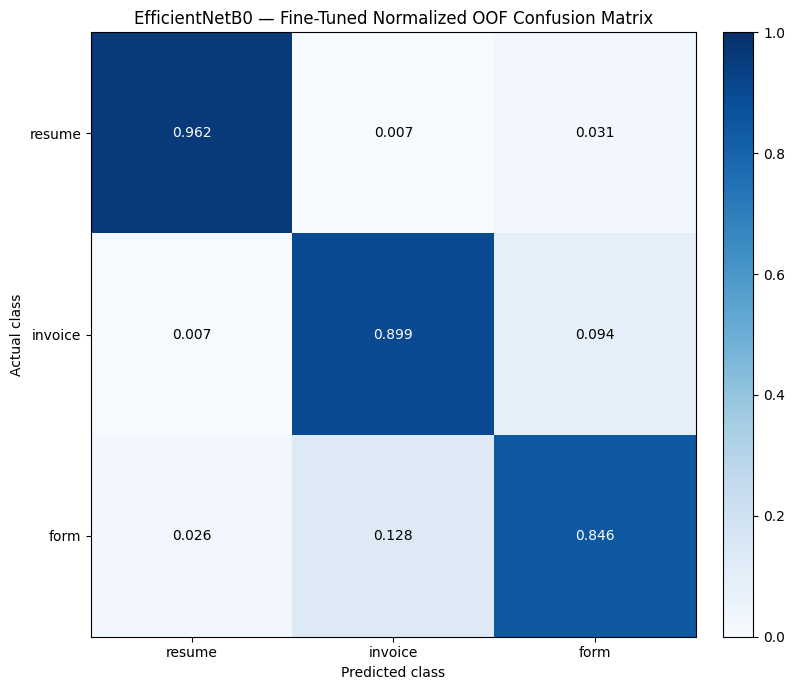

Saved: D:\fullstackfixed\IDP_Final_Output\stage8_deep_learning\efficientnetb0_full_finetuning\graphs\efficientnetb0_finetuning_normalized_oof_confusion_matrix.png

EFFICIENTNETB0 FROZEN BASELINE VS FINE-TUNED
         Metric  Frozen baseline  Full fine-tuned  Change_pp
       accuracy           0.8196           0.9026     8.2981
macro_precision           0.8173           0.9025     8.5187
   macro_recall           0.8191           0.9024     8.3294
       macro_f1           0.8179           0.9022     8.4362
    weighted_f1           0.8184           0.9026     8.4180

SAVING EFFICIENTNETB0 FINE-TUNING RESULTS

EFFICIENTNETB0 FULL-BACKBONE FINE-TUNING COMPLETED

FINAL OOF METRICS
accuracy                 : 0.9026 (90.26%)
macro_precision          : 0.9025 (90.25%)
macro_recall             : 0.9024 (90.24%)
macro_f1                 : 0.9022 (90.22%)
weighted_f1              : 0.9026 (90.26%)

FIT DIAGNOSTICS
Mean best train Macro F1: 0.9476
Mean best validation Macro F1: 0.9022
Mean gen

In [14]:
# EFFICIENTNETB0 — CORRECTIVE FULL-BACKBONE FINE-TUNING

import os
import sys
import gc
import json
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.applications import EfficientNetB0

warnings.filterwarnings("ignore", category=UserWarning)

print("=" * 75)
print("EFFICIENTNETB0 — FULL-BACKBONE FINE-TUNING")
print("=" * 75)

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)
print("NumPy:", np.__version__)

if tf.__version__ != "2.10.1":
    raise RuntimeError("Incorrect TensorFlow version.")

CUDA_BIN = Path(sys.prefix) / "Library" / "bin"

if not CUDA_BIN.is_dir():
    raise FileNotFoundError(CUDA_BIN)

CUDA_DLL_HANDLE = os.add_dll_directory(str(CUDA_BIN))

os.environ["PATH"] = (
    str(CUDA_BIN) + os.pathsep + os.environ.get("PATH", "")
)

GPUS = tf.config.list_physical_devices("GPU")

print("\nDetected GPUs:", GPUS)

if not GPUS:
    raise RuntimeError("RTX 3050 not detected.")

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass


# CONFIGURATION

DATA_DIR = Path(
    idp_path(r"D:\fullstackfixed\IDP_Final_Output\stage7_model_ready_dataset")
)

BASELINE_DIR = Path(
    idp_path('D:\\fullstackfixed\\IDP_Final_Output\\stage8_deep_learning\\efficientnetb0_frozen_baseline')
)

OUTPUT_DIR = Path(
    idp_path('D:\\fullstackfixed\\IDP_Final_Output\\stage8_deep_learning\\efficientnetb0_full_finetuning')
)

GRAPH_DIR = OUTPUT_DIR / "graphs"
RESULT_DIR = OUTPUT_DIR / "results"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

for folder in [GRAPH_DIR, RESULT_DIR, CHECKPOINT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224

WARMUP_EPOCHS = 2
FINETUNE_EPOCHS = 8

WARMUP_LR = 1e-3
FINETUNE_LR = 1e-5

DROPOUT_RATE = 0.30
L2_STRENGTH = 1e-4

EARLY_STOP_PATIENCE = 3
LR_REDUCTION_PATIENCE = 2

FOLDS = [1, 2, 3, 4, 5]
LABELS = [0, 1, 2]

CLASS_NAMES = [
    "resume",
    "invoice",
    "form"
]

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("\nConfiguration loaded.")


# LOAD DEVELOPMENT DATA

print("\n" + "=" * 75)
print("LOADING DEVELOPMENT DATA")
print("=" * 75)

TRAIN_CSV = DATA_DIR / "model_ready_train.csv"
VALIDATION_CSV = DATA_DIR / "model_ready_validation.csv"
CV_CSV = DATA_DIR / "model_ready_development_cv_assignments.csv"

for path in [TRAIN_CSV, VALIDATION_CSV, CV_CSV]:
    if not path.is_file():
        raise FileNotFoundError(path)

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VALIDATION_CSV)
cv_df = pd.read_csv(CV_CSV)

dev_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

if len(dev_df) != 6387 or len(cv_df) != 6387:
    raise ValueError("Unexpected development dataset size.")

print("Development records:", len(dev_df))

required_manifest = [
    "image_id",
    "canonical_path",
    "class_name",
    "label",
    "duplicate_group_id",
    "split",
    "file_path"
]

required_cv = [
    "image_id",
    "label",
    "split",
    "duplicate_group_id",
    "cv_fold",
    "file_path"
]

for col in required_manifest:
    if col not in dev_df.columns:
        raise KeyError(f"Missing manifest column: {col}")

for col in required_cv:
    if col not in cv_df.columns:
        raise KeyError(f"Missing CV column: {col}")

if dev_df["image_id"].duplicated().any():
    raise ValueError("Duplicate development image IDs.")

if cv_df["image_id"].duplicated().any():
    raise ValueError("Duplicate CV image IDs.")

dev_df = dev_df.merge(
    cv_df[required_cv],
    on="image_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_cv"),
    indicator=True
)

if not (dev_df["_merge"] == "both").all():
    raise ValueError("Missing CV assignments.")

for left, right in [
    ("label", "label_cv"),
    ("split", "split_cv"),
    ("duplicate_group_id", "duplicate_group_id_cv"),
    ("file_path", "file_path_cv")
]:
    if not np.array_equal(
        dev_df[left].astype(str).to_numpy(),
        dev_df[right].astype(str).to_numpy()
    ):
        raise ValueError(f"Manifest/CV mismatch: {left}")

dev_df.drop(
    columns=[
        "_merge",
        "label_cv",
        "split_cv",
        "duplicate_group_id_cv",
        "file_path_cv"
    ],
    inplace=True
)

dev_df["label"] = dev_df["label"].astype(int)
dev_df["cv_fold"] = dev_df["cv_fold"].astype(int)

expected_mapping = {
    0: "resume",
    1: "invoice",
    2: "form"
}

label_mapping = (
    dev_df[["label", "class_name"]]
    .drop_duplicates()
    .sort_values("label")
    .set_index("label")["class_name"]
    .to_dict()
)

if label_mapping != expected_mapping:
    raise ValueError(f"Incorrect class mapping: {label_mapping}")

if set(dev_df["cv_fold"].unique()) != set(FOLDS):
    raise ValueError("Incorrect CV folds.")

print("Class mapping:", label_mapping)
print("Fold distribution:")
print(dev_df["cv_fold"].value_counts().sort_index())


# GROUP-LEAKAGE AUDIT

print("\n" + "=" * 75)
print("GROUP-AWARE CV AUDIT")
print("=" * 75)

for fold in FOLDS:

    fold_train = dev_df[dev_df["cv_fold"] != fold]
    fold_val = dev_df[dev_df["cv_fold"] == fold]

    overlap = (
        set(fold_train["duplicate_group_id"])
        &
        set(fold_val["duplicate_group_id"])
    )

    if overlap:
        raise RuntimeError(
            f"Duplicate-group leakage in fold {fold}."
        )

    print(
        f"Fold {fold}: "
        f"Train={len(fold_train)}, "
        f"Validation={len(fold_val)}, "
        f"Group overlap=0"
    )


# CANONICAL IMAGE VALIDATION

canonical_paths = dev_df["canonical_path"].astype(str).tolist()

if dev_df["canonical_path"].isna().any():
    raise ValueError("Missing canonical image paths.")

missing_images = [
    path for path in canonical_paths
    if not Path(path).is_file()
]

if missing_images:
    raise FileNotFoundError(
        f"{len(missing_images)} canonical images missing. "
        f"Examples: {missing_images[:5]}"
    )

print("\nCanonical images verified:", len(canonical_paths))


# IMAGE PREPROCESSING

def load_document(path, label):

    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_png(
        image_bytes,
        channels=1
    )

    image = tf.image.grayscale_to_rgb(image)

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE],
        method="bilinear",
        antialias=True
    )

    image = tf.cast(image, tf.float32)

    image.set_shape(
        [IMAGE_SIZE, IMAGE_SIZE, 3]
    )

    return image, tf.cast(label, tf.int32)


def make_dataset(frame, training, fold, batch_size):

    paths = frame["canonical_path"].astype(str).to_numpy()
    labels = frame["label"].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(frame),
            seed=RANDOM_SEED + fold,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_document,
        num_parallel_calls=2,
        deterministic=True
    )

    dataset = dataset.batch(
        batch_size,
        drop_remainder=False
    )

    return dataset.prefetch(1)


# MACRO F1 METRIC

class MacroF1Metric(tf.keras.metrics.Metric):

    def __init__(self, num_classes=3, name="macro_f1", **kwargs):

        super().__init__(name=name, **kwargs)

        self.num_classes = num_classes

        self.confusion = self.add_weight(
            name="confusion",
            shape=(num_classes, num_classes),
            initializer="zeros",
            dtype=tf.float32
        )

    def update_state(self, y_true, y_pred, sample_weight=None):

        y_true = tf.cast(
            tf.reshape(y_true, [-1]),
            tf.int32
        )

        y_pred = tf.argmax(
            y_pred,
            axis=-1,
            output_type=tf.int32
        )

        weights = None

        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(sample_weight, [-1]),
                tf.float32
            )

        batch_cm = tf.math.confusion_matrix(
            y_true,
            y_pred,
            num_classes=self.num_classes,
            weights=weights,
            dtype=tf.float32
        )

        self.confusion.assign_add(batch_cm)

    def result(self):

        tp = tf.linalg.diag_part(self.confusion)

        predicted = tf.reduce_sum(
            self.confusion,
            axis=0
        )

        actual = tf.reduce_sum(
            self.confusion,
            axis=1
        )

        precision = tf.math.divide_no_nan(
            tp,
            predicted
        )

        recall = tf.math.divide_no_nan(
            tp,
            actual
        )

        f1 = tf.math.divide_no_nan(
            2.0 * precision * recall,
            precision + recall
        )

        return tf.reduce_mean(f1)

    def reset_state(self):
        self.confusion.assign(
            tf.zeros_like(self.confusion)
        )

    def reset_states(self):
        self.reset_state()


# BUILD MODEL

def build_model():

    backbone = EfficientNetB0(
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        include_top=False,
        weights="imagenet",
        pooling="avg"
    )

    backbone.trainable = False

    image_input = tf.keras.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        name="document_image"
    )

    features = backbone(image_input)

    x = tf.keras.layers.Dropout(
        DROPOUT_RATE,
        name="classifier_dropout"
    )(features)

    logits = tf.keras.layers.Dense(
        3,
        activation=None,
        kernel_regularizer=tf.keras.regularizers.l2(
            L2_STRENGTH
        ),
        dtype="float32",
        name="document_classifier"
    )(x)

    model = tf.keras.Model(
        inputs=image_input,
        outputs=logits,
        name="efficientnetb0_document_finetuning"
    )

    return model, backbone


# FULL-BACKBONE UNFREEZING

def unfreeze_full_backbone(backbone):

    backbone.trainable = True

    for layer in backbone.layers:
        layer.trainable = True

    bn_layers = [
        layer
        for layer in backbone.submodules
        if isinstance(
            layer,
            tf.keras.layers.BatchNormalization
        )
    ]

    for layer in bn_layers:
        layer.trainable = False

    conv_types = (
        tf.keras.layers.Conv2D,
        tf.keras.layers.DepthwiseConv2D
    )

    conv_layers = [
        layer
        for layer in backbone.submodules
        if isinstance(layer, conv_types)
    ]

    frozen_conv_layers = [
        layer.name
        for layer in conv_layers
        if not layer.trainable
    ]

    if frozen_conv_layers:
        raise RuntimeError(
            f"Convolutional layers remain frozen: {frozen_conv_layers}"
        )

    if any(layer.trainable for layer in bn_layers):
        raise RuntimeError(
            "Batch Normalization was not frozen."
        )

    trainable_parameters = sum(
        int(tf.keras.backend.count_params(v))
        for v in backbone.trainable_variables
    )

    if trainable_parameters <= 0:
        raise RuntimeError("No trainable backbone parameters.")

    print("\nFull backbone verified.")
    print("Trainable convolutional layers:", len(conv_layers))
    print("Frozen BatchNormalization layers:", len(bn_layers))
    print(
        "Trainable backbone parameters:",
        f"{trainable_parameters:,}"
    )

    return trainable_parameters


# COMPILE MODEL

def compile_model(model, learning_rate):

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            ),
            MacroF1Metric(
                num_classes=3,
                name="macro_f1"
            )
        ]
    )


# BEST MACRO F1 CHECKPOINT

class BestMacroF1Checkpoint(tf.keras.callbacks.Callback):

    def __init__(
        self,
        initial_best_score=-1.0,
        initial_weights=None,
        initial_epoch=0,
        initial_train_f1=0.0,
        patience=3,
        min_delta=0.0001,
        epoch_offset=0
    ):

        super().__init__()

        self.best_score = float(initial_best_score)

        self.best_weights = (
            [np.array(w, copy=True) for w in initial_weights]
            if initial_weights is not None
            else None
        )

        self.best_epoch = int(initial_epoch)
        self.best_train_f1 = float(initial_train_f1)

        self.patience = patience
        self.min_delta = min_delta
        self.epoch_offset = epoch_offset
        self.wait = 0

    def on_epoch_end(self, epoch, logs=None):

        logs = logs or {}

        score = logs.get("val_macro_f1")

        if score is None or not np.isfinite(score):
            raise RuntimeError(
                "Missing or invalid validation Macro F1."
            )

        score = float(score)

        if score > self.best_score + self.min_delta:

            self.best_score = score

            self.best_weights = [
                np.array(w, copy=True)
                for w in self.model.get_weights()
            ]

            self.best_epoch = self.epoch_offset + epoch + 1

            self.best_train_f1 = float(
                logs.get("macro_f1", 0.0)
            )

            self.wait = 0

            print(
                f"\nBest validation Macro F1: {score:.4f}"
            )

        else:

            self.wait += 1

            if self.wait >= self.patience:
                print("\nEarly stopping triggered.")
                self.model.stop_training = True

    def on_train_end(self, logs=None):

        if self.best_weights is None:
            raise RuntimeError("No best checkpoint available.")

        self.model.set_weights(self.best_weights)


# GPU MEMORY PREFLIGHT

def test_training_memory(batch_size):

    tf.keras.backend.clear_session()
    gc.collect()

    model, backbone = build_model()

    unfreeze_full_backbone(backbone)

    compile_model(
        model,
        FINETUNE_LR
    )

    dummy_x = tf.random.uniform(
        (batch_size, IMAGE_SIZE, IMAGE_SIZE, 3),
        minval=0,
        maxval=255,
        dtype=tf.float32
    )

    dummy_y = tf.constant(
        [0] * batch_size,
        dtype=tf.int32
    )

    result = model.train_on_batch(
        dummy_x,
        dummy_y
    )

    if not np.isfinite(np.asarray(result)).all():
        raise RuntimeError("Invalid GPU preflight result.")

    del model, backbone, dummy_x, dummy_y

    tf.keras.backend.clear_session()
    gc.collect()


print("\n" + "=" * 75)
print("GPU MEMORY PREFLIGHT")
print("=" * 75)

BATCH_SIZE = None

for candidate_batch in [4, 2, 1]:

    try:

        print(f"\nTesting batch size {candidate_batch}...")

        test_training_memory(candidate_batch)

        BATCH_SIZE = candidate_batch

        print("Preflight PASSED.")
        print("Selected batch size:", BATCH_SIZE)

        break

    except tf.errors.ResourceExhaustedError:

        print(
            f"Insufficient GPU memory at batch size {candidate_batch}."
        )

        tf.keras.backend.clear_session()
        gc.collect()

if BATCH_SIZE is None:
    raise RuntimeError(
        "Full-backbone training could not fit even at batch size 1."
    )


# FIVE-FOLD TRAINING

fold_ids = dev_df["cv_fold"].to_numpy(dtype=np.int64)
labels_all = dev_df["label"].to_numpy(dtype=np.int64)

oof_probabilities = np.full(
    (len(dev_df), 3),
    np.nan,
    dtype=np.float32
)

oof_covered = np.zeros(
    len(dev_df),
    dtype=bool
)

all_train_curves = []
all_val_curves = []
fold_results = []

print("\n" + "=" * 75)
print("STARTING FIVE-FOLD EFFICIENTNETB0 FINE-TUNING")
print("=" * 75)

for fold in FOLDS:

    print("\n" + "=" * 75)
    print(f"FOLD {fold}/{len(FOLDS)}")
    print("=" * 75)

    tf.keras.backend.clear_session()
    gc.collect()

    tf.random.set_seed(RANDOM_SEED + fold)
    np.random.seed(RANDOM_SEED + fold)

    train_idx = np.where(fold_ids != fold)[0]
    val_idx = np.where(fold_ids == fold)[0]

    train_frame = dev_df.iloc[train_idx].copy()
    val_frame = dev_df.iloc[val_idx].copy()

    if len(train_idx) == 0 or len(val_idx) == 0:
        raise RuntimeError(f"Empty fold: {fold}")

    train_ds = make_dataset(
        train_frame,
        True,
        fold,
        BATCH_SIZE
    )

    val_ds = make_dataset(
        val_frame,
        False,
        fold,
        BATCH_SIZE
    )

    val_images_ds = val_ds.map(
        lambda image, label: image,
        num_parallel_calls=1
    )

    model, backbone = build_model()

    print("Total model parameters:", f"{model.count_params():,}")
    print("Selected batch size:", BATCH_SIZE)

    # PHASE 1 — CLASSIFIER WARM-UP

    print("\nPhase 1: Frozen-backbone head warm-up")

    compile_model(
        model,
        WARMUP_LR
    )

    warmup_callback = BestMacroF1Checkpoint(
        patience=WARMUP_EPOCHS + 1
    )

    warmup_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=WARMUP_EPOCHS,
        callbacks=[
            warmup_callback,
            tf.keras.callbacks.TerminateOnNaN()
        ],
        verbose=2
    )

    warmup_train_curve = list(
        warmup_history.history["macro_f1"]
    )

    warmup_val_curve = list(
        warmup_history.history["val_macro_f1"]
    )

    warmup_best_score = warmup_callback.best_score
    warmup_best_weights = warmup_callback.best_weights
    warmup_best_epoch = warmup_callback.best_epoch
    warmup_best_train_f1 = warmup_callback.best_train_f1

    print(
        "Best warm-up validation Macro F1:",
        f"{warmup_best_score:.4f}"
    )

    # PHASE 2 — FULL-BACKBONE FINE-TUNING

    print("\nPhase 2: Full-backbone fine-tuning")

    trainable_parameters = unfreeze_full_backbone(
        backbone
    )

    compile_model(
        model,
        FINETUNE_LR
    )

    finetune_callback = BestMacroF1Checkpoint(
        initial_best_score=warmup_best_score,
        initial_weights=warmup_best_weights,
        initial_epoch=warmup_best_epoch,
        initial_train_f1=warmup_best_train_f1,
        patience=EARLY_STOP_PATIENCE,
        min_delta=0.0001,
        epoch_offset=WARMUP_EPOCHS
    )

    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_macro_f1",
        mode="max",
        factor=0.5,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )

    finetune_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FINETUNE_EPOCHS,
        callbacks=[
            reduce_lr,
            finetune_callback,
            tf.keras.callbacks.TerminateOnNaN()
        ],
        verbose=2
    )

    fine_train_curve = list(
        finetune_history.history["macro_f1"]
    )

    fine_val_curve = list(
        finetune_history.history["val_macro_f1"]
    )

    train_curve = warmup_train_curve + fine_train_curve
    val_curve = warmup_val_curve + fine_val_curve

    all_train_curves.append(train_curve)
    all_val_curves.append(val_curve)

    best_epoch = finetune_callback.best_epoch
    best_train_f1 = finetune_callback.best_train_f1
    best_val_f1 = finetune_callback.best_score

    print("\nBest checkpoint restored.")
    print("Best epoch:", best_epoch)
    print("Training Macro F1:", f"{best_train_f1:.4f}")
    print("Validation Macro F1:", f"{best_val_f1:.4f}")
    print(
        "Generalization gap:",
        f"{best_train_f1 - best_val_f1:+.4f}"
    )

    # OOF PREDICTIONS

    fold_logits = model.predict(
        val_images_ds,
        verbose=0
    )

    fold_probabilities = tf.nn.softmax(
        fold_logits,
        axis=-1
    ).numpy()

    if not np.isfinite(fold_probabilities).all():
        raise RuntimeError(
            f"Invalid probabilities in fold {fold}."
        )

    if oof_covered[val_idx].any():
        raise RuntimeError(
            f"Duplicate OOF assignment in fold {fold}."
        )

    oof_probabilities[val_idx] = fold_probabilities
    oof_covered[val_idx] = True

    fold_checkpoint = (
        CHECKPOINT_DIR /
        f"efficientnetb0_full_finetuned_fold_{fold}_best.weights.h5"
    )

    model.save_weights(str(fold_checkpoint))

    fold_results.append(
        {
            "fold": fold,
            "train_records": len(train_idx),
            "validation_records": len(val_idx),
            "batch_size": BATCH_SIZE,
            "warmup_epochs": len(warmup_train_curve),
            "finetuning_epochs": len(fine_train_curve),
            "best_epoch": best_epoch,
            "best_train_macro_f1": best_train_f1,
            "best_validation_macro_f1": best_val_f1,
            "generalization_gap": best_train_f1 - best_val_f1,
            "trainable_backbone_parameters": trainable_parameters,
            "checkpoint": str(fold_checkpoint)
        }
    )

    print("Checkpoint saved:", fold_checkpoint)

    del model, backbone
    del train_ds, val_ds, val_images_ds
    del train_frame, val_frame

    gc.collect()
    tf.keras.backend.clear_session()


# OOF INTEGRITY

print("\n" + "=" * 75)
print("OOF INTEGRITY CHECK")
print("=" * 75)

if not oof_covered.all():
    raise RuntimeError(
        f"{np.sum(~oof_covered)} OOF predictions are missing."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError("Invalid OOF probabilities.")

oof_predictions = np.argmax(
    oof_probabilities,
    axis=1
)

print("Development records:", len(dev_df))
print("OOF predictions:", len(oof_predictions))
print("Missing predictions:", int(np.sum(~oof_covered)))
print("OOF integrity: PASSED")


# CLASSIFICATION METRICS

print("\n" + "=" * 75)
print("EFFICIENTNETB0 FINE-TUNED CLASSIFICATION METRICS")
print("=" * 75)

metrics = {
    "accuracy": accuracy_score(
        labels_all,
        oof_predictions
    ),

    "macro_precision": precision_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "macro_recall": recall_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "macro_f1": f1_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "weighted_f1": f1_score(
        labels_all,
        oof_predictions,
        labels=LABELS,
        average="weighted",
        zero_division=0
    )
}

metrics_df = pd.DataFrame(
    [
        {
            "Metric": key.replace("_", " ").title(),
            "Score": value,
            "Percentage": value * 100
        }
        for key, value in metrics.items()
    ]
)

print(metrics_df.to_string(index=False))

report = classification_report(
    labels_all,
    oof_predictions,
    labels=LABELS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nPER-CLASS CLASSIFICATION REPORT")
print(report_df.round(4).to_string())


# FOLD DIAGNOSTICS

fold_results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 75)
print("FOLD-WISE DIAGNOSTICS")
print("=" * 75)

print(fold_results_df.round(4).to_string(index=False))

mean_train_f1 = fold_results_df[
    "best_train_macro_f1"
].mean()

mean_val_f1 = fold_results_df[
    "best_validation_macro_f1"
].mean()

mean_gap = fold_results_df[
    "generalization_gap"
].mean()

print("\nMean best training Macro F1:", round(mean_train_f1, 4))
print("Mean best validation Macro F1:", round(mean_val_f1, 4))
print("Mean generalization gap:", round(mean_gap, 4))


# GRAPH 1 — TRAINING VS VALIDATION MACRO F1

max_curve_length = max(
    len(curve) for curve in all_train_curves
)

train_matrix = np.full(
    (len(FOLDS), max_curve_length),
    np.nan,
    dtype=np.float32
)

val_matrix = np.full(
    (len(FOLDS), max_curve_length),
    np.nan,
    dtype=np.float32
)

for i, (train_curve, val_curve) in enumerate(
    zip(all_train_curves, all_val_curves)
):
    train_matrix[i, :len(train_curve)] = train_curve
    val_matrix[i, :len(val_curve)] = val_curve

train_mean = np.nanmean(train_matrix, axis=0)
train_std = np.nanstd(train_matrix, axis=0)

val_mean = np.nanmean(val_matrix, axis=0)
val_std = np.nanstd(val_matrix, axis=0)

epochs_axis = np.arange(1, max_curve_length + 1)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    epochs_axis,
    train_mean,
    marker="o",
    linewidth=2,
    label="Training Macro F1"
)

ax.plot(
    epochs_axis,
    val_mean,
    marker="o",
    linewidth=2,
    label="Validation Macro F1"
)

ax.fill_between(
    epochs_axis,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

ax.fill_between(
    epochs_axis,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15
)

ax.axvline(
    WARMUP_EPOCHS + 0.5,
    linestyle="--",
    alpha=0.7,
    label="Full fine-tuning begins"
)

ax.set_title(
    "EfficientNetB0 — Training vs Validation Macro F1 (5-Fold CV)"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Macro F1-score")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

graph1_path = (
    GRAPH_DIR /
    "efficientnetb0_finetuning_training_validation_macro_f1.png"
)

plt.savefig(
    graph1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", graph1_path)


# GRAPH 2 — NORMALIZED CONFUSION MATRIX

cm = confusion_matrix(
    labels_all,
    oof_predictions,
    labels=LABELS,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    cm,
    cmap="Blues",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

ax.set(
    xticks=np.arange(3),
    yticks=np.arange(3),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="EfficientNetB0 — Fine-Tuned Normalized OOF Confusion Matrix"
)

for i in range(3):
    for j in range(3):

        value = cm[i, j]

        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            color="white" if value > 0.55 else "black"
        )

plt.tight_layout()

graph2_path = (
    GRAPH_DIR /
    "efficientnetb0_finetuning_normalized_oof_confusion_matrix.png"
)

plt.savefig(
    graph2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", graph2_path)


# BASELINE COMPARISON

print("\n" + "=" * 75)
print("EFFICIENTNETB0 FROZEN BASELINE VS FINE-TUNED")
print("=" * 75)

BASELINE_METRICS_FILE = (
    BASELINE_DIR /
    "results" /
    "efficientnetb0_baseline_metrics.csv"
)

comparison_df = None

if BASELINE_METRICS_FILE.is_file():

    baseline_df = pd.read_csv(BASELINE_METRICS_FILE)

    baseline_map = {
        str(row["Metric"]).strip().lower().replace(" ", "_"):
        float(row["Score"])
        for _, row in baseline_df.iterrows()
    }

    comparison_rows = []

    for metric_name, tuned_value in metrics.items():

        baseline_value = baseline_map.get(metric_name)

        comparison_rows.append(
            {
                "Metric": metric_name,
                "Frozen baseline": baseline_value,
                "Full fine-tuned": float(tuned_value),
                "Change_pp": (
                    (float(tuned_value) - baseline_value) * 100
                    if baseline_value is not None
                    else np.nan
                )
            }
        )

    comparison_df = pd.DataFrame(comparison_rows)

    print(comparison_df.round(4).to_string(index=False))

    comparison_df.to_csv(
        RESULT_DIR / "efficientnetb0_baseline_vs_finetuned.csv",
        index=False
    )

else:
    print("Baseline metrics file not found.")


# SAVE RESULTS

print("\n" + "=" * 75)
print("SAVING EFFICIENTNETB0 FINE-TUNING RESULTS")
print("=" * 75)

metrics_df.to_csv(
    RESULT_DIR / "efficientnetb0_finetuned_metrics.csv",
    index=False
)

report_df.to_csv(
    RESULT_DIR / "efficientnetb0_finetuned_classification_report.csv"
)

fold_results_df.to_csv(
    RESULT_DIR / "efficientnetb0_finetuned_fold_diagnostics.csv",
    index=False
)

oof_output = dev_df[
    [
        "image_id",
        "canonical_path",
        "class_name",
        "label",
        "duplicate_group_id",
        "cv_fold"
    ]
].copy()

oof_output["predicted_label"] = oof_predictions

oof_output["predicted_class"] = [
    CLASS_NAMES[int(label)]
    for label in oof_predictions
]

for index, class_name in enumerate(CLASS_NAMES):

    oof_output[
        f"probability_{class_name}"
    ] = oof_probabilities[:, index]

oof_output.to_csv(
    RESULT_DIR / "efficientnetb0_finetuned_oof_predictions.csv",
    index=False
)

curve_rows = []

for fold_index, (train_curve, val_curve) in enumerate(
    zip(all_train_curves, all_val_curves),
    start=1
):

    for epoch_index, (train_f1, val_f1) in enumerate(
        zip(train_curve, val_curve),
        start=1
    ):

        curve_rows.append(
            {
                "fold": fold_index,
                "epoch": epoch_index,
                "train_macro_f1": train_f1,
                "validation_macro_f1": val_f1
            }
        )

pd.DataFrame(curve_rows).to_csv(
    RESULT_DIR / "efficientnetb0_finetuned_learning_curves.csv",
    index=False
)

summary = {
    "experiment": "EfficientNetB0 Full-Backbone Fine-Tuning",
    "framework": "TensorFlow 2.10.1 / Keras 2.10",
    "backbone": "ImageNet-1K pretrained EfficientNetB0",
    "full_backbone_trainable": True,
    "batch_normalization_frozen": True,
    "warmup_epochs": WARMUP_EPOCHS,
    "maximum_finetuning_epochs": FINETUNE_EPOCHS,
    "batch_size": BATCH_SIZE,
    "warmup_learning_rate": WARMUP_LR,
    "finetuning_learning_rate": FINETUNE_LR,
    "development_records": len(dev_df),
    "cross_validation_folds": len(FOLDS),
    "metrics": {
        key: float(value)
        for key, value in metrics.items()
    },
    "mean_best_train_macro_f1": float(mean_train_f1),
    "mean_best_validation_macro_f1": float(mean_val_f1),
    "mean_generalization_gap": float(mean_gap),
    "test_set_used": False
}

with open(
    RESULT_DIR / "efficientnetb0_finetuning_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(summary, file, indent=4)


# FINAL REPORT

print("\n" + "=" * 75)
print("EFFICIENTNETB0 FULL-BACKBONE FINE-TUNING COMPLETED")
print("=" * 75)

print("\nFINAL OOF METRICS")

for name, value in metrics.items():
    print(
        f"{name:25s}: {value:.4f} ({value * 100:.2f}%)"
    )

print("\nFIT DIAGNOSTICS")
print("Mean best train Macro F1:", f"{mean_train_f1:.4f}")
print("Mean best validation Macro F1:", f"{mean_val_f1:.4f}")
print("Mean generalization gap:", f"{mean_gap:+.4f}")

print("\nCHECKPOINTS:", CHECKPOINT_DIR)
print("RESULTS:", RESULT_DIR)
print("GRAPHS:", GRAPH_DIR)

print("\nTEST SET: NOT USED")
print("BASELINE COMPARISON:", comparison_df is not None)

print("\nNEXT: REVIEW EFFICIENTNETB0 FINE-TUNING RESULTS.")
print("=" * 75)

**Stage 8 — Deep-learning model comparison**

DEEP LEARNING — ACCURACY COMPARISON
 Rank          Model Accuracy
    1 EfficientNetB0   90.26%
    2    MobileNetV2   89.90%
    3       ResNet18   86.50%


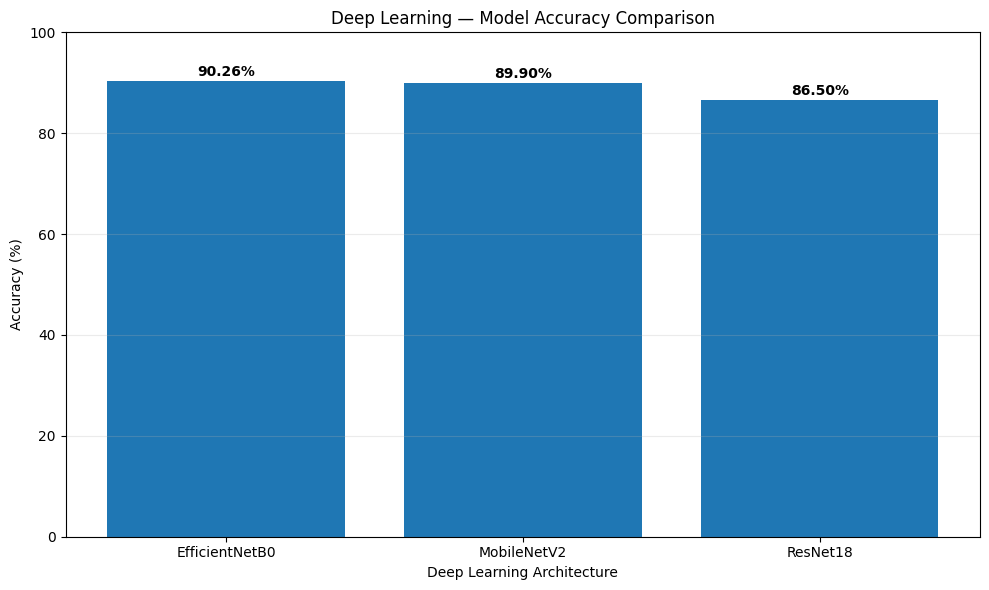


HIGHEST ACCURACY MODEL
Model: EfficientNetB0
Accuracy: 90.26%

Graph saved: D:\fullstackfixed\IDP_Final_Output\stage9_model_comparison\deep_learning_accuracy\graphs\deep_learning_model_accuracy_comparison.png
Results saved: D:\fullstackfixed\IDP_Final_Output\stage9_model_comparison\deep_learning_accuracy\results\deep_learning_accuracy_comparison.csv

TEST SET: NOT USED
MODEL TRAINING: NOT PERFORMED


In [17]:
# DEEP LEARNING — MODEL ACCURACY COMPARISON

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = Path(
    idp_path(r"D:\fullstackfixed\IDP_Final_Output\stage8_deep_learning")
)

OUTPUT_DIR = Path(
    idp_path('D:\\fullstackfixed\\IDP_Final_Output\\stage9_model_comparison\\deep_learning_accuracy')
)

GRAPH_DIR = OUTPUT_DIR / "graphs"
RESULT_DIR = OUTPUT_DIR / "results"

GRAPH_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "ResNet18": (
        "resnet18_full_finetuning",
        "resnet18_full_finetuned_metrics.csv"
    ),
    "MobileNetV2": (
        "mobilenetv2_full_finetuning",
        "mobilenetv2_finetuned_metrics.csv"
    ),
    "EfficientNetB0": (
        "efficientnetb0_full_finetuning",
        "efficientnetb0_finetuned_metrics.csv"
    )
}

accuracy_results = []

for model_name, (folder, filename) in MODELS.items():

    metrics_path = (
        BASE_DIR / folder / "results" / filename
    )

    if not metrics_path.is_file():
        raise FileNotFoundError(metrics_path)

    metrics_df = pd.read_csv(metrics_path)

    accuracy_row = metrics_df[
        metrics_df["Metric"].str.strip().str.lower()
        == "accuracy"
    ]

    if len(accuracy_row) != 1:
        raise ValueError(
            f"Expected exactly one accuracy value for {model_name}."
        )

    accuracy = float(accuracy_row.iloc[0]["Score"])

    if not 0 <= accuracy <= 1:
        raise ValueError(
            f"Invalid accuracy for {model_name}: {accuracy}"
        )

    accuracy_results.append({
        "Model": model_name,
        "Accuracy": accuracy * 100
    })


# RANK MODELS BY ACCURACY

comparison_df = pd.DataFrame(accuracy_results)

comparison_df = comparison_df.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

comparison_df.insert(
    0,
    "Rank",
    range(1, len(comparison_df) + 1)
)

print("=" * 65)
print("DEEP LEARNING — ACCURACY COMPARISON")
print("=" * 65)

print(
    comparison_df.to_string(
        index=False,
        formatters={
            "Accuracy": lambda x: f"{x:.2f}%"
        }
    )
)


# SINGLE ACCURACY BAR GRAPH

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

for bar, value in zip(
    bars,
    comparison_df["Accuracy"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_title(
    "Deep Learning — Model Accuracy Comparison"
)

ax.set_xlabel("Deep Learning Architecture")
ax.set_ylabel("Accuracy (%)")

ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

graph_path = (
    GRAPH_DIR /
    "deep_learning_model_accuracy_comparison.png"
)

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# SAVE RESULTS

comparison_df.to_csv(
    RESULT_DIR / "deep_learning_accuracy_comparison.csv",
    index=False
)


# FINAL RESULT

winner = comparison_df.iloc[0]

print("\n" + "=" * 65)
print("HIGHEST ACCURACY MODEL")
print("=" * 65)

print("Model:", winner["Model"])
print(f"Accuracy: {winner['Accuracy']:.2f}%")

print("\nGraph saved:", graph_path)
print(
    "Results saved:",
    RESULT_DIR / "deep_learning_accuracy_comparison.csv"
)

print("\nTEST SET: NOT USED")
print("MODEL TRAINING: NOT PERFORMED")
print("=" * 65)

**Stage 9 — Consolidated ML + Deep Learning Comparison**

LOADING CLASSICAL ML RESULTS
Classical ML models loaded: 4

LOADING DEEP LEARNING RESULTS
ResNet18: 86.50%
MobileNetV2: 89.90%
EfficientNetB0: 90.26%

COMBINING SEVEN MODELS

CLASSICAL ML + DEEP LEARNING — MODEL COMPARISON
 Rank               Model OOF Accuracy
    1      EfficientNetB0       90.26%
    2         MobileNetV2       89.90%
    3            ResNet18       86.50%
    4          Linear SVM       81.59%
    5 Logistic Regression       81.04%
    6         Gaussian NB       72.77%
    7                 KNN       69.17%


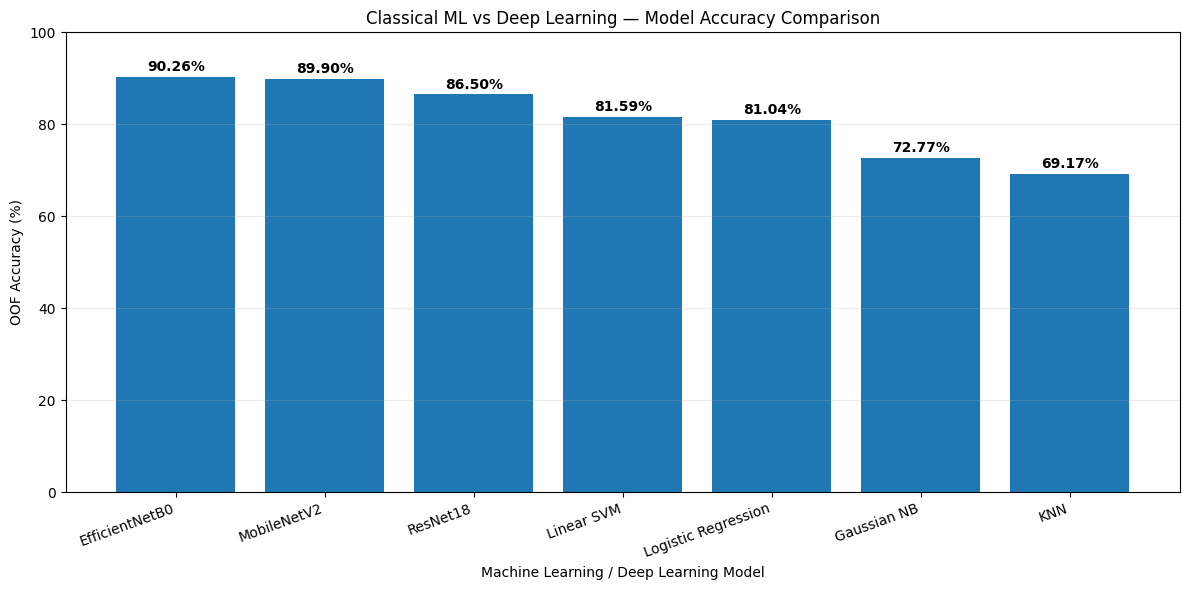


STAGE 9 — CONSOLIDATED MODEL COMPARISON COMPLETED
Total models compared: 7

HIGHEST ACCURACY MODEL
Model: EfficientNetB0
OOF Accuracy: 90.26%

SAVED FILES
CSV: D:\fullstackfixed\IDP_Final_Output\stage9_model_comparison\all_seven_models\results\all_seven_models_accuracy_comparison.csv
JSON: D:\fullstackfixed\IDP_Final_Output\stage9_model_comparison\all_seven_models\results\all_seven_models_accuracy_comparison.json
GRAPH: D:\fullstackfixed\IDP_Final_Output\stage9_model_comparison\all_seven_models\graphs\all_seven_models_accuracy_comparison.png

TEST SET: NOT USED
MODEL TRAINING: NOT PERFORMED


In [20]:
# STAGE 9 — CLASSICAL ML + DEEP LEARNING ACCURACY COMPARISON

import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# CONFIGURATION

ROOT = Path(
    idp_path(r"D:\fullstackfixed\IDP_Final_Output")
)

CLASSICAL_FILE = (
    ROOT
    / "stage7_model_training_v2"
    / "classical_ml_model_comparison"
    / "results"
    / "classical_ml_model_comparison.csv"
)

DL_DIR = (
    ROOT / "stage8_deep_learning"
)

OUTPUT_DIR = (
    ROOT / "stage9_model_comparison"
    / "all_seven_models"
)

RESULT_DIR = OUTPUT_DIR / "results"
GRAPH_DIR = OUTPUT_DIR / "graphs"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
GRAPH_DIR.mkdir(parents=True, exist_ok=True)


# MODEL DEFINITIONS

DL_MODELS = {
    "ResNet18": (
        "resnet18_full_finetuning",
        "resnet18_full_finetuned_metrics.csv"
    ),
    "MobileNetV2": (
        "mobilenetv2_full_finetuning",
        "mobilenetv2_finetuned_metrics.csv"
    ),
    "EfficientNetB0": (
        "efficientnetb0_full_finetuning",
        "efficientnetb0_finetuned_metrics.csv"
    )
}

CLASSICAL_ALIASES = {
    "linearsvm": "Linear SVM",
    "linearsvc": "Linear SVM",
    "svm": "Linear SVM",
    "logisticregression": "Logistic Regression",
    "gaussiannb": "Gaussian NB",
    "gaussiannaivebayes": "Gaussian NB",
    "knn": "KNN",
    "knearestneighbors": "KNN"
}

EXPECTED_CLASSICAL = {
    "Linear SVM",
    "Logistic Regression",
    "Gaussian NB",
    "KNN"
}


# HELPER FUNCTIONS

def normalize_name(value):

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(value).lower().strip()
    )


def parse_accuracy(value):

    if isinstance(value, str) and "%" in value:

        score = float(
            value.replace("%", "").strip()
        )

    else:

        score = float(value)

        if score <= 1:
            score *= 100

    if not np.isfinite(score) or not 0 <= score <= 100:
        raise ValueError(
            f"Invalid accuracy value: {value}"
        )

    return score


def find_column(df, candidates):

    normalized = {
        normalize_name(column): column
        for column in df.columns
    }

    for candidate in candidates:

        if candidate in normalized:
            return normalized[candidate]

    return None


# LOAD CLASSICAL ML RESULTS

print("=" * 75)
print("LOADING CLASSICAL ML RESULTS")
print("=" * 75)

if not CLASSICAL_FILE.is_file():
    raise FileNotFoundError(
        f"Classical ML comparison file missing:\n{CLASSICAL_FILE}"
    )

classical_df = pd.read_csv(CLASSICAL_FILE)

model_column = find_column(
    classical_df,
    [
        "model",
        "modelname",
        "classifier",
        "algorithm"
    ]
)

accuracy_column = find_column(
    classical_df,
    [
        "oofaccuracy",
        "accuracy"
    ]
)

if model_column is None:
    raise ValueError(
        "Could not identify the model column in Classical ML CSV."
    )

if accuracy_column is None:
    raise ValueError(
        "Could not identify the OOF accuracy column in Classical ML CSV."
    )

classical_results = []

for _, row in classical_df.iterrows():

    raw_name = str(row[model_column]).strip()

    canonical_name = CLASSICAL_ALIASES.get(
        normalize_name(raw_name)
    )

    if canonical_name is None:
        raise ValueError(
            f"Unrecognized Classical ML model name: {raw_name}"
        )

    classical_results.append({
        "Model": canonical_name,
        "OOF Accuracy": parse_accuracy(
            row[accuracy_column]
        )
    })

loaded_classical = {
    item["Model"] for item in classical_results
}

if loaded_classical != EXPECTED_CLASSICAL:
    raise ValueError(
        "Classical ML model mismatch.\n"
        f"Expected: {EXPECTED_CLASSICAL}\n"
        f"Found: {loaded_classical}"
    )

print("Classical ML models loaded:", len(classical_results))


# LOAD DEEP LEARNING RESULTS

print("\n" + "=" * 75)
print("LOADING DEEP LEARNING RESULTS")
print("=" * 75)

dl_results = []

for model_name, (folder, filename) in DL_MODELS.items():

    metrics_path = (
        DL_DIR
        / folder
        / "results"
        / filename
    )

    if not metrics_path.is_file():
        raise FileNotFoundError(metrics_path)

    metrics_df = pd.read_csv(metrics_path)

    required_columns = {"Metric", "Score"}

    if not required_columns.issubset(metrics_df.columns):
        raise ValueError(
            f"Invalid metrics file: {metrics_path}"
        )

    accuracy_rows = metrics_df[
        metrics_df["Metric"].astype(str).str.strip().str.lower()
        == "accuracy"
    ]

    if len(accuracy_rows) != 1:
        raise ValueError(
            f"Accuracy entry missing or duplicated for {model_name}."
        )

    accuracy = parse_accuracy(
        accuracy_rows.iloc[0]["Score"]
    )

    dl_results.append({
        "Model": model_name,
        "OOF Accuracy": accuracy
    })

    print(f"{model_name}: {accuracy:.2f}%")


# COMBINE ALL SEVEN MODELS

print("\n" + "=" * 75)
print("COMBINING SEVEN MODELS")
print("=" * 75)

all_results = (
    classical_results +
    dl_results
)

comparison_df = pd.DataFrame(all_results)

if len(comparison_df) != 7:
    raise ValueError(
        f"Expected 7 models, found {len(comparison_df)}."
    )

if comparison_df["Model"].duplicated().any():
    raise ValueError("Duplicate model names detected.")

comparison_df = comparison_df.sort_values(
    "OOF Accuracy",
    ascending=False
).reset_index(drop=True)

comparison_df.insert(
    0,
    "Rank",
    range(1, len(comparison_df) + 1)
)

print("\n" + "=" * 75)
print("CLASSICAL ML + DEEP LEARNING — MODEL COMPARISON")
print("=" * 75)

print(
    comparison_df.to_string(
        index=False,
        formatters={
            "OOF Accuracy": lambda x: f"{x:.2f}%"
        }
    )
)


# ACCURACY BAR GRAPH

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    comparison_df["Model"],
    comparison_df["OOF Accuracy"]
)

for bar, value in zip(
    bars,
    comparison_df["OOF Accuracy"]
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_title(
    "Classical ML vs Deep Learning — Model Accuracy Comparison"
)

ax.set_xlabel("Machine Learning / Deep Learning Model")
ax.set_ylabel("OOF Accuracy (%)")

ax.set_ylim(0, 100)
ax.grid(
    axis="y",
    alpha=0.25
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

graph_path = (
    GRAPH_DIR /
    "all_seven_models_accuracy_comparison.png"
)

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# SAVE CSV

csv_path = (
    RESULT_DIR /
    "all_seven_models_accuracy_comparison.csv"
)

comparison_df.to_csv(
    csv_path,
    index=False
)


# SAVE JSON

winner = comparison_df.iloc[0]

json_path = (
    RESULT_DIR /
    "all_seven_models_accuracy_comparison.json"
)

summary = {
    "experiment": "Stage 9 — Classical ML and Deep Learning Comparison",
    "evaluation_metric": "OOF Accuracy",
    "classical_ml_models": 4,
    "deep_learning_models": 3,
    "total_models": 7,
    "ranking": comparison_df.to_dict(orient="records"),
    "highest_accuracy_model": str(winner["Model"]),
    "highest_oof_accuracy": float(winner["OOF Accuracy"]),
    "test_set_used": False
}

with open(
    json_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4
    )


# FINAL REPORT

print("\n" + "=" * 75)
print("STAGE 9 — CONSOLIDATED MODEL COMPARISON COMPLETED")
print("=" * 75)

print("Total models compared:", len(comparison_df))

print("\nHIGHEST ACCURACY MODEL")
print("Model:", winner["Model"])
print(f"OOF Accuracy: {winner['OOF Accuracy']:.2f}%")

print("\nSAVED FILES")
print("CSV:", csv_path)
print("JSON:", json_path)
print("GRAPH:", graph_path)

print("\nTEST SET: NOT USED")
print("MODEL TRAINING: NOT PERFORMED")

print("=" * 75)

**Stage 9 — Final Model Selection and Test Evaluation**

We will use EfficientNetB0 because it achieved the highest development OOF accuracy among the seven models: 90.26%.

STAGE 10 — FINAL MODEL SELECTION AND TEST EVALUATION
Python: c:\Users\ashis\anaconda3\envs\idp-tf210\python.exe
TensorFlow: 2.10.1
Keras: 2.10.0
NumPy: 1.23.5

Detected GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Selected architecture: EfficientNetB0

FINAL MODEL SELECTION AUDIT

Development model ranking:
 Rank               Model  OOF Accuracy
    1      EfficientNetB0     90.261469
    2         MobileNetV2     89.901362
    3            ResNet18     86.503836
    4          Linear SVM     81.587600
    5 Logistic Regression     81.039612
    6         Gaussian NB     72.772820
    7                 KNN     69.171755

Selected model: EfficientNetB0
Selected development OOF accuracy: 90.26%

FINAL TRAINING SCHEDULE
Fold best epochs: [10, 9, 10, 9, 9]
Median selected epoch: 9
Head warm-up epochs: 2
Full fine-tuning epochs: 7
Final total epochs: 9

LOADING DEVELOPMENT DATA
Training records: 5259
Validation records: 1128
Combined development records: 6387



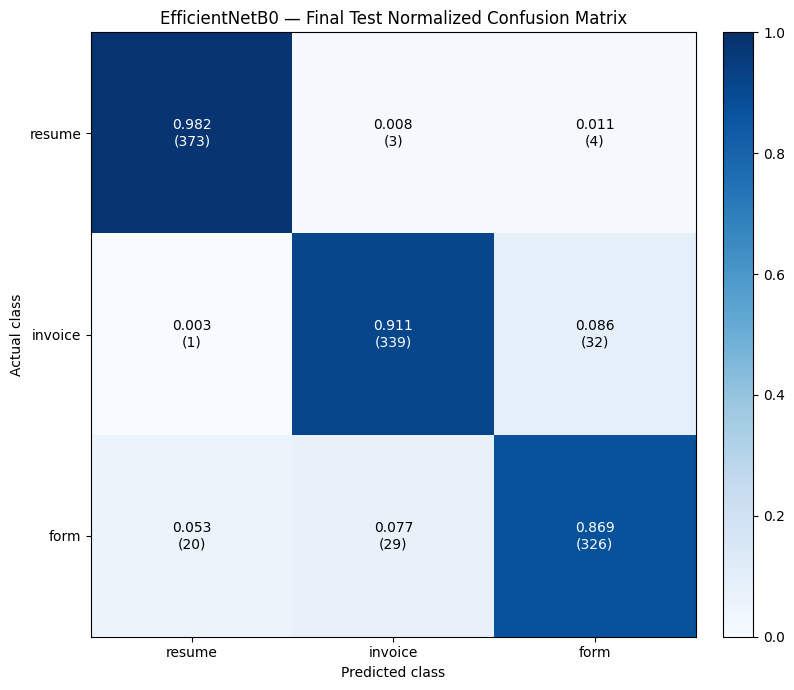


STAGE 10 — FINAL MODEL EVALUATION COMPLETED

SELECTED MODEL: EfficientNetB0
Development OOF accuracy: 90.26%
Final test accuracy: 92.10%

FINAL TEST METRICS
accuracy                 : 0.9210 (92.10%)
macro_precision          : 0.9203 (92.03%)
macro_recall             : 0.9207 (92.07%)
macro_f1                 : 0.9203 (92.03%)
weighted_f1              : 0.9205 (92.05%)

TRAINING
Development records: 6387
Total epochs: 9
Batch size: 4

SAVED FINAL WEIGHTS:
D:\fullstackfixed\IDP_Final_Output\stage10_final_model_evaluation\efficientnetb0\final_weights\efficientnetb0_final.weights.h5

RESULTS:
D:\fullstackfixed\IDP_Final_Output\stage10_final_model_evaluation\efficientnetb0\results

GRAPHS:
D:\fullstackfixed\IDP_Final_Output\stage10_final_model_evaluation\efficientnetb0\graphs

TEST SET USED ONLY FOR FINAL EVALUATION
MODEL SELECTION: LOCKED
FINAL TEST PREDICTION PASSES: 1

NEXT: STAGE 11 — MODEL EXPORT AND PACKAGING


In [21]:
# EFFICIENTNETB0 — FINAL MODEL SELECTION AND TEST EVALUATION

import os
import sys
import gc
import json
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.applications import EfficientNetB0

warnings.filterwarnings("ignore", category=UserWarning)

print("=" * 75)
print("STAGE 10 — FINAL MODEL SELECTION AND TEST EVALUATION")
print("=" * 75)


# ENVIRONMENT

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)
print("NumPy:", np.__version__)

if tf.__version__ != "2.10.1":
    raise RuntimeError("Incorrect TensorFlow version.")

CUDA_BIN = Path(sys.prefix) / "Library" / "bin"

if not CUDA_BIN.is_dir():
    raise FileNotFoundError(CUDA_BIN)

CUDA_DLL_HANDLE = os.add_dll_directory(str(CUDA_BIN))

os.environ["PATH"] = (
    str(CUDA_BIN) + os.pathsep + os.environ.get("PATH", "")
)

GPUS = tf.config.list_physical_devices("GPU")

print("\nDetected GPUs:", GPUS)

if not GPUS:
    raise RuntimeError("RTX 3050 not detected.")

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(
            gpu, True
        )
    except RuntimeError:
        pass


# CONFIGURATION

ROOT = Path(
    idp_path(r"D:\fullstackfixed\IDP_Final_Output")
)

DATA_DIR = (
    ROOT / "stage7_model_ready_dataset"
)

STAGE9_DIR = (
    ROOT / "stage9_model_comparison"
    / "all_seven_models"
)

EFFICIENCY_FOLD_FILE = (
    ROOT
    / "stage8_deep_learning"
    / "efficientnetb0_full_finetuning"
    / "results"
    / "efficientnetb0_finetuned_fold_diagnostics.csv"
)

OUTPUT_DIR = (
    ROOT / "stage10_final_model_evaluation"
    / "efficientnetb0"
)

WEIGHTS_DIR = OUTPUT_DIR / "final_weights"
RESULTS_DIR = OUTPUT_DIR / "results"
GRAPHS_DIR = OUTPUT_DIR / "graphs"

for folder in [
    WEIGHTS_DIR,
    RESULTS_DIR,
    GRAPHS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = DATA_DIR / "model_ready_train.csv"
VALIDATION_CSV = DATA_DIR / "model_ready_validation.csv"
TEST_CSV = DATA_DIR / "model_ready_test.csv"

CLASS_NAMES = [
    "resume",
    "invoice",
    "form"
]

LABELS = [0, 1, 2]

IMAGE_SIZE = 224
BATCH_SIZE = 4

WARMUP_EPOCHS = 2

WARMUP_LR = 1e-3
FINETUNE_LR = 1e-5

DROPOUT_RATE = 0.30
L2_STRENGTH = 1e-4

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("\nSelected architecture: EfficientNetB0")


# FINAL MODEL SELECTION AUDIT

print("\n" + "=" * 75)
print("FINAL MODEL SELECTION AUDIT")
print("=" * 75)

COMPARISON_CSV = (
    STAGE9_DIR
    / "results"
    / "all_seven_models_accuracy_comparison.csv"
)

if not COMPARISON_CSV.is_file():
    raise FileNotFoundError(COMPARISON_CSV)

comparison_df = pd.read_csv(COMPARISON_CSV)

required_comparison_columns = {
    "Rank",
    "Model",
    "OOF Accuracy"
}

if not required_comparison_columns.issubset(
    comparison_df.columns
):
    raise ValueError(
        "Stage 9 comparison file has an unexpected structure."
    )

comparison_df["OOF Accuracy"] = pd.to_numeric(
    comparison_df["OOF Accuracy"],
    errors="raise"
)

comparison_df = comparison_df.sort_values(
    "Rank"
).reset_index(drop=True)

winner = comparison_df.iloc[0]

print("\nDevelopment model ranking:")
print(comparison_df.to_string(index=False))

if str(winner["Model"]) != "EfficientNetB0":
    raise RuntimeError(
        "EfficientNetB0 is not the highest-accuracy model."
    )

SELECTED_OOF_ACCURACY = float(
    winner["OOF Accuracy"]
)

print("\nSelected model:", winner["Model"])
print(
    f"Selected development OOF accuracy: "
    f"{SELECTED_OOF_ACCURACY:.2f}%"
)


# FINAL TRAINING SCHEDULE

print("\n" + "=" * 75)
print("FINAL TRAINING SCHEDULE")
print("=" * 75)

if not EFFICIENCY_FOLD_FILE.is_file():
    raise FileNotFoundError(EFFICIENCY_FOLD_FILE)

fold_df = pd.read_csv(EFFICIENCY_FOLD_FILE)

if "best_epoch" not in fold_df.columns:
    raise ValueError(
        "EfficientNetB0 fold file is missing best_epoch."
    )

if len(fold_df) != 5:
    raise ValueError(
        "Expected exactly five EfficientNetB0 fold results."
    )

if not np.isfinite(
    fold_df["best_epoch"].to_numpy(dtype=float)
).all():
    raise ValueError("Invalid best epoch values.")

fold_best_epochs = (
    fold_df["best_epoch"]
    .astype(int)
    .to_numpy()
)

FINAL_TOTAL_EPOCHS = int(
    np.median(fold_best_epochs)
)

FINETUNE_EPOCHS = (
    FINAL_TOTAL_EPOCHS - WARMUP_EPOCHS
)

if FINETUNE_EPOCHS < 1:
    raise ValueError(
        "Invalid final fine-tuning schedule."
    )

print("Fold best epochs:", fold_best_epochs.tolist())
print("Median selected epoch:", FINAL_TOTAL_EPOCHS)
print("Head warm-up epochs:", WARMUP_EPOCHS)
print("Full fine-tuning epochs:", FINETUNE_EPOCHS)
print("Final total epochs:", FINAL_TOTAL_EPOCHS)


# LOAD DEVELOPMENT DATA

print("\n" + "=" * 75)
print("LOADING DEVELOPMENT DATA")
print("=" * 75)

for path in [TRAIN_CSV, VALIDATION_CSV]:
    if not path.is_file():
        raise FileNotFoundError(path)

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VALIDATION_CSV)

dev_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

if len(train_df) != 5259:
    raise ValueError(
        f"Unexpected training record count: {len(train_df)}"
    )

if len(val_df) != 1128:
    raise ValueError(
        f"Unexpected validation record count: {len(val_df)}"
    )

if len(dev_df) != 6387:
    raise ValueError(
        f"Unexpected development record count: {len(dev_df)}"
    )

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Combined development records:", len(dev_df))


# DEVELOPMENT DATA VALIDATION

required_columns = [
    "image_id",
    "canonical_path",
    "class_name",
    "label",
    "duplicate_group_id"
]

for col in required_columns:

    if col not in dev_df.columns:
        raise KeyError(
            f"Development column missing: {col}"
        )

if dev_df["image_id"].duplicated().any():
    raise ValueError(
        "Duplicate development image IDs."
    )

if dev_df["canonical_path"].isna().any():
    raise ValueError(
        "Missing canonical development image paths."
    )

if dev_df["duplicate_group_id"].isna().any():
    raise ValueError(
        "Missing development duplicate group IDs."
    )

dev_df["label"] = dev_df["label"].astype(int)

EXPECTED_MAPPING = {
    0: "resume",
    1: "invoice",
    2: "form"
}

mapping = (
    dev_df[["label", "class_name"]]
    .drop_duplicates()
    .sort_values("label")
    .set_index("label")["class_name"]
    .to_dict()
)

if mapping != EXPECTED_MAPPING:
    raise ValueError(
        f"Incorrect development class mapping: {mapping}"
    )

if set(dev_df["label"].unique()) != set(LABELS):
    raise ValueError(
        "Development data is missing a class."
    )

missing_dev_paths = [
    path
    for path in dev_df["canonical_path"].astype(str)
    if not Path(path).is_file()
]

if missing_dev_paths:
    raise FileNotFoundError(
        f"{len(missing_dev_paths)} development images missing. "
        f"Examples: {missing_dev_paths[:5]}"
    )

print("\nDevelopment class distribution:")
print(
    dev_df["class_name"].value_counts().sort_index()
)

print("Development image validation: PASSED")


# TEST DATA INTEGRITY AUDIT

print("\n" + "=" * 75)
print("TEST DATA INTEGRITY AUDIT")
print("=" * 75)

if not TEST_CSV.is_file():
    raise FileNotFoundError(TEST_CSV)

test_df = pd.read_csv(TEST_CSV)

if len(test_df) != 1127:
    raise ValueError(
        f"Unexpected test record count: {len(test_df)}"
    )

for col in required_columns:

    if col not in test_df.columns:
        raise KeyError(
            f"Test column missing: {col}"
        )

if test_df["image_id"].duplicated().any():
    raise ValueError(
        "Duplicate test image IDs."
    )

if test_df["image_id"].isna().any():
    raise ValueError(
        "Missing test image IDs."
    )

if test_df["canonical_path"].isna().any():
    raise ValueError(
        "Missing test canonical paths."
    )

if test_df["duplicate_group_id"].isna().any():
    raise ValueError(
        "Missing test duplicate group IDs."
    )

test_df["label"] = test_df["label"].astype(int)

if set(test_df["label"].unique()) != set(LABELS):
    raise ValueError(
        "Test set is missing a class."
    )

test_mapping = (
    test_df[["label", "class_name"]]
    .drop_duplicates()
    .sort_values("label")
    .set_index("label")["class_name"]
    .to_dict()
)

if test_mapping != EXPECTED_MAPPING:
    raise ValueError(
        f"Test class mapping mismatch: {test_mapping}"
    )

development_ids = set(
    dev_df["image_id"].astype(str)
)

test_ids = set(
    test_df["image_id"].astype(str)
)

if development_ids & test_ids:
    raise RuntimeError(
        "Development/test image ID overlap detected."
    )

development_groups = set(
    dev_df["duplicate_group_id"].astype(str)
)

test_groups = set(
    test_df["duplicate_group_id"].astype(str)
)

group_overlap = (
    development_groups & test_groups
)

if group_overlap:
    raise RuntimeError(
        f"Development/test duplicate-group leakage detected: "
        f"{len(group_overlap)} groups."
    )

missing_test_paths = [
    path
    for path in test_df["canonical_path"].astype(str)
    if not Path(path).is_file()
]

if missing_test_paths:
    raise FileNotFoundError(
        f"{len(missing_test_paths)} test images missing. "
        f"Examples: {missing_test_paths[:5]}"
    )

print("Test records:", len(test_df))
print("Test class distribution:")
print(
    test_df["class_name"].value_counts().sort_index()
)
print("Development/test image overlap: 0")
print("Development/test duplicate-group overlap: 0")
print("Test image integrity: PASSED")


# IMAGE PREPROCESSING

def load_document(path, label):

    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_png(
        image_bytes,
        channels=1
    )

    image = tf.image.grayscale_to_rgb(image)

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE],
        method="bilinear",
        antialias=True
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image.set_shape(
        [IMAGE_SIZE, IMAGE_SIZE, 3]
    )

    return image, tf.cast(label, tf.int32)


def make_training_dataset(frame):

    paths = frame[
        "canonical_path"
    ].astype(str).to_numpy()

    labels = frame[
        "label"
    ].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.shuffle(
        buffer_size=len(frame),
        seed=RANDOM_SEED,
        reshuffle_each_iteration=True
    )

    dataset = dataset.map(
        load_document,
        num_parallel_calls=2,
        deterministic=True
    )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    return dataset.prefetch(1)


def load_test_image(path):

    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_png(
        image_bytes,
        channels=1
    )

    image = tf.image.grayscale_to_rgb(image)

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE],
        method="bilinear",
        antialias=True
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image.set_shape(
        [IMAGE_SIZE, IMAGE_SIZE, 3]
    )

    return image


def make_test_dataset(frame):

    paths = frame[
        "canonical_path"
    ].astype(str).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        paths
    )

    dataset = dataset.map(
        load_test_image,
        num_parallel_calls=2,
        deterministic=True
    )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    return dataset.prefetch(1)


# BUILD EFFICIENTNETB0

print("\n" + "=" * 75)
print("BUILDING FINAL EFFICIENTNETB0")
print("=" * 75)

tf.keras.backend.clear_session()
gc.collect()

tf.random.set_seed(RANDOM_SEED)

backbone = EfficientNetB0(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights="imagenet",
    pooling="avg"
)

backbone.trainable = False

image_input = tf.keras.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    name="document_image"
)

features = backbone(image_input)

x = tf.keras.layers.Dropout(
    DROPOUT_RATE,
    name="classifier_dropout"
)(features)

logits = tf.keras.layers.Dense(
    3,
    activation=None,
    kernel_regularizer=tf.keras.regularizers.l2(
        L2_STRENGTH
    ),
    dtype="float32",
    name="document_classifier"
)(x)

final_model = tf.keras.Model(
    inputs=image_input,
    outputs=logits,
    name="IDP_EfficientNetB0"
)

print("Model:", final_model.name)
print("Input shape:", final_model.input_shape)
print("Output shape:", final_model.output_shape)
print("Total parameters:", f"{final_model.count_params():,}")

if tuple(final_model.output_shape) != (None, 3):
    raise ValueError(
        "Incorrect final model output shape."
    )


# COMPILE HEAD WARM-UP

print("\n" + "=" * 75)
print("PHASE 1 — CLASSIFIER HEAD WARM-UP")
print("=" * 75)

def compile_model(model, learning_rate):

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            )
        ]
    )


compile_model(
    final_model,
    WARMUP_LR
)

development_ds = make_training_dataset(dev_df)

warmup_history = final_model.fit(
    development_ds,
    epochs=WARMUP_EPOCHS,
    callbacks=[
        tf.keras.callbacks.TerminateOnNaN()
    ],
    verbose=2
)

print("\nClassifier head warm-up completed.")


# FULL-BACKBONE FINE-TUNING

print("\n" + "=" * 75)
print("PHASE 2 — FULL-BACKBONE FINE-TUNING")
print("=" * 75)

backbone.trainable = True

for layer in backbone.layers:
    layer.trainable = True

bn_layers = [
    layer
    for layer in backbone.submodules
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

for layer in bn_layers:
    layer.trainable = False

conv_types = (
    tf.keras.layers.Conv2D,
    tf.keras.layers.DepthwiseConv2D
)

conv_layers = [
    layer
    for layer in backbone.submodules
    if isinstance(layer, conv_types)
]

frozen_conv_layers = [
    layer.name
    for layer in conv_layers
    if not layer.trainable
]

if frozen_conv_layers:
    raise RuntimeError(
        f"Unexpected frozen convolutional layers: "
        f"{frozen_conv_layers}"
    )

if any(layer.trainable for layer in bn_layers):
    raise RuntimeError(
        "Batch Normalization layers are not frozen."
    )

trainable_backbone_parameters = sum(
    int(tf.keras.backend.count_params(variable))
    for variable in backbone.trainable_variables
)

if trainable_backbone_parameters <= 0:
    raise RuntimeError(
        "No trainable backbone parameters."
    )

print("Trainable convolutional layers:", len(conv_layers))
print("Frozen BatchNormalization layers:", len(bn_layers))
print(
    "Trainable backbone parameters:",
    f"{trainable_backbone_parameters:,}"
)

compile_model(
    final_model,
    FINETUNE_LR
)

finetune_history = final_model.fit(
    development_ds,
    epochs=FINETUNE_EPOCHS,
    callbacks=[
        tf.keras.callbacks.TerminateOnNaN()
    ],
    verbose=2
)

print("\nFull-backbone fine-tuning completed.")

del development_ds
gc.collect()


# SAVE FINAL TRAINED WEIGHTS

print("\n" + "=" * 75)
print("SAVING FINAL TRAINED WEIGHTS")
print("=" * 75)

final_weights_path = (
    WEIGHTS_DIR /
    "efficientnetb0_final.weights.h5"
)

final_model.save_weights(
    str(final_weights_path)
)

if not final_weights_path.is_file():
    raise RuntimeError(
        "Final model weights were not saved."
    )

print("Final weights:", final_weights_path)


# FINAL TEST EVALUATION — SINGLE PREDICTION PASS

print("\n" + "=" * 75)
print("FINAL TEST SET EVALUATION")
print("=" * 75)

print("Evaluating untouched test records:", len(test_df))

test_ds = make_test_dataset(test_df)

test_logits = final_model.predict(
    test_ds,
    verbose=1
)

if test_logits.shape != (len(test_df), 3):
    raise ValueError(
        f"Incorrect test prediction shape: {test_logits.shape}"
    )

if not np.isfinite(test_logits).all():
    raise RuntimeError(
        "Non-finite test predictions detected."
    )

test_probabilities = tf.nn.softmax(
    test_logits,
    axis=-1
).numpy()

test_predictions = np.argmax(
    test_probabilities,
    axis=1
)

y_test = test_df[
    "label"
].to_numpy(dtype=np.int64)

if len(test_predictions) != len(y_test):
    raise RuntimeError(
        "Test prediction and label counts do not match."
    )

if not np.isfinite(test_probabilities).all():
    raise RuntimeError(
        "Invalid test probabilities."
    )

print("Test predictions generated:", len(test_predictions))


# FINAL CLASSIFICATION METRICS

print("\n" + "=" * 75)
print("FINAL TEST CLASSIFICATION METRICS")
print("=" * 75)

test_metrics = {
    "accuracy": accuracy_score(
        y_test,
        test_predictions
    ),

    "macro_precision": precision_score(
        y_test,
        test_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "macro_recall": recall_score(
        y_test,
        test_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "macro_f1": f1_score(
        y_test,
        test_predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    ),

    "weighted_f1": f1_score(
        y_test,
        test_predictions,
        labels=LABELS,
        average="weighted",
        zero_division=0
    )
}

metrics_df = pd.DataFrame(
    [
        {
            "Metric": name.replace("_", " ").title(),
            "Score": value,
            "Percentage": value * 100
        }
        for name, value in test_metrics.items()
    ]
)

print(
    metrics_df.to_string(
        index=False,
        formatters={
            "Score": lambda x: f"{x:.4f}",
            "Percentage": lambda x: f"{x:.2f}%"
        }
    )
)


# PER-CLASS CLASSIFICATION REPORT

report = classification_report(
    y_test,
    test_predictions,
    labels=LABELS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report
).transpose()

print("\nPER-CLASS CLASSIFICATION REPORT")

print(
    report_df.round(4).to_string()
)


# TEST CONFUSION MATRIX

print("\n" + "=" * 75)
print("FINAL TEST CONFUSION MATRIX")
print("=" * 75)

cm_counts = confusion_matrix(
    y_test,
    test_predictions,
    labels=LABELS
)

cm_normalized = confusion_matrix(
    y_test,
    test_predictions,
    labels=LABELS,
    normalize="true"
)

print(
    pd.DataFrame(
        cm_counts,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    ).to_string()
)


# SAVE CONFUSION MATRIX GRAPH

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    cm_normalized,
    cmap="Blues",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

ax.set(
    xticks=np.arange(3),
    yticks=np.arange(3),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="EfficientNetB0 — Final Test Normalized Confusion Matrix"
)

for i in range(3):
    for j in range(3):

        value = cm_normalized[i, j]
        count = cm_counts[i, j]

        ax.text(
            j,
            i,
            f"{value:.3f}\n({count})",
            ha="center",
            va="center",
            color="white" if value > 0.55 else "black"
        )

plt.tight_layout()

confusion_graph_path = (
    GRAPHS_DIR /
    "efficientnetb0_final_test_confusion_matrix.png"
)

plt.savefig(
    confusion_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# SAVE TEST PREDICTIONS

prediction_df = test_df[
    [
        "image_id",
        "canonical_path",
        "class_name",
        "label",
        "duplicate_group_id"
    ]
].copy()

prediction_df["predicted_label"] = test_predictions

prediction_df["predicted_class"] = [
    CLASS_NAMES[int(value)]
    for value in test_predictions
]

for index, class_name in enumerate(CLASS_NAMES):

    prediction_df[
        f"probability_{class_name}"
    ] = test_probabilities[:, index]

prediction_df["correct"] = (
    prediction_df["label"]
    ==
    prediction_df["predicted_label"]
)

prediction_path = (
    RESULTS_DIR /
    "efficientnetb0_final_test_predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)


# SAVE RESULTS

metrics_path = (
    RESULTS_DIR /
    "efficientnetb0_final_test_metrics.csv"
)

report_path = (
    RESULTS_DIR /
    "efficientnetb0_final_test_classification_report.csv"
)

confusion_path = (
    RESULTS_DIR /
    "efficientnetb0_final_test_confusion_matrix.csv"
)

training_history_path = (
    RESULTS_DIR /
    "efficientnetb0_final_training_history.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)

report_df.to_csv(
    report_path
)

pd.DataFrame(
    cm_counts,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(confusion_path)

history_df = pd.DataFrame()

for name, history in [
    ("warmup", warmup_history.history),
    ("finetuning", finetune_history.history)
]:

    for epoch_index in range(
        len(history.get("loss", []))
    ):

        row = {
            "phase": name,
            "epoch": epoch_index + 1
        }

        for metric_name, values in history.items():

            row[metric_name] = float(
                values[epoch_index]
            )

        history_df = pd.concat(
            [
                history_df,
                pd.DataFrame([row])
            ],
            ignore_index=True
        )

history_df.to_csv(
    training_history_path,
    index=False
)


# FINAL SUMMARY

summary = {
    "stage": 10,
    "selected_model": "EfficientNetB0",
    "selection_criterion": "Highest development OOF accuracy",
    "development_oof_accuracy_percentage": SELECTED_OOF_ACCURACY,
    "final_training_records": len(dev_df),
    "final_test_records": len(test_df),
    "total_training_epochs": FINAL_TOTAL_EPOCHS,
    "warmup_epochs": WARMUP_EPOCHS,
    "full_finetuning_epochs": FINETUNE_EPOCHS,
    "batch_size": BATCH_SIZE,
    "warmup_learning_rate": WARMUP_LR,
    "finetuning_learning_rate": FINETUNE_LR,
    "full_backbone_trainable": True,
    "batch_normalization_frozen": True,
    "final_test_metrics": {
        name: float(value)
        for name, value in test_metrics.items()
    },
    "test_accuracy_percentage": float(
        test_metrics["accuracy"] * 100
    ),
    "test_set_used_for_training": False,
    "test_set_used_for_model_selection": False,
    "test_prediction_passes": 1,
    "final_weights": str(final_weights_path)
}

summary_path = (
    RESULTS_DIR /
    "efficientnetb0_stage10_final_summary.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        summary,
        file,
        indent=4
    )


# FINAL REPORT

print("\n" + "=" * 75)
print("STAGE 10 — FINAL MODEL EVALUATION COMPLETED")
print("=" * 75)

print("\nSELECTED MODEL: EfficientNetB0")

print(
    "Development OOF accuracy:",
    f"{SELECTED_OOF_ACCURACY:.2f}%"
)

print(
    "Final test accuracy:",
    f"{test_metrics['accuracy'] * 100:.2f}%"
)

print("\nFINAL TEST METRICS")

for name, value in test_metrics.items():

    print(
        f"{name:25s}: "
        f"{value:.4f} ({value * 100:.2f}%)"
    )

print("\nTRAINING")
print("Development records:", len(dev_df))
print("Total epochs:", FINAL_TOTAL_EPOCHS)
print("Batch size:", BATCH_SIZE)

print("\nSAVED FINAL WEIGHTS:")
print(final_weights_path)

print("\nRESULTS:")
print(RESULTS_DIR)

print("\nGRAPHS:")
print(GRAPHS_DIR)

print("\nTEST SET USED ONLY FOR FINAL EVALUATION")
print("MODEL SELECTION: LOCKED")
print("FINAL TEST PREDICTION PASSES: 1")

print("\nNEXT: STAGE 11 — MODEL EXPORT AND PACKAGING")

print("=" * 75)

**Stage 11 — EfficientNetB0 Model Export and Packaging**

In [22]:
# STAGE 11 — EFFICIENTNETB0 MODEL EXPORT AND PACKAGING

import os
import sys
import gc
import json
import shutil
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

warnings.filterwarnings("ignore", category=UserWarning)

print("=" * 75)
print("STAGE 11 — EFFICIENTNETB0 MODEL EXPORT AND PACKAGING")
print("=" * 75)


# ENVIRONMENT

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)
print("NumPy:", np.__version__)

if tf.__version__ != "2.10.1":
    raise RuntimeError(
        "Incorrect TensorFlow version. Expected TensorFlow 2.10.1."
    )

CUDA_BIN = Path(sys.prefix) / "Library" / "bin"

if not CUDA_BIN.is_dir():
    raise FileNotFoundError(CUDA_BIN)

CUDA_DLL_HANDLE = os.add_dll_directory(
    str(CUDA_BIN)
)

os.environ["PATH"] = (
    str(CUDA_BIN)
    + os.pathsep
    + os.environ.get("PATH", "")
)

GPUS = tf.config.list_physical_devices("GPU")

print("\nDetected GPUs:", GPUS)

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(
            gpu,
            True
        )
    except RuntimeError:
        pass


# PATH CONFIGURATION

ROOT = Path(
    idp_path(r"D:\fullstackfixed\IDP_Final_Output")
)

STAGE7_DIR = (
    ROOT / "stage7_model_ready_dataset"
)

STAGE10_DIR = (
    ROOT
    / "stage10_final_model_evaluation"
    / "efficientnetb0"
)

FINAL_WEIGHTS = (
    STAGE10_DIR
    / "final_weights"
    / "efficientnetb0_final.weights.h5"
)

FINAL_METRICS = (
    STAGE10_DIR
    / "results"
    / "efficientnetb0_final_test_metrics.csv"
)

FINAL_SUMMARY = (
    STAGE10_DIR
    / "results"
    / "efficientnetb0_stage10_final_summary.json"
)

DEV_TRAIN = (
    STAGE7_DIR / "model_ready_train.csv"
)

PACKAGE_ROOT = (
    ROOT / "stage11_model_export"
)

PACKAGE_DIR = (
    PACKAGE_ROOT / "efficientnetb0_idp_classifier"
)

SAVED_MODEL_DIR = PACKAGE_DIR / "saved_model"
WEIGHTS_DIR = PACKAGE_DIR / "weights"
CONFIG_DIR = PACKAGE_DIR / "config"

for folder in [
    PACKAGE_ROOT,
    PACKAGE_DIR,
    WEIGHTS_DIR,
    CONFIG_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("\nPackage destination:")
print(PACKAGE_DIR)


# VERIFY STAGE 10 ARTIFACTS

print("\n" + "=" * 75)
print("VERIFYING FINAL STAGE 10 ARTIFACTS")
print("=" * 75)

for path in [
    FINAL_WEIGHTS,
    FINAL_METRICS,
    FINAL_SUMMARY,
    DEV_TRAIN
]:
    if not path.is_file():
        raise FileNotFoundError(path)

if FINAL_WEIGHTS.stat().st_size == 0:
    raise RuntimeError("Final weight file is empty.")

with open(
    FINAL_SUMMARY,
    "r",
    encoding="utf-8"
) as file:
    stage10_summary = json.load(file)

if stage10_summary.get("selected_model") != "EfficientNetB0":
    raise ValueError("Stage 10 selected model mismatch.")

if stage10_summary.get("test_set_used_for_training") is not False:
    raise ValueError("Stage 10 training/test separation check failed.")

if stage10_summary.get("test_set_used_for_model_selection") is not False:
    raise ValueError("Stage 10 test-set selection check failed.")

metrics_df = pd.read_csv(FINAL_METRICS)

accuracy_row = metrics_df[
    metrics_df["Metric"].str.lower().str.strip()
    == "accuracy"
]

if len(accuracy_row) != 1:
    raise ValueError("Final test accuracy not found.")

FINAL_TEST_ACCURACY = float(
    accuracy_row.iloc[0]["Score"]
)

print("Final model weights: VERIFIED")
print("Stage 10 summary: VERIFIED")
print("Final metrics: VERIFIED")
print(
    f"Final test accuracy: {FINAL_TEST_ACCURACY:.4%}"
)


# LOAD DEVELOPMENT SAMPLE FOR EXPORT VERIFICATION

print("\n" + "=" * 75)
print("PREPARING DEVELOPMENT VERIFICATION SAMPLE")
print("=" * 75)

dev_df = pd.read_csv(DEV_TRAIN)

if "canonical_path" not in dev_df.columns:
    raise KeyError("canonical_path missing.")

if len(dev_df) == 0:
    raise ValueError("Development dataset is empty.")

sample_path = Path(
    str(dev_df.iloc[0]["canonical_path"])
)

if not sample_path.is_file():
    raise FileNotFoundError(sample_path)

print("Verification image:", sample_path)


# REBUILD ORIGINAL EFFICIENTNETB0 ARCHITECTURE

print("\n" + "=" * 75)
print("REBUILDING EFFICIENTNETB0 ARCHITECTURE")
print("=" * 75)

IMAGE_SIZE = 224

CLASS_NAMES = [
    "resume",
    "invoice",
    "form"
]

CLASS_MAPPING = {
    "0": "resume",
    "1": "invoice",
    "2": "form"
}

DROPOUT_RATE = 0.30
L2_STRENGTH = 1e-4

from tensorflow.keras.applications import EfficientNetB0

tf.keras.backend.clear_session()
gc.collect()

backbone = EfficientNetB0(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights=None,
    pooling="avg"
)

backbone.trainable = True

for layer in backbone.layers:
    layer.trainable = True

bn_layers = [
    layer
    for layer in backbone.submodules
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

for layer in bn_layers:
    layer.trainable = False

image_input = tf.keras.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    name="document_image"
)

features = backbone(image_input)

x = tf.keras.layers.Dropout(
    DROPOUT_RATE,
    name="classifier_dropout"
)(features)

logits = tf.keras.layers.Dense(
    3,
    activation=None,
    kernel_regularizer=tf.keras.regularizers.l2(
        L2_STRENGTH
    ),
    dtype="float32",
    name="document_classifier"
)(x)

final_model = tf.keras.Model(
    inputs=image_input,
    outputs=logits,
    name="IDP_EfficientNetB0"
)

if final_model.count_params() != 4053414:
    raise RuntimeError(
        f"Architecture parameter mismatch: "
        f"{final_model.count_params():,}"
    )

print("Model name:", final_model.name)
print("Input shape:", final_model.input_shape)
print("Output shape:", final_model.output_shape)
print("Total parameters:", f"{final_model.count_params():,}")
print("Frozen BatchNormalization layers:", len(bn_layers))


# LOAD FINAL TRAINED WEIGHTS

print("\n" + "=" * 75)
print("LOADING FINAL TRAINED WEIGHTS")
print("=" * 75)

final_model.load_weights(
    str(FINAL_WEIGHTS)
)

print("Final trained weights loaded successfully.")

if not final_model.weights:
    raise RuntimeError("Model weights were not loaded.")


# PREPROCESSING

def preprocess_canonical_png(path):

    image_bytes = tf.io.read_file(str(path))

    image = tf.io.decode_png(
        image_bytes,
        channels=1
    )

    image = tf.image.grayscale_to_rgb(image)

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE],
        method="bilinear",
        antialias=True
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image.set_shape(
        [IMAGE_SIZE, IMAGE_SIZE, 3]
    )

    return tf.expand_dims(
        image,
        axis=0
    )


sample_batch = preprocess_canonical_png(
    sample_path
)

print("\nInput verification:")
print("Shape:", sample_batch.shape)
print("Minimum:", float(tf.reduce_min(sample_batch).numpy()))
print("Maximum:", float(tf.reduce_max(sample_batch).numpy()))

tf.debugging.assert_all_finite(
    sample_batch,
    "Invalid development sample."
)


# ORIGINAL MODEL PREDICTION

print("\n" + "=" * 75)
print("VERIFYING RECONSTRUCTED MODEL PREDICTION")
print("=" * 75)

original_logits = final_model(
    sample_batch,
    training=False
).numpy()

if original_logits.shape != (1, 3):
    raise ValueError(
        f"Unexpected prediction shape: {original_logits.shape}"
    )

if not np.isfinite(original_logits).all():
    raise RuntimeError("Invalid model prediction.")

original_probabilities = tf.nn.softmax(
    original_logits,
    axis=-1
).numpy()

print("Output shape:", original_logits.shape)

for index, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name}: "
        f"{original_probabilities[0, index]:.6f}"
    )


# SAVE ARCHITECTURE JSON

print("\n" + "=" * 75)
print("SAVING MODEL ARCHITECTURE")
print("=" * 75)

architecture_path = (
    CONFIG_DIR / "efficientnetb0_architecture.json"
)

with open(
    architecture_path,
    "w",
    encoding="utf-8"
) as file:
    file.write(final_model.to_json())

print("Architecture saved:", architecture_path)


# SAVE COMPLETE TENSORFLOW MODEL

print("\n" + "=" * 75)
print("EXPORTING TENSORFLOW SAVEDMODEL")
print("=" * 75)

if SAVED_MODEL_DIR.exists():
    shutil.rmtree(SAVED_MODEL_DIR)

final_model.save(
    str(SAVED_MODEL_DIR),
    include_optimizer=False,
    save_format="tf"
)

saved_model_file = (
    SAVED_MODEL_DIR / "saved_model.pb"
)

if not saved_model_file.is_file():
    raise RuntimeError(
        "SavedModel export failed."
    )

print("SavedModel exported successfully.")
print("SavedModel location:", SAVED_MODEL_DIR)


# COPY FINAL WEIGHTS INTO PACKAGE

print("\n" + "=" * 75)
print("PACKAGING FINAL TRAINED WEIGHTS")
print("=" * 75)

package_weights_path = (
    WEIGHTS_DIR /
    "efficientnetb0_final.weights.h5"
)

shutil.copy2(
    FINAL_WEIGHTS,
    package_weights_path
)

if not package_weights_path.is_file():
    raise RuntimeError("Final weights were not packaged.")

if package_weights_path.stat().st_size != FINAL_WEIGHTS.stat().st_size:
    raise RuntimeError("Packaged weights size mismatch.")

print("Packaged weights:", package_weights_path)


# CLASS MAPPING

class_mapping_path = (
    CONFIG_DIR / "class_mapping.json"
)

with open(
    class_mapping_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        CLASS_MAPPING,
        file,
        indent=4
    )

print("Class mapping saved:", class_mapping_path)


# PREPROCESSING CONFIGURATION

preprocessing_config = {
    "image_size": [224, 224],
    "source_image": "Stage 4 canonical grayscale PNG",
    "input_channels": 1,
    "model_channels": 3,
    "conversion": "Grayscale to RGB",
    "resize_method": "Bilinear",
    "antialias": True,
    "input_dtype": "float32",
    "input_pixel_range": [0, 255],
    "external_rescaling": False,
    "normalization": (
        "EfficientNetB0 built-in preprocessing layers; "
        "do not apply MobileNetV2 preprocess_input"
    ),
    "output_type": "Three raw classification logits",
    "probability_conversion": "Softmax"
}

preprocessing_path = (
    CONFIG_DIR / "preprocessing_config.json"
)

with open(
    preprocessing_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        preprocessing_config,
        file,
        indent=4
    )

print("Preprocessing configuration saved.")


# MODEL METADATA

model_metadata = {
    "model_name": "IDP EfficientNetB0",
    "model_version": "1.0.0",
    "project": "Intelligent Document Processing System",
    "framework": "TensorFlow",
    "tensorflow_version": tf.__version__,
    "keras_version": tf.keras.__version__,
    "architecture": "EfficientNetB0",
    "pretrained_source": "ImageNet",
    "number_of_classes": 3,
    "class_mapping": CLASS_MAPPING,
    "input_shape": [224, 224, 3],
    "output_shape": [3],
    "total_parameters": final_model.count_params(),
    "trainable_backbone": True,
    "batch_normalization_frozen": True,
    "training_records": 6387,
    "training_epochs": 9,
    "batch_size": 4,
    "test_records": 1127,
    "final_test_metrics": {
        str(row["Metric"]): float(row["Score"])
        for _, row in metrics_df.iterrows()
    },
    "final_test_accuracy": FINAL_TEST_ACCURACY,
    "test_set_used_for_training": False,
    "saved_model_format": "TensorFlow SavedModel",
    "weights_file": "weights/efficientnetb0_final.weights.h5"
}

metadata_path = (
    CONFIG_DIR / "model_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        model_metadata,
        file,
        indent=4
    )

print("Model metadata saved.")


# CREATE REUSABLE INFERENCE MODULE

print("\n" + "=" * 75)
print("CREATING REUSABLE INFERENCE MODULE")
print("=" * 75)

INFERENCE_SOURCE = r'''
import json
from pathlib import Path

import numpy as np
import tensorflow as tf


PACKAGE_DIR = Path(__file__).resolve().parent

SAVED_MODEL_DIR = PACKAGE_DIR / "saved_model"

CONFIG_DIR = PACKAGE_DIR / "config"


class IDPDocumentClassifier:

    def __init__(self, model_dir=None):

        self.model_dir = (
            Path(model_dir)
            if model_dir is not None
            else SAVED_MODEL_DIR
        )

        if not self.model_dir.is_dir():
            raise FileNotFoundError(
                f"Model directory not found: {self.model_dir}"
            )

        self.model = tf.keras.models.load_model(
            str(self.model_dir),
            compile=False
        )

        with open(
            CONFIG_DIR / "class_mapping.json",
            "r",
            encoding="utf-8"
        ) as file:

            mapping = json.load(file)

        self.class_names = {
            int(key): value
            for key, value in mapping.items()
        }

        self.image_size = (224, 224)

    def preprocess_grayscale_array(self, image):

        image = np.asarray(image)

        if image.ndim == 3:

            if image.shape[-1] == 1:
                image = np.squeeze(
                    image,
                    axis=-1
                )

            else:
                raise ValueError(
                    "Expected a canonical grayscale image. "
                    "Convert the document to grayscale before inference."
                )

        if image.ndim != 2:
            raise ValueError(
                f"Expected a 2D grayscale image, got {image.shape}"
            )

        if not np.isfinite(image).all():
            raise ValueError(
                "Image contains invalid pixel values."
            )

        if image.min() < 0 or image.max() > 255:
            raise ValueError(
                "Expected input pixel range [0, 255]."
            )

        image = tf.convert_to_tensor(
            image[..., np.newaxis],
            dtype=tf.float32
        )

        image = tf.image.resize(
            image,
            self.image_size,
            method="bilinear",
            antialias=True
        )

        image = tf.image.grayscale_to_rgb(
            image
        )

        image = tf.expand_dims(
            image,
            axis=0
        )

        return image

    def predict_grayscale_array(self, image):

        batch = self.preprocess_grayscale_array(
            image
        )

        logits = self.model(
            batch,
            training=False
        )

        logits = logits.numpy()[0]

        if not np.isfinite(logits).all():
            raise RuntimeError(
                "Model returned invalid logits."
            )

        probabilities = tf.nn.softmax(
            logits,
            axis=-1
        ).numpy()

        predicted_label = int(
            np.argmax(probabilities)
        )

        return {
            "predicted_label": predicted_label,
            "predicted_class": self.class_names[predicted_label],
            "confidence": float(
                probabilities[predicted_label]
            ),
            "probabilities": {
                self.class_names[index]: float(
                    probabilities[index]
                )
                for index in range(len(probabilities))
            }
        }

    def predict_canonical_png(self, image_path):

        image_path = Path(image_path)

        if not image_path.is_file():
            raise FileNotFoundError(image_path)

        image_bytes = tf.io.read_file(
            str(image_path)
        )

        image = tf.io.decode_png(
            image_bytes,
            channels=1
        )

        image = tf.squeeze(
            image,
            axis=-1
        ).numpy()

        return self.predict_grayscale_array(
            image
        )
'''

# Validate generated source before saving.
compile(
    INFERENCE_SOURCE,
    "inference.py",
    "exec"
)

inference_path = (
    PACKAGE_DIR / "inference.py"
)

with open(
    inference_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        INFERENCE_SOURCE.strip() + "\n"
    )

print("Inference module saved:", inference_path)


# CREATE README

README_CONTENT = """
# IDP EfficientNetB0 Classifier

## Model

EfficientNetB0 trained for three document classes:

- 0: Resume
- 1: Invoice
- 2: Form

## Framework

TensorFlow 2.10.1
Keras 2.10.0

## Model files

- saved_model/: Complete TensorFlow SavedModel.
- weights/: Final trained model weights.
- config/: Architecture, class mapping, preprocessing and metadata.
- inference.py: Reusable prediction module.

## Input requirements

The classifier expects a canonical grayscale PNG image
generated by the IDP preprocessing pipeline.

Preprocessing:

1. Decode canonical grayscale PNG.
2. Resize to 224 x 224 using bilinear interpolation
   and antialiasing.
3. Convert grayscale to RGB.
4. Convert to float32.
5. Retain the pixel range [0, 255].

Do not externally apply MobileNetV2 preprocessing or
divide pixel values by 255. EfficientNetB0 handles its
own preprocessing internally.

## Basic usage

    from inference import IDPDocumentClassifier

    classifier = IDPDocumentClassifier()

    result = classifier.predict_canonical_png(
        r"path\\to\\canonical_document.png"
    )

    print(result)

## Output

The prediction function returns:

- predicted_label
- predicted_class
- confidence
- probabilities

## Important

The model expects canonical PNG images from the IDP
preprocessing pipeline. PDF conversion, document page
extraction, orientation correction and OCR remain the
responsibility of the upstream IDP backend.

The packaged model contains the final trained weights
from Stage 10. No additional training is required.
"""

readme_path = (
    PACKAGE_DIR / "README.md"
)

with open(
    readme_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        README_CONTENT.strip() + "\n"
    )

print("README saved.")


# VERIFY SAVEDMODEL ROUND-TRIP

print("\n" + "=" * 75)
print("VERIFYING EXPORTED MODEL")
print("=" * 75)

restored_model = tf.keras.models.load_model(
    str(SAVED_MODEL_DIR),
    compile=False
)

print("Exported model loaded successfully.")
print("Restored model:", restored_model.name)
print("Input shape:", restored_model.input_shape)
print("Output shape:", restored_model.output_shape)

if tuple(restored_model.input_shape) != (None, 224, 224, 3):
    raise ValueError("Exported model input mismatch.")

if tuple(restored_model.output_shape) != (None, 3):
    raise ValueError("Exported model output mismatch.")

restored_logits = restored_model(
    sample_batch,
    training=False
).numpy()

if not np.isfinite(restored_logits).all():
    raise RuntimeError(
        "Exported model generated invalid outputs."
    )

np.testing.assert_allclose(
    original_logits,
    restored_logits,
    rtol=1e-4,
    atol=1e-5
)

print("Prediction comparison: PASSED")
print("Original model and exported model outputs match.")


# VERIFY INFERENCE SOURCE STRUCTURE

print("\n" + "=" * 75)
print("VERIFYING INFERENCE MODULE")
print("=" * 75)

if not inference_path.is_file():
    raise RuntimeError("Inference module was not created.")

with open(
    inference_path,
    "r",
    encoding="utf-8"
) as file:

    inference_text = file.read()

compile(
    inference_text,
    str(inference_path),
    "exec"
)

required_functions = [
    "class IDPDocumentClassifier",
    "def preprocess_grayscale_array",
    "def predict_grayscale_array",
    "def predict_canonical_png"
]

for required in required_functions:

    if required not in inference_text:
        raise RuntimeError(
            f"Missing inference component: {required}"
        )

print("Inference module syntax: PASSED")
print("Prediction methods: VERIFIED")


# CREATE ZIP PACKAGE

print("\n" + "=" * 75)
print("CREATING MODEL PACKAGE ZIP")
print("=" * 75)

ZIP_BASE = (
    PACKAGE_ROOT / "efficientnetb0_idp_classifier"
)

zip_path = Path(
    shutil.make_archive(
        str(ZIP_BASE),
        "zip",
        root_dir=PACKAGE_DIR
    )
)

if not zip_path.is_file():
    raise RuntimeError("ZIP package creation failed.")

print("ZIP package:", zip_path)
print(
    "ZIP size:",
    round(zip_path.stat().st_size / (1024 * 1024), 2),
    "MB"
)


# FINAL PACKAGE AUDIT

print("\n" + "=" * 75)
print("FINAL MODEL PACKAGE AUDIT")
print("=" * 75)

expected_files = [
    SAVED_MODEL_DIR / "saved_model.pb",
    package_weights_path,
    architecture_path,
    class_mapping_path,
    preprocessing_path,
    metadata_path,
    inference_path,
    readme_path,
    zip_path
]

for path in expected_files:

    if not path.exists():
        raise FileNotFoundError(
            f"Packaging artifact missing: {path}"
        )

    print("[VERIFIED]", path.name)

print("\nPackage files:")
for path in sorted(PACKAGE_DIR.rglob("*")):

    if path.is_file():

        relative = path.relative_to(PACKAGE_DIR)

        size_mb = path.stat().st_size / (1024 * 1024)

        print(
            f"{relative} — {size_mb:.2f} MB"
        )


# FINAL REPORT

print("\n" + "=" * 75)
print("STAGE 11 — MODEL EXPORT AND PACKAGING COMPLETED")
print("=" * 75)

print("Selected model: EfficientNetB0")
print(f"Final test accuracy: {FINAL_TEST_ACCURACY:.2%}")

print("\nExport format: TensorFlow SavedModel")
print("Final trained weights: COPIED")
print("Model architecture: EXPORTED")
print("Class mapping: SAVED")
print("Preprocessing configuration: SAVED")
print("Reusable inference module: CREATED")
print("Metadata: SAVED")
print("README: CREATED")

print("\nExport round-trip verification: PASSED")
print("Prediction consistency: PASSED")
print("Inference module verification: PASSED")

print("\nPACKAGE DIRECTORY:")
print(PACKAGE_DIR)

print("\nZIP PACKAGE:")
print(zip_path)

print("\nTRAINING: NOT PERFORMED")
print("TEST SET: NOT ACCESSED")
print("BACKEND INTEGRATION: NOT PERFORMED")

print("\nNEXT: STAGE 12 — FLASK BACKEND INTEGRATION")

print("=" * 75)

del restored_model
del final_model
del backbone

tf.keras.backend.clear_session()
gc.collect()

STAGE 11 — EFFICIENTNETB0 MODEL EXPORT AND PACKAGING
Python: c:\Users\ashis\anaconda3\envs\idp-tf210\python.exe
TensorFlow: 2.10.1
Keras: 2.10.0
NumPy: 1.23.5

Detected GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Package destination:
D:\fullstackfixed\IDP_Final_Output\stage11_model_export\efficientnetb0_idp_classifier

VERIFYING FINAL STAGE 10 ARTIFACTS
Final model weights: VERIFIED
Stage 10 summary: VERIFIED
Final metrics: VERIFIED
Final test accuracy: 92.1029%

PREPARING DEVELOPMENT VERIFICATION SAMPLE
Verification image: D:\fullstackfixed\IDP_Final_Output\stage4_full\canonical_gray\resume\000002_0000093958.png

REBUILDING EFFICIENTNETB0 ARCHITECTURE
Model name: IDP_EfficientNetB0
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)
Total parameters: 4,053,414
Frozen BatchNormalization layers: 49

LOADING FINAL TRAINED WEIGHTS
Final trained weights loaded successfully.

Input verification:
Shape: (1, 224, 224, 3)
Minimum: 0.0
Maximum: 255.00009155273

INFO:tensorflow:Assets written to: D:\fullstackfixed\IDP_Final_Output\stage11_model_export\efficientnetb0_idp_classifier\saved_model\assets


INFO:tensorflow:Assets written to: D:\fullstackfixed\IDP_Final_Output\stage11_model_export\efficientnetb0_idp_classifier\saved_model\assets


SavedModel exported successfully.
SavedModel location: D:\fullstackfixed\IDP_Final_Output\stage11_model_export\efficientnetb0_idp_classifier\saved_model

PACKAGING FINAL TRAINED WEIGHTS
Packaged weights: D:\fullstackfixed\IDP_Final_Output\stage11_model_export\efficientnetb0_idp_classifier\weights\efficientnetb0_final.weights.h5
Class mapping saved: D:\fullstackfixed\IDP_Final_Output\stage11_model_export\efficientnetb0_idp_classifier\config\class_mapping.json
Preprocessing configuration saved.
Model metadata saved.

CREATING REUSABLE INFERENCE MODULE
Inference module saved: D:\fullstackfixed\IDP_Final_Output\stage11_model_export\efficientnetb0_idp_classifier\inference.py
README saved.

VERIFYING EXPORTED MODEL
Exported model loaded successfully.
Restored model: IDP_EfficientNetB0
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)
Prediction comparison: PASSED
Original model and exported model outputs match.

VERIFYING INFERENCE MODULE
Inference module syntax: PASSED
Prediction met

96963

In [23]:
# STAGE 11 — PACKAGED INFERENCE SMOKE TEST

import os
import sys
import gc
import zipfile
import importlib.util
from pathlib import Path

import numpy as np
import tensorflow as tf

PACKAGE_DIR = Path(
    idp_path('D:\\fullstackfixed\\IDP_Final_Output\\stage11_model_export\\efficientnetb0_idp_classifier')
)

ZIP_PATH = Path(
    idp_path('D:\\fullstackfixed\\IDP_Final_Output\\stage11_model_export\\efficientnetb0_idp_classifier.zip')
)

SAMPLE_IMAGE = Path(
    idp_path('D:\\fullstackfixed\\IDP_Final_Output\\stage4_full\\canonical_gray\\resume\\000002_0000093958.png')
)

CUDA_BIN = Path(sys.prefix) / "Library" / "bin"

if CUDA_BIN.is_dir():
    DLL_HANDLE = os.add_dll_directory(str(CUDA_BIN))

if not ZIP_PATH.is_file():
    raise FileNotFoundError(ZIP_PATH)

if not SAMPLE_IMAGE.is_file():
    raise FileNotFoundError(SAMPLE_IMAGE)

print("=" * 65)
print("PACKAGED EFFICIENTNETB0 — INFERENCE SMOKE TEST")
print("=" * 65)

spec = importlib.util.spec_from_file_location(
    "idp_packaged_inference",
    PACKAGE_DIR / "inference.py"
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

classifier = module.IDPDocumentClassifier()

result = classifier.predict_canonical_png(
    SAMPLE_IMAGE
)

required_keys = {
    "predicted_label",
    "predicted_class",
    "confidence",
    "probabilities"
}

if not required_keys.issubset(result):
    raise RuntimeError("Inference output structure is incomplete.")

probabilities = np.array(
    list(result["probabilities"].values()),
    dtype=float
)

if not np.isfinite(probabilities).all():
    raise RuntimeError("Invalid prediction probabilities.")

if not np.isclose(probabilities.sum(), 1.0, atol=1e-5):
    raise RuntimeError("Probability sum is not 1.")

if not np.isclose(
    result["confidence"],
    probabilities.max(),
    atol=1e-6
):
    raise RuntimeError("Confidence does not match maximum probability.")

if result["predicted_class"] not in [
    "resume", "invoice", "form"
]:
    raise RuntimeError("Unknown predicted class.")

print("\nPACKAGED INFERENCE RESULT")
print("Predicted class:", result["predicted_class"])
print("Predicted label:", result["predicted_label"])
print("Confidence:", f"{result['confidence']:.4%}")
print("Probabilities:", result["probabilities"])

# ZIP CONTENT AUDIT

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    names = set(archive.namelist())

    required_entries = [
        "saved_model/saved_model.pb",
        "weights/efficientnetb0_final.weights.h5",
        "config/class_mapping.json",
        "config/preprocessing_config.json",
        "config/model_metadata.json",
        "inference.py",
        "README.md"
    ]

    missing = [
        name for name in required_entries
        if name not in names
    ]

    if missing:
        raise RuntimeError(
            f"ZIP package missing files: {missing}"
        )

print("\nZIP CONTENT VERIFICATION: PASSED")
print("Inference wrapper execution: PASSED")
print("Probability validation: PASSED")
print("Development sample only: YES")
print("Test set accessed: NO")

print("\nSTAGE 11 PACKAGE VERIFICATION COMPLETED")
print("=" * 65)

del classifier
tf.keras.backend.clear_session()
gc.collect()

PACKAGED EFFICIENTNETB0 — INFERENCE SMOKE TEST

PACKAGED INFERENCE RESULT
Predicted class: resume
Predicted label: 0
Confidence: 99.6268%
Probabilities: {'resume': 0.9962683320045471, 'invoice': 0.000766066717915237, 'form': 0.0029657024424523115}

ZIP CONTENT VERIFICATION: PASSED
Inference wrapper execution: PASSED
Probability validation: PASSED
Development sample only: YES
Test set accessed: NO

STAGE 11 PACKAGE VERIFICATION COMPLETED


97163